# 3. SPRINT 2 — Preparación de datos y modelado inicial (V9)

**Proyecto de investigación:** *Modelo predictivo de horas de indisponibilidad operativa mediante Gradient Boosting Machine (GBM) considerando variables meteorológicas y oceanográficas en el Terminal Portuario ENGIE Perú, Ilo.*

**Marco metodológico:** CRISP-DM (fases *Preparación de datos* y *Modelado*) · **Marco de gestión:** Scrum · **Sprint:** Sprint 2 — Semanas 7 a 11

**Estructura de esta parte del notebook**

| N.° | Historia de usuario / Tarea | Contenido |
|---|---|---|
| 3.1 | **HU05** — Limpieza del dataset | |
| 3.1.1 | T09 | Tratar valores nulos y duplicados (**5 story points**) |
| 3.1.2 | T10 | Corregir inconsistencias en horas de indisponibilidad (**3 story points**) |
| 3.2 | **HU06** — Ingeniería de características | T11 (codificación, partición, normalización) y T12 (variables derivadas) |
| 3.3 | **HU07** — Entrenamiento del modelo | T13 (**5 story points**): modelos supervisados de regresión y clasificador auxiliar con optimización de hiperparámetros |

> **Insumos (salidas del Sprint 1):** `dataset_integrado_horario_HU03.csv` (malla horaria integrada) y `Historico_Indisponibilidad_Operativa*.csv` (eventos con `fecha_inicio` / `fecha_fin`). Opcionalmente, los CSV crudos del datalogger, para re-verificar duplicados por marca de tiempo.
>
> **Salidas de HU05 (insumo de HU06 – Ingeniería de características):** dataset horario limpio + banderas de imputación + eventos depurados + bitácoras de decisiones.

### Cambios de la V8 respecto de la V7

| # | Cambio | Dónde | Por qué |
|---|---|---|---|
| 1 | **Horizonte parametrizable** (`HORIZONTE_H`) | HU05 · configuración | Permite comparar 24 h vs 6 h (u otro) sin tocar código. Desde la V9 los objetivos llevan el sufijo `_6h`, igual al horizonte efectivo |
| 2 | **Corrección de fuga de información (look-ahead)**: `ORIGEN_AL_CIERRE_H = 1` | HU05 · T10.1 | El Sprint 1 agrega cada hora con `resample('h')`, que etiqueta la hora por su **inicio**: la fila `t` resume lecturas de `[t, t+1h)`. La etiqueta, en cambio, miraba eventos desde `t`. Un evento que empieza a `t+0:20` quedaba "visto" por los predictores de su propia fila. Ahora la predicción se emite al **cierre** de la hora (`t+1h`) |
| 3 | **T12.6 Interacción física aire-mar**: esfuerzo del viento (τ = ρ·C<sub>d</sub>·U²), interacción H·U, energía relativa H², componentes u/v del viento y sus tasas de cambio, máximos, cocientes 6h/24h y anomalías | HU06 | Representa el acoplamiento viento-oleaje (frentes de ráfaga, mar de leva) |
| 4 | **T12.7 Estadísticos intra-horarios** desde los CSV de 5 min: máximo, p90 y desviación por hora de oleaje y viento, y presión mínima | HU06 | La media horaria **aplana los picos**: con los datos actuales el máximo de 5 min llega a ~8 m de ola, pero la media horaria nunca supera ~2.9 m |
| 5 | **T12.8 Historial operativo (opcional, apagado por defecto)**: evento en curso, horas desde el último evento, eventos en 72 h / 7 días | HU06 | El terminal conoce su propio estado; requiere validación del PO porque usa la bitácora como predictor |
| 6 | **Diagnóstico de anticipación**: AUC walk-forward por horizonte, con y sin la corrección de fuga | HU06 | Mide *cuántas horas antes* existe señal real, antes de invertir horas de Optuna |
| 7 | **RMSE y MAPE en la comparación de HU07** (además de MAE y R²): tabla comparativa, cociente frente al piso trivial y gráfico de 4 métricas | HU07 · T13.2 / T13.3 | Pedido del equipo; el TB2 exige MAE, RMSE, MAPE y R² |
| 8 | Compatibilidad de nombre `humedad_relativa_pct` (V5) → `humedad_relative_pct` | HU05 · carga | El V5 actual exporta `relativa`; el V7 esperaba `relative` y fallaba en la validación de esquema |


### Cambios de la V9 respecto de la V8

| # | Cambio | Dónde | Por qué |
|---|---|---|---|
| 1 | `HORIZONTE_H = 6` (antes 24) | HU05 · configuración | Recomendación del equipo. El *Diagnóstico de anticipación* (HU06) mide igual 1, 3, 6, 12 y 24 h para comparar |
| 2 | Optuna con `N_TRIALS = 25` y `TIMEOUT_S = 300` | HU07 · configuración | El notebook completo corre en Colab en un tiempo razonable. Con señal ≈ 0, más pruebas no cambian el resultado (la V8 con 40 pruebas ya lo mostró) |
| 3 | **Nueva sección 3.4 · Diagnóstico de la señal**: picos de 5 min dentro y fuera de eventos, y perfil medio antes del inicio | HU07-B | Explica con datos por qué la formulación original no alcanza las metas |
| 4 | **T12.8 Estado operativo** (activado en 3.4), **T12.9 Evento observado** y **T12.10 Excedencias p95/p99 + calendario** | HU07-B | Variables nuevas, todas causales (prueba de causalidad incluida) |
| 5 | **Formulación operativa**: `indisponible_prox_H`, `horas_indisponibles_prox_H` y `horas_restantes_evento` | HU07-B | Predice lo que estos datos sí permiten: indisponibilidad próxima y hora de reanudación |
| 6 | **Referencia de persistencia** (regla sin modelo) en cada objetivo nuevo | HU07-B | Muestra si el modelo aporta algo más que "si está detenido, seguirá detenido" |
| 7 | Tabla final **metas vs resultados** de ambas formulaciones (`tabla_metas_V9.csv`) | HU07-B | Insumo para decidir con la asesora y el Product Owner |
| 8 | **Sección 3.5 (V9.1)**: variables de régimen (T12.11), referencia adaptativa de la duración, LightGBM residual optimizado y evaluación de los regresores por **MAE, RMSE y MAPE** frente al piso (R² solo como referencia) | HU07-C | El R² no es informativo con una salida acotada (`horas_hasta_inicio`) ni con el cambio de régimen de la duración |
| 9 | Sección 3.5b (`horas_hasta_inicio` con ventana de 24 h): análisis exploratorio, **retirado** del notebook final | — | No es coherente con el clasificador de 6 h |
| 10 | **Sección 3.6**: configuración final con los tres modelos a 6 h (AUC para el clasificador; MAE, RMSE y MAPE para los regresores; R² solo informativo) | Final de HU07 | Una sola tabla coherente con el flujo de predicción de HU11 |
| 11 | **Sección 3.7**: los modelos finales (clasificador + los dos regresores mejorados, a 6 h) se reentrenan, se verifican en validación y **recién ahí se exportan** con su contrato de columnas; las secciones 3.3–3.5 ya no exportan nada | Final de HU07 | Antes `modelos_HU07.joblib` se guardaba en la 3.3, antes de la mejora de los regresores |
| 12 | **Objetivos renombrados a 6 h**: `ocurre_evento_24h` → `ocurre_evento_6h` y `horas_hasta_inicio_24h` → `horas_hasta_inicio_6h`; textos, etiquetas y valores por defecto de horizonte y purga pasan a 6 h | Todo el notebook | El horizonte efectivo es 6 h: el sufijo `_24h` generaba confusión |


## 3.1 HU05 — Limpieza del dataset

**Historia de usuario:** *Como Científico de datos, quiero depurar los registros históricos, para mejorar la calidad de los datos utilizados por el modelo.*

### Criterios de aceptación de HU05 (TB1)

1. Se aplica y documenta el tratamiento de **nulos, duplicados e inconsistencias**.
2. Se alcanza una **completitud ≥ 90 %** o se **justifica** el tratamiento de los registros faltantes.
3. Los vacíos se tratan **de forma diferenciada por variable** (la tolerancia a la imputación no es igual para viento que para oleaje).
4. Cada decisión (imputar, excluir, corregir) queda **trazable** en una bitácora.

### Regla de tratamiento de faltantes (inciso f del pipeline)

| Tipo de vacío | Causa típica | Tratamiento |
|---|---|---|
| **Puntual** (≤ límite de horas de la variable) | falla breve de sensor | **Interpolación temporal** (lineal o spline), acotada al máximo de horas continuas |
| **Prolongado** (> límite) | mantenimiento o falla de estación | **No se imputa**: se documenta y se evalúa excluir el bloque temporal o la variable |

Antes de remuestrear/agregar por hora, se verifica y **deduplica por marca de tiempo**, conservando la **última lectura válida**. En el Sprint 1 este paso se ejecutó dentro del remuestreo y no detectó duplicados en ninguna de las ocho series; aquí se **re-verifica de forma explícita y documentada**.

In [2]:
# ==== HU05 - Preparación del entorno (estilo y funciones de dibujo compartidas) ====
import glob, re, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_columns', 50)

COLOR_NAVY    = '#1B3A5C'
COLOR_TEAL    = '#2A9D8F'
COLOR_TEAL_LT = '#D6EFEC'
COLOR_ORANGE  = '#E9762B'
COLOR_RED     = '#C43D3D'
COLOR_GRAY    = '#9AA5B1'
COLOR_GRAY_LT = '#EEF1F4'
COLOR_GOLD    = '#E3A857'
plt.rcParams['font.family'] = 'DejaVu Sans'

def caja(ax, x, y, w, h, texto, color=COLOR_NAVY, texto_color='white', fontsize=10, fontweight='bold'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.05',
                                linewidth=1.5, edgecolor=color, facecolor=color, zorder=2))
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center', fontsize=fontsize,
            color=texto_color, fontweight=fontweight, zorder=3, linespacing=1.35)

def flecha(ax, p1, p2, color=COLOR_NAVY, lw=1.8, rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle='-|>', mutation_scale=15, color=color,
                                 lw=lw, connectionstyle=f'arc3,rad={rad}', zorder=1))

def lienzo(w=11, h=5, xlim=(0, 11), ylim=(0, 5)):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.axis('off')
    return fig, ax

MPH_A_MS = 0.44704
print('Entorno listo.')

Entorno listo.


### Vista rápida: el flujo completo de HU05

```
T09 (nulos y duplicados) ─────────────────────────────►  T10 (inconsistencias en horas)
Serie horaria: dedup → rango físico → vacíos → imputar    Eventos: nulos → duplicados → fechas → duración
```

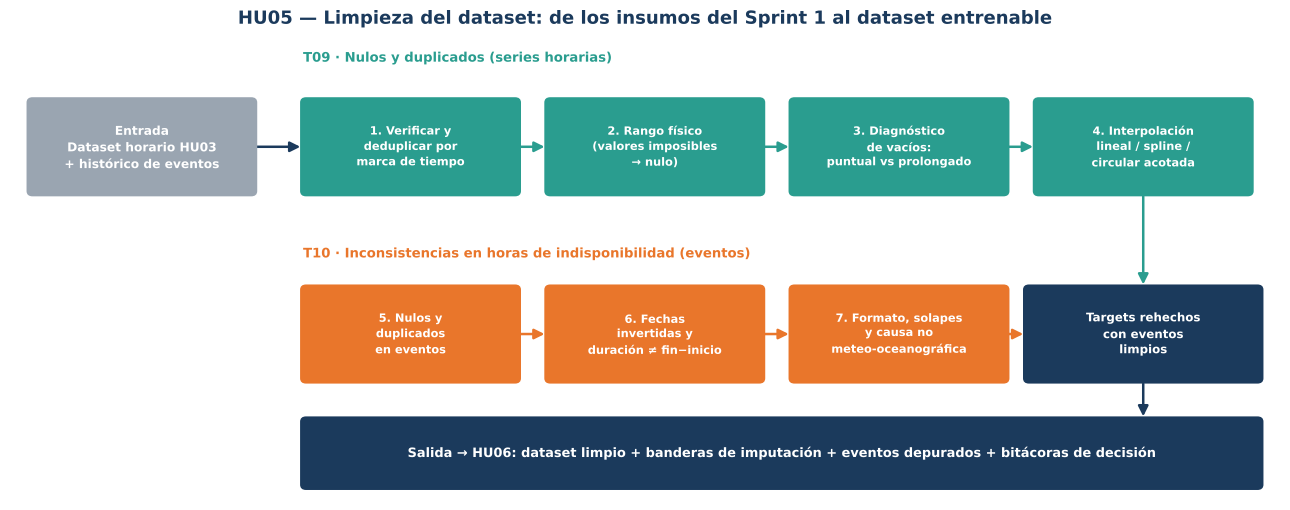

In [3]:
fig, ax = lienzo(13, 5.2, xlim=(0, 13), ylim=(0, 5.4))
ax.set_title('HU05 — Limpieza del dataset: de los insumos del Sprint 1 al dataset entrenable',
             fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

caja(ax, 0.2, 3.6, 2.3, 1.1, 'Entrada\nDataset horario HU03\n+ histórico de eventos', color=COLOR_GRAY, fontsize=8.8)
flecha(ax, (2.5, 4.15), (3.0, 4.15))

# Carril T09
ax.text(3.0, 5.15, 'T09 · Nulos y duplicados (series horarias)', fontsize=9.5, color=COLOR_TEAL, fontweight='bold')
pasos9 = ['1. Verificar y\ndeduplicar por\nmarca de tiempo', '2. Rango físico\n(valores imposibles\n→ nulo)', '3. Diagnóstico\nde vacíos:\npuntual vs prolongado',
          '4. Interpolación\nlineal / spline /\ncircular acotada']
for i, p in enumerate(pasos9):
    x = 3.0 + i * 2.5
    caja(ax, x, 3.6, 2.2, 1.1, p, color=COLOR_TEAL, fontsize=8.2)
    if i < 3: flecha(ax, (x + 2.2, 4.15), (x + 2.5, 4.15), color=COLOR_TEAL)

# Carril T10
ax.text(3.0, 2.85, 'T10 · Inconsistencias en horas de indisponibilidad (eventos)', fontsize=9.5, color=COLOR_ORANGE, fontweight='bold')
pasos10 = ['5. Nulos y\nduplicados\nen eventos', '6. Fechas\ninvertidas y\nduración ≠ fin−inicio', '7. Formato, solapes\ny causa no\nmeteo-oceanográfica']
for i, p in enumerate(pasos10):
    x = 3.0 + i * 2.5
    caja(ax, x, 1.4, 2.2, 1.1, p, color=COLOR_ORANGE, fontsize=8.2)
    if i < 2: flecha(ax, (x + 2.2, 1.95), (x + 2.5, 1.95), color=COLOR_ORANGE)

flecha(ax, (11.6, 3.6), (11.6, 2.5), color=COLOR_TEAL)
caja(ax, 10.4, 1.4, 2.4, 1.1, 'Targets rehechos\ncon eventos\nlimpios', color=COLOR_NAVY, fontsize=8.5)
flecha(ax, (8.0, 1.95), (10.4, 1.95), color=COLOR_ORANGE)

flecha(ax, (11.6, 1.4), (11.6, 0.95), color=COLOR_NAVY)
caja(ax, 3.0, 0.15, 9.8, 0.8, 'Salida → HU06: dataset limpio + banderas de imputación + eventos depurados + bitácoras de decisión', color=COLOR_NAVY, fontsize=9.3)
plt.tight_layout(); plt.show()

### Configuración de HU05 (parámetros editables)

Todo lo que es **criterio de negocio** vive en una sola celda, para que pueda **validarse con la asesora y el Product Owner** y re-ejecutarse sin tocar el código.

> **Nota:** los límites de horas (`max_gap_h`) y los rangos físicos son **valores de partida razonables, no resultados medidos**. Se contrastan con el diagnóstico de vacíos (T09.3) y se ajustan si la asesora o Operaciones lo indican.

**Lógica de la tolerancia diferenciada por variable**
- **Viento (velocidad y dirección)** y **oleaje**: cambian rápido (ráfagas, grupos de olas) → límite **corto**, porque interpolar horas largas inventaría condiciones que pudieron ser justo las críticas para la operación.
- **Temperatura, presión y humedad**: variables **suaves** → límite **más amplio**; la temperatura y la presión usan **spline cúbico local** por su evolución continua.
- **Dirección del viento**: se interpola de forma **circular** (componentes seno/coseno), porque interpolar grados directamente falla en el salto 360° → 0°.
- **Diagnóstico del datalogger** (temperatura interna, voltaje): no son predictores; se tratan para conservar la trazabilidad y explicar vacíos compartidos.

In [4]:
# ==== HU05 - Configuración (EDITABLE) ====
# rol: 'predictor' entra al modelo; 'diagnostico' solo explica fallas del datalogger
# metodo: 'linear' | 'spline' (cúbico local) | 'circular' (grados, vía seno/coseno)
# max_gap_h: máximo de horas CONSECUTIVAS sin dato que se interpolan (vacío puntual)
# rango: valores físicamente posibles; fuera de rango -> se convierte en nulo antes de imputar
# max_pct_vacio: si tras imputar queda más de este % de vacío, se evalúa excluir la variable
CONFIG_VARIABLES = {
    'velocidad_viento_ms':              dict(rol='predictor',   metodo='linear',   max_gap_h=3, rango=(0, 60),    max_pct_vacio=10),
    'direccion_viento_deg':             dict(rol='predictor',   metodo='circular', max_gap_h=3, rango=(0, 360),   max_pct_vacio=10),
    'temperatura_c':                    dict(rol='predictor',   metodo='spline',   max_gap_h=6, rango=(-5, 45),   max_pct_vacio=10),
    'humedad_relative_pct':             dict(rol='predictor',   metodo='linear',   max_gap_h=6, rango=(0, 100),   max_pct_vacio=10),
    'presion_atmosferica_hpa':          dict(rol='predictor',   metodo='spline',   max_gap_h=6, rango=(900, 1100), max_pct_vacio=10),
    'altura_olas_m':                    dict(rol='predictor',   metodo='linear',   max_gap_h=2, rango=(0, 15),    max_pct_vacio=10),
    'temperatura_interna_datalogger_c': dict(rol='diagnostico', metodo='linear',   max_gap_h=6, rango=(-10, 80),  max_pct_vacio=10),
    'voltaje_datalogger_v':             dict(rol='diagnostico', metodo='linear',   max_gap_h=6, rango=(0, 30),    max_pct_vacio=10),
}
VARIABLES = list(CONFIG_VARIABLES)
PREDICTORES = [v for v, c in CONFIG_VARIABLES.items() if c['rol'] == 'predictor']
DIAGNOSTICO = [v for v, c in CONFIG_VARIABLES.items() if c['rol'] == 'diagnostico']

UMBRAL_COMPLETITUD_PCT = 90          # criterio de aceptación HU05 (TB1)
VENTANA_SPLINE_H = 12                # puntos válidos a cada lado del hueco para el spline local
HORIZONTE_H = 6                      # V9: horizonte de 6 h (antes 24 h). Se puede volver a 24 para comparar
ORIGEN_AL_CIERRE_H = 1               # V8: la fila t resume [t, t+1h) -> la predicción se emite al cierre (t+1h). 0 = comportamiento V7 (con fuga)

# ---- T10: reglas sobre el histórico de eventos ----
TOL_DURACION_H = 0.05                # tolerancia entre duración registrada y (fin - inicio)
UMBRAL_REVISION_H = 1.0              # diferencias mayores a esto se marcan para validar con Operaciones
POLITICA_FECHA_FIN_NULA = 'imputar_con_duracion_registrada'  # o 'excluir'. Imputa solo si duracion_h_registrada y duracion_h_calculada coinciden
FUSIONAR_SOLAPADOS = False           # False: solo marca solapes; True: fusiona eventos solapados
COLUMNAS_CAUSA_CANDIDATAS = ['causa_registrada', 'causa', 'causa_indisponibilidad', 'motivo', 'tipo_causa']
PALABRAS_CAUSA_NO_CLIMATICA = ['mantenim', 'falla', 'electric', 'energ', 'averia', 'mecanic', 'programad', 'comunicacion', 'corte de']

display(pd.DataFrame(CONFIG_VARIABLES).T.rename(columns={
    'rol': 'Rol', 'metodo': 'Método', 'max_gap_h': 'Máx. horas a interpolar',
    'rango': 'Rango físico', 'max_pct_vacio': '% vacío máx. tolerado'}))

,Rol,Método,Máx. horas a interpolar,Rango físico,% vacío máx. tolerado
velocidad_viento_ms,predictor,linear,3,"(0, 60)",10
direccion_viento_deg,predictor,circular,3,"(0, 360)",10
temperatura_c,predictor,spline,6,"(-5, 45)",10
humedad_relative_pct,predictor,linear,6,"(0, 100)",10
presion_atmosferica_hpa,predictor,spline,6,"(900, 1100)",10
altura_olas_m,predictor,linear,2,"(0, 15)",10
temperatura_interna_datalogger_c,diagnostico,linear,6,"(-10, 80)",10
voltaje_datalogger_v,diagnostico,linear,6,"(0, 30)",10


### Carga de los insumos del Sprint 1

Se leen `dataset_integrado_horario_HU03.csv` y el histórico de eventos. Si no están en la sesión de Colab, la celda ofrece subirlos. **Las columnas de targets provisionales de HU03 se descartan**: se reconstruirán al final con los eventos ya limpios.

In [5]:
# ==== Carga de insumos ====
RUTA_DATASET = 'dataset_integrado_horario_HU03.csv'
PATRON_EVENTOS = 'Historico_Indisponibilidad_Operativa*.csv'

faltantes = [p for p in [RUTA_DATASET, PATRON_EVENTOS] if not glob.glob(p)]
if faltantes:
    try:
        from google.colab import files
        print('Faltan archivos; selecciona los CSV a subir:', *faltantes, sep='\n  - ')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Faltan archivos en el directorio de trabajo: {faltantes}')

df_hu03 = pd.read_csv(RUTA_DATASET, index_col='fecha_hora', parse_dates=['fecha_hora'])
df_hu03 = df_hu03.rename(columns={'humedad_relativa_pct': 'humedad_relative_pct'})   # V8: compatibilidad con el nombre que exporta el V5
ruta_eventos = glob.glob(PATRON_EVENTOS)[0]
df_eventos_crudo = pd.read_csv(ruta_eventos, parse_dates=['fecha_inicio', 'fecha_fin'])

# Validación mínima de esquema
faltan_vars = [v for v in VARIABLES if v not in df_hu03.columns]
faltan_cols_ev = [c for c in ['id_evento', 'fecha_inicio', 'fecha_fin'] if c not in df_eventos_crudo.columns]
assert not faltan_vars, f'Faltan variables en el dataset HU03: {faltan_vars}'
assert not faltan_cols_ev, f'Faltan columnas en el histórico de eventos: {faltan_cols_ev}'

print(f'Dataset HU03 : {df_hu03.shape[0]:,} filas x {df_hu03.shape[1]} columnas  ({df_hu03.index.min()} -> {df_hu03.index.max()})')
print(f'Histórico    : {len(df_eventos_crudo):,} eventos  (archivo: {Path(ruta_eventos).name})')
display(df_eventos_crudo.head(3))

Dataset HU03 : 22,920 filas x 12 columnas  (2024-01-01 00:00:00 -> 2026-08-12 23:00:00)
Histórico    : 259 eventos  (archivo: Historico_Indisponibilidad_Operativa-2024-01-01_a_2026-08-12.csv)


,id_evento,fecha_inicio,fecha_fin,oleaje_max_durante_evento_m,viento_max_durante_evento_mph,direccion_predominante_durante_evento_deg,temperatura_media_durante_evento_c,humedad_media_durante_evento_pct,presion_media_durante_evento_hpa,variable_dominante,causa_registrada,fuente_registro,duracion_h_calculada,duracion_h_registrada
0,EV001,2024-01-09 23:41:27,2024-01-10 01:59:27,3.47,12.42,221.5,20.79,75.20,1012.28,OLEAJE,Altura de olas por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,2.30,2.30
1,EV002,2024-01-20 16:15:37,2024-01-20 18:55:13,1.54,25.83,98.1,23.75,88.45,1016.33,VIENTO,Velocidad de viento por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,2.66,2.66
2,EV003,2024-01-21 16:49:36,2024-01-21 20:52:36,2.60,22.10,84.7,10.84,97.20,1014.95,VIENTO,Velocidad de viento por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,4.05,4.05


In [6]:
print('Columnas disponibles en df_hu03:')
print(list(df_hu03.columns))

Columnas disponibles en df_hu03:
['velocidad_viento_mph', 'direccion_viento_deg', 'temperatura_c', 'humedad_relative_pct', 'presion_atmosferica_hpa', 'temperatura_interna_datalogger_c', 'voltaje_datalogger_v', 'altura_olas_m', 'velocidad_viento_ms', 'ocurre_evento_6_12h', 'horas_hasta_inicio_6_12h', 'duracion_indisponibilidad_h']


## 3.1.1 T09 — Tratar valores nulos y duplicados

### T09.1 Verificación y deduplicación por marca de tiempo (paso previo a la agregación horaria)

Se verifican **tres niveles**:

1. **CSV crudos** (si están en la sesión): marcas de tiempo repetidas por variable. Si una marca se repite se conserva la **última lectura válida** (no nula).
2. **Índice de la malla horaria**: no debe haber horas repetidas ni saltos.
3. **Tabla resultante**: confirma o refuta el hallazgo del Sprint 1 (*0 duplicados en las ocho series*).

In [7]:
# ==== T09.1 - Verificación y deduplicación por marca de tiempo ====
PATRONES_CRUDOS = {
    'velocidad_viento_ms':              'Velocidad_de_Viento*.csv',
    'direccion_viento_deg':             'Direccion_de_Viento*.csv',
    'temperatura_c':                    'Temperatura-*.csv',
    'humedad_relativa_pct':             'Humedad_Relativa*.csv',
    'presion_atmosferica_hpa':          'Presion_Atmosferica*.csv',
    'altura_olas_m':                     'Altura_de_Olas*.csv',
    'temperatura_interna_datalogger_c':  'Temperatura_Interna_de_Datalogger*.csv',
    'voltaje_datalogger_v':              'Voltaje_de_Datalogger*.csv',
}

def _a_numero(v):
    if pd.isna(v):
        return np.nan
    m = re.search(r'-?\d+(\.\d+)?', str(v).strip().replace(',', '.'))
    return float(m.group()) if m else np.nan

def deduplicar_ultima_lectura_valida(df):
    """Ordena por marca de tiempo y, si una marca se repite, conserva la ULTIMA lectura VALIDA
    (no nula). Si todas las lecturas repetidas son nulas, conserva una fila nula."""
    df = df.dropna(subset=['fecha_hora']).copy()
    df['_orden'] = np.arange(len(df))
    df['_valida'] = df['valor'].notna()
    df = df.sort_values(['fecha_hora', '_valida', '_orden'])      # las válidas quedan al final de cada marca
    return df.drop_duplicates('fecha_hora', keep='last').drop(columns=['_orden', '_valida'])

def verificar_duplicados_crudo(columna, patron):
    rutas = glob.glob(patron)
    if not rutas:
        return {'serie': columna, 'fuente': 'CSV crudo no disponible', 'lecturas': np.nan,
                'marcas_repetidas': np.nan, 'con_valores_distintos': np.nan, 'lecturas_tras_dedup': np.nan}
    df = pd.read_csv(rutas[0], encoding='utf-8')
    df = df.iloc[:, :2]; df.columns = ['Time', 'crudo']
    df['fecha_hora'] = pd.to_datetime(df['Time'], errors='coerce')
    df['valor'] = df['crudo'].apply(_a_numero)
    rep = df.dropna(subset=['fecha_hora']).duplicated('fecha_hora', keep=False)
    n_rep = int(df.dropna(subset=['fecha_hora']).duplicated('fecha_hora').sum())
    n_conf = int(df.dropna(subset=['fecha_hora'])[rep].groupby('fecha_hora')['valor'].nunique(dropna=True).gt(1).sum()) if rep.any() else 0
    dedup = deduplicar_ultima_lectura_valida(df[['fecha_hora', 'valor']])
    return {'serie': columna, 'fuente': Path(rutas[0]).name, 'lecturas': len(df),
            'marcas_repetidas': n_rep, 'con_valores_distintos': n_conf, 'lecturas_tras_dedup': len(dedup)}

reporte_dup_crudo = pd.DataFrame([verificar_duplicados_crudo(c, p) for c, p in PATRONES_CRUDOS.items()])
display(reporte_dup_crudo)

# --- Nivel 2: índice de la malla horaria
indice_duplicado = int(df_hu03.index.duplicated().sum())
df_hu03 = df_hu03[~df_hu03.index.duplicated(keep='last')].sort_index()
malla = pd.date_range(df_hu03.index.min(), df_hu03.index.max(), freq='h')
horas_faltantes_en_malla = len(malla) - len(df_hu03)
df_h = df_hu03.reindex(malla)
df_h.index.name = 'fecha_hora'

duplicados_total_crudo = reporte_dup_crudo['marcas_repetidas'].sum(skipna=True)
resumen_dup = pd.DataFrame([
    ['Series crudas verificadas', int(reporte_dup_crudo['lecturas'].notna().sum()), 'de 8'],
    ['Marcas de tiempo repetidas en CSV crudos', int(duplicados_total_crudo), 'Sprint 1 reportó 0 en las 8 series'],
    ['Horas repetidas en el índice horario', indice_duplicado, 'se conserva la última'],
    ['Horas ausentes en la malla (se reinsertan como nulo)', int(horas_faltantes_en_malla), 'malla horaria continua'],
], columns=['Verificación', 'Resultado', 'Comentario'])
display(resumen_dup)

,serie,fuente,lecturas,marcas_repetidas,con_valores_distintos,lecturas_tras_dedup
0,velocidad_viento_ms,Velocidad_de_Viento-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
1,direccion_viento_deg,Direccion_de_Viento-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
2,temperatura_c,Temperatura-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
3,humedad_relativa_pct,Humedad_Relativa-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
4,presion_atmosferica_hpa,Presion_Atmosferica-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
5,altura_olas_m,Altura_de_Olas-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
6,temperatura_interna_datalogger_c,Temperatura_Interna_de_Datalogger-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040
7,voltaje_datalogger_v,Voltaje_de_Datalogger-data-2024-01-01_a_2026-08-12.csv,275040,0,0,275040


,Verificación,Resultado,Comentario
0,Series crudas verificadas,8,de 8
1,Marcas de tiempo repetidas en CSV crudos,0,Sprint 1 reportó 0 en las 8 series
2,Horas repetidas en el índice horario,0,se conserva la última
3,Horas ausentes en la malla (se reinsertan como nulo),0,malla horaria continua


### T09.2 Valores físicamente imposibles → nulo

Antes de medir vacíos, cualquier valor fuera del **rango físico** configurado se convierte en nulo y **se cuenta**. Es parte del tratamiento de nulos (un valor imposible equivale a una lectura inexistente). **No** se tocan los *outliers* estadísticos (IQR) de T08: son valores posibles, y por ejemplo el 8 % de `voltaje_datalogger_v` es un hallazgo a documentar, no a corregir.

In [8]:
# ==== T09.2 - Rango físico ====
df_crudo_h = df_h[VARIABLES].copy()          # copia previa a cualquier tratamiento (para el "antes")
df_rango = df_crudo_h.copy()
filas = []
for v, cfg in CONFIG_VARIABLES.items():
    lo, hi = cfg['rango']
    fuera = (df_rango[v] < lo) | (df_rango[v] > hi)
    filas.append({'variable': v, 'rango_fisico': f'[{lo}, {hi}]', 'valores_fuera_de_rango': int(fuera.sum())})
    df_rango.loc[fuera, v] = np.nan
reporte_rango = pd.DataFrame(filas)
display(reporte_rango)

,variable,rango_fisico,valores_fuera_de_rango
0,velocidad_viento_ms,"[0, 60]",0
1,direccion_viento_deg,"[0, 360]",0
2,temperatura_c,"[-5, 45]",0
3,humedad_relative_pct,"[0, 100]",257
4,presion_atmosferica_hpa,"[900, 1100]",0
5,altura_olas_m,"[0, 15]",0
6,temperatura_interna_datalogger_c,"[-10, 80]",0
7,voltaje_datalogger_v,"[0, 30]",0


### T09.3 Diagnóstico de vacíos: puntuales vs prolongados

Se construye una **bitácora de vacíos** (una fila por hueco: variable, inicio, fin, horas, posición) y cada hueco se clasifica con el límite **de su propia variable**:

- `puntual`: horas consecutivas ≤ `max_gap_h` → **se interpola**.
- `prolongado`: horas consecutivas > `max_gap_h` → **no se interpola**, se documenta.
- Los huecos en el **borde** de la serie (inicio o final) no tienen dato a ambos lados, por lo que **nunca** se interpolan.

In [9]:
# ==== T09.3 - Bitácora de vacíos ====
def listar_vacios(serie, max_gap_h):
    es_nulo = serie.isna()
    grupo = (es_nulo != es_nulo.shift(fill_value=False)).cumsum()
    filas = []
    for _, bloque in serie.groupby(grupo):
        if not bloque.isna().all():
            continue
        ini, fin, n = bloque.index[0], bloque.index[-1], len(bloque)
        if ini == serie.index[0]:   pos = 'borde_inicial'
        elif fin == serie.index[-1]: pos = 'borde_final'
        else:                        pos = 'interno'
        if pos != 'interno':         clase = 'prolongado (borde)' if n > max_gap_h else 'puntual (borde, no interpolable)'
        else:                        clase = 'puntual' if n <= max_gap_h else 'prolongado'
        filas.append({'variable': serie.name, 'inicio': ini, 'fin': fin, 'horas': n, 'posicion': pos,
                      'max_gap_h_variable': max_gap_h, 'clasificacion': clase})
    return filas

bitacora_vacios = pd.DataFrame(
    [f for v in VARIABLES for f in listar_vacios(df_rango[v], CONFIG_VARIABLES[v]['max_gap_h'])]
)

if bitacora_vacios.empty:
    print('No se detectaron vacíos en ninguna variable.')
else:
    resumen_vacios = (bitacora_vacios
        .pivot_table(index='variable', columns='clasificacion', values='horas', aggfunc=['count', 'sum'], fill_value=0))
    resumen_vacios.columns = [f'{a}_{b}'.replace('count', 'n_huecos').replace('sum', 'horas') for a, b in resumen_vacios.columns]
    display(resumen_vacios)
    print('Huecos más largos por variable:')
    display(bitacora_vacios.sort_values('horas', ascending=False).groupby('variable').head(2).reset_index(drop=True))

,n_huecos_prolongado,n_huecos_puntual,horas_prolongado,horas_puntual
variable,,,,
altura_olas_m,22,8,120,12
direccion_viento_deg,12,13,59,27
humedad_relative_pct,11,108,121,222
presion_atmosferica_hpa,2,23,14,72
temperatura_c,2,23,14,72
temperatura_interna_datalogger_c,2,23,14,72
velocidad_viento_ms,12,13,59,27
voltaje_datalogger_v,2,23,14,72


Huecos más largos por variable:


,variable,inicio,fin,horas,posicion,max_gap_h_variable,clasificacion
0,humedad_relative_pct,2026-03-18 08:00:00,2026-03-19 02:00:00,19,interno,6,prolongado
1,humedad_relative_pct,2025-02-19 11:00:00,2025-02-20 05:00:00,19,interno,6,prolongado
2,altura_olas_m,2024-11-09 15:00:00,2024-11-10 01:00:00,11,interno,2,prolongado
3,altura_olas_m,2024-07-03 18:00:00,2024-07-04 04:00:00,11,interno,2,prolongado
4,voltaje_datalogger_v,2025-07-08 09:00:00,2025-07-08 15:00:00,7,interno,6,prolongado
5,voltaje_datalogger_v,2024-12-15 00:00:00,2024-12-15 06:00:00,7,interno,6,prolongado
6,presion_atmosferica_hpa,2024-12-15 00:00:00,2024-12-15 06:00:00,7,interno,6,prolongado
7,direccion_viento_deg,2025-07-08 09:00:00,2025-07-08 15:00:00,7,interno,3,prolongado
8,presion_atmosferica_hpa,2025-07-08 09:00:00,2025-07-08 15:00:00,7,interno,6,prolongado
9,direccion_viento_deg,2024-12-15 00:00:00,2024-12-15 06:00:00,7,interno,3,prolongado


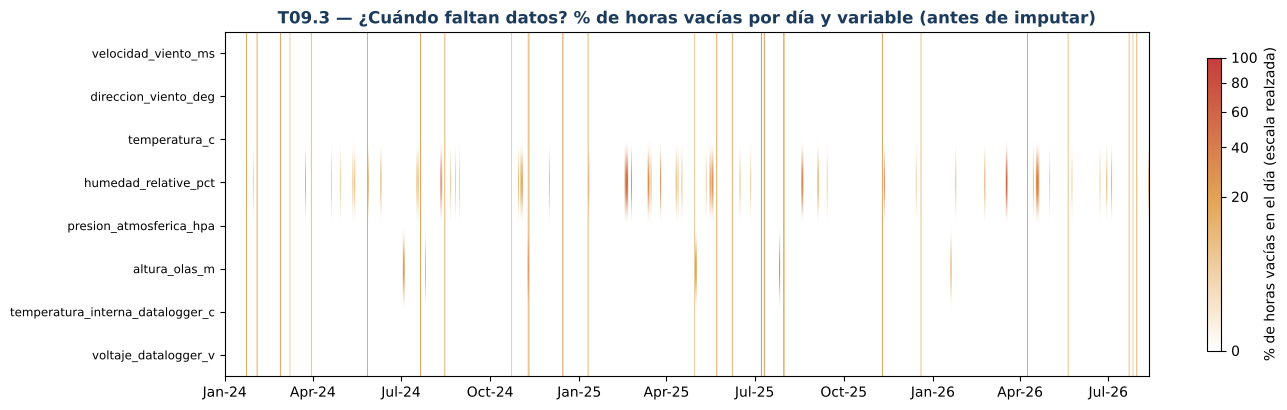

Lectura: franjas verticales que cruzan TODAS las filas = falla de estación/datalogger; marcas aisladas en una fila = falla de un sensor.


In [10]:
# ==== Vista visual - Mapa de disponibilidad (antes de imputar) ====
disp = (df_rango[VARIABLES].isna().resample('D').mean() * 100).T       # % de horas vacías por día
fig, ax = plt.subplots(figsize=(14, 4.2))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('disp', ['white', COLOR_GOLD, COLOR_RED])
from matplotlib.colors import PowerNorm
im = ax.imshow(disp.values, aspect='auto', cmap=cmap, norm=PowerNorm(gamma=0.4, vmin=0, vmax=100),
               extent=[mdates.date2num(disp.columns[0]), mdates.date2num(disp.columns[-1]), len(VARIABLES), 0])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
ax.set_yticks(np.arange(len(VARIABLES)) + 0.5); ax.set_yticklabels(VARIABLES, fontsize=8.5)
ax.set_title('T09.3 — ¿Cuándo faltan datos? % de horas vacías por día y variable (antes de imputar)',
             fontsize=12, color=COLOR_NAVY, fontweight='bold')
fig.colorbar(im, ax=ax, shrink=0.85, label='% de horas vacías en el día (escala realzada)')
fig.tight_layout(); plt.show()
print('Lectura: franjas verticales que cruzan TODAS las filas = falla de estación/datalogger; '
      'marcas aisladas en una fila = falla de un sensor.')

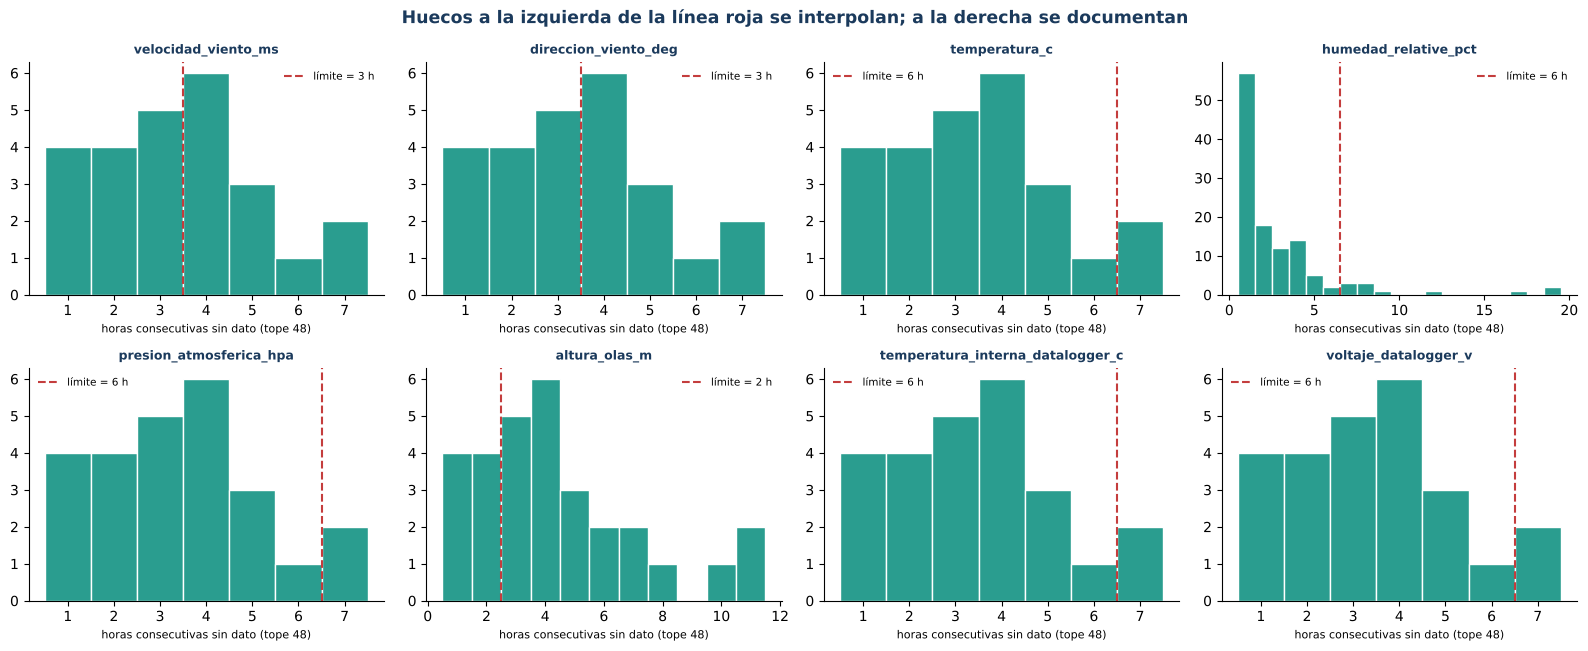

In [11]:
# ==== Vista visual - ¿Qué tan largos son los huecos vs el límite de cada variable? ====
if not bitacora_vacios.empty:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.6))
    for ax, v in zip(axes.ravel(), VARIABLES):
        h = bitacora_vacios.loc[bitacora_vacios['variable'] == v, 'horas']
        lim = CONFIG_VARIABLES[v]['max_gap_h']
        if len(h):
            tope = max(h.max(), lim + 1)
            ax.hist(h.clip(upper=48), bins=np.arange(0.5, min(tope, 48) + 1.5, 1),
                    color=[COLOR_TEAL], edgecolor='white')
        ax.axvline(lim + 0.5, color=COLOR_RED, lw=1.5, ls='--', label=f'límite = {lim} h')
        ax.set_title(v, fontsize=9, color=COLOR_NAVY, fontweight='bold')
        ax.set_xlabel('horas consecutivas sin dato (tope 48)', fontsize=8)
        ax.legend(fontsize=7.5, frameon=False); ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Huecos a la izquierda de la línea roja se interpolan; a la derecha se documentan',
                 fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
    fig.tight_layout(); plt.show()

### T09.4 Interpolación temporal acotada (lineal / spline / circular)

Solo se imputan los **vacíos puntuales internos**. La función respeta el límite **por hueco completo**: un hueco de 5 h con límite de 3 h **no se rellena parcialmente** (a diferencia del parámetro `limit` de `pandas.interpolate`, que sí rellenaría las primeras 3 horas).

| Método | Cómo funciona | Variables |
|---|---|---|
| `linear` | recta entre el último y el primer dato válido que rodean el hueco | viento (m/s), humedad, oleaje, diagnóstico |
| `spline` | spline cúbico **local** (hasta 12 puntos válidos a cada lado); si no hay suficientes puntos, cae a lineal | temperatura, presión |
| `circular` | interpola seno y coseno por separado y recompone el ángulo | dirección del viento |

Tras interpolar, el resultado se **recorta al rango físico** de la variable (el spline puede sobrepasarlo). Cada hora imputada queda marcada en una **bandera** para que HU06/HU07 puedan distinguir dato medido de dato imputado.

In [12]:
# ==== T09.4 - Imputación temporal acotada ====
from scipy.interpolate import CubicSpline

def _huecos_internos(serie):
    """Devuelve lista de (pos_ini, pos_fin) de los huecos de NaN que NO están en los bordes."""
    es_nulo = serie.isna().values
    n, i, out = len(es_nulo), 0, []
    while i < n:
        if es_nulo[i]:
            j = i
            while j + 1 < n and es_nulo[j + 1]:
                j += 1
            if i > 0 and j < n - 1:
                out.append((i, j))
            i = j + 1
        else:
            i += 1
    return out

def _lineal_en_hueco(valores, a, b):
    x0, x1 = a - 1, b + 1
    return np.interp(np.arange(a, b + 1), [x0, x1], [valores[x0], valores[x1]])

def _spline_en_hueco(valores, a, b, ventana):
    n = len(valores)
    valida = ~np.isnan(valores)
    izq = np.where(valida[max(0, a - ventana):a])[0] + max(0, a - ventana)
    der = np.where(valida[b + 1:min(n, b + 1 + ventana)])[0] + b + 1
    if len(izq) < 2 or len(der) < 2:
        return None
    xs = np.concatenate([izq, der])
    cs = CubicSpline(xs, valores[xs], bc_type='natural')
    return cs(np.arange(a, b + 1))

def imputar_acotado(serie, metodo, max_gap_h, rango, ventana=VENTANA_SPLINE_H):
    """Imputa SOLO huecos internos con longitud <= max_gap_h. Retorna (serie_imputada, mascara_imputado, metodo_efectivo_por_hueco)."""
    s = serie.copy()
    mask = pd.Series(False, index=s.index)
    usados = []
    if metodo == 'circular':
        rad = np.deg2rad(s)
        comp = {'sen': np.sin(rad), 'cos': np.cos(rad)}
        comp_imp = {}
        for k, c in comp.items():
            c_imp, m, _ = imputar_acotado(c, 'linear', max_gap_h, (-1, 1), ventana)
            comp_imp[k] = c_imp
            mask = mask | m
        ang = np.degrees(np.arctan2(comp_imp['sen'], comp_imp['cos'])) % 360
        s = s.where(~mask, ang)
        n_imp = int(((mask != mask.shift(fill_value=False)) & mask).sum())
        return s, mask, ['circular'] * n_imp
    valores = s.values.astype(float).copy()
    for a, b in _huecos_internos(serie):
        largo = b - a + 1
        if largo > max_gap_h:
            continue
        rel = None
        if metodo == 'spline':
            rel = _spline_en_hueco(valores, a, b, ventana)
            usados.append('spline' if rel is not None else 'lineal (respaldo)')
        if rel is None:
            rel = _lineal_en_hueco(valores, a, b)
            if metodo != 'spline': usados.append('lineal')
        valores[a:b + 1] = rel
        mask.iloc[a:b + 1] = True
    s = pd.Series(valores, index=serie.index, name=serie.name)
    lo, hi = rango
    s = s.where(~mask, s.clip(lo, hi))
    return s, mask, usados

df_limpio = df_rango.copy()
flags_imputacion = pd.DataFrame(index=df_limpio.index)
detalle_metodos = []

for v, cfg in CONFIG_VARIABLES.items():
    # La velocidad en mph NO se interpola aparte: se reconstruye desde m/s (evita inconsistencias entre columnas)
    s_imp, m_imp, usados = imputar_acotado(df_rango[v], cfg['metodo'], cfg['max_gap_h'], cfg['rango'])
    df_limpio[v] = s_imp
    flags_imputacion[f'{v}_imputado'] = m_imp
    detalle_metodos.append({'variable': v, 'metodo_configurado': cfg['metodo'], 'max_gap_h': cfg['max_gap_h'],
                            'huecos_imputados': len(usados), 'horas_imputadas': int(m_imp.sum()),
                            'metodo_efectivo': ', '.join(sorted(set(usados))) or '—'})

# Variable derivada en mph, coherente con m/s limpio
if 'velocidad_viento_mph' in df_h.columns:
    df_limpio['velocidad_viento_mph'] = df_limpio['velocidad_viento_ms'] / MPH_A_MS

resumen_imputacion = pd.DataFrame(detalle_metodos)
display(resumen_imputacion)

,variable,metodo_configurado,max_gap_h,huecos_imputados,horas_imputadas,metodo_efectivo
0,velocidad_viento_ms,linear,3,13,27,lineal
1,direccion_viento_deg,circular,3,13,27,circular
2,temperatura_c,spline,6,23,72,spline
3,humedad_relative_pct,linear,6,108,222,lineal
4,presion_atmosferica_hpa,spline,6,23,72,spline
5,altura_olas_m,linear,2,8,12,lineal
6,temperatura_interna_datalogger_c,linear,6,23,72,lineal
7,voltaje_datalogger_v,linear,6,23,72,lineal


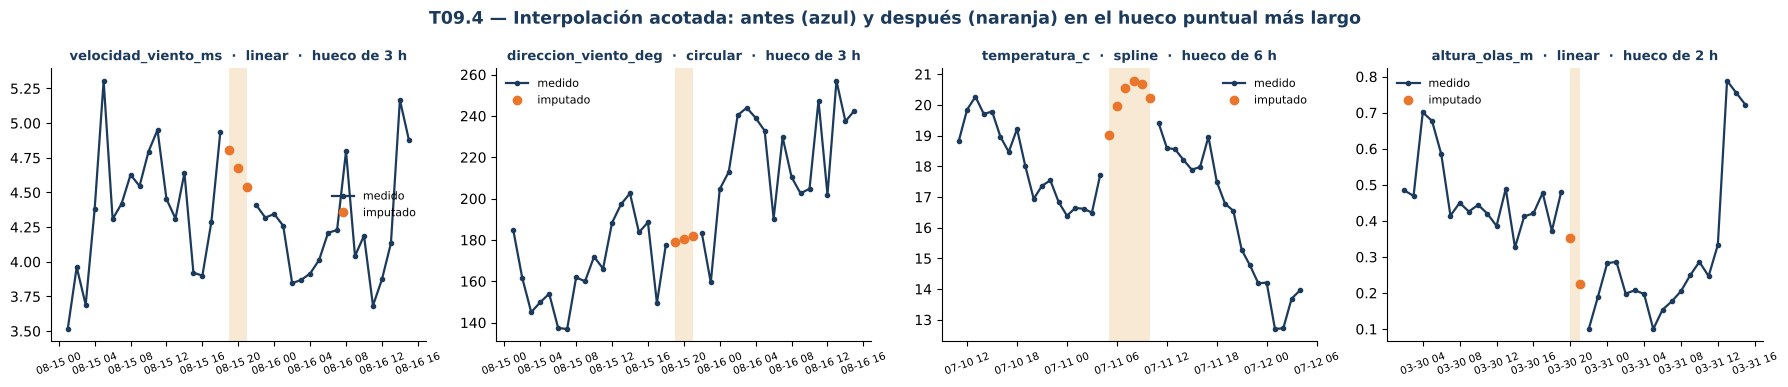

In [13]:
# ==== Vista visual - Ejemplos de imputación (el hueco imputado más largo de cada método) ====
def graficar_ejemplo(ax, v, margen_h=18):
    m = flags_imputacion[f'{v}_imputado']
    if not m.any():
        ax.text(0.5, 0.5, f'{v}\n(sin huecos imputados)', ha='center', va='center', transform=ax.transAxes, color=COLOR_GRAY)
        ax.axis('off'); return
    grupo = (m != m.shift(fill_value=False)).cumsum()
    largos = m.groupby(grupo).sum()
    g_max = largos[largos == largos.max()].index[0]
    idx = m[(grupo == g_max) & m].index
    ini, fin = idx[0] - pd.Timedelta(hours=margen_h), idx[-1] + pd.Timedelta(hours=margen_h)
    ax.plot(df_rango.loc[ini:fin, v], color=COLOR_NAVY, lw=1.6, marker='o', ms=3, label='medido')
    ax.plot(df_limpio.loc[idx, v], color=COLOR_ORANGE, lw=0, marker='o', ms=6, label='imputado')
    ax.axvspan(idx[0], idx[-1], color=COLOR_GOLD, alpha=0.25, lw=0)
    ax.set_title(f'{v}  ·  {CONFIG_VARIABLES[v]["metodo"]}  ·  hueco de {len(idx)} h', fontsize=9.5,
                 color=COLOR_NAVY, fontweight='bold')
    ax.legend(fontsize=8, frameon=False); ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', labelsize=7.5, rotation=20)

ejemplos = ['velocidad_viento_ms', 'direccion_viento_deg', 'temperatura_c', 'altura_olas_m']
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
for ax, v in zip(axes, ejemplos):
    graficar_ejemplo(ax, v)
fig.suptitle('T09.4 — Interpolación acotada: antes (azul) y después (naranja) en el hueco puntual más largo',
             fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

### T09.5 Vacíos prolongados: documentar y evaluar exclusión

Lo que **no** se pudo imputar (huecos prolongados y de borde) se trata con una regla explícita, en dos niveles:

1. **Exclusión de variable:** si tras imputar, el % de vacío de una variable supera su `max_pct_vacio`, se marca **EVALUAR EXCLUSIÓN DE VARIABLE**.
2. **Exclusión de bloque temporal:** una hora es **apta para modelado** solo si **todos los predictores** tienen dato (medido o imputado). Las horas con algún predictor vacío se agrupan en **bloques**, que se documentan con su causa probable:
   - **Falla de estación/datalogger:** casi todas las variables vacías a la vez, o diagnóstico también vacío.
   - **Falla de sensor individual:** solo algunas variables vacías.

Las filas **no se borran**: se marcan con `apto_modelado = False`. HU06 decidirá cómo construir rezagos sin cruzar estos bloques.

In [14]:
# ==== T09.5 - Vacíos prolongados: bloques y exclusión ====
df_limpio['apto_modelado'] = df_limpio[PREDICTORES].notna().all(axis=1)
df_limpio['n_predictores_imputados'] = flags_imputacion[[f'{v}_imputado' for v in PREDICTORES]].sum(axis=1)

# --- Decisión por variable
decision_variables = []
for v, cfg in CONFIG_VARIABLES.items():
    pct_antes = 100 * df_crudo_h[v].isna().mean()
    pct_despues = 100 * df_limpio[v].isna().mean()
    exceso = pct_despues > cfg['max_pct_vacio']
    decision_variables.append({
        'variable': v, 'rol': cfg['rol'],
        'pct_vacio_antes': round(pct_antes, 2), 'pct_vacio_despues': round(pct_despues, 2),
        'completitud_despues_pct': round(100 - pct_despues, 2),
        'decision': 'EVALUAR EXCLUSIÓN DE VARIABLE' if exceso else 'CONSERVAR',
    })
decision_variables = pd.DataFrame(decision_variables)
display(decision_variables)

# --- Bloques temporales no aptos
no_apto = ~df_limpio['apto_modelado']
grupo = (no_apto != no_apto.shift(fill_value=False)).cumsum()
bloques = []
for _, b in df_limpio[no_apto].groupby(grupo[no_apto]):
    vacias = [v for v in PREDICTORES if df_limpio.loc[b.index, v].isna().all()]
    algun_vacio = [v for v in PREDICTORES if df_limpio.loc[b.index, v].isna().any()]
    diag_vacio = np.mean([df_limpio.loc[b.index, v].isna().mean() for v in DIAGNOSTICO]) if DIAGNOSTICO else 0
    if len(vacias) >= len(PREDICTORES) - 1 or diag_vacio >= 0.5:
        causa = 'Falla de estación / datalogger (vacío compartido)'
    else:
        causa = 'Falla de sensor individual'
    bloques.append({'inicio': b.index[0], 'fin': b.index[-1], 'horas': len(b),
                    'variables_afectadas': ', '.join(algun_vacio), 'causa_probable': causa,
                    'decision': 'Excluido del modelado (marcado apto_modelado=False)'})
bloques_excluidos = pd.DataFrame(bloques)
print(f'Bloques temporales no aptos: {len(bloques_excluidos)}  ·  horas no aptas: {int(no_apto.sum()):,} de {len(df_limpio):,} '
      f'({100 * no_apto.mean():.2f} %)')
if len(bloques_excluidos):
    display(bloques_excluidos.sort_values('horas', ascending=False).head(15).reset_index(drop=True))

,variable,rol,pct_vacio_antes,pct_vacio_despues,completitud_despues_pct,decision
0,velocidad_viento_ms,predictor,0.38,0.26,99.74,CONSERVAR
1,direccion_viento_deg,predictor,0.38,0.26,99.74,CONSERVAR
2,temperatura_c,predictor,0.38,0.06,99.94,CONSERVAR
3,humedad_relative_pct,predictor,0.38,0.53,99.47,CONSERVAR
4,presion_atmosferica_hpa,predictor,0.38,0.06,99.94,CONSERVAR
5,altura_olas_m,predictor,0.58,0.52,99.48,CONSERVAR
6,temperatura_interna_datalogger_c,diagnostico,0.38,0.06,99.94,CONSERVAR
7,voltaje_datalogger_v,diagnostico,0.38,0.06,99.94,CONSERVAR


Bloques temporales no aptos: 31  ·  horas no aptas: 227 de 22,920 (0.99 %)


,inicio,fin,horas,variables_afectadas,causa_probable,decision
0,2025-02-19 11:00:00,2025-02-20 05:00:00,19,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
1,2026-03-18 08:00:00,2026-03-19 02:00:00,19,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
2,2025-08-19 09:00:00,2025-08-20 01:00:00,17,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
3,2025-05-18 22:00:00,2025-05-19 09:00:00,12,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
4,2024-11-09 15:00:00,2024-11-10 01:00:00,11,altura_olas_m,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
5,2024-07-03 18:00:00,2024-07-04 04:00:00,11,altura_olas_m,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
6,2025-07-27 09:00:00,2025-07-27 18:00:00,10,altura_olas_m,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
7,2024-08-11 05:00:00,2024-08-11 13:00:00,9,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
8,2025-03-26 11:00:00,2025-03-26 18:00:00,8,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)
9,2026-04-18 21:00:00,2026-04-19 04:00:00,8,humedad_relative_pct,Falla de sensor individual,Excluido del modelado (marcado apto_modelado=False)


### T09.6 Validación del tratamiento: completitud antes vs después

Criterio de aceptación de HU05: **completitud ≥ 90 %** o justificación del tratamiento. Se mide en dos niveles: **por variable** y **global** (horas con *todos* los predictores completos, que es lo realmente utilizable por el modelo).

Completitud GLOBAL (todos los predictores a la vez): antes = 99.42 %  ->  después = 99.01 %
Criterio HU05: >= 90 %  ->  CUMPLE


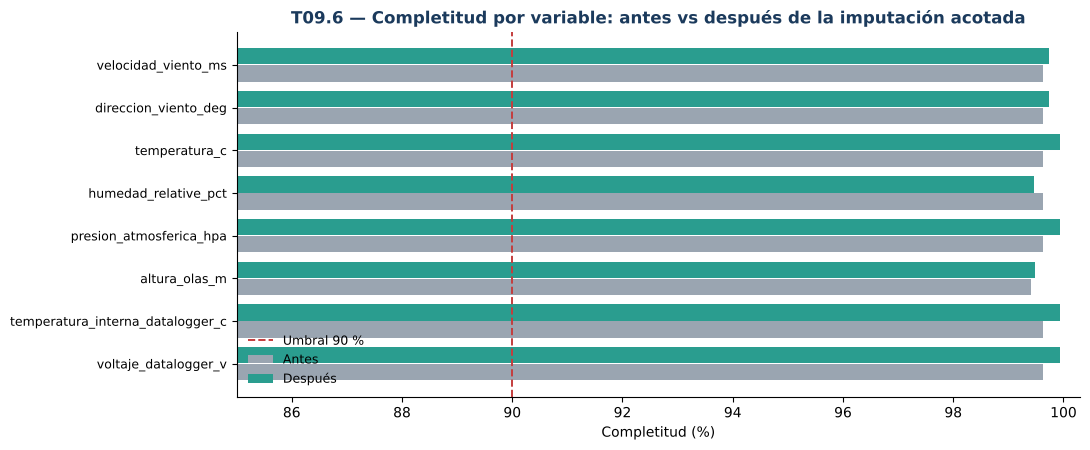

In [15]:
# ==== T09.6 - Completitud antes vs después ====
comp = decision_variables.set_index('variable')
completitud_global_antes = 100 * df_crudo_h[PREDICTORES].notna().all(axis=1).mean()
completitud_global_despues = 100 * df_limpio['apto_modelado'].mean()
print(f'Completitud GLOBAL (todos los predictores a la vez): antes = {completitud_global_antes:.2f} %  ->  después = {completitud_global_despues:.2f} %')
print(f'Criterio HU05: >= {UMBRAL_COMPLETITUD_PCT} %  ->  '
      f'{"CUMPLE" if completitud_global_despues >= UMBRAL_COMPLETITUD_PCT else "NO CUMPLE: justificar tratamiento (ver bloques prolongados)"}')

fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(comp))
ax.barh(y + 0.2, 100 - comp['pct_vacio_antes'], height=0.38, color=COLOR_GRAY, label='Antes')
ax.barh(y - 0.2, comp['completitud_despues_pct'], height=0.38, color=COLOR_TEAL, label='Después')
ax.axvline(UMBRAL_COMPLETITUD_PCT, color=COLOR_RED, ls='--', lw=1.4, label=f'Umbral {UMBRAL_COMPLETITUD_PCT} %')
ax.set_yticks(y); ax.set_yticklabels(comp.index, fontsize=9); ax.invert_yaxis()
ax.set_xlim(min(85, (100 - comp['pct_vacio_antes']).min() - 1), 100.3)
ax.set_xlabel('Completitud (%)'); ax.legend(frameon=False, fontsize=9, loc='lower left')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('T09.6 — Completitud por variable: antes vs después de la imputación acotada',
             fontsize=12, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

In [16]:
# ==== T09 - Control: la limpieza no distorsionó las distribuciones ====
filas = []
for v in VARIABLES:
    a, d = df_crudo_h[v].dropna(), df_limpio[v].dropna()
    filas.append({'variable': v, 'media_antes': a.mean(), 'media_despues': d.mean(),
                  'desv_antes': a.std(), 'desv_despues': d.std(),
                  'variacion_media_pct': 100 * (d.mean() - a.mean()) / a.mean() if a.mean() else np.nan})
control_dist = pd.DataFrame(filas).round(3)
display(control_dist)
print('Lectura: la media y la dispersión deben ser prácticamente iguales. Un cambio grande indicaría que se imputó demasiado.')

,variable,media_antes,media_despues,desv_antes,desv_despues,variacion_media_pct
0,velocidad_viento_ms,4.517,4.517,2.115,2.114,-0.001
1,direccion_viento_deg,211.444,211.436,29.322,29.319,-0.004
2,temperatura_c,17.673,17.673,2.468,2.468,0.004
3,humedad_relative_pct,84.695,84.575,6.713,6.530,-0.142
4,presion_atmosferica_hpa,1010.946,1010.944,3.776,3.777,-0.000
5,altura_olas_m,1.632,1.631,0.889,0.889,-0.009
6,temperatura_interna_datalogger_c,20.369,20.370,2.591,2.589,0.002
7,voltaje_datalogger_v,13.800,13.800,0.070,0.071,0.000


Lectura: la media y la dispersión deben ser prácticamente iguales. Un cambio grande indicaría que se imputó demasiado.


## 3.1.2 T10 — Corregir inconsistencias en horas de indisponibilidad

Las **horas de indisponibilidad** son la base de las dos variables objetivo (`horas_hasta_inicio_6h` y `duracion_indisponibilidad_h`). Un evento con fechas invertidas o una duración que no coincide con `fecha_fin − fecha_inicio` **contamina directamente las etiquetas**. Por eso T10 trabaja sobre el histórico de eventos, con reglas ordenadas y **una bitácora de cada cambio**.

### Reglas de T10 (en orden)

| # | Regla | Acción por defecto |
|---|---|---|
| R0 | Duplicados exactos y `id_evento` repetido | Conservar la **última** fila por `id_evento`; registrar si las filas repetidas **no** eran idénticas |
| R1 | `fecha_inicio` nula | Excluir (no hay evento definible) |
| R2 | `fecha_fin` nula | Según `POLITICA_FECHA_FIN_NULA`: por defecto `fin = inicio + duración` si `duracion_h_registrada` y `duracion_h_calculada` coinciden; si no, excluir |
| R3 | `fecha_fin < fecha_inicio` (fechas invertidas) | **Intercambiar** si eso hace coincidir con la duración registrada; si no, excluir y marcar para validar |
| R4 | `duracion_h_registrada` ≠ `fecha_fin − fecha_inicio` | La **fuente de verdad son las fechas** (de ahí salen los targets); se corrige la duración y se registra |
| R5 | Duración ≤ 0 | Excluir |
| R6 | Duración atípica (Q3 + 3·IQR) | **Solo marcar**; un evento largo puede ser real |
| R7 | Formato de `variable_dominante` | Normalizar (minúsculas, sin tildes, variantes unificadas) |
| R8 | Eventos solapados | Marcar (o fusionar si `FUSIONAR_SOLAPADOS=True`) |
| R9 | Causa no meteo-oceanográfica | Excluir según `causa_registrada` y `variable_dominante` (se cruzan ambas); si no hubiera columna de causa, queda pendiente de validar con Operaciones (D02/Q04) |

> **Aviso anti data-leakage (Q07):** las columnas `*_durante_evento_*` del histórico (oleaje/viento máximo, temperatura, humedad, presión durante el evento) son lecturas **posteriores a `t`**. Sirven para caracterizar y validar el evento (Rol B), **nunca como predictores**. HU06 no debe incluirlas en `X`.
>
> **Principio:** cada decisión que **no** es una corrección mecánica obvia queda marcada con `requiere_validacion = True`, para llevarla al Product Owner en lugar de decidirla en silencio.

In [17]:
# ==== T10 - Preparación de la bitácora y utilidades ====
bitacora_eventos = []

def registrar(id_evento, regla, campo, antes, despues, accion, requiere_validacion=False):
    bitacora_eventos.append({'id_evento': id_evento, 'regla': regla, 'campo': campo, 'valor_antes': antes,
                             'valor_despues': despues, 'accion': accion, 'requiere_validacion': requiere_validacion})

def _norm_texto(x):
    if pd.isna(x): return x
    t = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode('ascii')
    return re.sub(r'\s+', ' ', t).strip().lower()

ev = df_eventos_crudo.copy().reset_index(drop=True)
ev['_orden_original'] = np.arange(len(ev))
embudo = [('Eventos en el histórico crudo', len(ev))]

In [18]:
# ==== R0 / R1 / R2 - Duplicados y nulos en eventos (parte T09 aplicada al histórico) ====
# R0a: filas completamente idénticas
n_ident = int(ev.drop(columns='_orden_original').duplicated().sum())
if n_ident:
    for i in ev[ev.drop(columns='_orden_original').duplicated(keep='last')]['id_evento']:
        registrar(i, 'R0', 'fila', 'duplicada exacta', 'eliminada', 'Se conserva una sola copia')
ev = ev.drop_duplicates(subset=[c for c in ev.columns if c != '_orden_original'], keep='last')

# R0b: id_evento repetido con contenido distinto -> se conserva la ÚLTIMA y se avisa del conflicto
dup_id = ev[ev.duplicated('id_evento', keep=False)].sort_values(['id_evento', '_orden_original'])
for i, g in dup_id.groupby('id_evento'):
    registrar(i, 'R0', 'id_evento', f'{len(g)} filas con distinto contenido', 'se conserva la última',
              'Dato digitado más de una vez con valores distintos', requiere_validacion=True)
n_dup_id = int(ev.duplicated('id_evento').sum())
ev = ev.sort_values('_orden_original').drop_duplicates('id_evento', keep='last')
embudo.append(('Tras eliminar duplicados (R0)', len(ev)))

# R1: fecha_inicio nula
m = ev['fecha_inicio'].isna()
for i in ev.loc[m, 'id_evento']:
    registrar(i, 'R1', 'fecha_inicio', 'nula', 'excluido', 'Sin inicio no se puede definir el evento')
n_ini_nulo = int(m.sum()); ev = ev[~m]

# R2: fecha_fin nula
m = ev['fecha_fin'].isna()
n_fin_nulo = int(m.sum())
if 'duracion_h_registrada' in ev.columns and POLITICA_FECHA_FIN_NULA == 'imputar_con_duracion_registrada':
    ok = m & ev['duracion_h_registrada'].gt(0)
    if 'duracion_h_calculada' in ev.columns:      # solo si las dos duraciones del CSV coinciden entre sí
        ok &= (ev['duracion_h_calculada'] - ev['duracion_h_registrada']).abs() <= TOL_DURACION_H
    for i, ini, d in ev.loc[ok, ['id_evento', 'fecha_inicio', 'duracion_h_registrada']].itertuples(index=False):
        registrar(i, 'R2', 'fecha_fin', 'nula', str(ini + pd.Timedelta(hours=d)), 'fin = inicio + duración (registrada = calculada)', True)
    ev.loc[ok, 'fecha_fin'] = ev.loc[ok, 'fecha_inicio'] + pd.to_timedelta(ev.loc[ok, 'duracion_h_registrada'], unit='h')
    m = ev['fecha_fin'].isna()
for i in ev.loc[m, 'id_evento']:
    registrar(i, 'R2', 'fecha_fin', 'nula', 'excluido', 'Evento en curso al exportar: no se conoce la duración real', True)
ev = ev[~m]
embudo.append(('Tras tratar fechas nulas (R1-R2)', len(ev)))

print(f'R0  duplicados exactos: {n_ident}  ·  id_evento repetidos: {n_dup_id}')
print(f'R1  fecha_inicio nula: {n_ini_nulo}  ·  R2 fecha_fin nula: {n_fin_nulo} (política: {POLITICA_FECHA_FIN_NULA})')

R0  duplicados exactos: 0  ·  id_evento repetidos: 4
R1  fecha_inicio nula: 0  ·  R2 fecha_fin nula: 3 (política: imputar_con_duracion_registrada)


In [19]:
# ==== R3 / R4 / R5 / R6 - Fechas invertidas y duración ====
ev = ev.copy()
tiene_dur_reg = 'duracion_h_registrada' in ev.columns
dur_fechas = (ev['fecha_fin'] - ev['fecha_inicio']) / pd.Timedelta(hours=1)

# R3: fechas invertidas
inv = dur_fechas < 0
n_swap = n_inv_excl = 0
for idx in ev.index[inv]:
    ini, fin = ev.at[idx, 'fecha_inicio'], ev.at[idx, 'fecha_fin']
    dur_swap = (ini - fin) / pd.Timedelta(hours=1)
    reg = ev.at[idx, 'duracion_h_registrada'] if tiene_dur_reg else np.nan
    if tiene_dur_reg and pd.notna(reg) and abs(dur_swap - reg) <= TOL_DURACION_H:
        ev.at[idx, 'fecha_inicio'], ev.at[idx, 'fecha_fin'] = fin, ini
        registrar(ev.at[idx, 'id_evento'], 'R3', 'fecha_inicio/fecha_fin', f'{ini} / {fin}', f'{fin} / {ini}',
                  'Fechas intercambiadas: coincide con la duración registrada')
        n_swap += 1
    else:
        registrar(ev.at[idx, 'id_evento'], 'R3', 'fecha_inicio/fecha_fin', f'{ini} / {fin}', 'excluido',
                  'Fechas invertidas y no coincide con la duración registrada: validar con Operaciones', True)
        ev.at[idx, '_excluir'] = True
if '_excluir' in ev.columns:
    n_inv_excl = int(ev['_excluir'].fillna(False).sum())
    ev = ev[~ev['_excluir'].fillna(False).astype(bool)].drop(columns='_excluir')
embudo.append(('Tras corregir fechas invertidas (R3)', len(ev)))

# R4: duración registrada vs fin - inicio (la fuente de verdad son las fechas)
ev['duracion_h'] = (ev['fecha_fin'] - ev['fecha_inicio']) / pd.Timedelta(hours=1)
n_dur_corr = n_dur_revisar = 0
if tiene_dur_reg:
    dif = (ev['duracion_h'] - ev['duracion_h_registrada']).abs()
    mal = dif > TOL_DURACION_H
    for idx in ev.index[mal | ev['duracion_h_registrada'].isna()]:
        reg, calc, d = ev.at[idx, 'duracion_h_registrada'], ev.at[idx, 'duracion_h'], dif.at[idx]
        revisar = bool(pd.notna(d) and d > UMBRAL_REVISION_H)
        registrar(ev.at[idx, 'id_evento'], 'R4', 'duracion_h', reg, round(calc, 3),
                  'Duración recalculada como fecha_fin - fecha_inicio', revisar)
        n_dur_corr += 1; n_dur_revisar += int(revisar)

# R5: duración <= 0
m = ev['duracion_h'] <= 0
for i in ev.loc[m, 'id_evento']:
    registrar(i, 'R5', 'duracion_h', '<= 0', 'excluido', 'Duración nula: no es un evento utilizable')
ev = ev[~m]
embudo.append(('Tras eliminar duraciones <= 0 (R5)', len(ev)))

# R6: duración atípica (solo marca)
q1, q3 = ev['duracion_h'].quantile([.25, .75]); lim_atip = q3 + 3 * (q3 - q1)
ev['duracion_atipica'] = ev['duracion_h'] > lim_atip
for i, d in ev.loc[ev['duracion_atipica'], ['id_evento', 'duracion_h']].itertuples(index=False):
    registrar(i, 'R6', 'duracion_h', round(d, 2), round(d, 2), f'Duración atípica (> {lim_atip:.1f} h): se conserva y se marca', True)

print(f'R3  fechas invertidas: intercambiadas = {n_swap}, excluidas = {n_inv_excl}')
if 'duracion_h_calculada' in ev.columns:
    print(f"R4  info: duracion_h_calculada (del CSV) difiere de fin-inicio en {int(((ev['duracion_h'] - ev['duracion_h_calculada']).abs() > TOL_DURACION_H).sum())} eventos; se recalcula siempre desde las fechas")
print(f'R4  duraciones corregidas: {n_dur_corr}  (de ellas {n_dur_revisar} con diferencia > {UMBRAL_REVISION_H} h -> validar)')
print(f'R6  duraciones atípicas marcadas (> {lim_atip:.1f} h): {int(ev["duracion_atipica"].sum())}')

R3  fechas invertidas: intercambiadas = 3, excluidas = 0
R4  info: duracion_h_calculada (del CSV) difiere de fin-inicio en 0 eventos; se recalcula siempre desde las fechas
R4  duraciones corregidas: 7  (de ellas 3 con diferencia > 1.0 h -> validar)
R6  duraciones atípicas marcadas (> 10.6 h): 0


In [20]:
# ==== R7 / R8 / R9 - Formato, solapes y causa ====
# R7: normalizar variable_dominante
if 'variable_dominante' in ev.columns:
    antes = ev['variable_dominante'].nunique()
    base = ev['variable_dominante'].apply(_norm_texto)
    def _unificar(t):
        if pd.isna(t): return t
        if re.search(r'^no |no meteo', t):        return 'no_meteo_oceanografica'
        if re.search(r'ola|oleaj|swell|wave', t): return 'oleaje'
        if re.search(r'viento|wind', t):          return 'viento'
        return t
    ev['variable_dominante'] = base.apply(_unificar)
    despues = ev['variable_dominante'].nunique()
    print(f'R7  variantes de variable_dominante: {antes} -> {despues}')
    display(ev['variable_dominante'].value_counts(dropna=False).rename('eventos').to_frame())
    print('Revisar manualmente cualquier categoría distinta de viento/oleaje/no_meteo_oceanografica: no se unifica sin criterio de Operaciones.')

# R8: solapes
ev = ev.sort_values('fecha_inicio').reset_index(drop=True)
fin_max_previo = ev['fecha_fin'].cummax().shift()
ev['solapa_con_anterior'] = ev['fecha_inicio'] < fin_max_previo
n_solapes = int(ev['solapa_con_anterior'].sum())
if n_solapes and FUSIONAR_SOLAPADOS:
    fusion, actual = [], None
    for r in ev.to_dict('records'):
        if actual is not None and r['fecha_inicio'] < actual['fecha_fin']:
            registrar(r['id_evento'], 'R8', 'evento', 'solapado', f"fusionado con {actual['id_evento']}", 'Eventos fusionados', True)
            actual['fecha_fin'] = max(actual['fecha_fin'], r['fecha_fin'])
        else:
            if actual is not None: fusion.append(actual)
            actual = r
    fusion.append(actual)
    ev = pd.DataFrame(fusion)
    ev['duracion_h'] = (ev['fecha_fin'] - ev['fecha_inicio']) / pd.Timedelta(hours=1)
    ev['solapa_con_anterior'] = False
elif n_solapes:
    for i in ev.loc[ev['solapa_con_anterior'], 'id_evento']:
        registrar(i, 'R8', 'evento', 'solapa con el anterior', 'marcado', 'Solo marcado (FUSIONAR_SOLAPADOS=False)', True)
print(f'R8  eventos solapados: {n_solapes}  (fusionar = {FUSIONAR_SOLAPADOS})')

# R9: causa no meteo-oceanográfica
col_causa = next((c for c in COLUMNAS_CAUSA_CANDIDATAS if c in ev.columns), None)
n_no_clim = 0
if col_causa:
    texto = ev[col_causa].apply(_norm_texto).fillna('')
    no_clim_causa = texto.apply(lambda t: any(p in t for p in PALABRAS_CAUSA_NO_CLIMATICA))
    no_clim_dom = ev['variable_dominante'].eq('no_meteo_oceanografica') if 'variable_dominante' in ev.columns else pd.Series(False, index=ev.index)
    discrepancias = int((no_clim_causa != no_clim_dom).sum())
    no_clim = no_clim_causa | no_clim_dom
    print(f'    Cruce causa_registrada vs variable_dominante: {discrepancias} discrepancias (0 = ambas fuentes coinciden)')
    display(ev.assign(_causa=texto)[no_clim].groupby(col_causa).size().rename('eventos_excluidos').to_frame())
    for i, c in ev.loc[no_clim, ['id_evento', col_causa]].itertuples(index=False):
        registrar(i, 'R9', col_causa, c, 'excluido', 'Causa no meteo-oceanográfica', False)
    n_no_clim = int(no_clim.sum()); ev = ev[~no_clim]
    display(ev.get('variable_dominante', pd.Series(dtype=str)).value_counts().rename('eventos_conservados').to_frame())
    print(f'R9  columna de causa usada: {col_causa!r}  ->  eventos excluidos por causa no climática: {n_no_clim}')
else:
    print('R9  El histórico NO trae una columna de causa reconocible: la depuración de eventos no meteo-oceanográficos '
          'queda PENDIENTE de validar con Operaciones (control Q04 / decisión D02).')
embudo.append(('Eventos limpios finales', len(ev)))

# Cobertura de sensores (informativo: no se excluye)
cob_ini, cob_fin = df_limpio.index.min(), df_limpio.index.max()
ev['en_cobertura_sensores'] = (ev['fecha_fin'] >= cob_ini) & (ev['fecha_inicio'] <= cob_fin)
print(f'Eventos dentro del periodo con sensores ({cob_ini:%Y-%m-%d} a {cob_fin:%Y-%m-%d}): {int(ev["en_cobertura_sensores"].sum())} de {len(ev)}')

df_eventos_limpio = ev.drop(columns=['_orden_original'], errors='ignore').reset_index(drop=True)
bitacora_correcciones_eventos = pd.DataFrame(bitacora_eventos)

R7  variantes de variable_dominante: 13 -> 3


,eventos
variable_dominante,
oleaje,174
viento,56
no_meteo_oceanografica,25


Revisar manualmente cualquier categoría distinta de viento/oleaje/no_meteo_oceanografica: no se unifica sin criterio de Operaciones.
R8  eventos solapados: 0  (fusionar = False)
    Cruce causa_registrada vs variable_dominante: 0 discrepancias (0 = ambas fuentes coinciden)


,eventos_excluidos
causa_registrada,
Corte de energía en subestación portuaria,5
Falla de comunicación con centro de control,7
Falla mecánica de equipo de amarre,7
Mantenimiento programado de grúa pórtico,6


,eventos_conservados
variable_dominante,
oleaje,174
viento,56


R9  columna de causa usada: 'causa_registrada'  ->  eventos excluidos por causa no climática: 25
Eventos dentro del periodo con sensores (2024-01-01 a 2026-08-12): 230 de 230


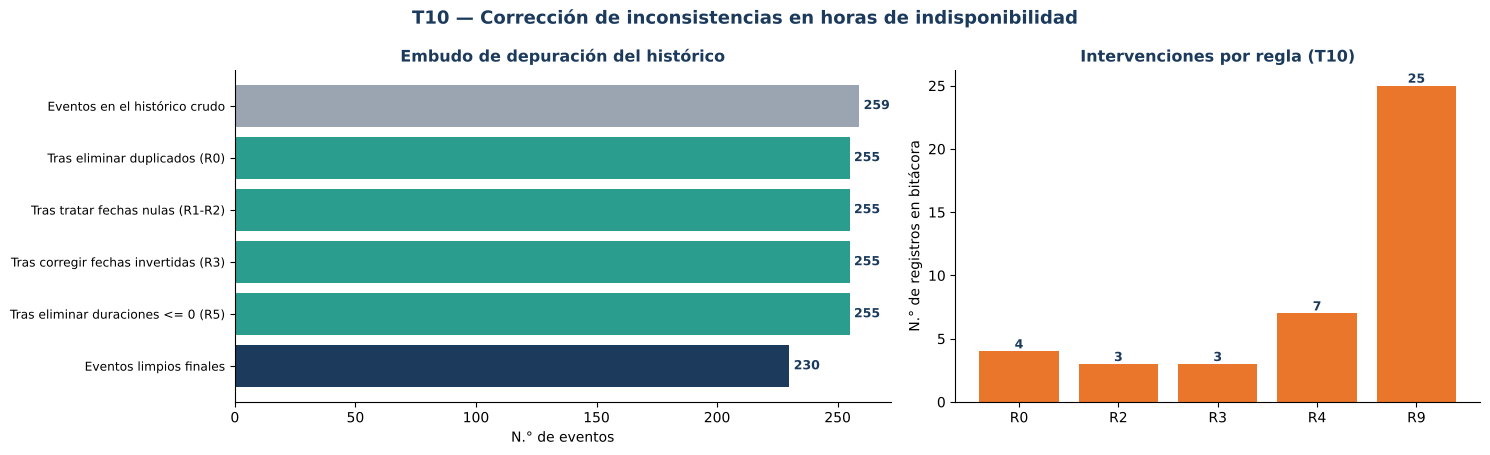

Registros que requieren validación con Operaciones / Product Owner: 10


,id_evento,regla,campo,valor_antes,valor_despues,accion,requiere_validacion
0,EV161,R0,id_evento,2 filas con distinto contenido,se conserva la última,Dato digitado más de una vez con valores distintos,True
1,EV190,R0,id_evento,2 filas con distinto contenido,se conserva la última,Dato digitado más de una vez con valores distintos,True
2,EV202,R0,id_evento,2 filas con distinto contenido,se conserva la última,Dato digitado más de una vez con valores distintos,True
3,EV247,R0,id_evento,2 filas con distinto contenido,se conserva la última,Dato digitado más de una vez con valores distintos,True
4,EV010,R2,fecha_fin,nula,2024-04-19 14:47:43,fin = inicio + duración (registrada = calculada),True
5,EV060,R2,fecha_fin,nula,2025-06-20 17:06:30,fin = inicio + duración (registrada = calculada),True
6,EV088,R2,fecha_fin,nula,2025-08-03 14:50:16,fin = inicio + duración (registrada = calculada),True
11,EV071,R4,duracion_h,5.49,7.29,Duración recalculada como fecha_fin - fecha_inicio,True
12,EV073,R4,duracion_h,7.4,6.2,Duración recalculada como fecha_fin - fecha_inicio,True
14,EV110,R4,duracion_h,6.82,5.62,Duración recalculada como fecha_fin - fecha_inicio,True


In [21]:
# ==== Vista visual - Embudo de depuración de eventos + resumen de reglas ====
etq, val = zip(*embudo)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
y = np.arange(len(etq))
ax.barh(y, val, color=[COLOR_GRAY] + [COLOR_TEAL] * (len(val) - 2) + [COLOR_NAVY])
for yi, v in zip(y, val): ax.text(v, yi, f' {v}', va='center', fontsize=9, color=COLOR_NAVY, fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(etq, fontsize=8.8); ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False); ax.set_xlabel('N.° de eventos')
ax.set_title('Embudo de depuración del histórico', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')

ax = axes[1]
if len(bitacora_correcciones_eventos):
    r = bitacora_correcciones_eventos.groupby('regla').size()
    ax.bar(r.index, r.values, color=COLOR_ORANGE)
    for xi, v in zip(r.index, r.values): ax.text(xi, v, str(v), ha='center', va='bottom', fontsize=9, fontweight='bold', color=COLOR_NAVY)
else:
    ax.text(0.5, 0.5, 'Sin correcciones registradas', ha='center', va='center', transform=ax.transAxes, color=COLOR_GRAY)
ax.spines[['top', 'right']].set_visible(False); ax.set_ylabel('N.° de registros en bitácora')
ax.set_title('Intervenciones por regla (T10)', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')
fig.suptitle('T10 — Corrección de inconsistencias en horas de indisponibilidad', fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

if len(bitacora_correcciones_eventos):
    pend = bitacora_correcciones_eventos[bitacora_correcciones_eventos['requiere_validacion']]
    print(f'Registros que requieren validación con Operaciones / Product Owner: {len(pend)}')
    display(pend.head(15))

### T10.1 Reconstrucción de los targets con los eventos limpios

Se vuelven a construir `ocurre_evento_6h`, `horas_hasta_inicio_6h` y `duracion_indisponibilidad_h` sobre la malla limpia. La función implementa la definición de HU01/T02: para cada origen se toma el evento **más próximo** con inicio en `(origen, origen + HORIZONTE_H]`; si no existe, los targets quedan en **NaN** (no se fuerza a 0, regla Q10).

#### V8 — Corrección de fuga: el origen de la predicción es el **cierre** de la hora

En el Sprint 1 cada hora se agrega con `resample('h')`, que **etiqueta la hora por su inicio**: la fila `2025-08-10 14:00` contiene el promedio de las lecturas de 14:00 a 14:55. Si la etiqueta se mide desde las 14:00, un evento que empieza a las 14:20 tiene su pico de oleaje **dentro de los predictores de su propia fila**. Es información que en operación real todavía no existe a las 14:00.

| | V7 | V8 (`ORIGEN_AL_CIERRE_H = 1`) |
|---|---|---|
| Predictores de la fila `t` | lecturas de `[t, t+1h)` | igual |
| Origen de la predicción | `t` | `t + 1h` (cuando la hora ya cerró) |
| Ventana de la etiqueta | `(t, t+H]` | `(t+1h, t+1h+H]` |

Con `ORIGEN_AL_CIERRE_H = 0` se reproduce la V7 (sirve para mostrar en el informe cuánto inflaba la fuga las métricas; ver *Diagnóstico de anticipación* en HU06). **Las métricas honestas son las de `ORIGEN_AL_CIERRE_H = 1`.**

> **Nombres de columnas:** desde la V9 los objetivos llevan el sufijo del horizonte efectivo de 6 h (`ocurre_evento_6h`, `horas_hasta_inicio_6h`). El horizonte queda registrado en `config_targets_HU05.json`.

> Si en tu sesión ya existe `construir_targets_evento()` del Sprint 1, puedes usarla: devuelve las mismas columnas. Aquí se incluye una versión **autocontenida y vectorizada** para que esta parte corra por sí sola.

In [22]:
# ==== T10.1 - Targets con eventos limpios ====
def construir_targets_hu05(timestamps, df_eventos, horizonte_h=HORIZONTE_H, desfase_origen_h=ORIGEN_AL_CIERRE_H):
    """Targets del evento más próximo con inicio en (origen, origen + horizonte_h], con origen = t + desfase_origen_h.
    desfase_origen_h = 1: la fila t resume [t, t+1h) y la predicción se emite al cierre de esa hora (sin fuga)."""
    ev_ord = df_eventos.sort_values('fecha_inicio')
    inicios = ev_ord['fecha_inicio'].values.astype('datetime64[ns]')
    duraciones = ((ev_ord['fecha_fin'] - ev_ord['fecha_inicio']) / pd.Timedelta(hours=1)).values
    t = (pd.DatetimeIndex(timestamps) + pd.Timedelta(hours=desfase_origen_h)).values.astype('datetime64[ns]')   # origen de la predicción
    pos = np.searchsorted(inicios, t, side='right')                 # primer inicio estrictamente > t
    hay = pos < len(inicios)
    pos_c = np.where(hay, pos, 0)
    h_hasta = (inicios[pos_c] - t) / np.timedelta64(1, 'h') if len(inicios) else np.full(len(t), np.nan)
    en_ventana = hay & (h_hasta <= horizonte_h)
    return pd.DataFrame({
        'ocurre_evento_6h': en_ventana.astype(int),
        'horas_hasta_inicio_6h': np.where(en_ventana, h_hasta, np.nan),
        'duracion_indisponibilidad_h': np.where(en_ventana, duraciones[pos_c], np.nan),
    }, index=pd.DatetimeIndex(timestamps))

# Comparación: filtro provisional de HU03 vs depuración completa de HU05
prov = (df_eventos_crudo.dropna(subset=['fecha_inicio', 'fecha_fin']).drop_duplicates('id_evento'))
prov = prov[prov['fecha_fin'] > prov['fecha_inicio']]
t_prov = construir_targets_hu05(df_limpio.index, prov)
t_limpio = construir_targets_hu05(df_limpio.index, df_eventos_limpio)

comparacion_targets = pd.DataFrame({
    'Filtro provisional (HU03)': [len(prov), int(t_prov['ocurre_evento_6h'].sum()), round(t_prov['duracion_indisponibilidad_h'].mean(), 2)],
    'Depuración completa (HU05)': [len(df_eventos_limpio), int(t_limpio['ocurre_evento_6h'].sum()), round(t_limpio['duracion_indisponibilidad_h'].mean(), 2)],
}, index=['Eventos utilizados', f'Horas con evento en las próximas {HORIZONTE_H} h', 'Duración media del evento (h)'])
print(f'Horizonte = {HORIZONTE_H} h  ·  origen de la predicción = t + {ORIGEN_AL_CIERRE_H} h (cierre de la hora)')
display(comparacion_targets)

df_limpio = df_limpio.join(t_limpio)

Horizonte = 6 h  ·  origen de la predicción = t + 1 h (cierre de la hora)


,Filtro provisional (HU03),Depuración completa (HU05)
Eventos utilizados,249.00,230.00
Horas con evento en las próximas 6 h,1494.00,1380.00
Duración media del evento (h),5.67,5.75


## Verificaciones finales, exportación y Definition of Done

Se ejecutan **comprobaciones automáticas** sobre el dataset resultante y se exportan los entregables de HU05.

In [23]:
# ==== Verificaciones finales (assertions) ====
chequeos = {
    'Índice horario único y ordenado': df_limpio.index.is_unique and df_limpio.index.is_monotonic_increasing,
    'Malla horaria continua (sin saltos)': (df_limpio.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(),
    'Sin valores fuera de rango físico en ninguna variable': all(
        df_limpio[v].dropna().between(*CONFIG_VARIABLES[v]['rango']).all() for v in VARIABLES),
    'Imputación solo en horas originalmente vacías': all(
        df_rango.loc[flags_imputacion[f'{v}_imputado'], v].isna().all() for v in VARIABLES),
    'Eventos: id_evento único': df_eventos_limpio['id_evento'].is_unique,
    'Eventos: fecha_fin > fecha_inicio en todos': (df_eventos_limpio['fecha_fin'] > df_eventos_limpio['fecha_inicio']).all(),
    'Eventos: duracion_h = fin - inicio': ((df_eventos_limpio['fecha_fin'] - df_eventos_limpio['fecha_inicio']) / pd.Timedelta(hours=1) - df_eventos_limpio['duracion_h']).abs().max() < 1e-6,
    f'Targets: horas_hasta_inicio_6h dentro de (0, {HORIZONTE_H}]': t_limpio['horas_hasta_inicio_6h'].dropna().between(0, HORIZONTE_H, inclusive='right').all(),
    'Targets: sin 0 forzado donde no hay evento (NaN)': t_limpio.loc[t_limpio['ocurre_evento_6h'] == 0, 'horas_hasta_inicio_6h'].isna().all(),
}
# Verificación estricta de huecos imputados: ninguno más largo que el límite
for v in VARIABLES:
    m = flags_imputacion[f'{v}_imputado']
    g = (m != m.shift(fill_value=False)).cumsum()
    mx = int(m.groupby(g).sum().max()) if m.any() else 0
    chequeos[f'Máx. racha imputada {v} <= {CONFIG_VARIABLES[v]["max_gap_h"]} h'] = mx <= CONFIG_VARIABLES[v]['max_gap_h']

tabla_chequeos = pd.DataFrame({'Verificación': list(chequeos), 'Resultado': ['OK' if bool(v) else 'FALLA' for v in chequeos.values()]})
display(tabla_chequeos)
assert (tabla_chequeos['Resultado'] == 'OK').all(), 'Hay verificaciones que fallan: revisar la tabla anterior.'

,Verificación,Resultado
0,Índice horario único y ordenado,OK
1,Malla horaria continua (sin saltos),OK
2,Sin valores fuera de rango físico en ninguna variable,OK
3,Imputación solo en horas originalmente vacías,OK
4,Eventos: id_evento único,OK
5,Eventos: fecha_fin > fecha_inicio en todos,OK
6,Eventos: duracion_h = fin - inicio,OK
7,"Targets: horas_hasta_inicio_6h dentro de (0, 6]",OK
8,Targets: sin 0 forzado donde no hay evento (NaN),OK
9,Máx. racha imputada velocidad_viento_ms <= 3 h,OK


In [24]:
# ==== Exportación de entregables de HU05 ====
import json
columnas_modelo = (['velocidad_viento_mph'] if 'velocidad_viento_mph' in df_limpio.columns else []) + VARIABLES
columnas_modelo = list(dict.fromkeys(columnas_modelo))
dataset_limpio = df_limpio[columnas_modelo + ['apto_modelado', 'n_predictores_imputados',
                                              'ocurre_evento_6h', 'horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']]

dataset_limpio.to_csv('dataset_limpio_horario_HU05.csv')
flags_imputacion.to_csv('flags_imputacion_HU05.csv')
df_eventos_limpio.to_csv('eventos_limpios_HU05.csv', index=False)
bitacora_vacios.to_csv('bitacora_vacios_HU05.csv', index=False)
bitacora_correcciones_eventos.to_csv('bitacora_correcciones_eventos_HU05.csv', index=False)
decision_variables.to_csv('decision_variables_HU05.csv', index=False)
Path('config_targets_HU05.json').write_text(json.dumps({'horizonte_h': HORIZONTE_H, 'origen_al_cierre_h': ORIGEN_AL_CIERRE_H,
    'nota': 'el sufijo _6h de los objetivos coincide con horizonte_h'}, indent=2), encoding='utf-8')

print('Archivos generados:')
for f in ['dataset_limpio_horario_HU05.csv', 'flags_imputacion_HU05.csv', 'eventos_limpios_HU05.csv',
          'bitacora_vacios_HU05.csv', 'bitacora_correcciones_eventos_HU05.csv', 'decision_variables_HU05.csv', 'config_targets_HU05.json']:
    print(f'  - {f}  ({Path(f).stat().st_size/1024:,.0f} KB)')

try:
    from google.colab import files
    # files.download('dataset_limpio_horario_HU05.csv')   # descomentar para descargar
except ImportError:
    pass

Archivos generados:
  - dataset_limpio_horario_HU05.csv  (3,905 KB)
  - flags_imputacion_HU05.csv  (1,522 KB)
  - eventos_limpios_HU05.csv  (51 KB)
  - bitacora_vacios_HU05.csv  (24 KB)
  - bitacora_correcciones_eventos_HU05.csv  (5 KB)
  - decision_variables_HU05.csv  (1 KB)
  - config_targets_HU05.json  (0 KB)


### Definition of Done — HU05 (T09 / T10)

La tabla se **calcula con los resultados reales** de esta ejecución (no está escrita a mano).

In [25]:
# ==== HU05 - Definition of Done (calculada) ====
def estado(c): return 'CUMPLE' if c else 'NO CUMPLE'
n_vars_exclusion = int((decision_variables['decision'] != 'CONSERVAR').sum())
dod_hu05 = pd.DataFrame([
    ['T09', 'Verificación y deduplicación por marca de tiempo documentada (CSV crudos e índice horario)', 'CUMPLE'],
    ['T09', 'Vacíos puntuales imputados con interpolación lineal/spline/circular acotada por variable', estado((tabla_chequeos['Resultado'] == 'OK').all())],
    ['T09', 'Vacíos prolongados documentados en bitácora, sin imputar', 'CUMPLE'],
    ['T09', f'Completitud global >= {UMBRAL_COMPLETITUD_PCT} % (actual: {completitud_global_despues:.2f} %)', estado(completitud_global_despues >= UMBRAL_COMPLETITUD_PCT)],
    ['T09', f'Variables a evaluar para exclusión: {n_vars_exclusion}', 'CUMPLE' if n_vars_exclusion == 0 else 'REVISAR'],
    ['T09', 'Banderas de imputación exportadas (dato medido vs imputado)', 'CUMPLE'],
    ['T10', 'Fechas invertidas y duraciones inconsistentes corregidas con bitácora', 'CUMPLE'],
    ['T10', 'Targets reconstruidos con eventos limpios', 'CUMPLE'],
    ['T10', 'Depuración de eventos por causa no meteo-oceanográfica',
     'CUMPLE' if col_causa else 'PENDIENTE (validar con Operaciones: no hay columna de causa)'],
    ['-', 'Decisiones que requieren validación del Product Owner listadas en la bitácora',
     f'{int(bitacora_correcciones_eventos["requiere_validacion"].sum()) if len(bitacora_correcciones_eventos) else 0} registros'],
], columns=['Tarea', 'Criterio de aceptación', 'Estado'])
display(dod_hu05)

,Tarea,Criterio de aceptación,Estado
0,T09,Verificación y deduplicación por marca de tiempo documentada (CSV crudos e índice horario),CUMPLE
1,T09,Vacíos puntuales imputados con interpolación lineal/spline/circular acotada por variable,CUMPLE
2,T09,"Vacíos prolongados documentados en bitácora, sin imputar",CUMPLE
3,T09,Completitud global >= 90 % (actual: 99.01 %),CUMPLE
4,T09,Variables a evaluar para exclusión: 0,CUMPLE
5,T09,Banderas de imputación exportadas (dato medido vs imputado),CUMPLE
6,T10,Fechas invertidas y duraciones inconsistentes corregidas con bitácora,CUMPLE
7,T10,Targets reconstruidos con eventos limpios,CUMPLE
8,T10,Depuración de eventos por causa no meteo-oceanográfica,CUMPLE
9,-,Decisiones que requieren validación del Product Owner listadas en la bitácora,10 registros


### Decisiones abiertas para validar (llevar a la asesora / Product Owner)

1. **Límites de interpolación por variable** (`max_gap_h`): son valores de partida; confirmar o ajustar con el diagnóstico de T09.3 y el criterio de Operaciones.
2. **`fecha_fin` nula:** se imputa como inicio + duración cuando las dos duraciones del CSV coinciden; confirmar con Operaciones (la alternativa es excluir el evento).
3. **Fuente de verdad de la duración:** se asumen las **fechas** (de ahí salen los targets); confirmar que la duración digitada no es la correcta en los casos con diferencia > 1 h.
4. **Eventos de causa no meteo-oceanográfica:** requieren una columna de causa en el histórico, o la validación directa con Operaciones (D02/Q04).
5. **Solapes entre eventos:** por defecto solo se marcan; decidir si se fusionan.

### Puente hacia HU06 (Ingeniería de características)

HU06 debe **respetar `apto_modelado`** y las banderas de imputación al construir los rezagos (t-1, t-2, t-3, t-6, t-12, t-24) y las ventanas móviles de 6 y 24 h: una ventana que cruza un bloque excluido no debe tratarse como dato continuo.

## 3.2 HU06 — Ingeniería de características

**Historia de usuario (TB2):** *Como Científico de datos, quiero transformar las variables meteorológicas y oceanográficas, para mejorar el aprendizaje del modelo.*

| N.° | Tarea | Contenido |
|---|---|---|
| 3.2.1 | **T11** (parte 1) | Seleccionar, descartar y **codificar** variables (dirección del viento → seno y coseno) |
| 3.2.2 | **T12** | Generar **variables derivadas** meteo-oceanográficas: rezagos, medias/desviaciones móviles, tasas de cambio y proporción imputada |
| 3.2.3 | **T11** (parte 2) | **Partición temporal** (entrenamiento / validación / prueba) y **normalización ajustada solo con entrenamiento** |

> **¿Por qué T11 aparece partido en dos?** La *codificación* no aprende nada de los datos (es una fórmula), así que va antes. La *normalización* sí aprende (media y desviación) y debe cubrir también las variables derivadas de T12, por eso se ajusta al final y **solo con el conjunto de entrenamiento**. Ajustarla antes de partir, o con todo el histórico, filtraría información del futuro hacia el entrenamiento (*data leakage*).

### Alineación con el TB2

| Elemento | Lo que dice el TB2 | Cómo se implementa aquí |
|---|---|---|
| Insumo | Dataset preparado en HU05 (Sprint 2) | `dataset_limpio_horario_HU05.csv` |
| Rezagos (inciso g) | t-1, t-2, t-3, t-6 (corto plazo) y t-12, t-24 (mediano plazo) | `LAGS_H = [1, 2, 3, 6, 12, 24]` |
| Estadísticos móviles (inciso g) | Media y desviación estándar en ventanas de 6 y 24 h | `VENTANAS_H = [6, 24]` |
| Validación temporal (inciso h) | *Walk-forward*: el entrenamiento solo usa información anterior al corte | Partición cronológica con purga igual al horizonte (6 h) + 4 *folds* walk-forward |
| Dos modelos | **Clasificador** de ocurrencia (F1-score y AUC) + **regresor de doble salida** (`horas_hasta_inicio_6h`, `duracion_indisponibilidad_h`; MAE, RMSE, MAPE, R²) | Dos tablas de entrenamiento derivadas del mismo dataset: `obtener_datos(..., 'clasificacion')` y `obtener_datos(..., 'regresion')` |
| Criterio de HU06 (DoD) | Documentar normalización/codificación, variables derivadas y partición train/test; dataset reproducible y apto para entrenamiento | Catálogo de variables, JSON de configuración, escalador serializado y verificaciones automáticas |

### Decisiones de HU05 ya validadas (HU06 las hereda; no se modificó ninguna celda de HU05)

| Decisión abierta de HU05 | Respuesta | Efecto en HU06 |
|---|---|---|
| Límites de interpolación por variable (`max_gap_h`) | La tolerancia actual es adecuada | Se mantiene el dataset HU05 tal cual; la proporción de datos imputados por ventana se mide en T12 |
| `fecha_fin` nula en el histórico | El método automático es aceptable | Los *targets* de HU05 ya incorporan ese tratamiento |
| Fuente de verdad de la duración | Se confía en las fechas y horas registradas por los sistemas del terminal | `duracion_indisponibilidad_h` = `fecha_fin − fecha_inicio` (sin cambios) |
| Eventos de causa no meteo-oceanográfica | Se excluyen | Ya excluidos en HU05 (R9); HU06 no recibe esos eventos |
| Solapes entre eventos | Mantener `FUSIONAR_SOLAPADOS = False` (solo marcar) | Sin cambios en los *targets* |

### Vista rápida: el flujo completo de HU06

In [26]:
# ==== HU06 - Preparación del entorno y configuración (EDITABLE) ====
import json, glob, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch
from IPython.display import display
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_columns', 60)

# --- Estilo: coincide con HU05 (si HU05 ya corrió en esta sesión, se reutilizan sus colores)
COLOR_NAVY    = globals().get('COLOR_NAVY',    '#1B3A5C')
COLOR_TEAL    = globals().get('COLOR_TEAL',    '#2A9D8F')
COLOR_TEAL_LT = globals().get('COLOR_TEAL_LT', '#D6EFEC')
COLOR_ORANGE  = globals().get('COLOR_ORANGE',  '#E9762B')
COLOR_RED     = globals().get('COLOR_RED',     '#C43D3D')
COLOR_GRAY    = globals().get('COLOR_GRAY',    '#9AA5B1')
COLOR_GRAY_LT = globals().get('COLOR_GRAY_LT', '#EEF1F4')
COLOR_GOLD    = globals().get('COLOR_GOLD',    '#E3A857')
plt.rcParams['font.family'] = 'DejaVu Sans'

def caja(ax, x, y, w, h, texto, color=COLOR_NAVY, texto_color='white', fontsize=10, fontweight='bold'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.05',
                                linewidth=1.5, edgecolor=color, facecolor=color, zorder=2))
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center', fontsize=fontsize,
            color=texto_color, fontweight=fontweight, zorder=3, linespacing=1.35)

def flecha(ax, p1, p2, color=COLOR_NAVY, lw=1.8, rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle='-|>', mutation_scale=15, color=color,
                                 lw=lw, connectionstyle=f'arc3,rad={rad}', zorder=1))

def lienzo(w=11, h=5, xlim=(0, 11), ylim=(0, 5)):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.axis('off')
    return fig, ax

# ---------------------------------------------------------------- parámetros
RUTA_DATASET = 'dataset_limpio_horario_HU05.csv'      # salida de HU05 (insumo de HU06)
HORIZONTE_H  = globals().get('HORIZONTE_H', 6)       # horizonte de predicción (HU01/T02)
ORIGEN_AL_CIERRE_H = globals().get('ORIGEN_AL_CIERRE_H', 1)
if Path('config_targets_HU05.json').exists():           # si HU06 corre en otra sesión, se respeta lo que construyó HU05
    _cfg05 = json.loads(Path('config_targets_HU05.json').read_text(encoding='utf-8'))
    HORIZONTE_H, ORIGEN_AL_CIERRE_H = _cfg05['horizonte_h'], _cfg05['origen_al_cierre_h']
SEMILLA      = 42

# ---- T11: selección, codificación y normalización
VARS_CONTINUAS = ['velocidad_viento_ms', 'temperatura_c', 'humedad_relative_pct',
                  'presion_atmosferica_hpa', 'altura_olas_m']
VAR_DIRECCION  = 'direccion_viento_deg'               # variable circular -> seno y coseno
COLUMNAS_DESCARTADAS = {
    'velocidad_viento_mph':             'Duplicada: es la misma variable que velocidad_viento_ms (se conserva m/s, unidad de la literatura)',
    'temperatura_interna_datalogger_c': 'Diagnóstico del equipo (HU05): no es predictor',
    'voltaje_datalogger_v':             'Diagnóstico del equipo (HU05): no es predictor',
}
ESCALADOR = 'standard'                                # 'standard' (z-score) | 'minmax' | 'robust'

# ---- T12: variables derivadas (TB2, inciso g)
LAGS_H         = [1, 2, 3, 6, 12, 24]                 # rezagos
VENTANAS_H     = [6, 24]                              # media y desviación móvil
TASAS_CAMBIO_H = [3, 6]                               # x(t) - x(t-k): tendencia (p. ej. caída de presión)
MAX_FRAC_IMPUTADA_VENTANA = 0.5                       # ventana (24 h) con más de este % imputado -> no entrenable
INCLUIR_FRAC_IMPUTADA_EN_X = False                    # True: la proporción imputada también entra como predictor

# ---- V8 · T12.6-T12.8: familias nuevas (cada una se puede apagar para medir su aporte)
INCLUIR_INTERACCION_FISICA  = True                    # T12.6 esfuerzo del viento, H·U, H², componentes u/v
INCLUIR_INTRAHORARIAS       = True                    # T12.7 máx / p90 / desv. por hora desde los CSV de 5 min (si están en la sesión)
INCLUIR_HISTORIAL_OPERATIVO = False                   # T12.8 evento en curso, horas desde el último evento (validar con el PO)
RHO_AIRE_KGM3 = 1.225                                 # densidad del aire a nivel del mar
CD_ARRASTRE   = 1.3e-3                                # coeficiente de arrastre aire-mar (valor típico para 3-15 m/s; Large & Pond, 1981)
TASAS_FIS_H   = [1, 3, 6]                             # tasas de cambio de las variables físicas (frentes de ráfaga)
VENTANAS_MAX_INTRA_H = [3, 6, 24]                     # máximo móvil de los picos intra-horarios
PATRONES_5MIN = {                                     # CSV crudos de 5 min (se aceptan nombres con espacio o guion bajo)
    'altura_olas_m':           ['Altura_de_Olas*.csv', 'Altura de Olas*.csv'],
    'velocidad_viento_ms':     ['Velocidad_de_Viento*.csv', 'Velocidad de Viento*.csv'],
    'presion_atmosferica_hpa': ['Presion_Atmosferica*.csv', 'Presion Atmosferica*.csv'],
}

# ---- Partición temporal (TB2, inciso h)
FRAC_TRAIN, FRAC_VAL = 0.70, 0.15                     # el resto (15 %) es prueba final
GAP_H       = HORIZONTE_H                             # purga: la etiqueta de t mira hasta t+HORIZONTE_H
N_FOLDS_WF  = 4                                       # ventanas walk-forward para medir estabilidad (HU08)

TARGETS = ['ocurre_evento_6h', 'horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']
TARGET_CLF, TARGETS_REG = TARGETS[0], TARGETS[1:]
N_PRED = len(VARS_CONTINUAS) + 1                      # predictores meteo-oceanográficos de HU05 (incluye dirección)
MIN_RACHA_H = max(max(LAGS_H) + 1, max(VENTANAS_H), max(TASAS_CAMBIO_H) + 1)   # horas aptas consecutivas necesarias

display(pd.DataFrame([
    ['T11', 'Variables continuas', ', '.join(VARS_CONTINUAS)],
    ['T11', 'Variable circular (seno/coseno)', VAR_DIRECCION],
    ['T11', 'Columnas descartadas', ', '.join(COLUMNAS_DESCARTADAS)],
    ['T11', 'Escalador (ajustado solo con entrenamiento)', ESCALADOR],
    ['T12', 'Rezagos (h)', str(LAGS_H)],
    ['T12', 'Ventanas móviles (h): media y desviación', str(VENTANAS_H)],
    ['T12', 'Tasas de cambio (h)', str(TASAS_CAMBIO_H)],
    ['T12', 'Horas aptas consecutivas exigidas', f'{MIN_RACHA_H} h (el rezago más largo necesita t-24 … t)'],
    ['T12', 'Máx. proporción imputada en la ventana de 24 h', f'{MAX_FRAC_IMPUTADA_VENTANA:.0%}'],
    ['T11', 'Partición temporal', f'{FRAC_TRAIN:.0%} entrenamiento / {FRAC_VAL:.0%} validación / {1-FRAC_TRAIN-FRAC_VAL:.0%} prueba, con purga de {GAP_H} h'],
    ['T11', 'Folds walk-forward', str(N_FOLDS_WF)],
    ['HU05', 'Horizonte / origen de la predicción', f'{HORIZONTE_H} h  ·  origen = t + {ORIGEN_AL_CIERRE_H} h'],
    ['T12.6', 'Interacción física aire-mar', f'{INCLUIR_INTERACCION_FISICA} (ρ = {RHO_AIRE_KGM3}, Cd = {CD_ARRASTRE})'],
    ['T12.7', 'Estadísticos intra-horarios (5 min)', str(INCLUIR_INTRAHORARIAS)],
    ['T12.8', 'Historial operativo', str(INCLUIR_HISTORIAL_OPERATIVO)],
], columns=['Tarea', 'Parámetro', 'Valor']))
print('Entorno HU06 listo.')

,Tarea,Parámetro,Valor
0,T11,Variables continuas,"velocidad_viento_ms, temperatura_c, humedad_relative_pct, presion_atmosferica_hpa, altura_olas_m"
1,T11,Variable circular (seno/coseno),direccion_viento_deg
2,T11,Columnas descartadas,"velocidad_viento_mph, temperatura_interna_datalogger_c, voltaje_datalogger_v"
3,T11,Escalador (ajustado solo con entrenamiento),standard
4,T12,Rezagos (h),"[1, 2, 3, 6, 12, 24]"
5,T12,Ventanas móviles (h): media y desviación,"[6, 24]"
6,T12,Tasas de cambio (h),"[3, 6]"
7,T12,Horas aptas consecutivas exigidas,25 h (el rezago más largo necesita t-24 … t)
8,T12,Máx. proporción imputada en la ventana de 24 h,50%
9,T11,Partición temporal,"70% entrenamiento / 15% validación / 15% prueba, con purga de 6 h"


Entorno HU06 listo.


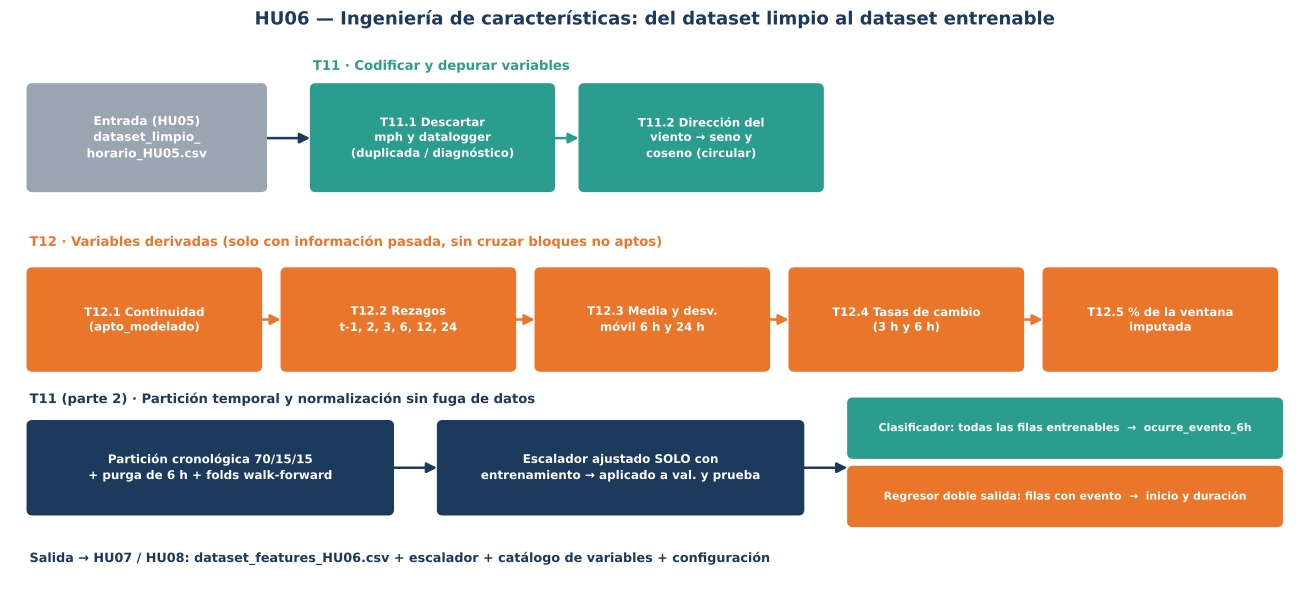

In [27]:
# ==== Vista rápida del flujo HU06 ====
fig, ax = lienzo(13.2, 6.0, xlim=(0, 13.2), ylim=(0, 6.0))
ax.set_title('HU06 — Ingeniería de características: del dataset limpio al dataset entrenable',
             fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

caja(ax, 0.2, 4.35, 2.4, 1.15, 'Entrada (HU05)\ndataset_limpio_\nhorario_HU05.csv', color=COLOR_GRAY, fontsize=8.8)
flecha(ax, (2.6, 4.92), (3.1, 4.92))
ax.text(3.1, 5.68, 'T11 · Codificar y depurar variables', fontsize=9.5, color=COLOR_TEAL, fontweight='bold')
for i, t in enumerate(['T11.1 Descartar\nmph y datalogger\n(duplicada / diagnóstico)',
                       'T11.2 Dirección del\nviento → seno y\ncoseno (circular)']):
    x = 3.1 + i * 2.75
    caja(ax, x, 4.35, 2.45, 1.15, t, color=COLOR_TEAL, fontsize=8.4)
    if i == 0: flecha(ax, (x + 2.45, 4.92), (x + 2.75, 4.92), color=COLOR_TEAL)

ax.text(0.2, 3.72, 'T12 · Variables derivadas (solo con información pasada, sin cruzar bloques no aptos)', fontsize=9.5, color=COLOR_ORANGE, fontweight='bold')
pasos = ['T12.1 Continuidad\n(apto_modelado)', 'T12.2 Rezagos\nt-1, 2, 3, 6, 12, 24', 'T12.3 Media y desv.\nmóvil 6 h y 24 h',
         'T12.4 Tasas de cambio\n(3 h y 6 h)', 'T12.5 % de la ventana\nimputada']
for i, t in enumerate(pasos):
    x = 0.2 + i * 2.6
    caja(ax, x, 2.35, 2.35, 1.1, t, color=COLOR_ORANGE, fontsize=8.4)
    if i < 4: flecha(ax, (x + 2.35, 2.9), (x + 2.6, 2.9), color=COLOR_ORANGE)

ax.text(0.2, 1.97, 'T11 (parte 2) · Partición temporal y normalización sin fuga de datos', fontsize=9.5, color=COLOR_NAVY, fontweight='bold')
caja(ax, 0.2, 0.75, 3.7, 1.0, f'Partición cronológica 70/15/15\n+ purga de {GAP_H} h + folds walk-forward', color=COLOR_NAVY, fontsize=8.6)
flecha(ax, (3.9, 1.25), (4.4, 1.25))
caja(ax, 4.4, 0.75, 3.7, 1.0, 'Escalador ajustado SOLO con\nentrenamiento → aplicado a val. y prueba', color=COLOR_NAVY, fontsize=8.6)
flecha(ax, (8.1, 1.25), (8.6, 1.25))
caja(ax, 8.6, 1.38, 4.4, 0.62, 'Clasificador: todas las filas entrenables  →  ocurre_evento_6h', color=COLOR_TEAL, fontsize=7.8)
caja(ax, 8.6, 0.62, 4.4, 0.62, 'Regresor doble salida: filas con evento  →  inicio y duración', color=COLOR_ORANGE, fontsize=7.8)
ax.text(0.2, 0.2, 'Salida → HU07 / HU08: dataset_features_HU06.csv + escalador + catálogo de variables + configuración', fontsize=9.2, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### Carga del insumo (salida de HU05)

Se lee `dataset_limpio_horario_HU05.csv` (malla horaria 2025-05-23 → 2026-08-12 con banderas `apto_modelado` y `n_predictores_imputados`, y los tres *targets* ya reconstruidos con los eventos limpios). Se **valida el esquema** y que la malla siga siendo continua antes de transformar nada.

In [28]:
# ==== Carga del insumo y validación de esquema ====
if not Path(RUTA_DATASET).exists():
    try:
        from google.colab import files
        print(f'Falta {RUTA_DATASET}. Si HU05 ya corrió en esta sesión, el archivo debería existir; si no, súbelo:')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'No se encontró {RUTA_DATASET} en el directorio de trabajo.')

df_hu05 = pd.read_csv(RUTA_DATASET, index_col='fecha_hora', parse_dates=['fecha_hora'])
if df_hu05['apto_modelado'].dtype != bool:           # por si el CSV trae 'True'/'False' como texto
    df_hu05['apto_modelado'] = df_hu05['apto_modelado'].astype(str).str.lower().eq('true')

requeridas = VARS_CONTINUAS + [VAR_DIRECCION, 'apto_modelado', 'n_predictores_imputados'] + TARGETS
faltan = [c for c in requeridas if c not in df_hu05.columns]
assert not faltan, f'Faltan columnas en el dataset de HU05: {faltan}'
assert df_hu05.index.is_unique and df_hu05.index.is_monotonic_increasing, 'El índice debe ser único y ordenado'
assert (df_hu05.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), 'La malla horaria no es continua'

n_total = len(df_hu05)
print(f'Dataset HU05: {n_total:,} filas x {df_hu05.shape[1]} columnas  ({df_hu05.index.min()} -> {df_hu05.index.max()})')
print(f"Horas aptas para modelado (apto_modelado): {int(df_hu05['apto_modelado'].sum()):,} de {n_total:,} "
      f"({100*df_hu05['apto_modelado'].mean():.2f} %)")
print(f"Horas con evento en las próximas {HORIZONTE_H} h (clase positiva): {int(df_hu05[TARGET_CLF].sum()):,} "
      f"({100*df_hu05[TARGET_CLF].mean():.1f} %)")
display(df_hu05.head(3))

Dataset HU05: 22,920 filas x 14 columnas  (2024-01-01 00:00:00 -> 2026-08-12 23:00:00)
Horas aptas para modelado (apto_modelado): 22,693 de 22,920 (99.01 %)
Horas con evento en las próximas 6 h (clase positiva): 1,380 (6.0 %)


,velocidad_viento_mph,velocidad_viento_ms,direccion_viento_deg,temperatura_c,humedad_relative_pct,presion_atmosferica_hpa,altura_olas_m,temperatura_interna_datalogger_c,voltaje_datalogger_v,apto_modelado,n_predictores_imputados,ocurre_evento_6h,horas_hasta_inicio_6h,duracion_indisponibilidad_h
fecha_hora,,,,,,,,,,,,,,
2024-01-01 00:00:00,9.430000,4.215587,247.898997,16.225000,88.326667,1006.377500,1.775833,19.709167,13.707500,True,0,0,NaN,NaN
2024-01-01 01:00:00,9.051818,4.046525,233.701882,16.081818,90.702727,1006.379091,1.503636,18.945455,13.675455,True,0,0,NaN,NaN
2024-01-01 02:00:00,10.058182,4.496410,257.516258,16.731818,86.590000,1006.559091,1.778182,19.110909,13.740000,True,0,0,NaN,NaN


## 3.2.1 T11 (parte 1) — Seleccionar y codificar variables

### T11.1 Descartar redundancias y variables de diagnóstico

| Columna | Decisión | Motivo |
|---|---|---|
| `velocidad_viento_mph` | **Descartar** | Es la **misma variable** que `velocidad_viento_ms` en otra unidad (HU05 la reconstruye desde m/s). Dejar las dos duplicaría información y, en modelos lineales, generaría colinealidad perfecta. Se conserva **m/s**, la unidad usada en la literatura del Estado del Arte. |
| `temperatura_interna_datalogger_c`, `voltaje_datalogger_v` | **Descartar** | Son variables de **diagnóstico del equipo**, no condiciones meteo-oceanográficas. Sirvieron en HU05 para explicar vacíos compartidos, pero no deben alimentar el modelo (el voltaje podría correlacionar con eventos por causas ajenas al clima). |
| `n_predictores_imputados`, `apto_modelado` | **Control de calidad** | No son predictores: sirven para decidir qué filas son utilizables y qué proporción de cada ventana fue imputada. |
| `ocurre_evento_6h`, `horas_hasta_inicio_6h`, `duracion_indisponibilidad_h` | **Objetivos** | Nunca entran en `X`. |

In [29]:
# ==== T11.1 - Selección de columnas ====
def _decision_columna(c):
    if c in COLUMNAS_DESCARTADAS:                 return 'DESCARTAR', COLUMNAS_DESCARTADAS[c]
    if c in VARS_CONTINUAS:                       return 'CONSERVAR (continua)', 'Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento'
    if c == VAR_DIRECCION:                        return 'CODIFICAR (seno/coseno)', 'Variable circular: 0° y 360° son la misma dirección'
    if c in TARGETS:                              return 'OBJETIVO', 'Variable a predecir (nunca entra en X)'
    if c in ('apto_modelado', 'n_predictores_imputados'): return 'CONTROL DE CALIDAD', 'Define filas utilizables y proporción imputada'
    return 'REVISAR', 'Columna no prevista: decidir si es predictor'

decision_columnas = pd.DataFrame([(c, *_decision_columna(c)) for c in df_hu05.columns],
                                 columns=['columna', 'decision', 'motivo'])
display(decision_columnas)
assert (decision_columnas['decision'] != 'REVISAR').all(), 'Hay columnas no previstas: revisar la tabla anterior'

# Evidencia de que mph y m/s son la misma variable
if 'velocidad_viento_mph' in df_hu05.columns:
    dif = (df_hu05['velocidad_viento_mph'] * 0.44704 - df_hu05['velocidad_viento_ms']).abs().max()
    print(f'Diferencia máxima |mph x 0.44704 - m/s| = {dif:.2e}  ->  misma variable en distinta unidad; se conserva m/s.')

,columna,decision,motivo
0,velocidad_viento_mph,DESCARTAR,"Duplicada: es la misma variable que velocidad_viento_ms (se conserva m/s, unidad de la literatura)"
1,velocidad_viento_ms,CONSERVAR (continua),Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento
2,direccion_viento_deg,CODIFICAR (seno/coseno),Variable circular: 0° y 360° son la misma dirección
3,temperatura_c,CONSERVAR (continua),Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento
4,humedad_relative_pct,CONSERVAR (continua),Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento
5,presion_atmosferica_hpa,CONSERVAR (continua),Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento
6,altura_olas_m,CONSERVAR (continua),Predictor meteo-oceanográfico; se normaliza con el escalador de entrenamiento
7,temperatura_interna_datalogger_c,DESCARTAR,Diagnóstico del equipo (HU05): no es predictor
8,voltaje_datalogger_v,DESCARTAR,Diagnóstico del equipo (HU05): no es predictor
9,apto_modelado,CONTROL DE CALIDAD,Define filas utilizables y proporción imputada


Diferencia máxima |mph x 0.44704 - m/s| = 1.78e-15  ->  misma variable en distinta unidad; se conserva m/s.


### T11.2 Dirección del viento como seno y coseno

La dirección es una variable **circular**: 359° y 1° están a solo 2° de distancia, pero como número difieren en 358. Un modelo que reciba grados crudos trataría ese par como opuestos. Se reemplaza por **dos componentes** que sí respetan la circularidad:

$$\text{dir\_viento\_sin} = \sin(\theta), \qquad \text{dir\_viento\_cos} = \cos(\theta), \qquad \theta = \text{grados}\times\frac{\pi}{180}$$

Cada hora queda como un punto sobre el círculo unitario (`sin² + cos² = 1`). Es coherente con HU05, donde la dirección ya se interpoló de forma circular. No requiere normalización posterior: ya está en [−1, 1].

Verificación: sin² + cos² = 1 en todas las horas (desviación máx. = 1.1e-16)
Dirección observada: 87° – 328°  (la codificación igual queda lista para cualquier valor 0–360°)


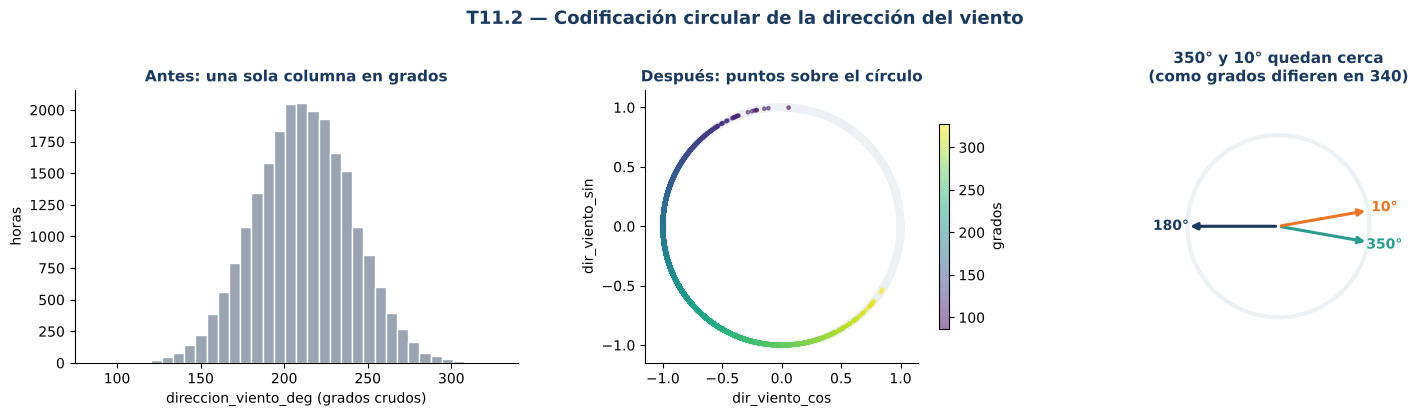

In [30]:
# ==== T11.2 - Codificación circular de la dirección del viento ====
_rad = np.deg2rad(df_hu05[VAR_DIRECCION])
base_hu06 = pd.DataFrame(index=df_hu05.index)
for v in VARS_CONTINUAS:
    base_hu06[v] = df_hu05[v]
base_hu06['dir_viento_sin'] = np.sin(_rad)
base_hu06['dir_viento_cos'] = np.cos(_rad)
VARS_CIRCULARES = ['dir_viento_sin', 'dir_viento_cos']
VARS_BASE = list(base_hu06.columns)

norma = np.sqrt(base_hu06['dir_viento_sin']**2 + base_hu06['dir_viento_cos']**2).dropna()
print(f'Verificación: sin² + cos² = 1 en todas las horas (desviación máx. = {(norma - 1).abs().max():.1e})')
ang_obs = df_hu05[VAR_DIRECCION].dropna()
print(f'Dirección observada: {ang_obs.min():.0f}° – {ang_obs.max():.0f}°  (la codificación igual queda lista para cualquier valor 0–360°)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ax = axes[0]
ax.hist(ang_obs, bins=36, color=COLOR_GRAY, edgecolor='white')
ax.set_xlabel('direccion_viento_deg (grados crudos)'); ax.set_ylabel('horas')
ax.set_title('Antes: una sola columna en grados', fontsize=11, color=COLOR_NAVY, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
th = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(th), np.sin(th), color=COLOR_GRAY_LT, lw=6, zorder=1)
sc = ax.scatter(base_hu06['dir_viento_cos'], base_hu06['dir_viento_sin'], c=ang_obs.reindex(base_hu06.index),
                cmap='viridis', s=6, alpha=0.5, zorder=2)
ax.set_aspect('equal'); ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
ax.set_xlabel('dir_viento_cos'); ax.set_ylabel('dir_viento_sin')
ax.set_title('Después: puntos sobre el círculo', fontsize=11, color=COLOR_NAVY, fontweight='bold')
fig.colorbar(sc, ax=ax, shrink=0.75, label='grados')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[2]
demo = np.array([350, 10, 180])
for ang, col, lab in zip(demo, [COLOR_TEAL, COLOR_ORANGE, COLOR_NAVY], ['350°', '10°', '180°']):
    ax.annotate('', xy=(np.cos(np.deg2rad(ang)), np.sin(np.deg2rad(ang))), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=col, lw=2.2))
    ax.text(1.18*np.cos(np.deg2rad(ang)), 1.18*np.sin(np.deg2rad(ang)), lab, color=col, ha='center', va='center', fontweight='bold')
ax.plot(np.cos(th), np.sin(th), color=COLOR_GRAY_LT, lw=3)
ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.axis('off')
ax.set_title('350° y 10° quedan cerca\n(como grados difieren en 340)', fontsize=11, color=COLOR_NAVY, fontweight='bold')
fig.suptitle('T11.2 — Codificación circular de la dirección del viento', fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

## 3.2.2 T12 — Generar variables derivadas meteo-oceanográficas

Un **rezago** (t-1, t-6, t-24…) es una variable derivada: no existe en el dato crudo, se construye a partir de las variables ya limpias. Las condiciones de mar y viento no afectan la operación de forma instantánea sino con un efecto **acumulado y desfasado**, por eso se incorpora memoria temporal explícita (TB2, inciso g).

### Familias de variables derivadas

| Familia | Definición | Variables base | Parámetros |
|---|---|---|---|
| **Valor actual** | Lectura de la hora de origen `t` | 5 continuas + `dir_viento_sin/cos` | — |
| **Rezagos** | `x(t-k)` | 5 continuas + `dir_viento_sin/cos` | k = 1, 2, 3, 6, 12, 24 h |
| **Media móvil** | media de `x(t-w+1) … x(t)` | 5 continuas + `dir_viento_sin/cos` (media circular) | w = 6 y 24 h |
| **Desviación móvil** | desviación estándar en la misma ventana | solo 5 continuas | w = 6 y 24 h |
| **Tasa de cambio** | `x(t) − x(t-k)` (tendencia: p. ej. caída de presión, crecimiento del oleaje) | solo 5 continuas | k = 3 y 6 h |
| **Proporción imputada** | fracción de los datos de la ventana que HU05 interpoló | global (usa `n_predictores_imputados`) | w = 6 y 24 h |

### Regla de continuidad: una ventana que cruza un bloque no apto no es un dato continuo

HU05 dejó marcadas las horas con `apto_modelado = False` (fallas prolongadas). Si un rezago o una ventana móvil **atraviesa** una de esas horas, mezclaría datos medidos antes y después de un hueco como si fueran vecinos. Regla aplicada:

1. Para cada hora `t` se calcula `racha_apto(t)`: cuántas horas aptas **consecutivas** terminan en `t`.
2. Un rezago de `k` horas (y una tasa de cambio de `k` horas) solo es válido si `racha_apto(t) ≥ k + 1`: **todas** las horas entre `t-k` y `t` son aptas.
3. Una ventana móvil de `w` horas solo es válida si `racha_apto(t) ≥ w`.
4. Cuando no se cumple, la variable queda en **NaN**; **no se rellena ni se interpola**. La fila no se usa para entrenar.

Consecuencia: tras cada bloque no apto se pierden las primeras 25 horas como filas entrenables (el rezago de 24 h necesita `t-24 … t`). Es un costo deliberado de no inventar continuidad.

### Regla de causalidad (anti *data-leakage*)

Toda variable en `t` usa **solo información de `t` hacia atrás**. Nunca se usan rezagos negativos ni ventanas centradas. El target de `t` mira hacia adelante (`t, t+6 h]`; los predictores, jamás.

In [31]:
# ==== T12 - Construcción de variables derivadas (función reproducible) ====
def construir_features(base, apto, imputados, lags=None, ventanas=None, tasas=None, n_pred=N_PRED):
    """Construye las variables derivadas usando SOLO información de t y anteriores.
    Un rezago/ventana que cruza una hora no apta queda en NaN (no se rellena).
    Devuelve (X, meta_calidad, racha_apto, catalogo)."""
    lags     = LAGS_H if lags is None else lags
    ventanas = VENTANAS_H if ventanas is None else ventanas
    tasas    = TASAS_CAMBIO_H if tasas is None else tasas
    apto = apto.astype(bool)
    racha = apto.astype(int).groupby((~apto).cumsum()).cumsum()     # horas aptas consecutivas que terminan en t
    cols, cat = {}, []

    def agregar(nombre, serie, var, tipo, param):
        cols[nombre] = serie
        cat.append({'variable': nombre, 'variable_base': var, 'tipo': tipo, 'parametro_h': param,
                    'escalar': var not in VARS_CIRCULARES})

    for v in base.columns:                                           # 1) valor actual
        agregar(v, base[v].where(apto), v, 'actual', 0)
    for v in base.columns:                                           # 2) rezagos
        for k in lags:
            agregar(f'{v}_lag{k}h', base[v].shift(k).where(racha >= k + 1), v, 'rezago', k)
    for v in base.columns:                                           # 3) media y desviación móvil
        s = base[v].where(apto)
        for w in ventanas:
            ok = racha >= w
            agregar(f'{v}_media{w}h', s.rolling(w, min_periods=w).mean().where(ok), v, 'media_movil', w)
            if v not in VARS_CIRCULARES:
                agregar(f'{v}_std{w}h', s.rolling(w, min_periods=w).std().where(ok), v, 'desv_movil', w)
    for v in [c for c in base.columns if c not in VARS_CIRCULARES]:  # 4) tasas de cambio
        for k in tasas:
            agregar(f'{v}_delta{k}h', (base[v] - base[v].shift(k)).where(racha >= k + 1), v, 'tasa_cambio', k)

    meta = {}
    for w in ventanas:                                               # 5) proporción de la ventana que fue imputada
        meta[f'frac_imputada_{w}h'] = (imputados.rolling(w, min_periods=w).sum() / (n_pred * w)).where(racha >= w)
    return pd.DataFrame(cols), pd.DataFrame(meta), racha, pd.DataFrame(cat)

X_feat, meta_calidad, racha_apto, catalogo = construir_features(
    base_hu06, df_hu05['apto_modelado'], df_hu05['n_predictores_imputados'])

# Matriz de predictores (la proporción imputada es metadato salvo que se pida lo contrario)
X_modelo = X_feat.join(meta_calidad) if INCLUIR_FRAC_IMPUTADA_EN_X else X_feat
X_COLS = list(X_modelo.columns)
COLS_ESCALAR = [c for c in catalogo.loc[catalogo['escalar'], 'variable'] if c in X_COLS]
COLS_SIN_ESCALAR = [c for c in X_COLS if c not in COLS_ESCALAR]

print(f'Variables derivadas generadas: {X_feat.shape[1]}  ·  predictores en X: {len(X_COLS)}  ·  se normalizan: {len(COLS_ESCALAR)}  ·  no se normalizan (seno/coseno, % imputado): {len(COLS_SIN_ESCALAR)}')
resumen_tipos = (catalogo.groupby('tipo', sort=False)
                 .agg(n_variables=('variable', 'size'), parametros_h=('parametro_h', lambda s: ', '.join(map(str, sorted(set(s))))))
                 .reset_index())
display(resumen_tipos)
display(catalogo.head(8))

Variables derivadas generadas: 83  ·  predictores en X: 83  ·  se normalizan: 65  ·  no se normalizan (seno/coseno, % imputado): 18


,tipo,n_variables,parametros_h
0,actual,7,0
1,rezago,42,"1, 2, 3, 6, 12, 24"
2,media_movil,14,"6, 24"
3,desv_movil,10,"6, 24"
4,tasa_cambio,10,"3, 6"


,variable,variable_base,tipo,parametro_h,escalar
0,velocidad_viento_ms,velocidad_viento_ms,actual,0,True
1,temperatura_c,temperatura_c,actual,0,True
2,humedad_relative_pct,humedad_relative_pct,actual,0,True
3,presion_atmosferica_hpa,presion_atmosferica_hpa,actual,0,True
4,altura_olas_m,altura_olas_m,actual,0,True
5,dir_viento_sin,dir_viento_sin,actual,0,False
6,dir_viento_cos,dir_viento_cos,actual,0,False
7,velocidad_viento_ms_lag1h,velocidad_viento_ms,rezago,1,True


### T12.6 (V8) — Variables de interacción física aire-mar

El oleaje y el viento no actúan aislados. Se agregan combinaciones con sentido físico, calculadas **solo con información de `t` hacia atrás** y respetando la misma regla de continuidad (`racha_apto`):

| Variable | Fórmula | Interpretación |
|---|---|---|
| `esfuerzo_viento_nm2` | τ = ρ<sub>aire</sub> · C<sub>d</sub> · U² | Transferencia de momento del viento a la superficie del mar (N/m²) |
| `interaccion_ola_viento` | H<sub>s</sub> · U | Mar y viento fuertes **a la vez** (lo que detiene una maniobra) |
| `energia_ola_rel` | H<sub>s</sub>² | Proporcional a la energía de la ola (E = ρ g H²/16) |
| `viento_u`, `viento_v` | U·sen θ, U·cos θ | Viento **con dirección**: separa viento hacia tierra del viento hacia el mar |

Para cada una: tasas de cambio a 1, 3 y 6 h (frentes de ráfaga, crecimiento rápido del mar de leva), media y **máximo** móvil de 6 h, cociente media 6 h / media 24 h (aceleración reciente frente al día) y anomalía frente a la media de 24 h.


In [32]:
# ==== T12.6 / T12.7 / T12.8 (V8) - Familias nuevas de variables derivadas ====
def _cargar_5min(patrones, rango=None):
    rutas = [r for p in patrones for r in glob.glob(p)]
    if not rutas:
        return None
    x = pd.read_csv(rutas[0], encoding='utf-8').iloc[:, :2]; x.columns = ['Time', 'v']
    x['Time'] = pd.to_datetime(x['Time'], errors='coerce')
    x['v'] = pd.to_numeric(x['v'].astype(str).str.replace(',', '.').str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce')
    x = x.dropna(subset=['Time']).drop_duplicates('Time', keep='last').set_index('Time')['v'].sort_index()
    if rango is not None:
        x = x.where(x.between(*rango))
    return x

def estadisticos_intrahorarios(indice, apto, medias_horarias):
    """Máximo, p90 y desviación por hora desde las lecturas de 5 min (misma convención de etiqueta que el Sprint 1:
    la hora t resume [t, t+1h)). En horas aptas sin lecturas crudas (imputadas en HU05) el máximo/p90/mínimo se
    sustituye por el valor horario imputado y la desviación por 0 (queda reflejado en frac_imputada)."""
    fuentes = {}
    for v, pats in PATRONES_5MIN.items():
        rango = CONFIG_VARIABLES[v]['rango'] if 'CONFIG_VARIABLES' in globals() and v in CONFIG_VARIABLES else None
        s = _cargar_5min(pats)
        if s is None:
            return None, f'falta el CSV de 5 min de {v}'
        if v == 'velocidad_viento_ms':
            s = s * 0.44704                                       # el datalogger registra mph
        if rango is not None:
            s = s.where(s.between(*rango))
        fuentes[v] = s
    out = pd.DataFrame(index=indice)
    for v in ['altura_olas_m', 'velocidad_viento_ms']:
        g = fuentes[v].resample('h')
        out[f'{v}_max1h'], out[f'{v}_p90_1h'], out[f'{v}_std1h'] = g.max().reindex(indice), g.quantile(0.9).reindex(indice), g.std().reindex(indice)
        for c in [f'{v}_max1h', f'{v}_p90_1h']:
            out[c] = out[c].fillna(medias_horarias[v])
        out[f'{v}_std1h'] = out[f'{v}_std1h'].fillna(0.0)
    out['presion_min1h'] = fuentes['presion_atmosferica_hpa'].resample('h').min().reindex(indice).fillna(medias_horarias['presion_atmosferica_hpa'])
    return out.where(apto), 'ok'

def construir_features_extra(base, apto, racha, intra=None, eventos=None):
    """T12.6-T12.8. Mismas reglas que construir_features: solo pasado, NaN si la ventana cruza una hora no apta."""
    cols, cat = {}, []
    def agregar(nombre, serie, var, tipo, param, escalar=True):
        cols[nombre] = serie; cat.append({'variable': nombre, 'variable_base': var, 'tipo': tipo, 'parametro_h': param, 'escalar': escalar})
    def familia(s_cruda, nombre, tipo, tasas, ventanas_max, extra=True):
        s = s_cruda.where(apto)
        agregar(nombre, s, nombre, tipo, 0)
        for k in tasas:
            agregar(f'{nombre}_delta{k}h', (s_cruda - s_cruda.shift(k)).where(racha >= k + 1), nombre, tipo, k)
        for w in ventanas_max:
            agregar(f'{nombre}_max{w}h', s.rolling(w, min_periods=w).max().where(racha >= w), nombre, tipo, w)
        if extra:
            m6, m24 = s.rolling(6, min_periods=6).mean().where(racha >= 6), s.rolling(24, min_periods=24).mean().where(racha >= 24)
            agregar(f'{nombre}_media6h', m6, nombre, tipo, 6)
            agregar(f'{nombre}_ratio6_24h', m6 / (m24.abs() + 1e-6), nombre, tipo, 24)
            agregar(f'{nombre}_anom24h', s - m24, nombre, tipo, 24)

    if INCLUIR_INTERACCION_FISICA:
        U, Hs = base['velocidad_viento_ms'], base['altura_olas_m']
        fis = {'esfuerzo_viento_nm2': RHO_AIRE_KGM3 * CD_ARRASTRE * U ** 2, 'interaccion_ola_viento': Hs * U,
               'energia_ola_rel': Hs ** 2, 'viento_u': U * base['dir_viento_sin'], 'viento_v': U * base['dir_viento_cos']}
        for n, s in fis.items():
            familia(s, n, 'interaccion_fisica', TASAS_FIS_H, [6])

    if intra is not None:
        for n in intra.columns:
            familia(intra[n], n, 'intrahoraria', [1, 3], [] if n.startswith('presion') else VENTANAS_MAX_INTRA_H, extra=False)
            agregar(f'{n}_lag1h', intra[n].shift(1).where(racha >= 2), n, 'intrahoraria', 1)
        pico = intra['altura_olas_m_max1h'] * intra['velocidad_viento_ms_max1h']
        familia(pico, 'pico_ola_x_pico_viento', 'intrahoraria', [1, 3], [6], extra=False)
        familia(RHO_AIRE_KGM3 * CD_ARRASTRE * intra['velocidad_viento_ms_max1h'] ** 2, 'esfuerzo_viento_pico_nm2', 'intrahoraria', [1, 3], [6], extra=False)

    if eventos is not None:
        e = eventos.sort_values('fecha_inicio')
        ini, fin = e['fecha_inicio'].values.astype('datetime64[ns]'), np.sort(e['fecha_fin'].values.astype('datetime64[ns]'))
        t = (base.index + pd.Timedelta(hours=ORIGEN_AL_CIERRE_H)).values.astype('datetime64[ns]')   # lo que el terminal sabe al emitir
        p = np.searchsorted(ini, t, side='right') - 1; okp = p >= 0; pc = np.clip(p, 0, None)
        fin_ult_iniciado = e['fecha_fin'].values.astype('datetime64[ns]')[pc]
        q = np.searchsorted(fin, t, side='right') - 1
        h_fin = np.where(q >= 0, (t - fin[np.clip(q, 0, None)]) / np.timedelta64(1, 'h'), 500.0)
        n_en = lambda h: np.searchsorted(ini, t, side='right') - np.searchsorted(ini, t - np.timedelta64(h, 'h'), side='right')
        hist = {'evento_en_curso': (okp & (fin_ult_iniciado > t)).astype(float),
                'h_desde_fin_ultimo_evento': np.minimum(h_fin, 500.0), 'eventos_ultimas_72h': n_en(72).astype(float), 'eventos_ultimos_7d': n_en(168).astype(float)}
        for n, v in hist.items():
            agregar(n, pd.Series(v, index=base.index).where(apto), n, 'historial_operativo', 0, escalar=(n != 'evento_en_curso'))
    return pd.DataFrame(cols, index=base.index), pd.DataFrame(cat)

# ---- Insumos de las familias opcionales
INTRA_HORARIA, motivo_intra = (None, 'desactivado')
if INCLUIR_INTRAHORARIAS:
    INTRA_HORARIA, motivo_intra = estadisticos_intrahorarios(df_hu05.index, df_hu05['apto_modelado'], df_hu05)
    if INTRA_HORARIA is None:
        try:
            from google.colab import files
            print(f'T12.7 necesita los CSV crudos de 5 min ({motivo_intra}). Súbelos (Altura de Olas, Velocidad de Viento, Presión):')
            files.upload()
            INTRA_HORARIA, motivo_intra = estadisticos_intrahorarios(df_hu05.index, df_hu05['apto_modelado'], df_hu05)
        except ImportError:
            pass
EVENTOS_HIST = None
if INCLUIR_HISTORIAL_OPERATIVO:
    if 'df_eventos_limpio' in globals():
        EVENTOS_HIST = df_eventos_limpio
    elif Path('eventos_limpios_HU05.csv').exists():
        EVENTOS_HIST = pd.read_csv('eventos_limpios_HU05.csv', parse_dates=['fecha_inicio', 'fecha_fin'])

X_extra, catalogo_extra = construir_features_extra(base_hu06, df_hu05['apto_modelado'], racha_apto, INTRA_HORARIA, EVENTOS_HIST)

# ---- Se integran al catálogo y a la matriz de HU06 (las celdas siguientes no cambian)
X_feat = X_feat.join(X_extra)
catalogo = pd.concat([catalogo, catalogo_extra], ignore_index=True)
X_modelo = X_feat.join(meta_calidad) if INCLUIR_FRAC_IMPUTADA_EN_X else X_feat
X_COLS = list(X_modelo.columns)
COLS_ESCALAR = [c for c in catalogo.loc[catalogo['escalar'], 'variable'] if c in X_COLS]
COLS_SIN_ESCALAR = [c for c in X_COLS if c not in COLS_ESCALAR]

print(f'T12.6 interacción física : {int((catalogo_extra["tipo"] == "interaccion_fisica").sum()) if len(catalogo_extra) else 0} variables')
print(f'T12.7 intra-horarias     : {int((catalogo_extra["tipo"] == "intrahoraria").sum()) if len(catalogo_extra) else 0} variables  ({motivo_intra})')
print(f'T12.8 historial operativo: {int((catalogo_extra["tipo"] == "historial_operativo").sum()) if len(catalogo_extra) else 0} variables')
print(f'Predictores totales en X: {len(X_COLS)}  ·  se normalizan: {len(COLS_ESCALAR)}')
if INTRA_HORARIA is not None:
    comp_pico = pd.DataFrame({'media horaria (HU05)': df_hu05[['altura_olas_m', 'velocidad_viento_ms']].max().values,
                              'máximo de 5 min (T12.7)': INTRA_HORARIA[['altura_olas_m_max1h', 'velocidad_viento_ms_max1h']].max().values},
                             index=['altura_olas_m (m)', 'velocidad_viento_ms (m/s)']).round(2)
    print('\nValor más alto del periodo según cómo se agrega la hora (la media aplana los picos):'); display(comp_pico)


T12.6 interacción física : 40 variables
T12.7 intra-horarias     : 54 variables  (ok)
T12.8 historial operativo: 0 variables
Predictores totales en X: 177  ·  se normalizan: 159

Valor más alto del periodo según cómo se agrega la hora (la media aplana los picos):


,media horaria (HU05),máximo de 5 min (T12.7)
altura_olas_m (m),5.71,6.50
velocidad_viento_ms (m/s),16.20,19.45


,Etapa,filas,% de la malla
0,Horas en la malla (HU05),22920,100.00
1,Aptas para modelado (apto_modelado),22693,99.01
2,Con 25 h aptas consecutivas (features completas),21925,95.66
3,Ventana de 24 h con ≤ 50% imputado → CLASIFICADOR,21925,95.66
4,Con evento en las próximas 6 h → REGRESOR doble salida,1334,5.82


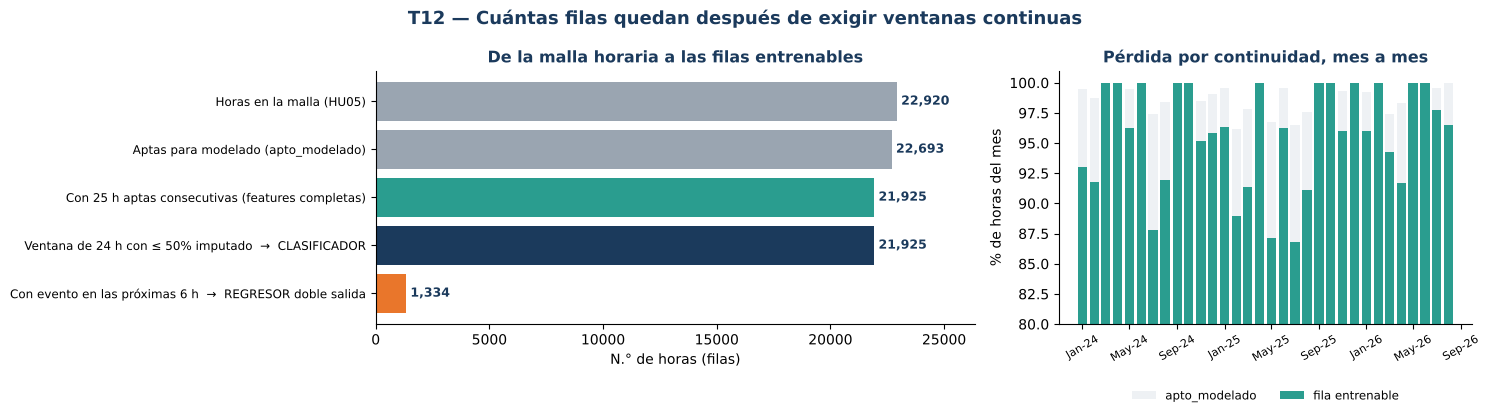

Proporción imputada de la ventana de 24 h: media 0.15 %, máx. 8.3 %  ·  filas por encima del umbral de 50%: 0


In [33]:
# ==== T12 - Filas entrenables (continuidad + proporción imputada) y los dos conjuntos de tareas ====
feat_completa  = X_feat.notna().all(axis=1)                          # todos los rezagos/ventanas válidos
frac_max_col   = f'frac_imputada_{max(VENTANAS_H)}h'
frac_ok        = meta_calidad[frac_max_col] <= MAX_FRAC_IMPUTADA_VENTANA

entrenable_clf = feat_completa & frac_ok                              # clasificador: toda fila con features completas
entrenable_reg = (entrenable_clf & df_hu05[TARGET_CLF].eq(1)
                  & df_hu05[TARGETS_REG].notna().all(axis=1))         # regresor: solo orígenes con evento en las próximas HORIZONTE_H horas

assert (feat_completa == (racha_apto >= MIN_RACHA_H)).all(), 'La completitud de features no coincide con la regla de continuidad'

embudo_filas = [
    ('Horas en la malla (HU05)', len(df_hu05)),
    ('Aptas para modelado (apto_modelado)', int(df_hu05['apto_modelado'].sum())),
    (f'Con {MIN_RACHA_H} h aptas consecutivas (features completas)', int(feat_completa.sum())),
    (f'Ventana de 24 h con ≤ {MAX_FRAC_IMPUTADA_VENTANA:.0%} imputado  →  CLASIFICADOR', int(entrenable_clf.sum())),
    (f'Con evento en las próximas {HORIZONTE_H} h  →  REGRESOR doble salida', int(entrenable_reg.sum())),
]
tabla_embudo = pd.DataFrame(embudo_filas, columns=['Etapa', 'filas'])
tabla_embudo['% de la malla'] = (100 * tabla_embudo['filas'] / len(df_hu05)).round(2)
display(tabla_embudo)

etq, val = zip(*embudo_filas)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
ax = axes[0]
y = np.arange(len(etq))
ax.barh(y, val, color=[COLOR_GRAY, COLOR_GRAY, COLOR_TEAL, COLOR_NAVY, COLOR_ORANGE])
for yi, v in zip(y, val): ax.text(v, yi, f' {v:,}', va='center', fontsize=9, color=COLOR_NAVY, fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(etq, fontsize=8.6); ax.invert_yaxis(); ax.set_xlim(0, max(val) * 1.15)
ax.spines[['top', 'right']].set_visible(False); ax.set_xlabel('N.° de horas (filas)')
ax.set_title('De la malla horaria a las filas entrenables', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')

ax = axes[1]
mensual = pd.DataFrame({'entrenable': entrenable_clf, 'apto': df_hu05['apto_modelado']}).resample('MS').mean() * 100
ax.bar(mensual.index, mensual['apto'], width=24, color=COLOR_GRAY_LT, label='apto_modelado')
ax.bar(mensual.index, mensual['entrenable'], width=24, color=COLOR_TEAL, label='fila entrenable')
ax.set_ylim(80, 101); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y')); ax.tick_params(axis='x', labelsize=8, rotation=30)
ax.set_ylabel('% de horas del mes'); ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Pérdida por continuidad, mes a mes', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')
fig.suptitle('T12 — Cuántas filas quedan después de exigir ventanas continuas', fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

fi = meta_calidad[frac_max_col].dropna()
print(f'Proporción imputada de la ventana de {max(VENTANAS_H)} h: media {100*fi.mean():.2f} %, máx. {100*fi.max():.1f} %  ·  '
      f'filas por encima del umbral de {MAX_FRAC_IMPUTADA_VENTANA:.0%}: {int((fi > MAX_FRAC_IMPUTADA_VENTANA).sum())}')

Bloques no aptos heredados de HU05: 31  ·  horas no aptas: 227  ·  bloque más largo: 19 h


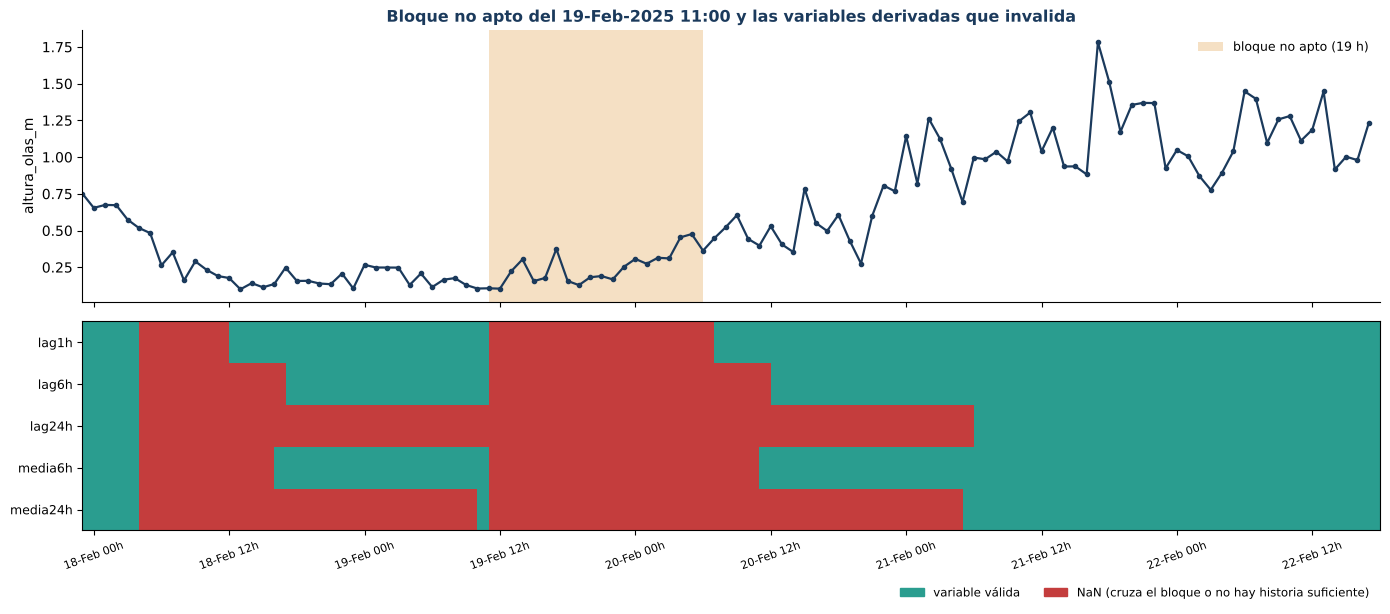

Lectura: tras el bloque, cada variable derivada recupera validez recién cuando toda su ventana vuelve a ser apta (lag1 casi de inmediato; lag24 y media24h, 24-25 h después).


In [34]:
# ==== Vista visual - Un bloque no apto y qué variables derivadas invalida ====
no_apto = ~df_hu05['apto_modelado']
grupo = (no_apto != no_apto.shift(fill_value=False)).cumsum()
bloques_hu06 = pd.DataFrame([{'inicio': b.index[0], 'fin': b.index[-1], 'horas': len(b)}
                             for _, b in df_hu05[no_apto].groupby(grupo[no_apto])])
print(f'Bloques no aptos heredados de HU05: {len(bloques_hu06)}  ·  horas no aptas: {int(no_apto.sum())}  ·  bloque más largo: {int(bloques_hu06["horas"].max())} h')

# Se elige el bloque más largo que deje margen a ambos lados
cand = bloques_hu06[(bloques_hu06['inicio'] > df_hu05.index[0] + pd.Timedelta(hours=40)) &
                    (bloques_hu06['fin'] < df_hu05.index[-1] - pd.Timedelta(hours=60))]
b = cand.sort_values('horas', ascending=False).iloc[0]
ini_v, fin_v = b['inicio'] - pd.Timedelta(hours=36), b['fin'] + pd.Timedelta(hours=60)
ventana = df_hu05.loc[ini_v:fin_v]

v_demo = 'altura_olas_m'
feats_demo = [f'{v_demo}_lag1h', f'{v_demo}_lag6h', f'{v_demo}_lag24h', f'{v_demo}_media6h', f'{v_demo}_media24h']
M = X_feat.loc[ini_v:fin_v, feats_demo].notna().T.values.astype(int)

from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(2, 1, figsize=(14, 6.2), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})
ax = axes[0]
ax.plot(ventana.index, ventana[v_demo], color=COLOR_NAVY, lw=1.6, marker='o', ms=3)
ax.axvspan(b['inicio'], b['fin'] + pd.Timedelta(hours=1), color=COLOR_GOLD, alpha=0.35, lw=0, label=f'bloque no apto ({int(b["horas"])} h)')
ax.set_ylabel(v_demo); ax.legend(frameon=False, fontsize=9, loc='upper right'); ax.spines[['top', 'right']].set_visible(False)
ax.set_title(f'Bloque no apto del {b["inicio"]:%d-%b-%Y %H:%M} y las variables derivadas que invalida', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')

ax = axes[1]
x0 = mdates.date2num(ventana.index[0]); x1 = mdates.date2num(ventana.index[-1]) + 1/24
ax.imshow(M, aspect='auto', cmap=ListedColormap([COLOR_RED, COLOR_TEAL]), vmin=0, vmax=1,
          extent=[x0, x1, len(feats_demo), 0], interpolation='nearest')
ax.set_yticks(np.arange(len(feats_demo)) + 0.5); ax.set_yticklabels([f.replace(f'{v_demo}_', '') for f in feats_demo], fontsize=9)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %Hh')); ax.tick_params(axis='x', labelsize=8, rotation=20)
ax.legend(handles=[Patch(color=COLOR_TEAL, label='variable válida'), Patch(color=COLOR_RED, label='NaN (cruza el bloque o no hay historia suficiente)')],
          frameon=False, fontsize=8.5, loc='upper right', bbox_to_anchor=(1.0, -0.22), ncol=2)
fig.tight_layout(); plt.show()
print('Lectura: tras el bloque, cada variable derivada recupera validez recién cuando toda su ventana vuelve a ser apta '
      '(lag1 casi de inmediato; lag24 y media24h, 24-25 h después).')

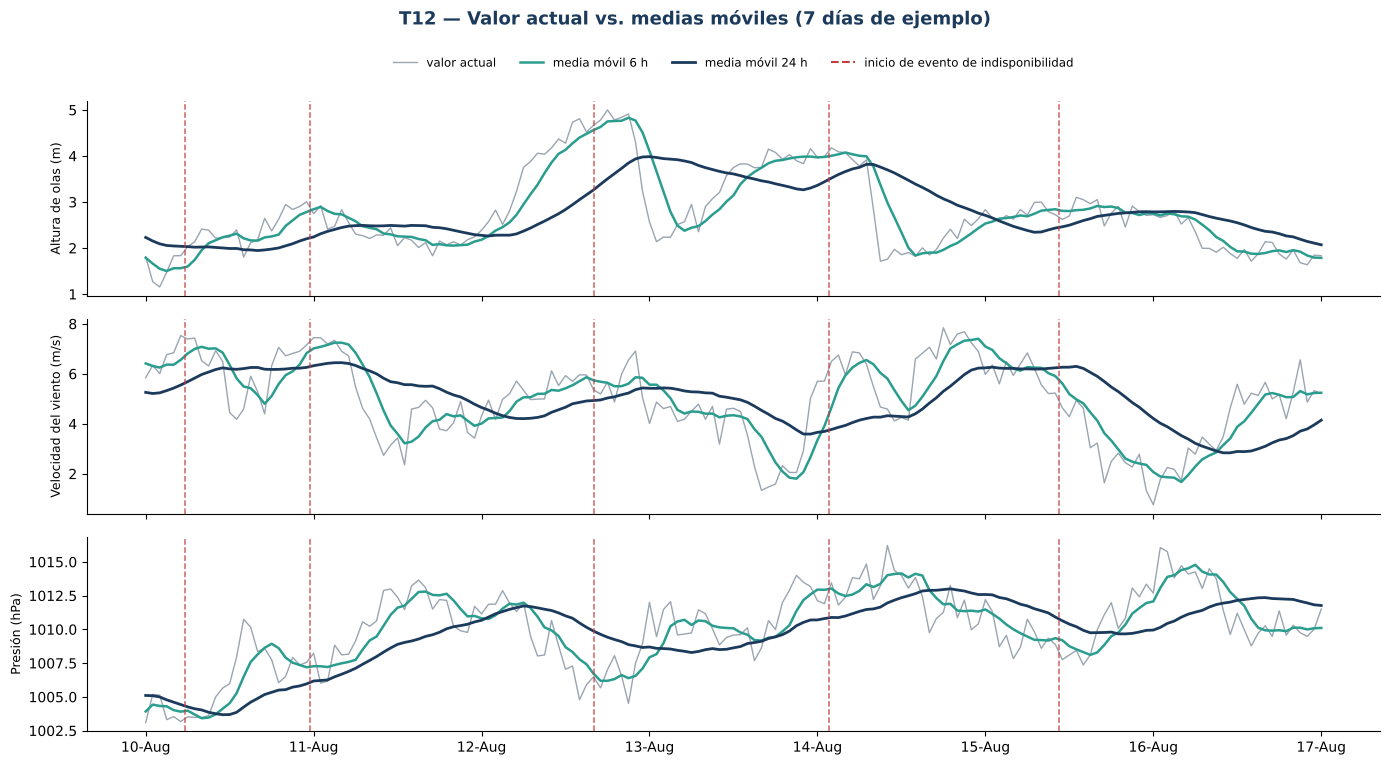

In [35]:
# ==== Vista visual - Cómo se ven las variables derivadas antes de los eventos ====
inicio_ev = (pd.Series(df_hu05.index + pd.Timedelta(hours=ORIGEN_AL_CIERRE_H) + pd.to_timedelta(df_hu05['horas_hasta_inicio_6h'], unit='h'))
             .dropna().dt.round('min').drop_duplicates())
ini_w = pd.Timestamp('2025-08-10'); fin_w = ini_w + pd.Timedelta(days=7)
fig, axes = plt.subplots(3, 1, figsize=(14, 7.6), sharex=True)
for ax, v, etiqueta in zip(axes, ['altura_olas_m', 'velocidad_viento_ms', 'presion_atmosferica_hpa'],
                           ['Altura de olas (m)', 'Velocidad del viento (m/s)', 'Presión (hPa)']):
    ax.plot(base_hu06.loc[ini_w:fin_w, v], color=COLOR_GRAY, lw=1.0, label='valor actual')
    ax.plot(X_feat.loc[ini_w:fin_w, f'{v}_media6h'], color=COLOR_TEAL, lw=1.8, label='media móvil 6 h')
    ax.plot(X_feat.loc[ini_w:fin_w, f'{v}_media24h'], color=COLOR_NAVY, lw=2.0, label='media móvil 24 h')
    for t in inicio_ev[(inicio_ev >= ini_w) & (inicio_ev <= fin_w)]:
        ax.axvline(t, color=COLOR_RED, ls='--', lw=1.1, alpha=0.8)
    ax.set_ylabel(etiqueta, fontsize=9); ax.spines[['top', 'right']].set_visible(False)
axes[0].plot([], [], color=COLOR_RED, ls='--', label='inicio de evento de indisponibilidad')
axes[0].legend(frameon=False, fontsize=8.5, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.28))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b')); axes[-1].xaxis.set_major_locator(mdates.DayLocator())
fig.suptitle('T12 — Valor actual vs. medias móviles (7 días de ejemplo)', fontsize=13, color=COLOR_NAVY, fontweight='bold', y=1.0)
fig.tight_layout(); plt.show()

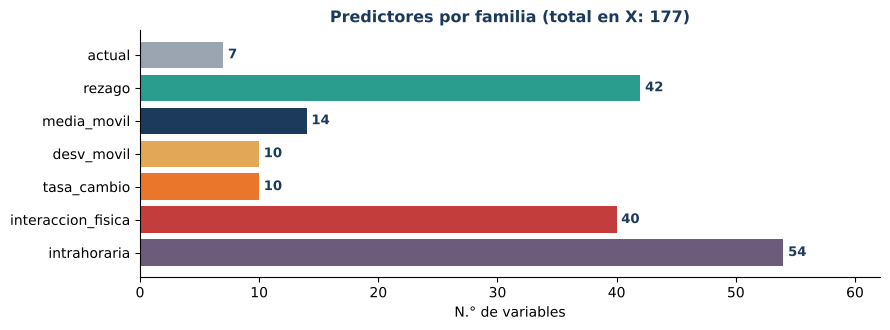

In [36]:
# ==== Resumen del catálogo de variables ====
fig, ax = plt.subplots(figsize=(9, 3.4))
orden = ['actual', 'rezago', 'media_movil', 'desv_movil', 'tasa_cambio', 'interaccion_fisica', 'intrahoraria', 'historial_operativo']
cnt = catalogo['tipo'].value_counts().reindex(orden).dropna()
colores = [COLOR_GRAY, COLOR_TEAL, COLOR_NAVY, COLOR_GOLD, COLOR_ORANGE, COLOR_RED, '#6C5B7B', '#355C7D']
ax.barh(cnt.index, cnt.values, color=[colores[orden.index(t)] for t in cnt.index])
for yi, v in enumerate(cnt.values): ax.text(v, yi, f' {int(v)}', va='center', fontsize=9.5, fontweight='bold', color=COLOR_NAVY)
ax.invert_yaxis(); ax.set_xlim(0, cnt.max() * 1.15); ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('N.° de variables'); ax.set_title(f'Predictores por familia (total en X: {len(X_COLS)})', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

## 3.2.3 T11 (parte 2) — Partición temporal y normalización sin fuga de datos

### T11.3 Partición cronológica con purga

Los datos son una serie de tiempo: **no se mezclan al azar**. Se parte en bloques consecutivos (TB2, inciso h):

| Bloque | Proporción | Uso previsto |
|---|---|---|
| Entrenamiento | 70 % más antiguo | Ajustar el escalador y los modelos |
| Validación | siguiente 15 % | Elegir hiperparámetros y comparar algoritmos |
| Prueba | último 15 % | Evaluación final, **no se toca** hasta HU09 |

**Purga igual al horizonte (`GAP_H = HORIZONTE_H` = 6 h) antes de cada corte.** La etiqueta de un origen `t` mira hasta `t + 6 h`. Si `t` está a menos de 6 h del corte, su etiqueta depende de eventos que ocurren del otro lado. Esas horas se marcan `purga` y no se usan en ningún conjunto.

Adicionalmente se definen **4 ventanas walk-forward** de entrenamiento creciente sobre el tramo entrenamiento + validación, para medir la **estabilidad** del desempeño entre periodos (criterio de selección del TB2 y de HU08). La prueba final queda fuera de los *folds*.

In [37]:
# ==== T11.3 - Partición cronológica con purga ====
idx = df_hu05.index
n = len(idx)
corte_train = idx[int(n * FRAC_TRAIN)]
corte_val   = idx[int(n * (FRAC_TRAIN + FRAC_VAL))]
purga = pd.Timedelta(hours=GAP_H)

particion = pd.Series('prueba', index=idx, name='particion')
particion[idx < corte_val] = 'validacion'
particion[idx < corte_train] = 'entrenamiento'
particion[(idx >= corte_train - purga) & (idx < corte_train)] = 'purga'
particion[(idx >= corte_val - purga) & (idx < corte_val)] = 'purga'
ORDEN_PART = ['entrenamiento', 'purga', 'validacion', 'prueba']

filas = []
tramo = (particion != particion.shift()).cumsum()            # tramos contiguos (la purga aparece dos veces: antes de validación y antes de prueba)
for g in tramo.unique():
    m = tramo == g
    p = particion[m].iloc[0]
    mc, mr = m & entrenable_clf, m & entrenable_reg
    filas.append({'particion': p, 'desde': idx[m].min(), 'hasta': idx[m].max(), 'horas': int(m.sum()),
                  'filas_clasificador': int(mc.sum()),
                  '% con evento': round(100 * df_hu05.loc[mc, TARGET_CLF].mean(), 1) if mc.any() else np.nan,
                  'filas_regresor': int(mr.sum())})
resumen_particion = pd.DataFrame(filas)
display(resumen_particion)

pos_prueba = int(df_hu05.loc[(particion == 'prueba') & entrenable_clf, TARGET_CLF].sum())
print(f'Cortes: entrenamiento < {corte_train}  ·  validación < {corte_val}  ·  prueba desde {corte_val}')
print(f'Positivos en prueba: {pos_prueba}  ({"suficientes para F1/AUC" if pos_prueba >= 100 else "POCOS: F1/AUC serán inestables"})')
print('Nota: la proporción de horas con evento cambia entre estaciones (más eventos en invierno austral); por eso se reporta por partición y se mide la estabilidad entre ventanas.')

,particion,desde,hasta,horas,filas_clasificador,% con evento,filas_regresor
0,entrenamiento,2024-01-01 00:00:00,2025-10-30 04:00:00,16037,15231,4.9,746
1,purga,2025-10-30 05:00:00,2025-10-30 10:00:00,6,6,0.0,0
2,validacion,2025-10-30 11:00:00,2026-03-22 11:00:00,3433,3331,8.3,276
3,purga,2026-03-22 12:00:00,2026-03-22 17:00:00,6,6,0.0,0
4,prueba,2026-03-22 18:00:00,2026-08-12 23:00:00,3438,3351,9.3,312


Cortes: entrenamiento < 2025-10-30 11:00:00  ·  validación < 2026-03-22 18:00:00  ·  prueba desde 2026-03-22 18:00:00
Positivos en prueba: 312  (suficientes para F1/AUC)
Nota: la proporción de horas con evento cambia entre estaciones (más eventos en invierno austral); por eso se reporta por partición y se mide la estabilidad entre ventanas.


,fold,entrenamiento,validacion,filas_clf_train,filas_clf_val,% con evento (val),filas_reg_train,filas_reg_val
0,1,01-Jan-24 -> 11-Jun-24,11-Jun-24 -> 20-Nov-24,3752,3709,1.9,66,69
1,2,01-Jan-24 -> 20-Nov-24,20-Nov-24 -> 01-May-25,7461,3697,2.1,132,78
2,3,01-Jan-24 -> 01-May-25,01-May-25 -> 11-Oct-25,11160,3610,13.4,213,485
3,4,01-Jan-24 -> 10-Oct-25,11-Oct-25 -> 22-Mar-26,14768,3794,8.5,698,324


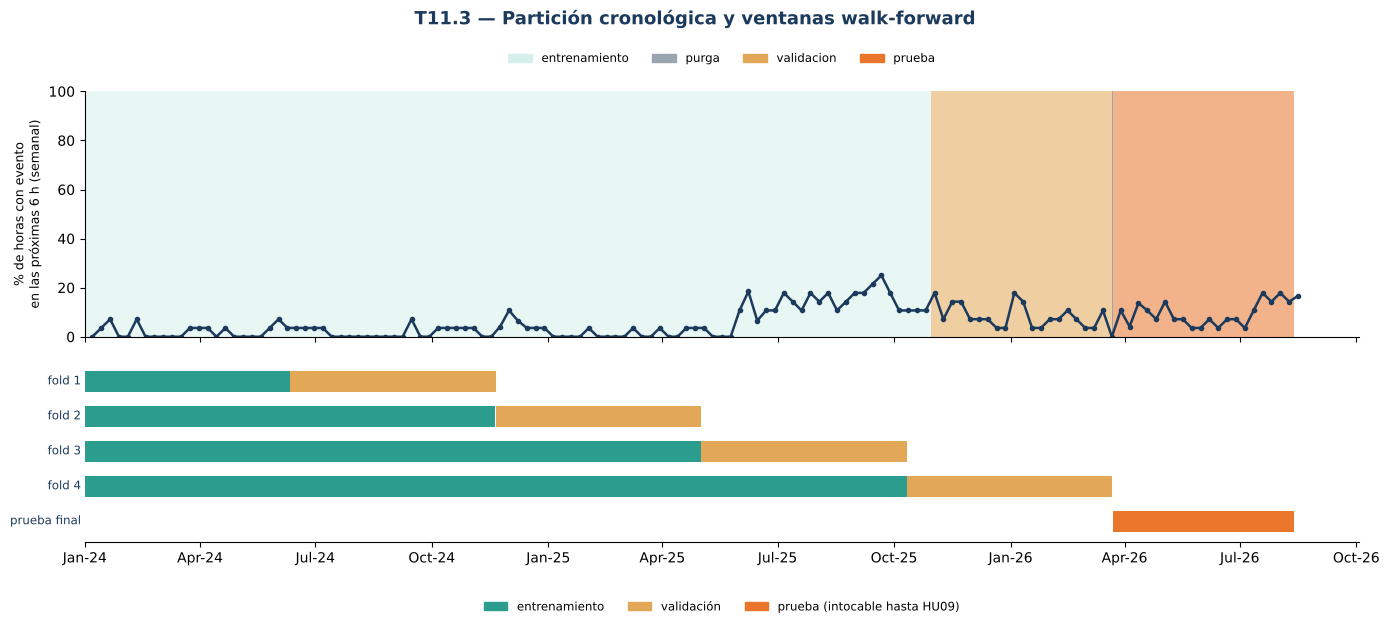

In [38]:
# ==== T11.3 - Ventanas walk-forward (entrenamiento creciente) ====
def construir_folds(indice, corte_final, n_folds, gap_h):
    """Divide el tramo previo a la prueba en n_folds+1 bloques consecutivos. El fold i entrena con los bloques 1..i
    y valida con el bloque i+1; se purgan gap_h+1 horas entre entrenamiento y validación."""
    region = indice[indice < corte_final - pd.Timedelta(hours=gap_h)]
    lim = np.linspace(0, len(region), n_folds + 2).astype(int)
    folds = []
    for i in range(n_folds):
        v_ini, v_fin = region[lim[i + 1]], region[lim[i + 2] - 1]
        folds.append({'fold': i + 1, 'train_ini': region[0], 'train_fin': v_ini - pd.Timedelta(hours=gap_h + 1),
                      'val_ini': v_ini, 'val_fin': v_fin})
    return folds

FOLDS = construir_folds(idx, corte_val, N_FOLDS_WF, GAP_H)

def mascara_fold(f, parte):
    ini, fin = (f['train_ini'], f['train_fin']) if parte == 'train' else (f['val_ini'], f['val_fin'])
    return pd.Series((idx >= ini) & (idx <= fin), index=idx)

filas = []
for f in FOLDS:
    mt, mv = mascara_fold(f, 'train'), mascara_fold(f, 'val')
    filas.append({'fold': f['fold'], 'entrenamiento': f"{f['train_ini']:%d-%b-%y} -> {f['train_fin']:%d-%b-%y}",
                  'validacion': f"{f['val_ini']:%d-%b-%y} -> {f['val_fin']:%d-%b-%y}",
                  'filas_clf_train': int((mt & entrenable_clf).sum()), 'filas_clf_val': int((mv & entrenable_clf).sum()),
                  '% con evento (val)': round(100 * df_hu05.loc[mv & entrenable_clf, TARGET_CLF].mean(), 1),
                  'filas_reg_train': int((mt & entrenable_reg).sum()), 'filas_reg_val': int((mv & entrenable_reg).sum())})
tabla_folds = pd.DataFrame(filas)
display(tabla_folds)

# ---- Vista visual: línea de tiempo de la partición y de los folds
fig, axes = plt.subplots(2, 1, figsize=(14, 6.4), sharex=True, gridspec_kw={'height_ratios': [1.35, 1]})
colores_part = {'entrenamiento': COLOR_TEAL_LT, 'purga': COLOR_GRAY, 'validacion': COLOR_GOLD, 'prueba': COLOR_ORANGE}
ax = axes[0]
for g in tramo.unique():                                   # un bloque por tramo contiguo (la purga son 2 franjas de GAP_H horas)
    m = tramo == g
    p = particion[m].iloc[0]
    ax.axvspan(idx[m].min(), idx[m].max() + pd.Timedelta(hours=1), color=colores_part[p], alpha=0.55 if p != 'purga' else 1.0, lw=0)
semanal = df_hu05[TARGET_CLF].resample('W').mean() * 100
ax.plot(semanal.index, semanal.values, color=COLOR_NAVY, lw=1.8, marker='o', ms=3)
ax.set_ylabel(f'% de horas con evento\nen las próximas {HORIZONTE_H} h (semanal)', fontsize=9); ax.set_ylim(0, 100)
ax.legend(handles=[Patch(color=colores_part[p], label=p) for p in ORDEN_PART], frameon=False, fontsize=8.5, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.2))
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
for i, f in enumerate(FOLDS):
    y0 = len(FOLDS) - i - 0.8
    ax.barh(y0 + 0.4, mdates.date2num(f['train_fin']) - mdates.date2num(f['train_ini']), left=mdates.date2num(f['train_ini']),
            height=0.6, color=COLOR_TEAL)
    ax.barh(y0 + 0.4, mdates.date2num(f['val_fin']) - mdates.date2num(f['val_ini']), left=mdates.date2num(f['val_ini']),
            height=0.6, color=COLOR_GOLD)
    ax.text(mdates.date2num(idx[0]), y0 + 0.4, f"fold {f['fold']} ", ha='right', va='center', fontsize=8.5, color=COLOR_NAVY)
ax.barh(-0.4, mdates.date2num(idx[-1]) - mdates.date2num(corte_val), left=mdates.date2num(corte_val), height=0.6, color=COLOR_ORANGE)
ax.text(mdates.date2num(idx[0]), -0.4, 'prueba final ', ha='right', va='center', fontsize=8.5, color=COLOR_NAVY)
ax.set_yticks([]); ax.set_ylim(-1, len(FOLDS) + 0.2)
ax.legend(handles=[Patch(color=COLOR_TEAL, label='entrenamiento'), Patch(color=COLOR_GOLD, label='validación'), Patch(color=COLOR_ORANGE, label='prueba (intocable hasta HU09)')],
          frameon=False, fontsize=8.5, ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.45))
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y')); ax.spines[['top', 'right', 'left']].set_visible(False)
fig.suptitle('T11.3 — Partición cronológica y ventanas walk-forward', fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()

### T11.4 Normalización ajustada solo con entrenamiento

El escalador aprende estadísticos (media y desviación para `standard`). Si aprende con todo el histórico, la media de **prueba** ya influye en cómo se transforma el **entrenamiento**: el modelo "ve" el futuro sin querer.

**Procedimiento**

1. `fit` del escalador **solo** con las filas entrenables de la partición `entrenamiento`.
2. `transform` (sin volver a ajustar) sobre entrenamiento, validación y prueba.
3. **No se normalizan** `dir_viento_sin/cos` (ya están en [−1, 1]) ni la proporción imputada (ya está en [0, 1]).
4. **Los targets no se normalizan**: los regresores predicen **horas** directamente (MAE y RMSE se interpretan en horas).
5. Dentro de cada *fold* walk-forward el escalador se **vuelve a ajustar** con el entrenamiento de ese fold (`obtener_fold`).

> Los modelos basados en árboles (RF, GBM, XGBoost, LightGBM) no necesitan normalización, pero la **regresión lineal** del *benchmark* sí. Se entregan ambas versiones (`escalado=True/False`).

In [39]:
# ==== T11.4 - Ajuste del escalador SOLO con entrenamiento ====
def crear_escalador(nombre=ESCALADOR):
    return {'standard': StandardScaler(), 'minmax': MinMaxScaler(), 'robust': RobustScaler()}[nombre]

def aplicar_escalador(esc, X):
    Xs = X.copy()
    Xs[COLS_ESCALAR] = esc.transform(X[COLS_ESCALAR])          # transform: nunca vuelve a ajustar
    return Xs

mask_fit = (particion == 'entrenamiento') & entrenable_clf
escalador = crear_escalador().fit(X_modelo.loc[mask_fit, COLS_ESCALAR])
X_esc = aplicar_escalador(escalador, X_modelo)
print(f'Escalador "{ESCALADOR}" ajustado con {int(mask_fit.sum()):,} filas de ENTRENAMIENTO '
      f'({idx[mask_fit].min():%Y-%m-%d} -> {idx[mask_fit].max():%Y-%m-%d}) y aplicado a {len(COLS_ESCALAR)} variables.')

# Evidencia de por qué importa: lo que pasaría si se ajustara con todo el histórico (SOLO comparación, no se usa)
esc_global = crear_escalador().fit(X_modelo.loc[entrenable_clf, COLS_ESCALAR])
vars_ref = VARS_CONTINUAS
i_ref = [COLS_ESCALAR.index(v) for v in vars_ref]
if ESCALADOR == 'standard':
    comp = pd.DataFrame({'media_entrenamiento': escalador.mean_[i_ref], 'media_si_se_usara_todo': esc_global.mean_[i_ref],
                         'desv_entrenamiento': escalador.scale_[i_ref]}, index=vars_ref)
    comp['sesgo_en_desviaciones'] = (comp['media_si_se_usara_todo'] - comp['media_entrenamiento']) / comp['desv_entrenamiento']
    display(comp.round(3))
    print('Lectura: "sesgo_en_desviaciones" es cuánto se movería el cero de cada variable si el escalador hubiera visto validación y prueba. '
          'Cualquier valor distinto de 0 es información del futuro filtrada al entrenamiento.')

Escalador "standard" ajustado con 15,231 filas de ENTRENAMIENTO (2024-01-02 -> 2025-10-30) y aplicado a 159 variables.


,media_entrenamiento,media_si_se_usara_todo,desv_entrenamiento,sesgo_en_desviaciones
velocidad_viento_ms,4.338,4.515,1.977,0.090
temperatura_c,17.815,17.686,2.511,-0.051
humedad_relative_pct,84.632,84.519,6.442,-0.017
presion_atmosferica_hpa,1011.094,1010.986,3.768,-0.029
altura_olas_m,1.611,1.633,0.900,0.024


Lectura: "sesgo_en_desviaciones" es cuánto se movería el cero de cada variable si el escalador hubiera visto validación y prueba. Cualquier valor distinto de 0 es información del futuro filtrada al entrenamiento.


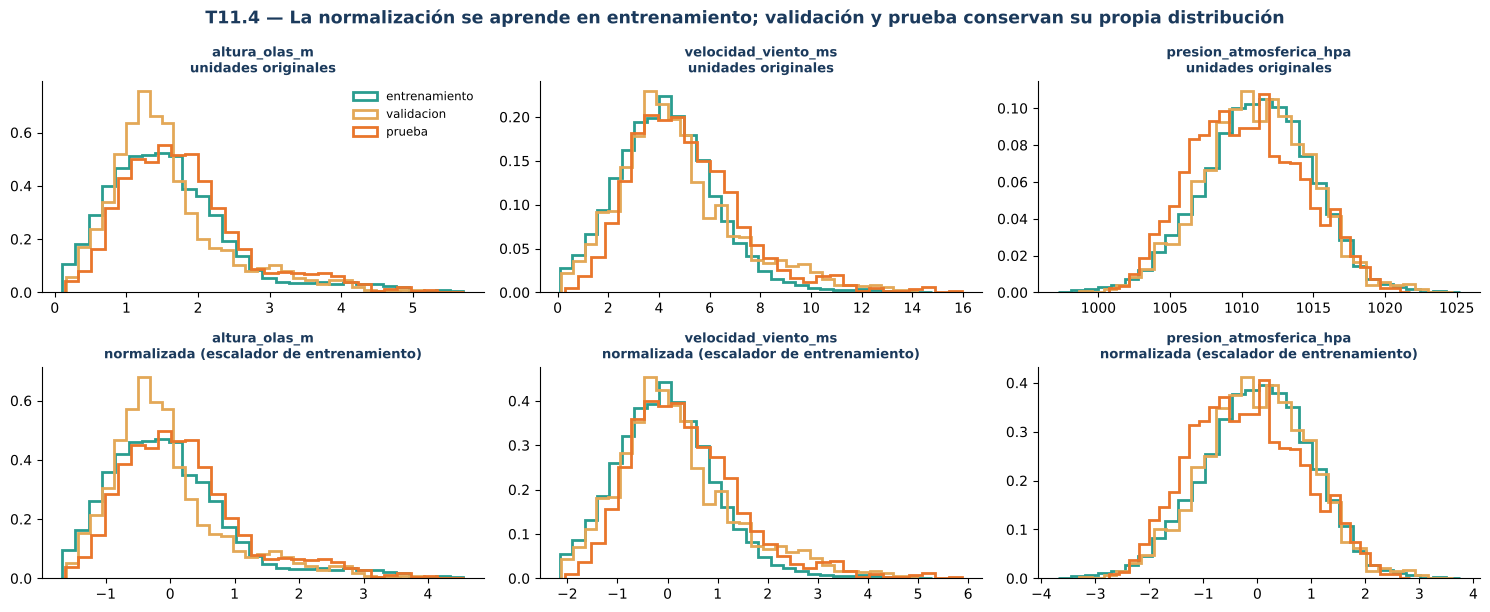

Lectura: si validación o prueba se desplazan respecto del entrenamiento, el modelo verá valores fuera de lo aprendido (deriva estacional). Eso es información real del problema, y por eso no se "corrige" ajustando con todo el histórico.


In [40]:
# ==== Vista visual - Distribuciones por partición, antes y después de normalizar ====
vars_fig = ['altura_olas_m', 'velocidad_viento_ms', 'presion_atmosferica_hpa']
colores_p = {'entrenamiento': COLOR_TEAL, 'validacion': COLOR_GOLD, 'prueba': COLOR_ORANGE}
fig, axes = plt.subplots(2, 3, figsize=(15, 6.2))
for j, v in enumerate(vars_fig):
    for fila, (Xs, titulo) in enumerate([(X_modelo, 'unidades originales'), (X_esc, 'normalizada (escalador de entrenamiento)')]):
        ax = axes[fila, j]
        for p, col in colores_p.items():
            vals = Xs.loc[(particion == p) & entrenable_clf, v]
            ax.hist(vals, bins=30, density=True, histtype='step', lw=2, color=col, label=p)
        ax.set_title(f'{v}\n{titulo}', fontsize=9.5, color=COLOR_NAVY, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        if j == 0 and fila == 0: ax.legend(frameon=False, fontsize=8.5)
fig.suptitle('T11.4 — La normalización se aprende en entrenamiento; validación y prueba conservan su propia distribución',
             fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()
print('Lectura: si validación o prueba se desplazan respecto del entrenamiento, el modelo verá valores fuera de lo aprendido '
      '(deriva estacional). Eso es información real del problema, y por eso no se "corrige" ajustando con todo el histórico.')

### Entrega para HU07 / HU08: dos tablas de entrenamiento, un solo dataset

Las funciones siguientes devuelven exactamente lo que necesitan los dos modelos del TB2. HU07 y HU08 no deben reconstruir nada: solo llamarlas.

| Función | Devuelve |
|---|---|
| `obtener_datos(conjunto, tarea, escalado)` | `X, y` de `entrenamiento` / `validacion` / `prueba`. `tarea='clasificacion'` → `y = ocurre_evento_6h`. `tarea='regresion'` → `y` con **dos columnas** (`horas_hasta_inicio_6h`, `duracion_indisponibilidad_h`) solo en orígenes con evento |
| `obtener_fold(k, tarea, escalado)` | `X_train, y_train, X_val, y_val` del *fold* `k` (1…4), con el escalador **reajustado** con el entrenamiento de ese *fold* |

In [41]:
# ==== API para HU07/HU08 ====
def _y(tarea):
    if tarea == 'clasificacion': return df_hu05[TARGET_CLF].astype(int)
    if tarea == 'regresion':     return df_hu05[TARGETS_REG]
    raise ValueError("tarea debe ser 'clasificacion' o 'regresion'")

def _elegibles(tarea):
    return entrenable_clf if tarea == 'clasificacion' else entrenable_reg

def obtener_datos(conjunto, tarea, escalado=True):
    m = (particion == conjunto) & _elegibles(tarea)
    Xs = X_esc if escalado else X_modelo
    return Xs.loc[m, X_COLS], _y(tarea).loc[m]

def obtener_fold(k, tarea, escalado=True):
    f = FOLDS[k - 1]
    mt, mv = mascara_fold(f, 'train'), mascara_fold(f, 'val')
    if escalado:
        esc = crear_escalador().fit(X_modelo.loc[mt & entrenable_clf, COLS_ESCALAR])   # ajuste SOLO con el train del fold
        Xs = aplicar_escalador(esc, X_modelo)
    else:
        Xs = X_modelo
    mt, mv = mt & _elegibles(tarea), mv & _elegibles(tarea)
    y = _y(tarea)
    return Xs.loc[mt, X_COLS], y.loc[mt], Xs.loc[mv, X_COLS], y.loc[mv]

filas = []
for p in ['entrenamiento', 'validacion', 'prueba']:
    Xc, yc = obtener_datos(p, 'clasificacion'); Xr, yr = obtener_datos(p, 'regresion')
    filas.append({'particion': p, 'X_clasificador': Xc.shape, 'positivos': int(yc.sum()), 'X_regresor': Xr.shape, 'y_regresor': yr.shape})
display(pd.DataFrame(filas))

,particion,X_clasificador,positivos,X_regresor,y_regresor
0,entrenamiento,"(15231, 177)",746,"(746, 177)","(746, 2)"
1,validacion,"(3331, 177)",276,"(276, 177)","(276, 2)"
2,prueba,"(3351, 177)",312,"(312, 177)","(312, 2)"


## Verificaciones finales de HU06

Se ejecutan **comprobaciones automáticas** de las reglas de este notebook. Las dos más importantes son pruebas de **fuga de datos**:

- **Prueba de causalidad:** se alteran los datos a partir de una hora `p` y se reconstruyen todas las variables; **ninguna fila anterior a `p` debe cambiar**. Si cambiara, esa variable estaría usando información del futuro.
- **Prueba del escalador:** el escalador debe haber visto **exactamente** las filas de entrenamiento y reproducir su media y desviación.

In [42]:
# ==== Verificaciones finales (assertions) ====
# --- Prueba de causalidad: alterar el futuro a partir de p no debe cambiar ninguna fila anterior
p = len(df_hu05) // 2
base_pert = base_hu06.copy()
base_pert.iloc[p:] = base_pert.iloc[p:] * 1.37 + 0.5
imp_pert = df_hu05['n_predictores_imputados'].copy(); imp_pert.iloc[p:] = 6
X_pert, meta_pert, _, _ = construir_features(base_pert, df_hu05['apto_modelado'], imp_pert)
causal_ok = X_feat[X_pert.columns].iloc[:p].equals(X_pert.iloc[:p]) and meta_calidad.iloc[:p].equals(meta_pert.iloc[:p])
sensible_ok = not X_feat[X_pert.columns].iloc[p:p + 30].fillna(-999).equals(X_pert.iloc[p:p + 30].fillna(-999))   # la prueba no es vacía

# --- Reconstrucción manual de rezagos y ventanas en filas entrenables al azar
rng = np.random.default_rng(SEMILLA)
muestra = rng.choice(np.where(entrenable_clf.values)[0], size=min(300, int(entrenable_clf.sum())), replace=False)
ok_manual = True
for i in muestra:
    t = idx[i]
    for v in ['altura_olas_m', 'presion_atmosferica_hpa']:
        ok_manual &= np.isclose(X_feat.at[t, f'{v}_lag6h'], base_hu06.at[idx[i - 6], v])
        ok_manual &= np.isclose(X_feat.at[t, f'{v}_media24h'], base_hu06[v].iloc[i - 23:i + 1].mean())
        ok_manual &= np.isclose(X_feat.at[t, f'{v}_std6h'], base_hu06[v].iloc[i - 5:i + 1].std())
        ok_manual &= np.isclose(X_feat.at[t, f'{v}_delta3h'], base_hu06.at[t, v] - base_hu06.at[idx[i - 3], v])

# --- Ninguna fila entrenable tiene una hora no apta en sus 25 h de historia
horas_no_aptas_hist = (~df_hu05['apto_modelado']).astype(int).rolling(MIN_RACHA_H, min_periods=1).sum()

# --- Particiones
def _rango(p):
    m = particion == p
    return idx[m].min(), idx[m].max()
(tr0, tr1), (va0, va1), (te0, te1) = _rango('entrenamiento'), _rango('validacion'), _rango('prueba')

# --- Escalador
Xtr_fit = X_modelo.loc[mask_fit, COLS_ESCALAR]
Xtr_esc = X_esc.loc[mask_fit, COLS_ESCALAR]
reprod = X_modelo.copy()[COLS_SIN_ESCALAR].equals(X_esc[COLS_SIN_ESCALAR]) if COLS_SIN_ESCALAR else True

# --- Reproducibilidad: reconstruir da exactamente lo mismo
X_rep, meta_rep, _, _ = construir_features(base_hu06, df_hu05['apto_modelado'], df_hu05['n_predictores_imputados'])

# --- Folds
folds_ok = all(f['train_fin'] + pd.Timedelta(hours=GAP_H) < f['val_ini'] for f in FOLDS) and \
           all(FOLDS[i]['val_fin'] < FOLDS[i + 1]['val_ini'] for i in range(len(FOLDS) - 1)) and FOLDS[-1]['val_fin'] < corte_val
Xf_tr, yf_tr, Xf_va, yf_va = obtener_fold(1, 'clasificacion')

# --- V8: causalidad y exactitud de las familias nuevas (T12.6-T12.8)
intra_pert = None if INTRA_HORARIA is None else INTRA_HORARIA.copy()
if intra_pert is not None:
    intra_pert.iloc[p:] = intra_pert.iloc[p:] * 1.37 + 0.5
ev_pert = None if EVENTOS_HIST is None else EVENTOS_HIST[EVENTOS_HIST['fecha_inicio'] < idx[p]]   # se "borra" el futuro de la bitácora
X_extra_pert, _ = construir_features_extra(base_pert, df_hu05['apto_modelado'], racha_apto, intra_pert, ev_pert)
causal_extra_ok = X_extra.empty or X_extra.iloc[:p].equals(X_extra_pert.iloc[:p])
fis_ok = True
if INCLUIR_INTERACCION_FISICA:
    ent = entrenable_clf
    fis_ok = bool(np.allclose(X_feat.loc[ent, 'esfuerzo_viento_nm2'], RHO_AIRE_KGM3 * CD_ARRASTRE * base_hu06.loc[ent, 'velocidad_viento_ms'] ** 2)
                  and np.allclose(X_feat.loc[ent, 'interaccion_ola_viento'], base_hu06.loc[ent, 'altura_olas_m'] * base_hu06.loc[ent, 'velocidad_viento_ms']))

chequeos = {
    'Entradas: columnas descartadas ausentes de X': not any(c.startswith(('velocidad_viento_mph', 'temperatura_interna_datalogger', 'voltaje_datalogger')) for c in X_COLS),
    'Entradas: ningún target ni columna *_durante_evento_* en X': not any(c in TARGETS or 'durante_evento' in c for c in X_COLS),
    'Entradas: velocidad_viento_ms presente y mph descartada (una sola variable de viento)': 'velocidad_viento_ms' in X_COLS and not any('mph' in c for c in X_COLS),
    'Codificación: sin² + cos² = 1 en la dirección del viento': bool(((norma - 1).abs().max()) < 1e-9),
    'Codificación: dirección en grados no está en X': VAR_DIRECCION not in X_COLS,
    'Rezagos: se generan los 6 rezagos exigidos por el TB2 para cada variable base': all(f'{v}_lag{k}h' in X_COLS for v in VARS_BASE for k in [1, 2, 3, 6, 12, 24]),
    'Ventanas: media (y desviación en continuas) de 6 y 24 h': all(f'{v}_media{w}h' in X_COLS for v in VARS_BASE for w in [6, 24]) and all(f'{v}_std{w}h' in X_COLS for v in VARS_CONTINUAS for w in [6, 24]),
    'Continuidad: filas entrenables solo con racha apta >= mínima': bool((racha_apto[entrenable_clf] >= MIN_RACHA_H).all()),
    'Continuidad: ninguna fila entrenable cruza una hora no apta': bool((horas_no_aptas_hist[entrenable_clf] == 0).all()),
    'Continuidad: filas entrenables sin NaN en X': bool(X_modelo.loc[entrenable_clf, X_COLS].notna().all().all()),
    'Causalidad: alterar el futuro NO cambia ninguna fila anterior (sin fuga)': bool(causal_ok and sensible_ok),
    'Exactitud: rezagos/medias/desviaciones/tasas coinciden con el cálculo manual (300 filas)': bool(ok_manual),
    'V8 Causalidad: familias T12.6-T12.8 no usan información posterior a t': bool(causal_extra_ok),
    'V8 Interacción física: esfuerzo = ρ·Cd·U² y H·U coinciden con la fórmula': fis_ok,
    'Reproducibilidad: reconstruir las variables da exactamente el mismo resultado': bool(X_feat[X_rep.columns].equals(X_rep) and meta_calidad.equals(meta_rep)),
    f'Targets: regresor solo con evento y targets no nulos en (0, {HORIZONTE_H}]': bool(df_hu05.loc[entrenable_reg, 'horas_hasta_inicio_6h'].between(0, HORIZONTE_H, inclusive='right').all() and df_hu05.loc[entrenable_reg, TARGETS_REG].notna().all().all()),
    'Targets: sin 0 forzado donde no hay evento (NaN) — regla Q10': bool(df_hu05.loc[df_hu05[TARGET_CLF] == 0, 'horas_hasta_inicio_6h'].isna().all()),
    'Partición: entrenamiento < validación < prueba, sin solape': bool(tr1 < va0 and va1 < te0),
    f'Partición: purga de {GAP_H} h entre bloques': bool(va0 - tr1 > purga and te0 - va1 > purga),
    'Escalador: ajustado exactamente con las filas de entrenamiento': bool(getattr(escalador, 'n_samples_seen_', len(Xtr_fit)) == len(Xtr_fit) and (particion[mask_fit] == 'entrenamiento').all()),
    'Escalador: entrenamiento normalizado con media 0 y desv. 1' if ESCALADOR == 'standard' else 'Escalador: aplicado sin NaN nuevos': bool((np.allclose(Xtr_esc.mean(), 0, atol=1e-8) and np.allclose(Xtr_esc.std(ddof=0), 1, atol=1e-8)) if ESCALADOR == 'standard' else Xtr_esc.notna().all().all()),
    'Escalador: no se normalizan seno/coseno ni la proporción imputada': bool(reprod),
    'Escalador: el del fold 1 se reajusta con su propio entrenamiento': bool(ESCALADOR != 'standard' or Xf_tr[COLS_ESCALAR].mean().abs().max() < 1e-8),
    'Folds: entrenamiento previo a validación con purga y validaciones consecutivas': bool(folds_ok),
    'API: obtener_datos devuelve y de dos columnas para el regresor': bool(obtener_datos('entrenamiento', 'regresion')[1].shape[1] == 2),
}
tabla_chequeos6 = pd.DataFrame({'Verificación': list(chequeos), 'Resultado': ['OK' if bool(v) else 'FALLA' for v in chequeos.values()]})
display(tabla_chequeos6)
assert (tabla_chequeos6['Resultado'] == 'OK').all(), 'Hay verificaciones que fallan: revisar la tabla anterior.'
print(f'\n{len(chequeos)} verificaciones OK.')

,Verificación,Resultado
0,Entradas: columnas descartadas ausentes de X,OK
1,Entradas: ningún target ni columna *_durante_evento_* en X,OK
2,Entradas: velocidad_viento_ms presente y mph descartada (una sola variable de viento),OK
3,Codificación: sin² + cos² = 1 en la dirección del viento,OK
4,Codificación: dirección en grados no está en X,OK
5,Rezagos: se generan los 6 rezagos exigidos por el TB2 para cada variable base,OK
6,Ventanas: media (y desviación en continuas) de 6 y 24 h,OK
7,Continuidad: filas entrenables solo con racha apta >= mínima,OK
8,Continuidad: ninguna fila entrenable cruza una hora no apta,OK
9,Continuidad: filas entrenables sin NaN en X,OK



25 verificaciones OK.


### Diagnóstico de señal: ¿las variables cambian *antes* del inicio de un evento?

Antes de entrenar conviene mirar si existe una pista temporal que los rezagos puedan capturar. Se alinean los **inicios de evento** (reconstruidos desde `horas_hasta_inicio_6h`) y se promedia la **anomalía** de cada variable (valor menos su media semanal, en desviaciones estándar) en las horas previas y posteriores. Si las condiciones empeoraran antes del evento, la curva subiría a la izquierda del cero.

> Es un diagnóstico **descriptivo** (usa una media centrada, que sería ilegal como predictor) y solo incluye eventos del tramo entrenamiento + validación: **no toca la prueba final**.

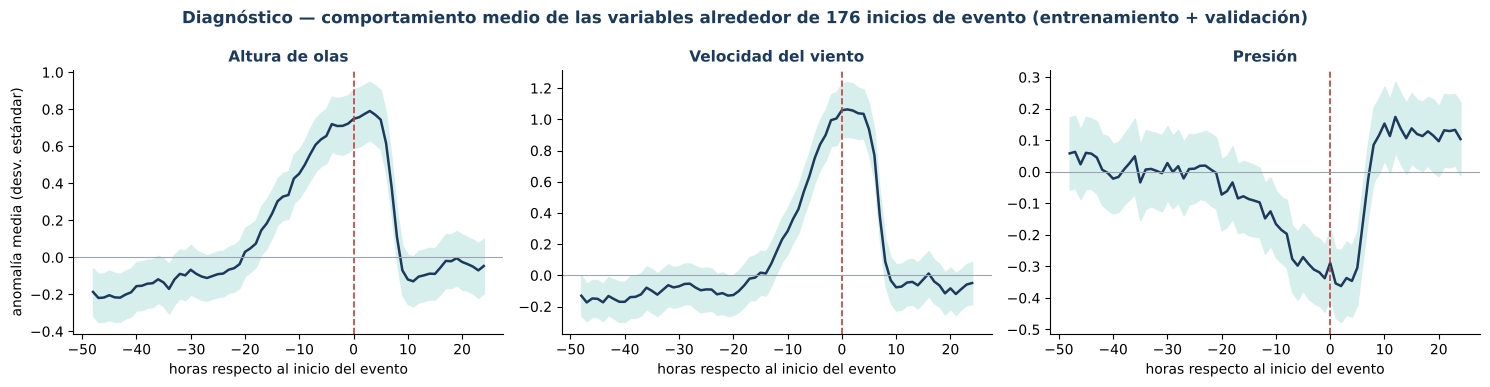

,anomalia_media_24h_previas,anomalia_en_hora_0
altura_olas_m,0.305,0.748
velocidad_viento_ms,0.202,1.059
presion_atmosferica_hpa,-0.129,-0.289


Lectura: banda = intervalo del 95 % de la media. Si las 24 h previas quedan dentro de la banda alrededor de 0, el estado de las variables en horas anteriores no anticipa el evento en promedio; si solo sobresale la hora 0, el evento coincide con un pico puntual.


In [43]:
# ==== Diagnóstico descriptivo: promedio compuesto alrededor del inicio de los eventos ====
ev_ini = (pd.Series(idx + pd.Timedelta(hours=ORIGEN_AL_CIERRE_H) + pd.to_timedelta(df_hu05['horas_hasta_inicio_6h'], unit='h'))
          .dropna().dt.round('h').drop_duplicates())
ev_ini = ev_ini[(ev_ini < corte_val - purga) & (ev_ini > idx[0] + pd.Timedelta(hours=48))]
offsets = np.arange(-48, 25)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharex=True)
resumen_diag = {}
for ax, v, etq in zip(axes, ['altura_olas_m', 'velocidad_viento_ms', 'presion_atmosferica_hpa'],
                      ['Altura de olas', 'Velocidad del viento', 'Presión']):
    s_v = df_hu05[v]
    anom = (s_v - s_v.rolling(24 * 7, center=True, min_periods=72).mean()) / s_v.std()
    medias, ee = [], []
    for h in offsets:
        vals = anom.reindex(ev_ini + pd.Timedelta(hours=int(h))).dropna()
        medias.append(vals.mean()); ee.append(vals.std() / np.sqrt(max(len(vals), 1)))
    medias, ee = np.array(medias), np.array(ee)
    ax.fill_between(offsets, medias - 1.96 * ee, medias + 1.96 * ee, color=COLOR_TEAL_LT)
    ax.plot(offsets, medias, color=COLOR_NAVY, lw=1.8)
    ax.axvline(0, color=COLOR_RED, ls='--', lw=1.2); ax.axhline(0, color=COLOR_GRAY, lw=0.8)
    ax.set_title(etq, fontsize=11, color=COLOR_NAVY, fontweight='bold'); ax.set_xlabel('horas respecto al inicio del evento')
    ax.spines[['top', 'right']].set_visible(False)
    previas = medias[(offsets >= -24) & (offsets <= -3)]
    resumen_diag[v] = {'anomalia_media_24h_previas': round(float(previas.mean()), 3), 'anomalia_en_hora_0': round(float(medias[offsets == 0][0]), 3)}
axes[0].set_ylabel('anomalía media (desv. estándar)')
fig.suptitle(f'Diagnóstico — comportamiento medio de las variables alrededor de {len(ev_ini)} inicios de evento (entrenamiento + validación)',
             fontsize=12, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout(); plt.show()
display(pd.DataFrame(resumen_diag).T)
print('Lectura: banda = intervalo del 95 % de la media. Si las 24 h previas quedan dentro de la banda alrededor de 0, el estado '
      'de las variables en horas anteriores no anticipa el evento en promedio; si solo sobresale la hora 0, el evento coincide con un pico puntual.')

### Diagnóstico de anticipación (V8): ¿cuántas horas antes hay señal real?

Antes de gastar horas de Optuna conviene medir **hasta qué horizonte** las variables distinguen las horas previas a un evento. Se entrena un clasificador rápido (`HistGradientBoosting`, sin ajuste fino) en las mismas 4 ventanas walk-forward para varios horizontes y **dos definiciones de origen**:

- `origen = t` (V7): la fila contiene lecturas de los 55 minutos **posteriores** al origen → incluye fuga.
- `origen = t + 1 h` (V8): la predicción se emite al cierre de la hora → **sin fuga**.

Lectura: si la curva sin fuga queda pegada a 0.50, las variables disponibles **no anticipan** el evento a ese horizonte; ningún algoritmo ni búsqueda de hiperparámetros lo arregla. La diferencia entre ambas curvas es la parte de la métrica que se debía a la fuga. No toca la prueba final.


,definición,horizonte_h,AUC_media,AUC_desv,PR-AUC,prevalencia,PR-AUC / prevalencia
0,"origen = t (V7, con fuga)",1,0.834,0.055,0.056,0.011,5.191
1,"origen = t (V7, con fuga)",3,0.827,0.079,0.145,0.032,4.486
2,"origen = t (V7, con fuga)",6,0.834,0.047,0.267,0.065,4.123
3,"origen = t (V7, con fuga)",12,0.782,0.055,0.375,0.128,2.925
4,"origen = t (V7, con fuga)",24,0.664,0.096,0.401,0.229,1.753
5,"origen = t + 1 h (V8, sin fuga)",1,0.833,0.083,0.053,0.011,4.933
6,"origen = t + 1 h (V8, sin fuga)",3,0.824,0.090,0.158,0.032,4.893
7,"origen = t + 1 h (V8, sin fuga)",6,0.829,0.037,0.248,0.065,3.827
8,"origen = t + 1 h (V8, sin fuga)",12,0.764,0.053,0.357,0.128,2.777
9,"origen = t + 1 h (V8, sin fuga)",24,0.637,0.095,0.373,0.229,1.629


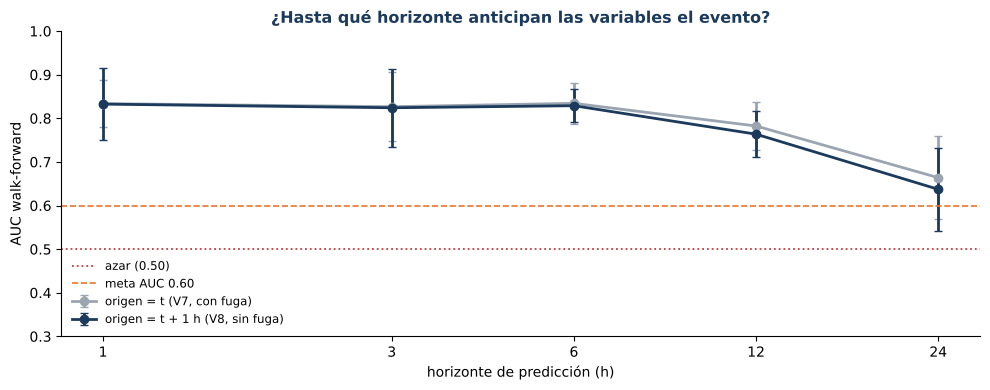

Lectura: PR-AUC / prevalencia ≈ 1 significa que el modelo no ordena mejor que el azar. Reducir el horizonte solo ayuda si la curva sin fuga sube al acortarlo.


In [44]:
# ==== Diagnóstico de anticipación: AUC walk-forward por horizonte, con y sin fuga ====
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
HORIZONTES_DIAG = sorted(set([1, 3, 6, 12, 24, HORIZONTE_H]))
_ev_diag = df_eventos_limpio if 'df_eventos_limpio' in globals() else (
    pd.read_csv('eventos_limpios_HU05.csv', parse_dates=['fecha_inicio', 'fecha_fin']) if Path('eventos_limpios_HU05.csv').exists() else None)

def _y_horizonte(H, desfase):
    e = _ev_diag.sort_values('fecha_inicio'); ini = e['fecha_inicio'].values.astype('datetime64[ns]')
    t = (idx + pd.Timedelta(hours=desfase)).values.astype('datetime64[ns]')
    pos = np.searchsorted(ini, t, side='right'); hay = pos < len(ini)
    return pd.Series(hay & ((ini[np.where(hay, pos, 0)] - t) / np.timedelta64(1, 'h') <= H), index=idx).astype(int)

if _ev_diag is None:
    print('Se omite: falta eventos_limpios_HU05.csv')
else:
    filas_diag = []
    for desfase, etq in [(0, 'origen = t (V7, con fuga)'), (ORIGEN_AL_CIERRE_H, f'origen = t + {ORIGEN_AL_CIERRE_H} h (V8, sin fuga)')]:
        if etq.startswith('origen = t (') and ORIGEN_AL_CIERRE_H == 0: continue
        for H in HORIZONTES_DIAG:
            y_h = _y_horizonte(H, desfase); aucs, aps, prev = [], [], []
            for f in FOLDS:
                mt = mascara_fold(f, 'train') & entrenable_clf; mv = mascara_fold(f, 'val') & entrenable_clf
                m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, min_samples_leaf=40,
                                                   l2_regularization=1.0, random_state=SEMILLA).fit(X_modelo.loc[mt, X_COLS], y_h[mt])
                pr = m.predict_proba(X_modelo.loc[mv, X_COLS])[:, 1]
                aucs.append(roc_auc_score(y_h[mv], pr)); aps.append(average_precision_score(y_h[mv], pr)); prev.append(y_h[mv].mean())
            filas_diag.append({'definición': etq, 'horizonte_h': H, 'AUC_media': np.mean(aucs), 'AUC_desv': np.std(aucs, ddof=1),
                               'PR-AUC': np.mean(aps), 'prevalencia': np.mean(prev), 'PR-AUC / prevalencia': np.mean(aps) / np.mean(prev)})
    diag_anticipacion = pd.DataFrame(filas_diag)
    display(diag_anticipacion.round(3))
    fig, ax = plt.subplots(figsize=(10, 4))
    for (etq, g), col in zip(diag_anticipacion.groupby('definición', sort=False), [COLOR_GRAY, COLOR_NAVY]):
        ax.errorbar(g['horizonte_h'], g['AUC_media'], yerr=g['AUC_desv'], marker='o', capsize=3, color=col, lw=2, label=etq)
    ax.axhline(0.5, color=COLOR_RED, ls=':', lw=1.3, label='azar (0.50)'); ax.axhline(0.6, color=COLOR_ORANGE, ls='--', lw=1.2, label='meta AUC 0.60')
    ax.set_xscale('log', base=2); ax.set_xticks(HORIZONTES_DIAG); ax.set_xticklabels(HORIZONTES_DIAG)
    ax.set_xlabel('horizonte de predicción (h)'); ax.set_ylabel('AUC walk-forward'); ax.set_ylim(0.3, 1.0)
    ax.legend(frameon=False, fontsize=8.5); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title('¿Hasta qué horizonte anticipan las variables el evento?', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')
    fig.tight_layout(); plt.show()
    print('Lectura: PR-AUC / prevalencia ≈ 1 significa que el modelo no ordena mejor que el azar. '
          'Reducir el horizonte solo ayuda si la curva sin fuga sube al acortarlo.')


### Prueba de humo: ¿el dataset es entrenable y trae señal?

Criterio de HU06 (TB2): *dataset reproducible y apto para entrenamiento*. Se entrena un modelo mínimo por tarea y se mide en validación y en las 4 ventanas walk-forward.

> **Esto NO es el *benchmark* ni el entrenamiento de HU07/HU08.** No hay ajuste de hiperparámetros, ni los cuatro algoritmos, ni prueba final (la partición `prueba` no se toca). Sirve para dos cosas: (1) confirmar que las matrices tienen la forma correcta y ningún NaN rompe el entrenamiento; (2) **dar una primera señal honesta** de si las variables derivadas anticipan el evento mejor que una referencia trivial. Las cifras no se reportan como resultados del proyecto.

In [45]:
# ==== Prueba de humo (NO es el benchmark de HU07/HU08) ====
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, f1_score, mean_absolute_error

def _clf_minimo(Xtr, ytr, Xva, yva):
    m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, random_state=SEMILLA).fit(Xtr, ytr)
    p = m.predict_proba(Xva)[:, 1]
    return roc_auc_score(yva, p), f1_score(yva, p >= 0.5), f1_score(yva, np.ones(len(yva))), 100 * yva.mean()

filas_clf = []
Xc_tr, yc_tr = obtener_datos('entrenamiento', 'clasificacion', escalado=False)
Xc_va, yc_va = obtener_datos('validacion',    'clasificacion', escalado=False)
filas_clf.append(('Validación (partición)', *_clf_minimo(Xc_tr, yc_tr, Xc_va, yc_va)))
for k in range(1, N_FOLDS_WF + 1):
    a, b, c, d = obtener_fold(k, 'clasificacion', escalado=False)
    filas_clf.append((f'Walk-forward fold {k}', *_clf_minimo(a, b, c, d)))
tabla_humo_clf = pd.DataFrame(filas_clf, columns=['evaluación', 'AUC', 'F1 (umbral 0.5)', 'F1 trivial (siempre "habrá evento")', '% con evento (val.)']).round(3)
display(tabla_humo_clf)

Xr_tr, yr_tr = obtener_datos('entrenamiento', 'regresion', escalado=False)
Xr_va, yr_va = obtener_datos('validacion',    'regresion', escalado=False)
filas_reg = []
for t in TARGETS_REG:
    reg = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, random_state=SEMILLA).fit(Xr_tr, yr_tr[t])
    filas_reg.append({'regresor (salida)': t, 'MAE modelo mínimo (h)': round(mean_absolute_error(yr_va[t], reg.predict(Xr_va)), 3),
                      'MAE trivial: media de entrenamiento (h)': round(mean_absolute_error(yr_va[t], np.full(len(yr_va), yr_tr[t].mean())), 3)})
display(pd.DataFrame(filas_reg))
print(f'Matrices: clasificador {Xc_tr.shape} / {Xc_va.shape}  ·  regresor {Xr_tr.shape} / {Xr_va.shape}  ·  NaN en X: {int(Xc_tr.isna().sum().sum() + Xr_tr.isna().sum().sum())}')

auc_medio = tabla_humo_clf.loc[tabla_humo_clf['evaluación'].str.startswith('Walk'), 'AUC'].mean()
if auc_medio < 0.55:
    print(f'\nAVISO: AUC medio en walk-forward = {auc_medio:.2f} (azar = 0.50). Con las variables actuales, el modelo mínimo NO anticipa el evento '
          'de forma estable entre periodos. No es un error de construcción (las verificaciones de causalidad y de cálculo manual pasan): '
          'es un hallazgo sobre los datos/etiqueta que conviene revisar con la asesora antes de HU07 (ver decisiones abiertas).')
else:
    print(f'\nAUC medio en walk-forward = {auc_medio:.2f}: hay señal por encima del azar; HU07/HU08 la cuantificarán con el benchmark completo.')

,evaluación,AUC,F1 (umbral 0.5),"F1 trivial (siempre ""habrá evento"")",% con evento (val.)
0,Validación (partición),0.864,0.170,0.153,8.286
1,Walk-forward fold 1,0.796,0.049,0.037,1.860
2,Walk-forward fold 2,0.818,0.067,0.041,2.110
3,Walk-forward fold 3,0.770,0.075,0.237,13.435
4,Walk-forward fold 4,0.868,0.193,0.157,8.540


,regresor (salida),MAE modelo mínimo (h),MAE trivial: media de entrenamiento (h)
0,horas_hasta_inicio_6h,1.489,1.500
1,duracion_indisponibilidad_h,0.895,0.873


Matrices: clasificador (15231, 177) / (3331, 177)  ·  regresor (746, 177) / (276, 177)  ·  NaN en X: 0

AUC medio en walk-forward = 0.81: hay señal por encima del azar; HU07/HU08 la cuantificarán con el benchmark completo.


### Exportación de entregables de HU06

| Archivo | Contenido |
|---|---|
| `dataset_features_HU06.csv` | Predictores **normalizados** + columnas de control (`particion`, `entrenable_clasificador`, `entrenable_regresores`, proporción imputada) + los 3 *targets* |
| `dataset_features_HU06_sin_escalar.csv` | Lo mismo en unidades originales (modelos de árboles, interpretación con SHAP) |
| `escalador_HU06.joblib` | Escalador ajustado solo con entrenamiento + lista de columnas (para reutilizarlo en HU13 al hacer predicciones nuevas) |
| `catalogo_variables_HU06.csv` | Una fila por variable: variable base, familia, parámetro en horas, si se normaliza |
| `folds_walk_forward_HU06.csv` | Fechas de cada ventana walk-forward |
| `config_features_HU06.json` | Parámetros, cortes de partición y versiones de librerías para reproducir el proceso |

In [46]:
# ==== Exportación de entregables de HU06 ====
meta_cols = pd.DataFrame({
    'particion': particion, 'apto_modelado': df_hu05['apto_modelado'], 'racha_apto_h': racha_apto,
    'entrenable_clasificador': entrenable_clf.astype(int), 'entrenable_regresores': entrenable_reg.astype(int),
})
meta_cols = meta_cols.join(meta_calidad[[c for c in meta_calidad.columns if c not in X_COLS]])   # proporción imputada (si no es predictor)
dataset_hu06_esc = pd.concat([meta_cols, X_esc[X_COLS], df_hu05[TARGETS]], axis=1)
dataset_hu06_raw = pd.concat([meta_cols, X_modelo[X_COLS], df_hu05[TARGETS]], axis=1)

dataset_hu06_esc.to_csv('dataset_features_HU06.csv', float_format='%.8g')
dataset_hu06_raw.to_csv('dataset_features_HU06_sin_escalar.csv', float_format='%.8g')
joblib.dump({'escalador': escalador, 'tipo': ESCALADOR, 'columnas_escaladas': COLS_ESCALAR, 'columnas_modelo': X_COLS}, 'escalador_HU06.joblib')
catalogo.assign(en_X=catalogo['variable'].isin(X_COLS)).to_csv('catalogo_variables_HU06.csv', index=False)
pd.DataFrame(FOLDS).to_csv('folds_walk_forward_HU06.csv', index=False)

config_hu06 = {
    'insumo': RUTA_DATASET, 'horizonte_h': HORIZONTE_H, 'origen_al_cierre_h': ORIGEN_AL_CIERRE_H, 'semilla': SEMILLA,
    'familias_v8': {'interaccion_fisica': INCLUIR_INTERACCION_FISICA, 'intrahorarias': INTRA_HORARIA is not None,
                    'historial_operativo': EVENTOS_HIST is not None, 'rho_aire': RHO_AIRE_KGM3, 'cd_arrastre': CD_ARRASTRE,
                    'tasas_fis_h': TASAS_FIS_H, 'ventanas_max_intra_h': VENTANAS_MAX_INTRA_H},
    'rezagos_h': LAGS_H, 'ventanas_h': VENTANAS_H, 'tasas_cambio_h': TASAS_CAMBIO_H,
    'horas_aptas_consecutivas_minimas': MIN_RACHA_H, 'max_frac_imputada_ventana': MAX_FRAC_IMPUTADA_VENTANA,
    'frac_imputada_como_predictor': INCLUIR_FRAC_IMPUTADA_EN_X,
    'columnas_descartadas': COLUMNAS_DESCARTADAS, 'escalador': ESCALADOR,
    'particion': {'frac_train': FRAC_TRAIN, 'frac_val': FRAC_VAL, 'purga_h': GAP_H,
                  'corte_entrenamiento': str(corte_train), 'corte_validacion': str(corte_val)},
    'n_folds_walk_forward': N_FOLDS_WF, 'n_predictores': len(X_COLS), 'predictores': X_COLS,
    'targets': {'clasificador': TARGET_CLF, 'regresor_doble_salida': TARGETS_REG},
    'versiones': {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__},
}
Path('config_features_HU06.json').write_text(json.dumps(config_hu06, indent=2, ensure_ascii=False), encoding='utf-8')

archivos_hu06 = ['dataset_features_HU06.csv', 'dataset_features_HU06_sin_escalar.csv', 'escalador_HU06.joblib',
                 'catalogo_variables_HU06.csv', 'folds_walk_forward_HU06.csv', 'config_features_HU06.json']
print('Archivos generados:')
for f in archivos_hu06:
    print(f'  - {f}  ({Path(f).stat().st_size/1024:,.0f} KB)')

# Comprobación de ida y vuelta: el CSV exportado contiene exactamente lo que usa el modelo
chk = pd.read_csv('dataset_features_HU06.csv', index_col='fecha_hora', parse_dates=['fecha_hora'])
assert chk.shape == dataset_hu06_esc.shape and np.allclose(chk[X_COLS].fillna(0), dataset_hu06_esc[X_COLS].fillna(0), atol=1e-6)
print(f'Ida y vuelta del CSV: OK  ({chk.shape[0]:,} filas x {chk.shape[1]} columnas)')

try:
    from google.colab import files
    # for f in archivos_hu06: files.download(f)       # descomentar para descargar
except ImportError:
    pass

Archivos generados:
  - dataset_features_HU06.csv  (45,243 KB)
  - dataset_features_HU06_sin_escalar.csv  (40,225 KB)
  - escalador_HU06.joblib  (14 KB)
  - catalogo_variables_HU06.csv  (12 KB)
  - folds_walk_forward_HU06.csv  (0 KB)
  - config_features_HU06.json  (7 KB)


Ida y vuelta del CSV: OK  (22,920 filas x 187 columnas)


### Cómo cargar el dataset en HU07 (ejemplo mínimo)

```python
# Clasificador de ocurrencia (F1-score y AUC)
X_tr, y_tr = obtener_datos('entrenamiento', 'clasificacion')
X_va, y_va = obtener_datos('validacion',    'clasificacion')

# Regresor de doble salida (MAE, RMSE, MAPE, R²): y tiene 2 columnas
Xr_tr, yr_tr = obtener_datos('entrenamiento', 'regresion')     # [horas_hasta_inicio_6h, duracion_indisponibilidad_h]

# Estabilidad entre periodos (walk-forward): el escalador se reajusta dentro de cada fold
for k in range(1, N_FOLDS_WF + 1):
    X_tr, y_tr, X_va, y_va = obtener_fold(k, 'clasificacion')
```

Si HU07 se ejecuta en otra sesión, basta con leer `dataset_features_HU06.csv` y filtrar por `particion` y `entrenable_clasificador` / `entrenable_regresores`.

In [47]:
# ==== HU06 - Definition of Done (calculada) ====
def estado(c): return 'CUMPLE' if c else 'NO CUMPLE'
dod_hu06 = pd.DataFrame([
    ['T11', 'Columna duplicada (velocidad en mph) y variables de diagnóstico del datalogger excluidas de los predictores', estado(chequeos['Entradas: columnas descartadas ausentes de X'])],
    ['T11', 'Dirección del viento codificada como seno y coseno', estado(chequeos['Codificación: sin² + cos² = 1 en la dirección del viento'])],
    ['T11', 'Partición temporal entrenamiento / validación / prueba con purga, documentada', estado(chequeos[f'Partición: purga de {GAP_H} h entre bloques'])],
    ['T11', 'Normalización ajustada solo con entrenamiento y aplicada a validación y prueba', estado(chequeos['Escalador: ajustado exactamente con las filas de entrenamiento'])],
    ['T12', 'Rezagos t-1, 2, 3, 6, 12 y 24 generados', estado(chequeos['Rezagos: se generan los 6 rezagos exigidos por el TB2 para cada variable base'])],
    ['T12', 'Ventanas móviles de 6 y 24 h (media y desviación) generadas', estado(chequeos['Ventanas: media (y desviación en continuas) de 6 y 24 h'])],
    ['T12', 'Ninguna variable derivada cruza un bloque no apto (apto_modelado)', estado(chequeos['Continuidad: ninguna fila entrenable cruza una hora no apta'])],
    ['T12', 'Proporción imputada por ventana calculada y umbral aplicado', estado(frac_max_col in meta_calidad.columns)],
    ['T12', 'Sin fuga de datos: variables solo con información de t hacia atrás', estado(chequeos['Causalidad: alterar el futuro NO cambia ninguna fila anterior (sin fuga)'])],
    ['-', 'Dataset reproducible (configuración, catálogo y escalador versionables)', estado(chequeos['Reproducibilidad: reconstruir las variables da exactamente el mismo resultado'] and all(Path(f).exists() for f in archivos_hu06))],
    ['-', 'Dataset apto para entrenamiento: dos tablas (clasificador y regresor de doble salida) sin NaN', estado(chequeos['Continuidad: filas entrenables sin NaN en X'])],
], columns=['Tarea', 'Criterio de aceptación', 'Estado'])
display(dod_hu06)

,Tarea,Criterio de aceptación,Estado
0,T11,Columna duplicada (velocidad en mph) y variables de diagnóstico del datalogger excluidas de los predictores,CUMPLE
1,T11,Dirección del viento codificada como seno y coseno,CUMPLE
2,T11,"Partición temporal entrenamiento / validación / prueba con purga, documentada",CUMPLE
3,T11,Normalización ajustada solo con entrenamiento y aplicada a validación y prueba,CUMPLE
4,T12,"Rezagos t-1, 2, 3, 6, 12 y 24 generados",CUMPLE
5,T12,Ventanas móviles de 6 y 24 h (media y desviación) generadas,CUMPLE
6,T12,Ninguna variable derivada cruza un bloque no apto (apto_modelado),CUMPLE
7,T12,Proporción imputada por ventana calculada y umbral aplicado,CUMPLE
8,T12,Sin fuga de datos: variables solo con información de t hacia atrás,CUMPLE
9,-,"Dataset reproducible (configuración, catálogo y escalador versionables)",CUMPLE


### Decisiones de HU06 — confirmadas por el equipo

Estas decisiones, antes abiertas, quedaron **confirmadas** y son las que usa HU07 (y las que usará HU11).

| # | Decisión | Estado |
|---|---|---|
| 1 | **Partición 70 / 15 / 15 con purga igual al horizonte (6 h)** y **4 ventanas walk-forward** | **Se mantiene** |
| 2 | **Umbral de proporción imputada** (`MAX_FRAC_IMPUTADA_VENTANA = 50 %`) | **Se mantiene** |
| 3 | **Rigor de la continuidad**: se exige que **todas** las horas entre `t-24` y `t` sean aptas | **Se mantiene (lectura estricta)** |
| 4 | **Escalador `standard` (z-score)** | **Confirmado.** El benchmark combina modelos de árboles (no lo necesitan) y modelos lineales (sí lo necesitan); por eso se conserva, y es parametrizable (`ESCALADOR`) |
| 5 | **Proporción imputada fuera de `X`** (`INCLUIR_FRAC_IMPUTADA_EN_X = False`) | **Se mantiene**: es control de calidad, no predictor |
| 6 | **Prueba final intocable**: la partición `prueba` solo se usa en HU09 | **Se mantiene** |
| 7 | **Metas de señal predictiva**: R² ≥ 0.75 · F1 ≥ 0.65 · **AUC ≥ 0.60** | **Ajustada:** el AUC pasa de 0.75 a **0.60** por ser más realista para estas variables |

### Tarea añadida al backlog (HU11 — Predicción de horas de indisponibilidad)

Procesamiento automático de **lecturas nuevas** para generar **exactamente las mismas columnas** que recibió el modelo en el entrenamiento, reutilizando la ingeniería de características de HU06 (T11/T12). **No se desarrolla en este sprint**; el contrato de columnas y los parámetros necesarios se exportan en HU07 (`columnas_modelo_HU07.json`). El detalle está al final de la sección 3.3.

### Puente hacia HU07 (Entrenamiento del modelo)

HU07 parte de `dataset_features_HU06.csv`. El **clasificador** (XGBoost y Random Forest Classifier, con F1-score y AUC) usa todas las filas con `entrenable_clasificador = 1`. El **regresor de doble salida** (RF, GBM, XGBoost, LightGBM, más referencias; MAE, RMSE, MAPE y R²) usa solo `entrenable_regresores = 1`. La sección 3.3 implementa este puente.

## 3.3 HU07 — Entrenamiento del modelo

**Historia de usuario (TB2):** *Como Científico de datos, quiero entrenar modelos supervisados de regresión y clasificación, para estimar las horas de indisponibilidad operativa.*

| N.° | Tarea | Contenido |
|---|---|---|
| 3.3.1 | **T13** | Entrenar modelos supervisados: **regresión** (Random Forest, GBM, XGBoost, LightGBM) para `horas_hasta_inicio_6h` y `duracion_indisponibilidad_h`, y **clasificador auxiliar** de ocurrencia (XGBoost y Random Forest del TB2, más LightGBM como tercer candidato) con **optimización bayesiana de hiperparámetros**, **pesos de clase** y **umbral de decisión optimizado** |

**Qué hace y qué no hace esta sección**

- Usa **solo** `dataset_features_HU06.csv` (salida de HU06). No reconstruye nada: la partición, las ventanas walk-forward y las filas entrenables se leen del propio archivo.
- Los hiperparámetros se optimizan **únicamente con las 4 ventanas walk-forward** (Optuna, muestreador TPE con semilla fija). El objetivo es el **MAE en horas** (regresión) y el **AUC** (clasificador), promediados entre ventanas y **penalizados por su inestabilidad** (media ± 0.5·desviación entre ventanas), porque el TB2 prefiere el modelo más estable.
- **La partición `prueba` no se carga:** se descarta al leer el archivo y solo se usará en HU09.
- Se incluyen como **referencia** una media global, el promedio histórico por franja horaria y la regresión lineal (el TB2 exige que un modelo complejo los supere). La **comparación formal** de los 6 modelos y la definición de la persistencia son de **HU08 / T14**.

**Decisiones de HU06 confirmadas y aplicadas aquí**

| Decisión | Valor |
|---|---|
| Partición | 70 / 15 / 15 con purga igual al horizonte (6 h) y 4 ventanas walk-forward |
| Proporción imputada en la ventana | máx. 50 % (`MAX_FRAC_IMPUTADA_VENTANA`) |
| Continuidad | lectura estricta |
| Escalador | `standard` (z-score): los árboles no lo necesitan, la regresión lineal de referencia sí |
| Proporción imputada como predictor | No (`INCLUIR_FRAC_IMPUTADA_EN_X = False`) |
| Prueba final | intocable hasta HU09 |
| Metas | R² ≥ 0.75 · F1 ≥ 0.65 · **AUC ≥ 0.60** (ajustada desde 0.75) |

In [48]:
# ==== HU07 - Entorno y configuración (EDITABLE) ====
import json, time, warnings, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib, sklearn

try:
    import optuna, xgboost, lightgbm
except ImportError:                                   # Colab normalmente trae xgboost y lightgbm; optuna a veces no
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optuna', 'xgboost', 'lightgbm'], check=True)
    import optuna, xgboost, lightgbm

from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, f1_score, brier_score_loss)
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')

# --- Estilo (coincide con HU05 / HU06)
COLOR_NAVY    = globals().get('COLOR_NAVY',    '#1B3A5C')
COLOR_TEAL    = globals().get('COLOR_TEAL',    '#2A9D8F')
COLOR_ORANGE  = globals().get('COLOR_ORANGE',  '#E9762B')
COLOR_GRAY    = globals().get('COLOR_GRAY',    '#9AA5B1')
COLOR_GOLD    = globals().get('COLOR_GOLD',    '#E3A857')
COLOR_RED     = globals().get('COLOR_RED',     '#C43D3D')
plt.rcParams['font.family'] = 'DejaVu Sans'

# ---------------------------------------------------------------- parámetros HU07
RUTA_FEATURES = 'dataset_features_HU06.csv'      # salida de HU06 (único insumo de HU07)
SEMILLA       = globals().get('SEMILLA', 42)
HORIZONTE_H   = globals().get('HORIZONTE_H', 6)
ORIGEN_AL_CIERRE_H = globals().get('ORIGEN_AL_CIERRE_H', 1)
if Path('config_features_HU06.json').exists():   # el horizonte lo decide HU05/HU06, no esta celda
    _c = json.loads(Path('config_features_HU06.json').read_text(encoding='utf-8'))
    HORIZONTE_H, ORIGEN_AL_CIERRE_H = _c['horizonte_h'], _c.get('origen_al_cierre_h', 0)
GAP_H         = HORIZONTE_H                      # purga entre bloques (decisión confirmada)
N_FOLDS_WF    = 4                                # ventanas walk-forward (decisión confirmada)
N_TRIALS      = 25                               # pruebas de Optuna por modelo y salida (subir a 60-100 para una búsqueda más fina)
TIMEOUT_S     = 300                              # tope de segundos por búsqueda (modelo x salida); evita sesiones de Colab interminables
LAMBDA_ESTAB  = 0.5                              # penalización por inestabilidad: objetivo = media ± LAMBDA_ESTAB * desv. entre ventanas
N_JOBS        = -1                               # núcleos para RF / XGBoost / LightGBM
MAPE_Y_MIN_H  = 1.0                              # MAPE solo donde y >= 1 h (el TB2 lo pide "cuando la variable lo permite"; hay y ~ 0)

TARGET_CLF    = 'ocurre_evento_6h'
TARGETS_REG   = ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']
TARGETS       = [TARGET_CLF] + TARGETS_REG
COLS_META     = ['particion', 'apto_modelado', 'racha_apto_h', 'entrenable_clasificador', 'entrenable_regresores',
                 'frac_imputada_6h', 'frac_imputada_24h']

# Metas del proyecto (AUC ajustada a 0.60, decisión confirmada)
METAS = {'R2': 0.75, 'F1': 0.65, 'AUC': 0.60}

MODELOS_REG = ['Random Forest', 'GBM', 'XGBoost', 'LightGBM']
MODELOS_CLF = ['XGBoost', 'Random Forest', 'LightGBM']     # XGBoost y RF exigidos por el TB2; LightGBM como candidato adicional

display(pd.DataFrame([
    ['Insumo', RUTA_FEATURES], ['Horizonte (h) / origen', f'{HORIZONTE_H} h / t + {ORIGEN_AL_CIERRE_H} h'], ['Semilla', SEMILLA], ['Purga (h)', GAP_H], ['Ventanas walk-forward', N_FOLDS_WF],
    ['Pruebas Optuna por modelo y salida', N_TRIALS], ['Modelos de regresión', ', '.join(MODELOS_REG)],
    ['Modelos de clasificación', ', '.join(MODELOS_CLF)],
    ['Metas', f"R² ≥ {METAS['R2']} · F1 ≥ {METAS['F1']} · AUC ≥ {METAS['AUC']}"],
    ['xgboost / lightgbm / optuna', f'{xgboost.__version__} / {lightgbm.__version__} / {optuna.__version__}'],
], columns=['Parámetro', 'Valor']))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Parámetro,Valor
0,Insumo,dataset_features_HU06.csv
1,Horizonte (h) / origen,6 h / t + 1 h
2,Semilla,42
3,Purga (h),6
4,Ventanas walk-forward,4
5,Pruebas Optuna por modelo y salida,25
6,Modelos de regresión,"Random Forest, GBM, XGBoost, LightGBM"
7,Modelos de clasificación,"XGBoost, Random Forest, LightGBM"
8,Metas,R² ≥ 0.75 · F1 ≥ 0.65 · AUC ≥ 0.6
9,xgboost / lightgbm / optuna,3.4.1 / 4.7.0 / 5.0.0


### Carga de `dataset_features_HU06.csv` y reconstrucción de las ventanas

Se lee el CSV, **se valida su esquema** y se **descarta la partición `prueba`** (y la purga). Las ventanas walk-forward se reconstruyen con la **misma regla de HU06** a partir del corte de prueba que el propio archivo declara; si `folds_walk_forward_HU06.csv` está en la sesión, se comprueba que las fechas coinciden **exactamente**.

> **Sobre el escalado.** El CSV trae los predictores ya normalizados con un escalador ajustado solo con entrenamiento. Para los árboles da igual (son invariantes a transformaciones monótonas) y para la regresión lineal también (es invariante a transformaciones afines), por lo que **no hace falta reajustar el escalador dentro de cada ventana** para que la comparación sea justa.

In [49]:
# ==== Carga, validación de esquema y ventanas walk-forward ====
if not Path(RUTA_FEATURES).exists():
    try:
        from google.colab import files
        print(f'Falta {RUTA_FEATURES}. Súbelo (es la salida de HU06):')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'No se encuentra {RUTA_FEATURES}. Ejecuta HU06 o colócalo junto al notebook.')

_df = pd.read_csv(RUTA_FEATURES, index_col='fecha_hora', parse_dates=['fecha_hora']).sort_index()

faltan = [c for c in COLS_META[:5] + TARGETS if c not in _df.columns]
assert not faltan, f'Columnas ausentes en el CSV: {faltan}'
assert _df.index.is_unique and (_df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), 'La malla horaria no es continua'

X_COLS = [c for c in _df.columns if c not in COLS_META + TARGETS]
assert not any(c.startswith('frac_imputada') for c in X_COLS), 'La proporción imputada NO debe ser predictor (decisión confirmada)'
if Path('config_features_HU06.json').exists():
    cfg06 = json.loads(Path('config_features_HU06.json').read_text(encoding='utf-8'))
    assert cfg06['predictores'] == X_COLS, 'Los predictores del CSV no coinciden con config_features_HU06.json'
    print('Predictores y orden de columnas: coinciden con config_features_HU06.json')

idx_total = _df.index
corte_val = idx_total[_df['particion'] == 'prueba'].min()          # la prueba empieza en este instante (misma regla de HU06)
n_prueba_bloqueada = int((_df['particion'] == 'prueba').sum())

def construir_folds(indice, corte_final, n_folds, gap_h):           # idéntica a HU06
    region = indice[indice < corte_final - pd.Timedelta(hours=gap_h)]
    lim = np.linspace(0, len(region), n_folds + 2).astype(int)
    folds = []
    for i in range(n_folds):
        v_ini, v_fin = region[lim[i + 1]], region[lim[i + 2] - 1]
        folds.append({'fold': i + 1, 'train_ini': region[0], 'train_fin': v_ini - pd.Timedelta(hours=gap_h + 1),
                      'val_ini': v_ini, 'val_fin': v_fin})
    return folds

FOLDS = construir_folds(idx_total, corte_val, N_FOLDS_WF, GAP_H)
if Path('folds_walk_forward_HU06.csv').exists():
    ref = pd.read_csv('folds_walk_forward_HU06.csv', parse_dates=['train_ini', 'train_fin', 'val_ini', 'val_fin'])
    assert all(ref.loc[i, c] == FOLDS[i][c] for i in range(N_FOLDS_WF) for c in ['train_ini', 'train_fin', 'val_ini', 'val_fin']), \
        'Las ventanas reconstruidas no coinciden con folds_walk_forward_HU06.csv'
    print('Ventanas walk-forward: idénticas a folds_walk_forward_HU06.csv')

# ---- La prueba final queda FUERA de HU07: se elimina del DataFrame de trabajo
df = _df[_df['particion'].isin(['entrenamiento', 'validacion'])].copy()
del _df
assert (df.index < corte_val - pd.Timedelta(hours=GAP_H)).all() and 'prueba' not in set(df['particion'])
assert max(f['val_fin'] for f in FOLDS) < corte_val - pd.Timedelta(hours=GAP_H) + pd.Timedelta(hours=1)

print(f'\nFilas de trabajo (entrenamiento + validación): {len(df):,}  ·  Prueba descartada: {n_prueba_bloqueada:,} filas (se usa solo en HU09)')
print(f'Predictores: {len(X_COLS)}  ·  NaN en predictores de filas entrenables: '
      f'{int(df.loc[(df.entrenable_clasificador == 1), X_COLS].isna().sum().sum())}')

resumen = df.groupby('particion').agg(horas=('apto_modelado', 'size'), filas_clasificador=('entrenable_clasificador', 'sum'),
                                      filas_regresor=('entrenable_regresores', 'sum'))
resumen['% con evento (clasif.)'] = (100 * df[df.entrenable_clasificador == 1].groupby('particion')[TARGET_CLF].mean()).round(1)
display(resumen)

tabla_folds = pd.DataFrame([{
    'fold': f['fold'], 'entrenamiento': f"{f['train_ini']:%d-%b-%y} → {f['train_fin']:%d-%b-%y}",
    'validación': f"{f['val_ini']:%d-%b-%y} → {f['val_fin']:%d-%b-%y}",
} for f in FOLDS])
display(tabla_folds)

Predictores y orden de columnas: coinciden con config_features_HU06.json
Ventanas walk-forward: idénticas a folds_walk_forward_HU06.csv

Filas de trabajo (entrenamiento + validación): 19,470  ·  Prueba descartada: 3,438 filas (se usa solo en HU09)
Predictores: 177  ·  NaN en predictores de filas entrenables: 0


,horas,filas_clasificador,filas_regresor,% con evento (clasif.)
particion,,,,
entrenamiento,16037,15231,746,4.9
validacion,3433,3331,276,8.3


,fold,entrenamiento,validación
0,1,01-Jan-24 → 11-Jun-24,11-Jun-24 → 20-Nov-24
1,2,01-Jan-24 → 20-Nov-24,20-Nov-24 → 01-May-25
2,3,01-Jan-24 → 01-May-25,01-May-25 → 11-Oct-25
3,4,01-Jan-24 → 10-Oct-25,11-Oct-25 → 22-Mar-26


### Acceso a los datos, métricas y modelos

Funciones de acceso equivalentes a `obtener_datos` / `obtener_fold` de HU06, pero leyendo del CSV. Métricas del TB2:

- **Regresión:** MAE (h), RMSE (h), MAPE (solo donde `y ≥ 1 h`) y R².
  - **MAE**: error medio en horas; métrica principal (robusta, interpretable para Operaciones).
  - **RMSE**: castiga más los errores grandes; si RMSE ≫ MAE hay pocos errores muy grandes.
  - **MAPE**: error relativo (%); con `horas_hasta_inicio` cercanas a 0 explota, por eso se calcula solo con `y ≥ 1 h` (`MAPE_Y_MIN_H`). Con horizontes cortos (6 h) es especialmente inestable.
  - **R²**: proporción de varianza explicada; 0 = igual que predecir la media, negativo = peor que la media.
- **Clasificación:** AUC y F1-score (con umbral elegido sobre predicciones fuera de muestra de las ventanas, nunca sobre prueba).

In [50]:
# ==== Acceso a datos, métricas y fábrica de modelos ====
def _col_elegible(tarea): return 'entrenable_clasificador' if tarea == 'clasificacion' else 'entrenable_regresores'

def _y(frame, tarea):
    return frame[TARGET_CLF].astype(int) if tarea == 'clasificacion' else frame[TARGETS_REG]

def datos_particion(parte, tarea):
    m = (df['particion'] == parte) & (df[_col_elegible(tarea)] == 1)
    return df.loc[m, X_COLS], _y(df.loc[m], tarea)

def datos_fold(k, tarea):
    f = FOLDS[k - 1]
    el = df[_col_elegible(tarea)] == 1
    mt = (df.index >= f['train_ini']) & (df.index <= f['train_fin']) & el
    mv = (df.index >= f['val_ini'])   & (df.index <= f['val_fin'])   & el
    return df.loc[mt, X_COLS], _y(df.loc[mt], tarea), df.loc[mv, X_COLS], _y(df.loc[mv], tarea)

# Cache de las ventanas (se reutilizan en cada prueba de Optuna)
CACHE_FOLDS = {(k, t): datos_fold(k, t) for k in range(1, N_FOLDS_WF + 1) for t in ('regresion', 'clasificacion')}

def metricas_reg(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y >= MAPE_Y_MIN_H
    return {'MAE_h': mean_absolute_error(y, p), 'RMSE_h': float(np.sqrt(mean_squared_error(y, p))),
            'MAPE_%': 100 * float(np.mean(np.abs((y[m] - p[m]) / y[m]))) if m.any() else np.nan,
            'R2': r2_score(y, p)}

def f1_trivial(y): return f1_score(y, np.ones(len(y)))        # "siempre habrá evento"

# ---------------------------------------------------------------- referencias (no son el benchmark formal: eso es HU08/T14)
class MediaGlobal:
    def fit(self, X, y): self.m_ = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.m_)

class PromedioPorFranja:
    """Promedio histórico de la salida por hora del día (franja horaria del origen t), calculado solo con entrenamiento."""
    def fit(self, X, y):
        s = pd.Series(np.asarray(y, float), index=X.index.hour)
        self.por_hora_, self.global_ = s.groupby(level=0).mean(), float(np.mean(y)); return self
    def predict(self, X): return pd.Series(X.index.hour).map(self.por_hora_).fillna(self.global_).to_numpy()

REFERENCIAS = {'Media global (piso trivial)': MediaGlobal, 'Promedio histórico por franja horaria': PromedioPorFranja,
               'Regresión lineal': LinearRegression}

# ---------------------------------------------------------------- espacios de búsqueda y fábrica
def espacio(nombre, trial, tarea):
    clf = tarea == 'clasificacion'
    if nombre == 'Random Forest':
        p = dict(n_estimators=trial.suggest_int('n_estimators', 150, 300 if clf else 500, step=50),
                 max_depth=trial.suggest_int('max_depth', 2, 10 if clf else 14),
                 min_samples_leaf=trial.suggest_int('min_samples_leaf', 3, 60),
                 max_features=trial.suggest_float('max_features', 0.1, 0.8),
                 max_samples=trial.suggest_float('max_samples', 0.5, 1.0))
        if clf: p['class_weight'] = trial.suggest_categorical('class_weight', ['none', 'balanced', 'balanced_subsample'])
        return p
    if nombre == 'GBM':
        return dict(n_estimators=trial.suggest_int('n_estimators', 50, 300, step=25),
                    learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    max_depth=trial.suggest_int('max_depth', 1, 5),
                    subsample=trial.suggest_float('subsample', 0.5, 1.0),
                    min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 60),
                    max_features=trial.suggest_float('max_features', 0.2, 1.0),
                    loss=trial.suggest_categorical('loss', ['squared_error', 'absolute_error', 'huber']))
    if nombre == 'XGBoost':
        p = dict(n_estimators=trial.suggest_int('n_estimators', 50, 500, step=25),
                 learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                 max_depth=trial.suggest_int('max_depth', 1, 6),
                 subsample=trial.suggest_float('subsample', 0.5, 1.0),
                 colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
                 min_child_weight=trial.suggest_int('min_child_weight', 1, 40),
                 reg_lambda=trial.suggest_float('reg_lambda', 0.1, 50, log=True),
                 gamma=trial.suggest_float('gamma', 0.0, 2.0))
        if clf: p['scale_pos_weight'] = trial.suggest_float('scale_pos_weight', 1.0, 5.0, log=True)   # peso de la clase positiva
        else:   p['objective'] = trial.suggest_categorical('objective', ['reg:squarederror', 'reg:absoluteerror'])
        return p
    if nombre == 'LightGBM':
        p = dict(n_estimators=trial.suggest_int('n_estimators', 50, 500, step=25),
                    learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    num_leaves=trial.suggest_int('num_leaves', 4, 48),
                    max_depth=trial.suggest_int('max_depth', 2, 8),
                    min_child_samples=trial.suggest_int('min_child_samples', 10, 100),
                    subsample=trial.suggest_float('subsample', 0.5, 1.0),
                    colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
                    reg_lambda=trial.suggest_float('reg_lambda', 0.1, 50, log=True))
        if clf: p['scale_pos_weight'] = trial.suggest_float('scale_pos_weight', 1.0, 5.0, log=True)
        else:   p['objective'] = trial.suggest_categorical('objective', ['regression', 'regression_l1'])
        return p
    raise ValueError(nombre)

def crear_modelo(nombre, tarea, p):
    p = dict(p)
    if tarea == 'regresion':
        if nombre == 'Random Forest': return RandomForestRegressor(bootstrap=True, n_jobs=N_JOBS, random_state=SEMILLA, **p)
        if nombre == 'GBM':           return GradientBoostingRegressor(random_state=SEMILLA, **p)
        if nombre == 'XGBoost':       return XGBRegressor(n_jobs=N_JOBS, random_state=SEMILLA, verbosity=0, **p)
        if nombre == 'LightGBM':      return LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=SEMILLA, verbose=-1, **p)
    else:
        if nombre == 'Random Forest':
            p['class_weight'] = None if p.get('class_weight') == 'none' else p.get('class_weight')
            return RandomForestClassifier(bootstrap=True, n_jobs=N_JOBS, random_state=SEMILLA, **p)
        if nombre == 'LightGBM':      return LGBMClassifier(subsample_freq=1, n_jobs=N_JOBS, random_state=SEMILLA, verbose=-1, **p)
        if nombre == 'XGBoost':       return XGBClassifier(n_jobs=N_JOBS, random_state=SEMILLA, verbosity=0, eval_metric='logloss', **p)
    raise ValueError((nombre, tarea))

print('Funciones y espacios de búsqueda listos.')

Funciones y espacios de búsqueda listos.


## 3.3.1 T13 — Entrenar modelos supervisados

### T13.1 Optimización de hiperparámetros (solo con las ventanas walk-forward)

Para cada **modelo × salida** se ejecutan `N_TRIALS` pruebas de Optuna. Cada prueba entrena el modelo en las 4 ventanas y promedia el objetivo: **MAE (h)** en regresión (se minimiza) y **AUC** en clasificación (se maximiza). **Cada prueba queda registrada** (parámetros y resultado) en `bitacora_experimentos_HU07.csv`, tal como exige el TB2.

Los espacios incluyen modelos **muy regularizados** (poca profundidad, hojas grandes) a propósito: si las variables no traen señal, la búsqueda debe poder converger hacia un modelo casi constante en lugar de sobreajustar.

In [51]:
# ==== T13.1 - Optimización de hiperparámetros con Optuna (walk-forward) ====
BITACORA = []
MEJORES = {}     # (modelo, salida) -> {'params':..., 'objetivo':...}

def optimizar(nombre, tarea, salida):
    clf = tarea == 'clasificacion'
    def objetivo(trial):
        p = espacio(nombre, trial, tarea)
        vals = []
        for k in range(1, N_FOLDS_WF + 1):
            Xa, ya, Xb, yb = CACHE_FOLDS[(k, tarea)]
            ya_, yb_ = (ya, yb) if clf else (ya[salida], yb[salida])
            m = crear_modelo(nombre, tarea, p).fit(Xa, ya_)
            vals.append(roc_auc_score(yb_, m.predict_proba(Xb)[:, 1]) if clf else mean_absolute_error(yb_, m.predict(Xb)))
        media, desv = float(np.mean(vals)), float(np.std(vals, ddof=1))
        trial.set_user_attr('objetivo_por_fold', [round(float(v), 4) for v in vals]); trial.set_user_attr('media', media); trial.set_user_attr('desv', desv)
        return media - LAMBDA_ESTAB * desv if clf else media + LAMBDA_ESTAB * desv     # estable = mejor (TB2, criterio c)
    estudio = optuna.create_study(direction='maximize' if clf else 'minimize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(objetivo, n_trials=N_TRIALS, timeout=TIMEOUT_S)
    for t in estudio.trials:
        BITACORA.append({'tarea': tarea, 'salida': salida, 'modelo': nombre, 'prueba': t.number,
                         'objetivo': 'AUC medio - λ·desv' if clf else 'MAE medio + λ·desv (h)', 'valor': t.value, 'media': t.user_attrs.get('media'), 'desv': t.user_attrs.get('desv'),
                         'valor_por_fold': t.user_attrs.get('objetivo_por_fold'), 'parametros': json.dumps(t.params)})
    return {'params': estudio.best_params, 'objetivo': estudio.best_trial.user_attrs['media'], 'objetivo_penalizado': estudio.best_value, 'pruebas': len(estudio.trials)}

t0 = time.time()
for salida in TARGETS_REG:
    for nombre in MODELOS_REG:
        MEJORES[(nombre, salida)] = optimizar(nombre, 'regresion', salida)
        print(f'  [regresión] {salida:<30} {nombre:<14} MAE medio walk-forward = {MEJORES[(nombre, salida)]["objetivo"]:.3f} h  [{MEJORES[(nombre, salida)]["pruebas"]} pruebas, {time.time()-t0:,.0f} s]')
for nombre in MODELOS_CLF:
    MEJORES[(nombre, TARGET_CLF)] = optimizar(nombre, 'clasificacion', TARGET_CLF)
    print(f'  [clasificación] {TARGET_CLF:<27} {nombre:<14} AUC medio walk-forward = {MEJORES[(nombre, TARGET_CLF)]["objetivo"]:.3f}  [{MEJORES[(nombre, TARGET_CLF)]["pruebas"]} pruebas, {time.time()-t0:,.0f} s]')

bitacora_experimentos = pd.DataFrame(BITACORA)
print(f'\nPruebas registradas: {len(bitacora_experimentos):,}  ·  Tiempo total: {(time.time()-t0)/60:.1f} min')

  [regresión] horas_hasta_inicio_6h          Random Forest  MAE medio walk-forward = 1.488 h  [25 pruebas, 42 s]


  [regresión] horas_hasta_inicio_6h          GBM            MAE medio walk-forward = 1.492 h  [25 pruebas, 80 s]


  [regresión] horas_hasta_inicio_6h          XGBoost        MAE medio walk-forward = 1.494 h  [25 pruebas, 102 s]


  [regresión] horas_hasta_inicio_6h          LightGBM       MAE medio walk-forward = 1.494 h  [25 pruebas, 107 s]


  [regresión] duracion_indisponibilidad_h    Random Forest  MAE medio walk-forward = 1.032 h  [25 pruebas, 162 s]


  [regresión] duracion_indisponibilidad_h    GBM            MAE medio walk-forward = 1.026 h  [25 pruebas, 207 s]


  [regresión] duracion_indisponibilidad_h    XGBoost        MAE medio walk-forward = 1.022 h  [25 pruebas, 228 s]


  [regresión] duracion_indisponibilidad_h    LightGBM       MAE medio walk-forward = 1.018 h  [25 pruebas, 233 s]


  [clasificación] ocurre_evento_6h            XGBoost        AUC medio walk-forward = 0.853  [25 pruebas, 301 s]


  [clasificación] ocurre_evento_6h            Random Forest  AUC medio walk-forward = 0.844  [6 pruebas, 651 s]


  [clasificación] ocurre_evento_6h            LightGBM       AUC medio walk-forward = 0.849  [25 pruebas, 695 s]

Pruebas registradas: 256  ·  Tiempo total: 11.6 min


### T13.2 Entrenamiento final y evaluación

Con los mejores hiperparámetros de cada modelo se reporta:

1. **Walk-forward (criterio principal del TB2):** métricas en cada ventana, su **promedio** y su **desviación estándar** (estabilidad).
2. **Validación (partición):** el modelo se reentrena con `entrenamiento` y se mide en `validacion`. Es **referencia**: la última ventana walk-forward se solapa con este periodo, así que no es una evaluación independiente. La evaluación independiente es la prueba de HU09.

Las referencias (media global, promedio por franja horaria, regresión lineal) se evalúan exactamente igual.

In [52]:
# ==== T13.2 - Evaluación de regresión: walk-forward + validación ====
filas, MODELOS_FINALES = [], {}

def evaluar_reg(etq, salida, fabrica, familia):
    for k in range(1, N_FOLDS_WF + 1):
        Xa, ya, Xb, yb = CACHE_FOLDS[(k, 'regresion')]
        p = fabrica().fit(Xa, ya[salida]).predict(Xb)
        filas.append({'salida': salida, 'modelo': etq, 'familia': familia, 'evaluacion': f'fold {k}', 'n_val': len(yb), **metricas_reg(yb[salida], p)})
    Xa, ya = datos_particion('entrenamiento', 'regresion'); Xb, yb = datos_particion('validacion', 'regresion')
    m = fabrica().fit(Xa, ya[salida])
    filas.append({'salida': salida, 'modelo': etq, 'familia': familia, 'evaluacion': 'validación', 'n_val': len(yb), **metricas_reg(yb[salida], m.predict(Xb))})
    return m

for salida in TARGETS_REG:
    for etq, cls in REFERENCIAS.items():
        evaluar_reg(etq, salida, cls, 'referencia')
    for nombre in MODELOS_REG:
        p = MEJORES[(nombre, salida)]['params']
        MODELOS_FINALES[(nombre, salida)] = evaluar_reg(nombre, salida, lambda n=nombre, p=p: crear_modelo(n, 'regresion', p), 'avanzado')

res_reg_det = pd.DataFrame(filas)
wf = res_reg_det[res_reg_det['evaluacion'].str.startswith('fold')]
agr = wf.groupby(['salida', 'modelo', 'familia'], sort=False).agg(
    MAE_h=('MAE_h', 'mean'), MAE_std=('MAE_h', 'std'), RMSE_h=('RMSE_h', 'mean'), RMSE_std=('RMSE_h', 'std'),
    MAPE_pct=('MAPE_%', 'mean'), MAPE_std=('MAPE_%', 'std'), R2=('R2', 'mean'), R2_std=('R2', 'std')).reset_index()
val = res_reg_det[res_reg_det['evaluacion'] == 'validación'][['salida', 'modelo', 'MAE_h', 'RMSE_h', 'MAPE_%', 'R2']].rename(
    columns={'MAE_h': 'MAE_val_h', 'RMSE_h': 'RMSE_val_h', 'MAPE_%': 'MAPE_val_pct', 'R2': 'R2_val'})
resultados_reg = agr.merge(val, on=['salida', 'modelo'])
# Cada métrica de error frente al piso trivial (media global): < 1 = mejora, >= 1 = no mejora
pisos = resultados_reg[resultados_reg['modelo'] == 'Media global (piso trivial)'].set_index('salida')
for m in ['MAE_h', 'RMSE_h', 'MAPE_pct']:
    resultados_reg[f'{m.split("_")[0]}_vs_piso'] = resultados_reg[m] / resultados_reg['salida'].map(pisos[m])
piso = pisos['MAE_h']                                   # se mantiene el nombre usado por las celdas siguientes
resultados_reg = resultados_reg.sort_values(['salida', 'MAE_h']).reset_index(drop=True)

# ---- Tabla comparativa compacta: las 4 métricas del TB2 (media ± desv. entre ventanas)
def _pm(m, s, dec=2): return f'{m:.{dec}f} ± {s:.{dec}f}'
COMPARATIVA_REG = {}
for salida in TARGETS_REG:
    t = resultados_reg[resultados_reg['salida'] == salida]
    COMPARATIVA_REG[salida] = pd.DataFrame({
        'modelo': t['modelo'], 'familia': t['familia'],
        'MAE (h)': [_pm(a, b) for a, b in zip(t['MAE_h'], t['MAE_std'])],
        'RMSE (h)': [_pm(a, b) for a, b in zip(t['RMSE_h'], t['RMSE_std'])],
        'MAPE (%)': [_pm(a, b, 1) for a, b in zip(t['MAPE_pct'], t['MAPE_std'])],
        'R²': [_pm(a, b, 3) for a, b in zip(t['R2'], t['R2_std'])],
        'MAE/piso': t['MAE_vs_piso'].round(3), 'RMSE/piso': t['RMSE_vs_piso'].round(3), 'MAPE/piso': t['MAPE_vs_piso'].round(3),
        'MAE val (h)': t['MAE_val_h'].round(3), 'RMSE val (h)': t['RMSE_val_h'].round(3),
        'MAPE val (%)': t['MAPE_val_pct'].round(1), 'R² val': t['R2_val'].round(3),
    })
    print(f'\n=== {salida} — MAE · RMSE · MAPE · R² en walk-forward (media ± desv. de {N_FOLDS_WF} ventanas) y en validación ===')
    display(COMPARATIVA_REG[salida].style.hide(axis='index'))
print('\nLectura: las columnas "/piso" dividen el error del modelo por el de la media global; < 1 mejora, ≥ 1 no mejora. '
      f'MAPE solo usa orígenes con y ≥ {MAPE_Y_MIN_H} h.')



=== horas_hasta_inicio_6h — MAE · RMSE · MAPE · R² en walk-forward (media ± desv. de 4 ventanas) y en validación ===


modelo,familia,MAE (h),RMSE (h),MAPE (%),R²,MAE/piso,RMSE/piso,MAPE/piso,MAE val (h),RMSE val (h),MAPE val (%),R² val
Random Forest,avanzado,1.49 ± 0.02,1.72 ± 0.02,44.7 ± 1.6,0.008 ± 0.019,0.992000,0.995000,0.995000,1.473000,1.706000,43.900000,0.022000
GBM,avanzado,1.49 ± 0.01,1.73 ± 0.02,44.7 ± 1.8,0.001 ± 0.017,0.994000,0.999000,0.996000,1.475000,1.705000,44.100000,0.024000
LightGBM,avanzado,1.49 ± 0.01,1.73 ± 0.00,44.9 ± 1.0,-0.002 ± 0.002,0.996000,1.000000,1.000000,1.475000,1.736000,45.700000,-0.013000
XGBoost,avanzado,1.49 ± 0.02,1.73 ± 0.02,44.9 ± 1.8,0.001 ± 0.022,0.996000,0.999000,1.000000,1.477000,1.707000,44.200000,0.021000
Media global (piso trivial),referencia,1.50 ± 0.00,1.73 ± 0.00,44.9 ± 1.0,-0.001 ± 0.001,1.000000,1.000000,1.000000,1.500000,1.725000,44.700000,-0.000000
Promedio histórico por franja horaria,referencia,1.65 ± 0.20,1.93 ± 0.27,51.2 ± 9.1,-0.258 ± 0.365,1.099000,1.113000,1.142000,1.491000,1.724000,43.700000,0.002000
Regresión lineal,referencia,4.04 ± 2.79,5.30 ± 3.97,144.0 ± 108.0,-12.315 ± 18.010,2.693000,3.059000,3.209000,1.746000,2.163000,57.900000,-0.571000



=== duracion_indisponibilidad_h — MAE · RMSE · MAPE · R² en walk-forward (media ± desv. de 4 ventanas) y en validación ===


modelo,familia,MAE (h),RMSE (h),MAPE (%),R²,MAE/piso,RMSE/piso,MAPE/piso,MAE val (h),RMSE val (h),MAPE val (%),R² val
LightGBM,avanzado,1.02 ± 0.35,1.27 ± 0.34,21.3 ± 5.8,-0.906 ± 1.193,0.984000,0.992000,0.987000,0.870000,1.115000,13.600000,-0.459000
XGBoost,avanzado,1.02 ± 0.35,1.28 ± 0.34,21.6 ± 6.1,-0.943 ± 1.197,0.988000,1.001000,0.998000,0.888000,1.120000,13.800000,-0.472000
GBM,avanzado,1.03 ± 0.36,1.28 ± 0.36,21.5 ± 6.0,-0.941 ± 1.256,0.992000,0.999000,0.992000,0.863000,1.098000,13.400000,-0.416000
Random Forest,avanzado,1.03 ± 0.37,1.28 ± 0.36,21.6 ± 5.8,-0.963 ± 1.263,0.998000,1.005000,0.998000,0.897000,1.144000,14.000000,-0.537000
Media global (piso trivial),referencia,1.03 ± 0.37,1.28 ± 0.37,21.6 ± 5.8,-0.951 ± 1.291,1.000000,1.000000,1.000000,0.873000,1.079000,13.900000,-0.367000
Promedio histórico por franja horaria,referencia,1.14 ± 0.37,1.40 ± 0.40,23.6 ± 8.3,-1.362 ± 1.483,1.105000,1.092000,1.089000,0.879000,1.078000,14.000000,-0.364000
Regresión lineal,referencia,2.03 ± 0.77,2.55 ± 1.11,41.7 ± 14.7,-7.166 ± 7.296,1.963000,1.995000,1.928000,1.119000,1.324000,18.100000,-1.058000



Lectura: las columnas "/piso" dividen el error del modelo por el de la media global; < 1 mejora, ≥ 1 no mejora. MAPE solo usa orígenes con y ≥ 1.0 h.


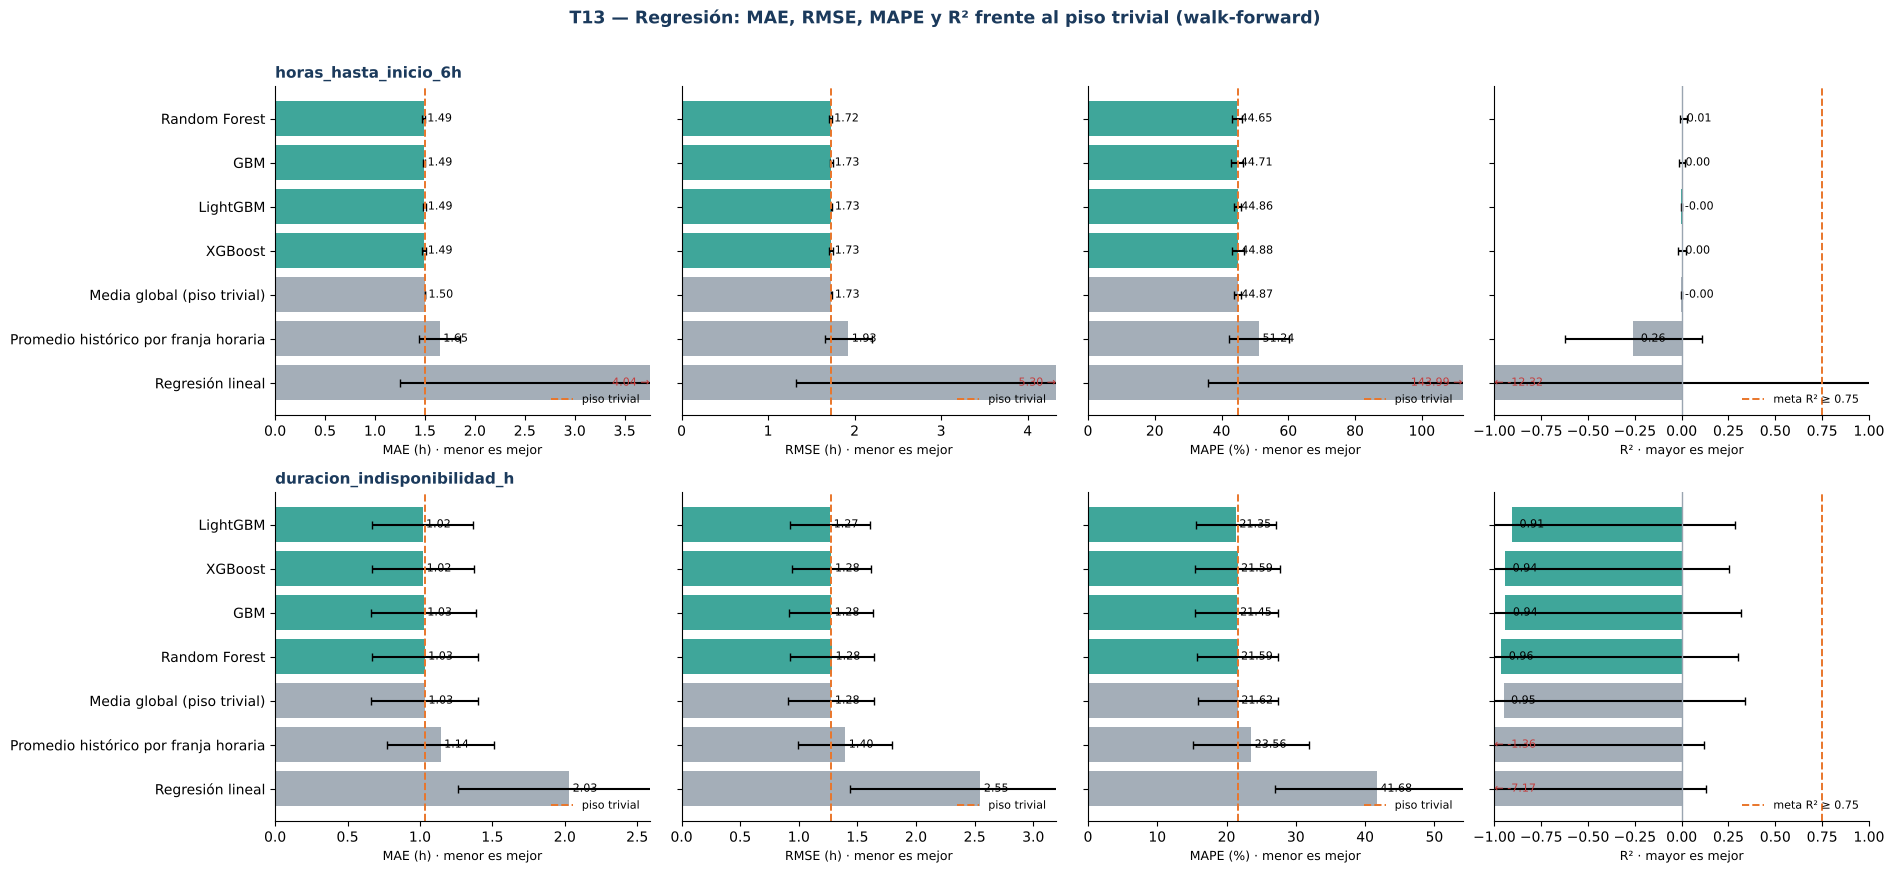

In [53]:
# ==== Vista visual - MAE, RMSE, MAPE y R² por modelo (media ± desviación entre ventanas) ====
METRICAS_GRAF = [('MAE_h', 'MAE_std', 'MAE (h)', True), ('RMSE_h', 'RMSE_std', 'RMSE (h)', True),
                 ('MAPE_pct', 'MAPE_std', 'MAPE (%)', True), ('R2', 'R2_std', 'R²', False)]
col_fam = {'referencia': COLOR_GRAY, 'avanzado': COLOR_TEAL}
fig, axes = plt.subplots(len(TARGETS_REG), 4, figsize=(19, 4.3 * len(TARGETS_REG)))
for fila, salida in enumerate(TARGETS_REG):
    t = resultados_reg[resultados_reg['salida'] == salida].sort_values('MAE_h', ascending=False)
    ref = t[t['modelo'] == 'Media global (piso trivial)'].iloc[0]
    for j, (m, s, etq, menor_mejor) in enumerate(METRICAS_GRAF):
        ax = axes[fila, j]
        ax.barh(t['modelo'], t[m], xerr=t[s].fillna(0), color=[col_fam[f] for f in t['familia']], capsize=3, alpha=0.9)
        if menor_mejor:
            ax.axvline(float(ref[m]), color=COLOR_ORANGE, ls='--', lw=1.4, label='piso trivial')
        else:
            ax.axvline(0, color=COLOR_GRAY, lw=1); ax.axvline(METAS['R2'], color=COLOR_ORANGE, ls='--', lw=1.4, label=f"meta R² ≥ {METAS['R2']}")
        # eje acotado para que un modelo que diverge (p. ej. la regresión lineal) no aplaste al resto; su valor se anota igual
        lim = (0, 2.5 * float(ref[m])) if menor_mejor else (-1.0, 1.0)
        ax.set_xlim(*lim)
        for y_, v_ in enumerate(t[m]):
            fuera = v_ > lim[1] or v_ < lim[0]
            x_txt = min(max(v_, lim[0]), lim[1])
            ax.text(x_txt, y_, (f' {v_:.2f} →' if v_ > lim[1] else f'← {v_:.2f}') if fuera else f' {v_:.2f}',
                    va='center', ha='right' if fuera and v_ > lim[1] else 'left', fontsize=8, color=COLOR_RED if fuera else 'black')
        ax.set_xlabel(etq + (' · menor es mejor' if menor_mejor else ' · mayor es mejor'), fontsize=9)
        if j: ax.set_yticklabels([])
        ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=8, loc='lower right')
        if j == 0: ax.set_title(salida, fontsize=11, color=COLOR_NAVY, fontweight='bold', loc='left')
plt.suptitle('T13 — Regresión: MAE, RMSE, MAPE y R² frente al piso trivial (walk-forward)', fontsize=12.5, color=COLOR_NAVY, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


=== Clasificador auxiliar — walk-forward (media de 4 ventanas) y validación ===


modelo,AUC,AUC_std,F1,F1_std,F1_trivial,F1_umbral05,Brier,umbral,AUC_val,F1_val
XGBoost,0.853000,0.052000,0.349000,0.094000,0.118000,0.119000,0.051000,0.140000,0.883000,0.459000
Random Forest,0.844000,0.047000,0.348000,0.088000,0.118000,0.339000,0.082000,0.530000,0.878000,0.468000
LightGBM,0.849000,0.047000,0.350000,0.074000,0.118000,0.014000,0.052000,0.080000,0.884000,0.448000



Detalle por ventana:


modelo,evaluacion,n_val,% evento,AUC,F1,F1_trivial,F1_umbral05,Brier,precision,recall,umbral
XGBoost,fold 1,3709,1.860000,0.886000,0.260000,0.037000,0.000000,0.017000,0.192000,0.406000,0.140000
XGBoost,fold 2,3697,2.110000,0.870000,0.283000,0.041000,0.071000,0.019000,0.239000,0.346000,0.140000
XGBoost,fold 3,3610,13.435000,0.776000,0.391000,0.237000,0.149000,0.109000,0.350000,0.443000,0.140000
XGBoost,fold 4,3788,8.553000,0.880000,0.462000,0.158000,0.257000,0.061000,0.330000,0.769000,0.140000
XGBoost,validación,3331,8.286000,0.883000,0.459000,0.153000,0.256000,0.059000,0.334000,0.736000,0.140000
Random Forest,fold 1,3709,1.860000,0.876000,0.308000,0.037000,0.291000,0.051000,0.212000,0.565000,0.530000
Random Forest,fold 2,3697,2.110000,0.851000,0.276000,0.041000,0.274000,0.038000,0.211000,0.397000,0.530000
Random Forest,fold 3,3610,13.435000,0.776000,0.332000,0.237000,0.334000,0.135000,0.314000,0.353000,0.530000
Random Forest,fold 4,3788,8.553000,0.875000,0.475000,0.158000,0.459000,0.104000,0.349000,0.744000,0.530000
Random Forest,validación,3331,8.286000,0.878000,0.468000,0.153000,0.457000,0.094000,0.349000,0.707000,0.530000


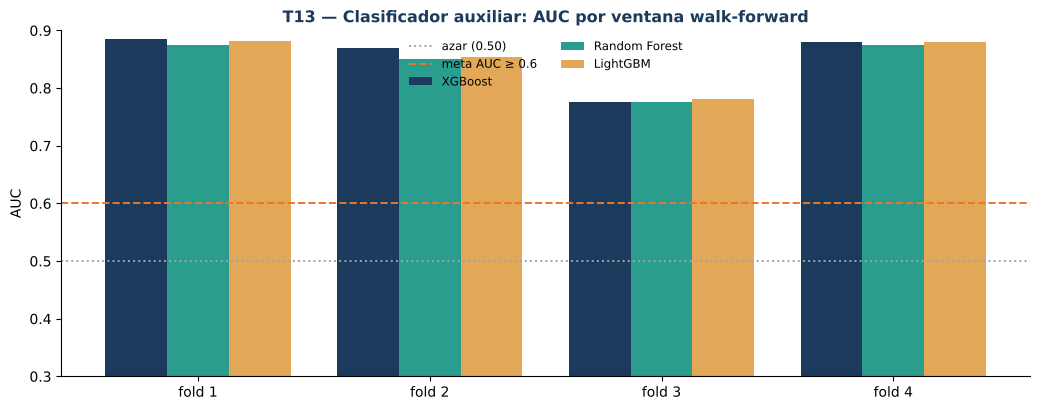

In [54]:
# ==== T13.2 - Evaluación del clasificador auxiliar: AUC, F1 y umbral ====
from sklearn.metrics import precision_score, recall_score
UMBRALES = np.round(np.arange(0.05, 0.951, 0.01), 2)
filas_clf, probs_oof, y_oof = [], {}, {}

for nombre in MODELOS_CLF:
    p = MEJORES[(nombre, TARGET_CLF)]['params']
    # 1) probabilidades fuera de muestra de cada ventana
    pr_k, y_k = [], []
    for k in range(1, N_FOLDS_WF + 1):
        Xa, ya, Xb, yb = CACHE_FOLDS[(k, 'clasificacion')]
        pr_k.append(crear_modelo(nombre, 'clasificacion', p).fit(Xa, ya).predict_proba(Xb)[:, 1]); y_k.append(yb.values)
    # 2) umbral que maximiza F1 en las predicciones fuera de muestra agrupadas (nunca en prueba); con pesos de clase el 0.5 deja de ser razonable
    pr_all, y_all = np.concatenate(pr_k), np.concatenate(y_k)
    f1s = [f1_score(y_all, pr_all >= u) for u in UMBRALES]
    umbral = float(UMBRALES[int(np.argmax(f1s))])
    probs_oof[nombre], y_oof[nombre] = pr_all, y_all
    # 3) métricas por ventana con ese umbral
    for k, (pk, yk) in enumerate(zip(pr_k, y_k), start=1):
        filas_clf.append({'modelo': nombre, 'evaluacion': f'fold {k}', 'n_val': len(yk), '% evento': 100 * yk.mean(), 'AUC': roc_auc_score(yk, pk),
                          'F1': f1_score(yk, pk >= umbral), 'F1_trivial': f1_trivial(yk), 'F1_umbral05': f1_score(yk, pk >= 0.5), 'Brier': brier_score_loss(yk, pk), 'precision': precision_score(yk, pk >= umbral, zero_division=0),
                          'recall': recall_score(yk, pk >= umbral), 'umbral': umbral})
    # 4) validación (partición): reentrenado con entrenamiento
    Xa, ya = datos_particion('entrenamiento', 'clasificacion'); Xb, yb = datos_particion('validacion', 'clasificacion')
    m = crear_modelo(nombre, 'clasificacion', p).fit(Xa, ya); pv = m.predict_proba(Xb)[:, 1]
    MODELOS_FINALES[(nombre, TARGET_CLF)] = m
    filas_clf.append({'modelo': nombre, 'evaluacion': 'validación', 'n_val': len(yb), '% evento': 100 * yb.mean(), 'AUC': roc_auc_score(yb, pv),
                      'F1': f1_score(yb, pv >= umbral), 'F1_trivial': f1_trivial(yb), 'F1_umbral05': f1_score(yb, pv >= 0.5), 'Brier': brier_score_loss(yb, pv), 'precision': precision_score(yb, pv >= umbral, zero_division=0),
                      'recall': recall_score(yb, pv >= umbral), 'umbral': umbral})

res_clf_det = pd.DataFrame(filas_clf)
wf_c = res_clf_det[res_clf_det['evaluacion'].str.startswith('fold')]
resultados_clf = wf_c.groupby('modelo', sort=False).agg(AUC=('AUC', 'mean'), AUC_std=('AUC', 'std'), F1=('F1', 'mean'), F1_std=('F1', 'std'),
                                                       F1_trivial=('F1_trivial', 'mean'), F1_umbral05=('F1_umbral05', 'mean'), Brier=('Brier', 'mean'), umbral=('umbral', 'first')).reset_index()
resultados_clf = resultados_clf.merge(res_clf_det[res_clf_det['evaluacion'] == 'validación'][['modelo', 'AUC', 'F1']].rename(columns={'AUC': 'AUC_val', 'F1': 'F1_val'}), on='modelo')
print('=== Clasificador auxiliar — walk-forward (media de 4 ventanas) y validación ===')
display(resultados_clf.round(3).style.hide(axis='index'))
print('\nDetalle por ventana:')
display(res_clf_det.round(3).style.hide(axis='index'))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
anchura = 0.8 / len(MODELOS_CLF)
for j, (nombre, color) in enumerate(zip(MODELOS_CLF, [COLOR_NAVY, COLOR_TEAL, COLOR_GOLD])):
    t = res_clf_det[(res_clf_det['modelo'] == nombre) & res_clf_det['evaluacion'].str.startswith('fold')]
    ax.bar(np.arange(len(t)) + (j - (len(MODELOS_CLF) - 1) / 2) * anchura, t['AUC'], width=anchura, color=color, label=nombre)
ax.axhline(0.5, color=COLOR_GRAY, ls=':', lw=1.4, label='azar (0.50)')
ax.axhline(METAS['AUC'], color=COLOR_ORANGE, ls='--', lw=1.4, label=f"meta AUC ≥ {METAS['AUC']}")
ax.set_xticks(range(N_FOLDS_WF)); ax.set_xticklabels([f'fold {k}' for k in range(1, N_FOLDS_WF + 1)]); ax.set_ylim(0.3, 0.9); ax.set_ylabel('AUC')
ax.set_title('T13 — Clasificador auxiliar: AUC por ventana walk-forward', fontsize=11.5, color=COLOR_NAVY, fontweight='bold')
ax.legend(frameon=False, fontsize=8.5, ncol=2); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### T13.3 Lectura de resultados frente a las metas

La tabla se **calcula con los resultados reales** de esta ejecución y ahora reporta, para el mejor modelo de cada salida, **MAE, RMSE, MAPE y R²** junto a su cociente frente al piso trivial. Sirve para decidir con la asesora qué hacer **antes** de HU08/HU09, no para maquillar cifras: si una meta no se alcanza, la tabla lo dice.

In [55]:
# ==== T13.3 - Metas vs resultados (calculado) ====
def estado(c): return 'CUMPLE' if c else 'NO CUMPLE'
filas = []
for salida in TARGETS_REG:
    t = resultados_reg[(resultados_reg['salida'] == salida) & (resultados_reg['familia'] == 'avanzado')].sort_values('MAE_h')
    mej = t.iloc[0]
    r2_max = t['R2'].max()
    filas.append([f'Regresión · {salida}', f"Mejor MAE: {mej['modelo']} ({mej['MAE_h']:.2f} ± {mej['MAE_std']:.2f} h; {mej['MAE_vs_piso']:.2f}× el piso trivial)",
                  f"RMSE = {mej['RMSE_h']:.2f} ± {mej['RMSE_std']:.2f} h ({mej['RMSE_vs_piso']:.2f}× piso)",
                  f"MAPE = {mej['MAPE_pct']:.1f} ± {mej['MAPE_std']:.1f} % ({mej['MAPE_vs_piso']:.2f}× piso)",
                  f"R² walk-forward máx. = {r2_max:.3f} (meta ≥ {METAS['R2']})", estado(r2_max >= METAS['R2']),
                  'Sí' if mej['MAE_vs_piso'] < 0.95 else 'No (no supera claramente al piso trivial)'])
mejor_clf = resultados_clf.sort_values('AUC', ascending=False).iloc[0]
filas.append(['Clasificador · ocurre_evento_6h', f"Mejor AUC: {mejor_clf['modelo']} ({mejor_clf['AUC']:.3f} ± {mejor_clf['AUC_std']:.3f})",
              '—', '—', f"AUC = {mejor_clf['AUC']:.3f} (meta ≥ {METAS['AUC']})", estado(mejor_clf['AUC'] >= METAS['AUC']), '—'])
mejor_f1 = resultados_clf.sort_values('F1', ascending=False).iloc[0]
filas.append(['Clasificador · ocurre_evento_6h', f"Mejor F1: {mejor_f1['modelo']} ({mejor_f1['F1']:.3f}; trivial {mejor_f1['F1_trivial']:.3f})",
              '—', '—', f"F1 = {mejor_f1['F1']:.3f} (meta ≥ {METAS['F1']})", estado(mejor_f1['F1'] >= METAS['F1']),
              'Sí' if mejor_f1['F1'] > mejor_f1['F1_trivial'] + 0.02 else 'No (≈ F1 de "siempre habrá evento")'])
lectura = pd.DataFrame(filas, columns=['Modelo', 'Resultado walk-forward (MAE / AUC / F1)', 'RMSE', 'MAPE', 'Meta', 'Estado', '¿Supera al piso trivial?'])
display(lectura.style.hide(axis='index'))

if (lectura['Estado'] == 'NO CUMPLE').any():
    print('\nAVISO: hay metas sin alcanzar. Antes de HU09 conviene decidir con la asesora, en este orden: '
          '(a) revisar el Diagnóstico de anticipación de HU06: si el AUC sin fuga ≈ 0.50, las variables in situ no anticipan el evento y la meta '
          'R² ≥ 0.75 no es alcanzable con estos datos; (b) incorporar variables que SÍ miran al futuro: pronóstico de oleaje/swell (periodo pico, '
          'dirección, Hs pronosticada; p. ej. Copernicus Marine, NOAA WaveWatch III) y avisos de la Marina (DHN); (c) pedir a Operaciones los umbrales '
          'reales de maniobra para construir variables de excedencia; (d) reportar la métrica como mejora frente al piso trivial (skill) y ajustar la meta con justificación. '
          'Subir N_TRIALS solo cambia el ajuste fino; no crea señal que los datos no tengan.')
else:
    print('\nTodas las metas se alcanzan en walk-forward; la confirmación independiente queda para HU09 (prueba).')

Modelo,Resultado walk-forward (MAE / AUC / F1),RMSE,MAPE,Meta,Estado,¿Supera al piso trivial?
Regresión · horas_hasta_inicio_6h,Mejor MAE: Random Forest (1.49 ± 0.02 h; 0.99× el piso trivial),RMSE = 1.72 ± 0.02 h (1.00× piso),MAPE = 44.7 ± 1.6 % (1.00× piso),R² walk-forward máx. = 0.008 (meta ≥ 0.75),NO CUMPLE,No (no supera claramente al piso trivial)
Regresión · duracion_indisponibilidad_h,Mejor MAE: LightGBM (1.02 ± 0.35 h; 0.98× el piso trivial),RMSE = 1.27 ± 0.34 h (0.99× piso),MAPE = 21.3 ± 5.8 % (0.99× piso),R² walk-forward máx. = -0.906 (meta ≥ 0.75),NO CUMPLE,No (no supera claramente al piso trivial)
Clasificador · ocurre_evento_6h,Mejor AUC: XGBoost (0.853 ± 0.052),—,—,AUC = 0.853 (meta ≥ 0.6),CUMPLE,—
Clasificador · ocurre_evento_6h,Mejor F1: LightGBM (0.350; trivial 0.118),—,—,F1 = 0.350 (meta ≥ 0.65),NO CUMPLE,Sí



AVISO: hay metas sin alcanzar. Antes de HU09 conviene decidir con la asesora, en este orden: (a) revisar el Diagnóstico de anticipación de HU06: si el AUC sin fuga ≈ 0.50, las variables in situ no anticipan el evento y la meta R² ≥ 0.75 no es alcanzable con estos datos; (b) incorporar variables que SÍ miran al futuro: pronóstico de oleaje/swell (periodo pico, dirección, Hs pronosticada; p. ej. Copernicus Marine, NOAA WaveWatch III) y avisos de la Marina (DHN); (c) pedir a Operaciones los umbrales reales de maniobra para construir variables de excedencia; (d) reportar la métrica como mejora frente al piso trivial (skill) y ajustar la meta con justificación. Subir N_TRIALS solo cambia el ajuste fino; no crea señal que los datos no tengan.


### T13.4 Diagnóstico: ¿dónde está (o no) la señal?

Dos comprobaciones calculadas con los datos reales para orientar la conversación con la asesora: (1) **cuántos eventos independientes** hay detrás de las filas (las horas consecutivas de un mismo evento no son observaciones independientes) y (2) **cuándo** ocurren los eventos (hora del día y mes). Si la tasa de eventos cambia por temporada pero no por hora, y las variables meteo-oceanográficas actuales no explican esa variación, un modelo entrenado en unos meses no generaliza a otros.

Eventos independientes (inicios distintos) detrás de las etiquetas: 176  ·  filas del clasificador: 18,562


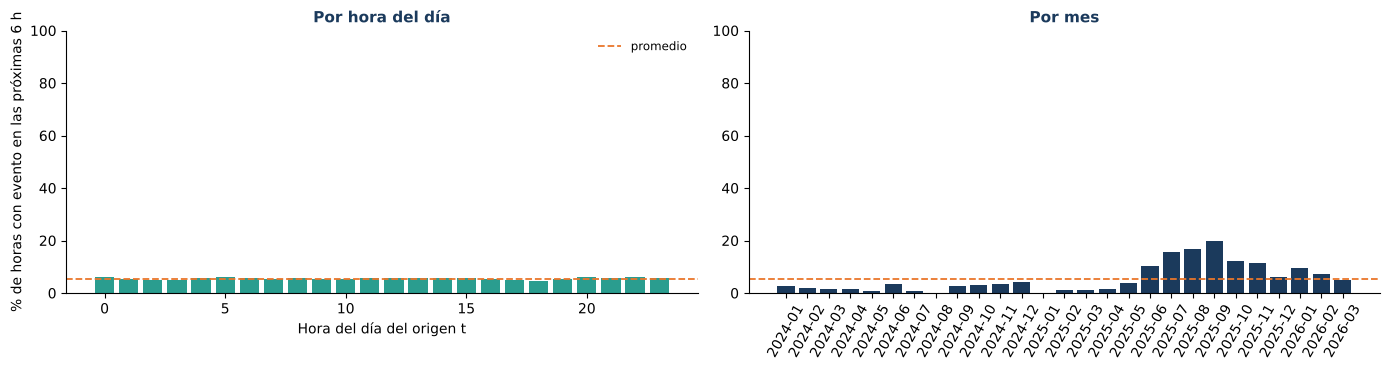

Rango de la tasa mensual: 0 % – 20 %  ·  rango por hora del día: 5 % – 6 %


In [56]:
# ==== T13.4 - Diagnóstico de señal: eventos independientes y estacionalidad ====
_e = df.loc[df['entrenable_clasificador'] == 1]
_ini = pd.Series(df.index + pd.Timedelta(hours=ORIGEN_AL_CIERRE_H) + pd.to_timedelta(df['horas_hasta_inicio_6h'], unit='h')).where(df['horas_hasta_inicio_6h'].notna().values).dropna().dt.round('h')
print(f'Eventos independientes (inicios distintos) detrás de las etiquetas: {_ini.nunique()}  ·  filas del clasificador: {len(_e):,}')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
por_hora = _e.groupby(_e.index.hour)[TARGET_CLF].mean() * 100
axes[0].bar(por_hora.index, por_hora.values, color=COLOR_TEAL)
axes[0].axhline(_e[TARGET_CLF].mean() * 100, color=COLOR_ORANGE, ls='--', lw=1.3, label='promedio')
axes[0].set_xlabel('Hora del día del origen t'); axes[0].set_ylabel(f'% de horas con evento en las próximas {HORIZONTE_H} h')
axes[0].set_title('Por hora del día', fontsize=11, color=COLOR_NAVY, fontweight='bold'); axes[0].legend(frameon=False, fontsize=8.5); axes[0].set_ylim(0, 100)
por_mes = _e.groupby(_e.index.to_period('M'))[TARGET_CLF].mean() * 100
axes[1].bar(por_mes.index.astype(str), por_mes.values, color=COLOR_NAVY)
axes[1].axhline(_e[TARGET_CLF].mean() * 100, color=COLOR_ORANGE, ls='--', lw=1.3)
axes[1].set_title('Por mes', fontsize=11, color=COLOR_NAVY, fontweight='bold'); axes[1].tick_params(axis='x', rotation=60); axes[1].set_ylim(0, 100)
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
print(f'Rango de la tasa mensual: {por_mes.min():.0f} % – {por_mes.max():.0f} %  ·  rango por hora del día: {por_hora.min():.0f} % – {por_hora.max():.0f} %')

## 3.4 HU07-B (V9) — Formulación operativa (análisis complementario)

Esta sección y la 3.5 solo **entrenan y evalúan**; ningún modelo se exporta aquí. La exportación de los modelos finales se hace al final, en la **sección 3.7**, después de la mejora de los regresores.

### Formulación operativa (V9): qué se predice y con qué información

**Objetivos nuevos** (origen `o = t + 1 h`, cierre de la hora; `H = HORIZONTE_B_H`):

| Objetivo | Tipo | Definición | Filas |
|---|---|---|---|
| `indisponible_prox_H` | clasificación (AUC, F1) | 1 si el terminal estará indisponible **en algún momento** de `(o, o+H]`, por un evento nuevo **o por uno ya en curso** | todas las filas entrenables |
| `horas_indisponibles_prox_H` | regresión (MAE, RMSE, MAPE, R²) | horas indisponibles dentro de `(o, o+H]` (unión de intervalos de eventos) | todas las filas entrenables |
| `horas_restantes_evento` | regresión (MAE, RMSE, MAPE, R²) | horas que faltan para que termine el evento **en curso** (`fecha_fin − o`): *¿cuándo se reanuda la operación?* | solo filas con evento en curso |

**Familias de variables nuevas** (todas causales: solo usan información anterior a `o`):

| Familia | Variables | Fuente |
|---|---|---|
| **T12.8 Estado operativo** (antes opcional, ahora activo en esta sección) | evento en curso, horas desde el inicio del evento en curso, horas desde el fin del último evento, n.° de eventos en 24 h / 72 h / 7 días | bitácora del Centro de Control: el terminal **sabe** si está detenido |
| **T12.9 Evento observado** | máximo y media de ola y viento **desde el inicio del evento en curso hasta `o`**, n.° de lecturas sobre el p95, causa declarada (oleaje / viento) | CSV de 5 min + bitácora |
| **T12.10 Excedencias y calendario** | lecturas de 5 min sobre el p95 / p99 de entrenamiento en 1, 3, 6 y 12 h, horas desde la última excedencia, seno/coseno del día del año y de la hora | CSV de 5 min |

> **Validación pendiente con el Product Owner:** el estado operativo usa la bitácora como predictor. Es información que el terminal tiene en tiempo real (sabe si suspendió la maniobra y desde cuándo), pero cambia la pregunta: ya no es *"¿empezará un evento?"* sino *"¿cuántas horas más estaremos indisponibles?"*.
>
> **Referencia obligatoria (persistencia):** para saber si el modelo aporta algo, se compara con reglas **sin modelo**: "si hay un evento en curso, sigue indisponible" (clasificación) y "horas restantes = media histórica de las horas restantes según las horas ya transcurridas" (regresión).

In [57]:
# ==== V9 · Cargar dependencias de datos para la formulación operativa ====
import pandas as pd

# Cargamos los insumos limpios requeridos por la sección 3.4
FEAT_B = pd.read_csv('dataset_features_HU06_sin_escalar.csv', index_col='fecha_hora', parse_dates=['fecha_hora']).sort_index()
EV_B = pd.read_csv('eventos_limpios_HU05.csv', parse_dates=['fecha_inicio', 'fecha_fin']).sort_values('fecha_inicio').reset_index(drop=True)

# Cargar lecturas de 5 min descriptivas para análisis de picos
def _cargar_5min_v9(patrones, factor=1.0):
    import glob
    rutas = [r for p in patrones for r in glob.glob(p)]
    assert rutas, f'Falta el CSV de 5 min: {patrones}'
    x = pd.read_csv(rutas[0]).iloc[:, :2]; x.columns = ['t', 'v']
    x['t'] = pd.to_datetime(x['t'], errors='coerce')
    x['v'] = pd.to_numeric(x['v'].astype(str).str.replace(',', '.').str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce') * factor
    return x.dropna(subset=['t']).drop_duplicates('t', keep='last').set_index('t')['v'].sort_index()

OLA_5M    = _cargar_5min_v9(['Altura_de_Olas*.csv', 'Altura de Olas*.csv'])
VIENTO_5M = _cargar_5min_v9(['Velocidad_de_Viento*.csv', 'Velocidad de Viento*.csv'], 0.44704)   # mph -> m/s
CORTE_TRAIN_B = FEAT_B.index[FEAT_B['particion'] == 'validacion'].min()

print(f"FEAT_B cargado: {FEAT_B.shape}")
print(f"EV_B cargado: {len(EV_B)} eventos")
print(f"Series de 5 min cargadas. Ola: {len(OLA_5M)}, Viento: {len(VIENTO_5M)}")

FEAT_B cargado: (22920, 187)
EV_B cargado: 230 eventos
Series de 5 min cargadas. Ola: 275040, Viento: 275040


In [58]:
# ==== V9 · Construcción de objetivos y variables de la formulación operativa ====
HORIZONTE_B_H = globals().get('HORIZONTE_H', 6)          # mismo horizonte configurado en HU05
idx_b = FEAT_B.index
ov = (idx_b + pd.Timedelta(hours=globals().get('ORIGEN_AL_CIERRE_H', 1))).values.astype('datetime64[ns]')
ini_b = EV_B['fecha_inicio'].values.astype('datetime64[ns]'); fin_b = EV_B['fecha_fin'].values.astype('datetime64[ns]')

def umbrales_entrenamiento(ola, viento, corte_train):
    """Percentiles 95/99 de las lecturas de 5 min, aprendidos SOLO con la partición de entrenamiento."""
    return {(n, q): s[s.index < corte_train].quantile(q) for n, s in [('ola', ola), ('viento', viento)] for q in (0.95, 0.99)}

def construir_operativo(ov, ini_b, fin_b, ola, viento, dom_oleaje, umbrales):
    """Variables T12.8-T12.10 y objetivos de la formulación operativa. Solo usa lecturas con marca < origen."""
    H_ = pd.DataFrame(index=idx_b)
    p = np.searchsorted(ini_b, ov, side='right') - 1; pc = np.clip(p, 0, None)
    fin_cummax = np.maximum.accumulate(fin_b)
    en_curso = (p >= 0) & (fin_cummax[pc] > ov)
    H_['evento_en_curso'] = en_curso.astype(float)
    H_['h_desde_inicio_evento'] = np.where(en_curso, (ov - ini_b[pc]) / np.timedelta64(1, 'h'), -1.0)
    fin_ord = np.sort(fin_b); q = np.searchsorted(fin_ord, ov, side='right') - 1
    H_['h_desde_fin_ultimo_evento'] = np.where(q >= 0, np.minimum((ov - fin_ord[np.clip(q, 0, None)]) / np.timedelta64(1, 'h'), 500), 500)
    for h in [24, 72, 168]:
        H_[f'eventos_ultimas_{h}h'] = (np.searchsorted(ini_b, ov, side='right') - np.searchsorted(ini_b, ov - np.timedelta64(h, 'h'), side='right')).astype(float)
    # T12.9 evento observado (lecturas desde el inicio del evento en curso hasta el origen, sin incluirlo)
    thr = {'ola': umbrales[('ola', 0.95)], 'viento': umbrales[('viento', 0.95)]}
    cols = {k: np.full(len(ov), np.nan) for k in ['ola_max_en_evento', 'viento_max_en_evento', 'ola_media_en_evento',
                                                  'viento_media_en_evento', 'exc_ola_en_evento', 'exc_viento_en_evento']}
    for j in np.unique(pc[en_curso]):
        filas_j = np.where(en_curso & (pc == j))[0]
        o_ = ola.loc[ini_b[j]:fin_b[j]]; v_ = viento.loc[ini_b[j]:fin_b[j]]
        for r in filas_j:
            oo, vv = o_[o_.index < ov[r]], v_[v_.index < ov[r]]
            if len(oo): cols['ola_max_en_evento'][r], cols['ola_media_en_evento'][r], cols['exc_ola_en_evento'][r] = oo.max(), oo.mean(), (oo > thr['ola']).sum()
            if len(vv): cols['viento_max_en_evento'][r], cols['viento_media_en_evento'][r], cols['exc_viento_en_evento'][r] = vv.max(), vv.mean(), (vv > thr['viento']).sum()
    for k, v in cols.items(): H_[k] = v
    H_['evento_por_oleaje'] = np.where(en_curso, dom_oleaje[pc], np.nan)
    # T12.10 excedencias de 5 min y calendario (la hora t resume [t, t+1h) = lecturas anteriores al origen)
    for nom, s in [('ola', ola), ('viento', viento)]:
        for qq in [0.95, 0.99]:
            u = umbrales[(nom, qq)]
            c = (s > u).resample('h').sum().reindex(idx_b).fillna(0)
            for w in [1, 3, 6, 12]:
                H_[f'exc_{nom}_p{int(qq*100)}_{w}h'] = c.rolling(w, min_periods=1).sum()
            ult = pd.Series(np.where(c > 0, np.arange(len(idx_b)), np.nan), index=idx_b).ffill().fillna(-1e4)
            H_[f'h_desde_exc_{nom}_p{int(qq*100)}'] = np.minimum(np.arange(len(idx_b)) - ult, 500)
    H_['dia_anio_sin'], H_['dia_anio_cos'] = np.sin(2 * np.pi * idx_b.dayofyear / 365.25), np.cos(2 * np.pi * idx_b.dayofyear / 365.25)
    H_['hora_sin'], H_['hora_cos'] = np.sin(2 * np.pi * idx_b.hour / 24), np.cos(2 * np.pi * idx_b.hour / 24)
    # Objetivos
    iv = sorted(zip(ini_b, fin_b)); U = []
    for s, e in iv:
        if U and s <= U[-1][1]: U[-1][1] = max(U[-1][1], e)
        else: U.append([s, e])
    fin_v = ov + np.timedelta64(int(HORIZONTE_B_H * 3600), 's'); horas = np.zeros(len(ov))
    for s, e in U:
        horas += np.clip((np.minimum(fin_v, e) - np.maximum(ov, s)) / np.timedelta64(1, 'h'), 0, None)
    Y = pd.DataFrame({'indisponible_prox_H': (horas > 0).astype(int), 'horas_indisponibles_prox_H': horas,
                      'horas_restantes_evento': np.where(en_curso, (fin_cummax[pc] - ov) / np.timedelta64(1, 'h'), np.nan)}, index=idx_b)
    return H_, Y

DOM_OLEAJE = EV_B['variable_dominante'].fillna('').str.contains('ola').values.astype(float)
UMBRALES_B = umbrales_entrenamiento(OLA_5M, VIENTO_5M, CORTE_TRAIN_B)
X_OPER, Y_OPER = construir_operativo(ov, ini_b, fin_b, OLA_5M, VIENTO_5M, DOM_OLEAJE, UMBRALES_B)

# ---- Prueba de causalidad: borrar el futuro (eventos y lecturas desde p) no cambia ninguna fila anterior
p_ = len(idx_b) // 2; t_p = np.datetime64(idx_b[p_])
m_ev = ini_b < t_p
X_pert, _ = construir_operativo(ov, ini_b[m_ev], np.minimum(fin_b[m_ev], t_p + np.timedelta64(1, 'h')),
                                OLA_5M[OLA_5M.index < idx_b[p_]], VIENTO_5M[VIENTO_5M.index < idx_b[p_]], DOM_OLEAJE[m_ev], UMBRALES_B)
causal_b = X_OPER.iloc[:p_ - 1].fillna(-999).equals(X_pert.iloc[:p_ - 1].fillna(-999))
print(f'Horizonte de la formulación operativa: {HORIZONTE_B_H} h  ·  variables nuevas: {X_OPER.shape[1]}')
print(f'Prueba de causalidad (alterar el futuro no cambia el pasado): {"OK" if causal_b else "FALLA"}')
assert causal_b

META_B = ['particion', 'apto_modelado', 'racha_apto_h', 'entrenable_clasificador', 'entrenable_regresores', 'frac_imputada_6h', 'frac_imputada_24h']
TG_B = ['ocurre_evento_6h', 'horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']
X_HU06_B = FEAT_B[[c for c in FEAT_B.columns if c not in META_B + TG_B]]
CONJUNTOS_X = {
    'solo sensores (HU06 + excedencias + calendario)': X_HU06_B.join(X_OPER[[c for c in X_OPER.columns if c.startswith(('exc_ola_p', 'exc_viento_p', 'h_desde_exc', 'dia_anio', 'hora_'))]]),
    'sensores + estado operativo + evento observado': X_HU06_B.join(X_OPER),
}
# Filas: entrenables de HU06, SIN la prueba (que sigue bloqueada hasta HU09)
EL_B = (FEAT_B['entrenable_clasificador'] == 1) & FEAT_B['particion'].isin(['entrenamiento', 'validacion'])
EL_REST = EL_B & Y_OPER['horas_restantes_evento'].notna()
display(pd.DataFrame({
    'filas': [int(EL_B.sum()), int(EL_B.sum()), int(EL_REST.sum())],
    'media del objetivo': [Y_OPER.loc[EL_B, 'indisponible_prox_H'].mean(), Y_OPER.loc[EL_B, 'horas_indisponibles_prox_H'].mean(), Y_OPER.loc[EL_REST, 'horas_restantes_evento'].mean()],
}, index=['indisponible_prox_H (prevalencia)', 'horas_indisponibles_prox_H (h)', 'horas_restantes_evento (h)']).round(3))

Horizonte de la formulación operativa: 6 h  ·  variables nuevas: 37
Prueba de causalidad (alterar el futuro no cambia el pasado): OK


,filas,media del objetivo
indisponible_prox_H (prevalencia),18562,0.105
horas_indisponibles_prox_H (h),18562,0.311
horas_restantes_evento (h),943,2.939


In [59]:
# ==== V9 · Optimización (Optuna, walk-forward) y evaluación de la formulación operativa ====
import optuna, time
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
optuna.logging.set_verbosity(optuna.logging.WARNING)
FOLDS_B = pd.read_csv('folds_walk_forward_HU06.csv', parse_dates=['train_ini', 'train_fin', 'val_ini', 'val_fin'])
N_TRIALS_B = globals().get('N_TRIALS_B', 25)          # pruebas de Optuna por modelo y objetivo
TIMEOUT_B_S = globals().get('TIMEOUT_B_S', 180)       # tope de segundos por búsqueda
SEM = globals().get('SEMILLA', 42)

def folds_b(mask):
    for _, f in FOLDS_B.iterrows():
        yield (mask & (idx_b >= f.train_ini) & (idx_b <= f.train_fin)), (mask & (idx_b >= f.val_ini) & (idx_b <= f.val_fin))

def espacio_b(nombre, tr, clf):
    if nombre == 'LightGBM':
        return dict(n_estimators=tr.suggest_int('n_estimators', 100, 600, step=50), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.1, log=True),
                    num_leaves=tr.suggest_int('num_leaves', 4, 48), min_child_samples=tr.suggest_int('min_child_samples', 10, 120),
                    subsample=tr.suggest_float('subsample', 0.5, 1.0), colsample_bytree=tr.suggest_float('colsample_bytree', 0.2, 1.0),
                    reg_lambda=tr.suggest_float('reg_lambda', 0.1, 30, log=True))
    if nombre == 'XGBoost':
        return dict(n_estimators=tr.suggest_int('n_estimators', 100, 600, step=50), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.1, log=True),
                    max_depth=tr.suggest_int('max_depth', 2, 6), min_child_weight=tr.suggest_int('min_child_weight', 1, 30),
                    subsample=tr.suggest_float('subsample', 0.5, 1.0), colsample_bytree=tr.suggest_float('colsample_bytree', 0.2, 1.0),
                    reg_lambda=tr.suggest_float('reg_lambda', 0.1, 30, log=True))
    if nombre == 'Random Forest':
        return dict(n_estimators=tr.suggest_int('n_estimators', 100, 300, step=50), max_depth=tr.suggest_int('max_depth', 3, 14),
                    min_samples_leaf=tr.suggest_int('min_samples_leaf', 2, 40), max_features=tr.suggest_float('max_features', 0.1, 0.5),
                    max_samples=tr.suggest_float('max_samples', 0.5, 0.9))
    if nombre == 'GBM':
        return dict(max_iter=tr.suggest_int('max_iter', 100, 500, step=50), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.1, log=True),
                    max_depth=tr.suggest_int('max_depth', 2, 6), min_samples_leaf=tr.suggest_int('min_samples_leaf', 10, 80),
                    l2_regularization=tr.suggest_float('l2_regularization', 0.0, 10.0),
                    loss=tr.suggest_categorical('loss', ['squared_error', 'absolute_error']))

def modelo_b(nombre, clf, p):
    if nombre == 'LightGBM': return (LGBMClassifier if clf else LGBMRegressor)(subsample_freq=1, verbose=-1, random_state=SEM, n_jobs=-1, **p)
    if nombre == 'XGBoost':  return (XGBClassifier if clf else XGBRegressor)(verbosity=0, random_state=SEM, n_jobs=-1, **p)
    if nombre == 'Random Forest': return (RandomForestClassifier if clf else RandomForestRegressor)(random_state=SEM, n_jobs=-1, **p)
    if nombre == 'GBM': return HistGradientBoostingRegressor(random_state=SEM, **p)     # GBM de scikit-learn (versión por histogramas, más rápida)

def oof(nombre, clf, p, X, y, mask):
    pr, ys = [], []
    for mt, mv in folds_b(mask):
        m = modelo_b(nombre, clf, p).fit(X[mt], y[mt])
        pr.append(m.predict_proba(X[mv])[:, 1] if clf else m.predict(X[mv])); ys.append(y[mv].values)
    return pr, ys

def met_clf(pr, ys):
    pa, ya = np.concatenate(pr), np.concatenate(ys)
    us = np.round(np.arange(0.02, 0.98, 0.01), 2); u = float(us[np.argmax([f1_score(ya, pa >= t) for t in us])])   # umbral sobre predicciones fuera de muestra
    auc = [roc_auc_score(y, p) for p, y in zip(pr, ys)]; f1 = [f1_score(y, p >= u) for p, y in zip(pr, ys)]
    return {'AUC': np.mean(auc), 'AUC_sd': np.std(auc, ddof=1), 'F1': np.mean(f1), 'F1_sd': np.std(f1, ddof=1), 'umbral': u,
            'F1_trivial': np.mean([f1_score(y, np.ones(len(y))) for y in ys])}

def met_reg(pr, ys, ymin=1.0):
    r = []
    for p, y in zip(pr, ys):
        mm = y >= ymin
        r.append([mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p)), 100 * np.mean(np.abs((y[mm] - p[mm]) / y[mm])) if mm.any() else np.nan, r2_score(y, p)])
    r = np.array(r); out = {}
    for j, k in enumerate(['MAE_h', 'RMSE_h', 'MAPE_%', 'R2']): out[k], out[k + '_sd'] = np.nanmean(r[:, j]), np.nanstd(r[:, j], ddof=1)
    return out

def optimizar_b(nombre, clf, X, y, mask):
    def obj(tr):
        pr, ys = oof(nombre, clf, espacio_b(nombre, tr, clf), X, y, mask)
        v = [roc_auc_score(b, a) for a, b in zip(pr, ys)] if clf else [mean_absolute_error(b, a) for a, b in zip(pr, ys)]
        return np.mean(v) - 0.5 * np.std(v, ddof=1) if clf else np.mean(v) + 0.5 * np.std(v, ddof=1)
    st = optuna.create_study(direction='maximize' if clf else 'minimize', sampler=optuna.samplers.TPESampler(seed=SEM))
    st.optimize(obj, n_trials=N_TRIALS_B, timeout=TIMEOUT_B_S)
    return st.best_params

# ---- Referencias SIN modelo (persistencia)
def persistencia_clf(mask):
    s = X_OPER['evento_en_curso'] + 1e-3 * X_OPER['h_desde_inicio_evento'].clip(lower=0)
    pr, ys = [], []
    for mt, mv in folds_b(mask): pr.append(s[mv].values); ys.append(Y_OPER.loc[mv, 'indisponible_prox_H'].values)
    return pr, ys

def persistencia_reg(objetivo, mask):
    pr, ys = [], []
    el = X_OPER['h_desde_inicio_evento'].round()
    for mt, mv in folds_b(mask):
        y = Y_OPER[objetivo]
        if objetivo == 'horas_restantes_evento':
            tab = y[mt].groupby(el[mt]).mean(); p = el[mv].map(tab).fillna(y[mt].mean())
        else:                                           # en curso: min(H, restante medio); sin evento: media de entrenamiento sin evento
            enc = X_OPER['evento_en_curso'] > 0
            rest = Y_OPER['horas_restantes_evento'][mt & enc].groupby(el[mt & enc]).mean()
            p = np.where(enc[mv], np.minimum(HORIZONTE_B_H, el[mv].map(rest).fillna(rest.mean())), y[mt & ~enc].mean())
        pr.append(np.asarray(p, float)); ys.append(y[mv].values)
    return pr, ys

# Con 'solo sensores' basta LightGBM (mide si los sensores aportan); con el conjunto completo se optimizan todos los algoritmos
MODELOS_POR_CONJUNTO = {'solo sensores (HU06 + excedencias + calendario)': (['LightGBM'], ['LightGBM']),
                        'sensores + estado operativo + evento observado': (['XGBoost', 'Random Forest', 'LightGBM'], ['LightGBM', 'XGBoost', 'Random Forest', 'GBM'])}
t0 = time.time(); RES_B, PARAMS_B = [], {}
for nx, X in CONJUNTOS_X.items():
    y = Y_OPER['indisponible_prox_H']
    mod_clf, mod_reg = MODELOS_POR_CONJUNTO[nx]
    for nombre in mod_clf:
        PARAMS_B[(nx, 'indisponible_prox_H', nombre)] = p = optimizar_b(nombre, True, X, y, EL_B)
        RES_B.append({'objetivo': 'indisponible_prox_H', 'variables': nx, 'modelo': nombre, **met_clf(*oof(nombre, True, p, X, y, EL_B))})
    for objetivo, mask in [('horas_indisponibles_prox_H', EL_B), ('horas_restantes_evento', EL_REST)]:
        for nombre in mod_reg:
            PARAMS_B[(nx, objetivo, nombre)] = p = optimizar_b(nombre, False, X, Y_OPER[objetivo], mask)
            RES_B.append({'objetivo': objetivo, 'variables': nx, 'modelo': nombre, **met_reg(*oof(nombre, False, p, X, Y_OPER[objetivo], mask))})
    print(f'  {nx}: listo ({time.time() - t0:,.0f} s)')
RES_B.append({'objetivo': 'indisponible_prox_H', 'variables': 'regla sin modelo', 'modelo': 'Persistencia (evento en curso)', **met_clf(*persistencia_clf(EL_B))})
for objetivo, mask in [('horas_indisponibles_prox_H', EL_B), ('horas_restantes_evento', EL_REST)]:
    RES_B.append({'objetivo': objetivo, 'variables': 'regla sin modelo', 'modelo': 'Persistencia (media según horas transcurridas)', **met_reg(*persistencia_reg(objetivo, mask))})
resultados_b = pd.DataFrame(RES_B)
for objetivo in ['indisponible_prox_H', 'horas_indisponibles_prox_H', 'horas_restantes_evento']:
    t = resultados_b[resultados_b['objetivo'] == objetivo].dropna(axis=1, how='all')
    t = t.sort_values('AUC' if objetivo == 'indisponible_prox_H' else 'MAE_h', ascending=objetivo != 'indisponible_prox_H')
    print(f'\n=== {objetivo} (H = {HORIZONTE_B_H} h) — walk-forward, media ± desv. de 4 ventanas ===')
    display(t.drop(columns='objetivo').round(3).style.hide(axis='index'))

  solo sensores (HU06 + excedencias + calendario): listo (197 s)


  sensores + estado operativo + evento observado: listo (1,573 s)



=== indisponible_prox_H (H = 6 h) — walk-forward, media ± desv. de 4 ventanas ===


variables,modelo,AUC,AUC_sd,F1,F1_sd,umbral,F1_trivial
sensores + estado operativo + evento observado,LightGBM,0.936000,0.013000,0.669000,0.115000,0.150000,0.209000
sensores + estado operativo + evento observado,XGBoost,0.936000,0.015000,0.680000,0.121000,0.180000,0.209000
sensores + estado operativo + evento observado,Random Forest,0.930000,0.017000,0.653000,0.162000,0.220000,0.209000
solo sensores (HU06 + excedencias + calendario),LightGBM,0.894000,0.027000,0.516000,0.177000,0.090000,0.209000
regla sin modelo,Persistencia (evento en curso),0.728000,0.028000,0.624000,0.052000,0.020000,0.209000



=== horas_indisponibles_prox_H (H = 6 h) — walk-forward, media ± desv. de 4 ventanas ===


variables,modelo,MAE_h,MAE_h_sd,RMSE_h,RMSE_h_sd,MAPE_%,MAPE_%_sd,R2,R2_sd
sensores + estado operativo + evento observado,Random Forest,0.292000,0.231000,0.726000,0.381000,53.598000,6.966000,0.430000,0.124000
sensores + estado operativo + evento observado,XGBoost,0.295000,0.222000,0.733000,0.376000,55.373000,7.373000,0.411000,0.144000
sensores + estado operativo + evento observado,LightGBM,0.309000,0.213000,0.741000,0.367000,55.609000,7.993000,0.378000,0.194000
regla sin modelo,Persistencia (media según horas transcurridas),0.310000,0.236000,0.816000,0.450000,68.840000,7.965000,0.314000,0.089000
sensores + estado operativo + evento observado,GBM,0.334000,0.235000,0.762000,0.382000,56.308000,6.738000,0.348000,0.186000
solo sensores (HU06 + excedencias + calendario),LightGBM,0.382000,0.274000,0.873000,0.471000,69.499000,7.968000,0.201000,0.121000



=== horas_restantes_evento (H = 6 h) — walk-forward, media ± desv. de 4 ventanas ===


variables,modelo,MAE_h,MAE_h_sd,RMSE_h,RMSE_h_sd,MAPE_%,MAPE_%_sd,R2,R2_sd
sensores + estado operativo + evento observado,GBM,0.920000,0.232000,1.184000,0.254000,31.269000,5.501000,0.435000,0.179000
sensores + estado operativo + evento observado,XGBoost,0.929000,0.255000,1.185000,0.281000,32.464000,6.356000,0.431000,0.204000
sensores + estado operativo + evento observado,LightGBM,0.944000,0.225000,1.220000,0.248000,32.065000,6.017000,0.391000,0.212000
regla sin modelo,Persistencia (media según horas transcurridas),0.945000,0.185000,1.173000,0.228000,34.114000,8.697000,0.423000,0.252000
sensores + estado operativo + evento observado,Random Forest,0.968000,0.207000,1.208000,0.240000,30.333000,6.286000,0.395000,0.229000
solo sensores (HU06 + excedencias + calendario),LightGBM,1.375000,0.209000,1.636000,0.262000,40.175000,3.121000,-0.048000,0.081000


In [60]:
# ==== V9 · Tabla final: metas vs resultados (las dos formulaciones) ====
def _estado(c): return 'CUMPLE' if c else 'NO CUMPLE'
METAS = globals().get('METAS', {'R2': 0.75, 'F1': 0.65, 'AUC': 0.60})
filas = []
# Formulación original (sección 3.3)
if 'resultados_reg' in globals() and 'resultados_clf' in globals():
    for salida in [s for s in resultados_reg['salida'].unique()]:
        t = resultados_reg[(resultados_reg['salida'] == salida) & (resultados_reg['familia'] == 'avanzado')].sort_values('MAE_h').iloc[0]
        filas.append(['Original (inicio del evento)', salida, t['modelo'], f"MAE {t['MAE_h']:.2f} · RMSE {t['RMSE_h']:.2f} · MAPE {t['MAPE_pct']:.1f}% · R² {t['R2']:.3f}",
                      f"R² ≥ {METAS['R2']}", _estado(t['R2'] >= METAS['R2']), f"{t['MAE_vs_piso']:.2f}× piso trivial"])
    c = resultados_clf.sort_values('AUC', ascending=False).iloc[0]; f = resultados_clf.sort_values('F1', ascending=False).iloc[0]
    filas.append(['Original (inicio del evento)', TARGET_CLF, c['modelo'], f"AUC {c['AUC']:.3f}", f"AUC ≥ {METAS['AUC']}", _estado(c['AUC'] >= METAS['AUC']), '—'])
    filas.append(['Original (inicio del evento)', TARGET_CLF, f['modelo'], f"F1 {f['F1']:.3f} (trivial {f['F1_trivial']:.3f})", f"F1 ≥ {METAS['F1']}", _estado(f['F1'] >= METAS['F1']), '—'])
# Formulación operativa (esta sección)
rb = resultados_b
pc_ = rb[(rb['objetivo'] == 'indisponible_prox_H') & (rb['variables'] == 'regla sin modelo')].iloc[0]
for objetivo in ['indisponible_prox_H', 'horas_indisponibles_prox_H', 'horas_restantes_evento']:
    t = rb[(rb['objetivo'] == objetivo) & (rb['variables'] != 'regla sin modelo')]
    per = rb[(rb['objetivo'] == objetivo) & (rb['variables'] == 'regla sin modelo')].iloc[0]
    if objetivo == 'indisponible_prox_H':
        b = t.sort_values('AUC', ascending=False).iloc[0]
        filas.append(['Operativa (V9)', objetivo, f"{b['modelo']} · {b['variables']}", f"AUC {b['AUC']:.3f} ± {b['AUC_sd']:.3f}", f"AUC ≥ {METAS['AUC']}",
                      _estado(b['AUC'] >= METAS['AUC']), f"persistencia AUC {per['AUC']:.3f}"])
        b = t.sort_values('F1', ascending=False).iloc[0]
        filas.append(['Operativa (V9)', objetivo, f"{b['modelo']} · {b['variables']}", f"F1 {b['F1']:.3f} ± {b['F1_sd']:.3f} (trivial {b['F1_trivial']:.3f})", f"F1 ≥ {METAS['F1']}",
                      _estado(b['F1'] >= METAS['F1']), f"persistencia F1 {per['F1']:.3f}"])
    else:
        b = t.sort_values('R2', ascending=False).iloc[0]
        filas.append(['Operativa (V9)', objetivo, f"{b['modelo']} · {b['variables']}",
                      f"MAE {b['MAE_h']:.2f} · RMSE {b['RMSE_h']:.2f} · MAPE {b['MAPE_%']:.1f}% · R² {b['R2']:.3f} ± {b['R2_sd']:.3f}",
                      f"R² ≥ {METAS['R2']}", _estado(b['R2'] >= METAS['R2']), f"persistencia R² {per['R2']:.3f} · MAE {per['MAE_h']:.2f}"])
tabla_metas_v9 = pd.DataFrame(filas, columns=['Formulación', 'Objetivo', 'Mejor modelo', 'Resultado walk-forward', 'Meta', 'Estado', 'Referencia'])
display(tabla_metas_v9.style.hide(axis='index'))

Formulación,Objetivo,Mejor modelo,Resultado walk-forward,Meta,Estado,Referencia
Original (inicio del evento),duracion_indisponibilidad_h,LightGBM,MAE 1.02 · RMSE 1.27 · MAPE 21.3% · R² -0.906,R² ≥ 0.75,NO CUMPLE,0.98× piso trivial
Original (inicio del evento),horas_hasta_inicio_6h,Random Forest,MAE 1.49 · RMSE 1.72 · MAPE 44.7% · R² 0.008,R² ≥ 0.75,NO CUMPLE,0.99× piso trivial
Original (inicio del evento),ocurre_evento_6h,XGBoost,AUC 0.853,AUC ≥ 0.6,CUMPLE,—
Original (inicio del evento),ocurre_evento_6h,LightGBM,F1 0.350 (trivial 0.118),F1 ≥ 0.65,NO CUMPLE,—
Operativa (V9),indisponible_prox_H,LightGBM · sensores + estado operativo + evento observado,AUC 0.936 ± 0.013,AUC ≥ 0.6,CUMPLE,persistencia AUC 0.728
Operativa (V9),indisponible_prox_H,XGBoost · sensores + estado operativo + evento observado,F1 0.680 ± 0.121 (trivial 0.209),F1 ≥ 0.65,CUMPLE,persistencia F1 0.624
Operativa (V9),horas_indisponibles_prox_H,Random Forest · sensores + estado operativo + evento observado,MAE 0.29 · RMSE 0.73 · MAPE 53.6% · R² 0.430 ± 0.124,R² ≥ 0.75,NO CUMPLE,persistencia R² 0.314 · MAE 0.31
Operativa (V9),horas_restantes_evento,GBM · sensores + estado operativo + evento observado,MAE 0.92 · RMSE 1.18 · MAPE 31.3% · R² 0.435 ± 0.179,R² ≥ 0.75,NO CUMPLE,persistencia R² 0.423 · MAE 0.95


### Conclusiones de la V9 con la data 01-01-2024 → 12-08-2026 (resultados de esta ejecución)

**Qué cambió respecto de la data anterior (23-05-2025 → 12-08-2026):** con 2 años y 7 meses de sensores **sí aparece señal previa al evento**.
- **Picos:** los eventos ocupan el 5.8 % del tiempo y reúnen el 32–50 % de las lecturas extremas, de 5.5 a 8.6 veces lo esperable por azar.
- **Antes del inicio:** en las 24 h previas, el oleaje está +0.30 desv. estándar sobre su nivel semanal y el viento +0.20.
- **Anticipación:** el AUC sin fuga es 0.83 a 1, 3 y 6 h, 0.76 a 12 h y 0.64 a 24 h. Con la data anterior era ≈ 0.50 en todos los horizontes.

**1. Formulación original (anticipar el inicio del evento, H = 6 h)**

| Objetivo | Mejor resultado walk-forward | Meta | Estado |
|---|---|---|---|
| `ocurre_evento_6h` | AUC **0.853 ± 0.052** (XGBoost) · validación 0.883 | AUC ≥ 0.60 | **CUMPLE** |
| `ocurre_evento_6h` | F1 0.350 (trivial 0.118) · validación 0.46 | F1 ≥ 0.65 | NO CUMPLE |
| `horas_hasta_inicio_6h` | MAE 1.49 h · RMSE 1.72 h · MAPE 44.7 % · R² 0.008 | R² ≥ 0.75 | NO CUMPLE |
| `duracion_indisponibilidad_h` | MAE 1.02 h · RMSE 1.27 h · MAPE 21.3 % · R² −0.906 | R² ≥ 0.75 | NO CUMPLE |

- **F1:** el clasificador ordena bien las horas de riesgo (AUC 0.85), pero con 6.5 % de horas positivas el F1 se queda en ~0.35. Ni con horizontes de 3 a 12 h ni con más variables pasó de ~0.40.
- **Horas hasta el inicio:** el momento exacto dentro de las 6 h sigue sin poder predecirse (R² ≈ 0).
- **Duración:** el R² negativo se debe a un **cambio de régimen en el histórico**. En 2024 hay pocos eventos y cortos (~4.3 h de media); desde el 2.º trimestre de 2025 hay muchos más y duran ~6 h. La ventana 3 aprende con 2024 y se evalúa con eventos de ~6 h (R² −2.7), y la media de entrenamiento falla igual.

**2. Formulación operativa (sección 3.4, H = 6 h)**

| Objetivo | Mejor modelo | Resultado walk-forward | Meta | Estado | Persistencia |
|---|---|---|---|---|---|
| `indisponible_prox_H` | LightGBM | AUC **0.936 ± 0.013** | AUC ≥ 0.60 | **CUMPLE** | AUC 0.728 |
| `indisponible_prox_H` | XGBoost | F1 **0.680 ± 0.121** (trivial 0.209) | F1 ≥ 0.65 | **CUMPLE** | F1 0.624 |
| `horas_indisponibles_prox_H` | Random Forest | MAE 0.29 h · RMSE 0.73 h · MAPE 53.6 % · R² 0.430 | R² ≥ 0.75 | NO CUMPLE | R² 0.314 |
| `horas_restantes_evento` | GBM | MAE 0.92 h · RMSE 1.18 h · MAPE 31.3 % · R² 0.435 | R² ≥ 0.75 | NO CUMPLE | R² 0.423 |

- **Clasificador:** ahora sí **supera claramente a la persistencia** (AUC 0.94 frente a 0.73). Con solo sensores ya llega a 0.89, así que las variables meteo-oceanográficas aportan. Es el modelo que cumple AUC y F1 a la vez.
- **Horas restantes:** con esta data no cumple. El mismo cambio de régimen de la duración hace que el R² varíe mucho entre ventanas (± 0.18).

**3. Recomendaciones**
1. **Clasificador:** proponer `indisponible_prox_H` (6 h, sensores + estado operativo) como clasificador del proyecto: cumple AUC y F1 y supera a la persistencia. El PO debe validar el uso de la bitácora como predictor.
2. **Cambio de régimen:** revisar con Operaciones por qué desde el 2.º trimestre de 2025 hay ~3 veces más eventos y duran ~1.7 h más. Puede ser un cambio de criterio en la bitácora, de umbrales de maniobra o de equipos. Mientras no se aclare, conviene evaluar la regresión de duración **solo con el periodo homogéneo** (desde mayo de 2025) o agregar una variable de régimen validada.
3. **Pronósticos:** para `horas_hasta_inicio` y la duración siguen haciendo falta variables que miren al futuro: pronóstico de oleaje y swell (Hs, Tp, dirección), de viento y avisos de la DHN.
4. **HU09:** confirmar en la partición `prueba` (22-03-2026 → 12-08-2026, intacta) el AUC y el F1 de `indisponible_prox_H` y de `ocurre_evento_6h`.


## 3.5 HU07-C (V9.1) — Mejora de los regresores y evaluación por MAE, RMSE y MAPE

En la sección 3.3, los cuatro algoritmos de regresión quedan **iguales al piso trivial** (MAE/piso ≈ 0.99–1.00) para las dos salidas, y el R² es ≈ 0 o negativo. Esta sección prueba qué se puede mejorar con la data disponible y **cambia el criterio de evaluación de los regresores**:

- **Métricas principales:** **MAE, RMSE y MAPE**, siempre acompañadas de su **cociente frente al piso trivial** (< 1 = el modelo mejora). El R² se sigue reportando, pero solo como referencia.
- **Por qué no el R²:**
  - `horas_hasta_inicio_6h` está acotada a `(0, H]`, así que su varianza es pequeña y casi toda aleatoria.
  - `duracion_indisponibilidad_h` cambia de régimen en el histórico (≈ 4.3 h en 2024 → ≈ 6 h desde el 2.º trimestre de 2025). Con eso el R² sale negativo **incluso para la media**, aunque el error en horas sea pequeño.

**Qué se prueba**

| Mejora | Idea | Salida |
|---|---|---|
| **Variables de régimen** (T12.11) | Duración media de los últimos 3 / 5 / 10 / 20 eventos **ya terminados** al momento `o`, duración del último evento, n.° de eventos en 30 y 90 días | ambas |
| **Referencia adaptativa** | Predecir la duración como la **media de los últimos 10 eventos terminados** (se adapta sola al cambio de régimen) | duración |
| **Modelo sobre la referencia** (residual) | LightGBM aprende la **desviación** respecto de la referencia adaptativa (los árboles no extrapolan un cambio de nivel, pero sí pueden aprender desviaciones) y se aplica con un factor de suavizado optimizado | duración |
| **Pérdida absoluta (L1)** | LightGBM con objetivo MAE en lugar de MSE | horas hasta el inicio |
| **Variables de régimen + estado operativo + excedencias** | Las mismas familias de la sección 3.4 | horas hasta el inicio |

Todo es causal: solo usa eventos **terminados** antes de `o` y lecturas anteriores a `o`. La evaluación usa las mismas 4 ventanas walk-forward y la partición `prueba` sigue intacta.

In [61]:
# ==== V9.1 · Variables de régimen (T12.11) y objetivos de la formulación original ====
import json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import optuna
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore'); optuna.logging.set_verbosity(optuna.logging.WARNING)

FEAT_C = pd.read_csv('dataset_features_HU06_sin_escalar.csv', index_col='fecha_hora', parse_dates=['fecha_hora']).sort_index()
EV_C = pd.read_csv('eventos_limpios_HU05.csv', parse_dates=['fecha_inicio', 'fecha_fin']).sort_values('fecha_inicio').reset_index(drop=True)
FOLDS_C = pd.read_csv('folds_walk_forward_HU06.csv', parse_dates=['train_ini', 'train_fin', 'val_ini', 'val_fin'])
idx_c = FEAT_C.index
ORIGEN_C = globals().get('ORIGEN_AL_CIERRE_H', 1)
o_c = (idx_c + pd.Timedelta(hours=ORIGEN_C)).values.astype('datetime64[ns]')
ini_c = EV_C['fecha_inicio'].values.astype('datetime64[ns]'); fin_c = EV_C['fecha_fin'].values.astype('datetime64[ns]')
dur_c = (fin_c - ini_c) / np.timedelta64(1, 'h')

# Régimen: solo eventos que YA TERMINARON antes del origen (lo que el terminal conoce)
orden = np.argsort(fin_c); fin_ord, dur_ord = fin_c[orden], dur_c[orden]
k_term = np.searchsorted(fin_ord, o_c, side='right')                     # n.° de eventos terminados antes de o
acum = np.concatenate([[0.0], np.cumsum(dur_ord)])
REGIMEN = pd.DataFrame(index=idx_c)
for n in [3, 5, 10, 20]:
    lo = np.maximum(k_term - n, 0); cnt = k_term - lo
    REGIMEN[f'dur_media_ult{n}_eventos'] = np.where(cnt > 0, (acum[k_term] - acum[lo]) / np.maximum(cnt, 1), np.nan)
REGIMEN['dur_ultimo_evento'] = np.where(k_term > 0, dur_ord[np.maximum(k_term - 1, 0)], np.nan)
for h, etq in [(720, '30d'), (2160, '90d')]:
    REGIMEN[f'eventos_ultimos_{etq}'] = (np.searchsorted(ini_c, o_c, side='right') - np.searchsorted(ini_c, o_c - np.timedelta64(h, 'h'), side='right')).astype(float)

# Prueba de causalidad: borrar los eventos posteriores a p no cambia ninguna fila anterior
p_c = len(idx_c) // 2; t_p = np.datetime64(idx_c[p_c])
ok_ev = fin_c < t_p
o2, d2 = np.sort(fin_c[ok_ev]), dur_c[ok_ev][np.argsort(fin_c[ok_ev])]
k2 = np.searchsorted(o2, o_c, side='right'); a2 = np.concatenate([[0.0], np.cumsum(d2)])
lo2 = np.maximum(k2 - 10, 0)
r10_pert = np.where(k2 - lo2 > 0, (a2[k2] - a2[lo2]) / np.maximum(k2 - lo2, 1), np.nan)
causal_c = np.allclose(np.nan_to_num(REGIMEN['dur_media_ult10_eventos'].values[:p_c - 1], nan=-9), np.nan_to_num(r10_pert[:p_c - 1], nan=-9))
print(f'Prueba de causalidad de las variables de régimen: {"OK" if causal_c else "FALLA"}'); assert causal_c

# Objetivos (los mismos de HU05, con el horizonte configurado)
TG_C = ['ocurre_evento_6h', 'horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']
META_C = ['particion', 'apto_modelado', 'racha_apto_h', 'entrenable_clasificador', 'entrenable_regresores', 'frac_imputada_6h', 'frac_imputada_24h']
X_HU06_C = FEAT_C[[c for c in FEAT_C.columns if c not in META_C + TG_C]]
EL_REG_C = (FEAT_C['entrenable_regresores'] == 1) & FEAT_C['particion'].isin(['entrenamiento', 'validacion'])
X_OPER_C = globals().get('X_OPER', pd.DataFrame(index=idx_c))                 # variables de la sección 3.4 (si ya corrió)
CONJ_C = {'HU06': X_HU06_C,
          'HU06 + estado operativo + excedencias + régimen': X_HU06_C.join(X_OPER_C).join(REGIMEN),
          'régimen + estado operativo': X_OPER_C[[c for c in X_OPER_C.columns if c.startswith(('evento_en_curso', 'h_desde', 'eventos_ultimas', 'dia_anio'))]].join(REGIMEN)}

# La duración cambia de régimen: tabla por trimestre (eventos limpios)
reg_trim = EV_C.assign(trim=EV_C['fecha_inicio'].dt.to_period('Q').astype(str)).groupby('trim')['duracion_h'].agg(eventos='size', duracion_media_h='mean', desv_h='std').round(2)
display(reg_trim.T)
print(f'Filas del regresor (entrenamiento + validación): {int(EL_REG_C.sum()):,}  ·  variables de régimen: {REGIMEN.shape[1]}')

Prueba de causalidad de las variables de régimen: OK


trim,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
eventos,7.00,9.00,4.00,13.00,3.00,19.00,62.00,35.00,27.00,27.00,24.00
duracion_media_h,4.45,4.31,3.64,4.87,3.19,5.73,6.01,5.97,6.11,6.16,5.96
desv_h,1.54,1.52,1.04,0.84,1.05,1.08,0.93,0.93,0.85,0.91,0.69


Filas del regresor (entrenamiento + validación): 1,022  ·  variables de régimen: 7


In [62]:
# ==== V9.1 · Evaluación walk-forward con MAE, RMSE y MAPE (y R² como referencia) ====
MAPE_MIN_C = globals().get('MAPE_Y_MIN_H', 1.0)
N_TRIALS_C = globals().get('N_TRIALS_C', 30)
SEM_C = globals().get('SEMILLA', 42)

def folds_c(mask):
    for _, f in FOLDS_C.iterrows():
        mt = mask & (idx_c >= f.train_ini) & (idx_c <= f.train_fin); mv = mask & (idx_c >= f.val_ini) & (idx_c <= f.val_fin)
        if mt.sum() >= 30 and mv.sum() >= 10:
            yield mt, mv

def metricas_c(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); mm = y >= MAPE_MIN_C
    return {'MAE_h': mean_absolute_error(y, p), 'RMSE_h': float(np.sqrt(mean_squared_error(y, p))),
            'MAPE_%': 100 * float(np.mean(np.abs((y[mm] - p[mm]) / y[mm]))) if mm.any() else np.nan, 'R2': r2_score(y, p)}

def evaluar_c(salida, nombre, predecir):
    """predecir(mt, mv) -> predicciones para las filas mv (solo puede usar datos de mt para ajustar)."""
    y = FEAT_C[salida]; filas = []
    for k, (mt, mv) in enumerate(folds_c(EL_REG_C), start=1):
        filas.append({'fold': k, **metricas_c(y[mv], predecir(mt, mv))})
    d = pd.DataFrame(filas)
    out = {'salida': salida, 'modelo': nombre}
    for c in ['MAE_h', 'RMSE_h', 'MAPE_%', 'R2']:
        out[c], out[c + '_sd'] = d[c].mean(), d[c].std()
    return out, d

def lgbm_c(p): return LGBMRegressor(subsample_freq=1, verbose=-1, random_state=SEM_C, n_jobs=-1, **p)

def espacio_c(tr):
    return dict(n_estimators=tr.suggest_int('n_estimators', 100, 600, step=50), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.1, log=True),
                num_leaves=tr.suggest_int('num_leaves', 3, 31), min_child_samples=tr.suggest_int('min_child_samples', 15, 120),
                subsample=tr.suggest_float('subsample', 0.5, 1.0), colsample_bytree=tr.suggest_float('colsample_bytree', 0.2, 1.0),
                reg_lambda=tr.suggest_float('reg_lambda', 0.1, 50, log=True),
                objective=tr.suggest_categorical('objective', ['regression', 'regression_l1', 'huber']))

def optimizar_c(salida, X, base=None):
    """Optuna (MAE medio + 0.5·desv entre ventanas). Si base es una columna de REGIMEN, el modelo aprende y - base
    y la predicción es base + suavizado · modelo (el suavizado también se optimiza)."""
    y = FEAT_C[salida]
    def pred(p, s, mt, mv):
        if base is None:
            return lgbm_c(p).fit(X[mt], y[mt]).predict(X[mv])
        b_t = REGIMEN.loc[mt, base].fillna(y[mt].mean()); b_v = REGIMEN.loc[mv, base].fillna(y[mt].mean())
        return b_v.values + s * lgbm_c(p).fit(X[mt], y[mt] - b_t).predict(X[mv])
    def obj(tr):
        p = espacio_c(tr); s = tr.suggest_float('suavizado', 0.0, 1.0) if base is not None else 1.0
        v = [mean_absolute_error(y[mv], pred(p, s, mt, mv)) for mt, mv in folds_c(EL_REG_C)]
        return np.mean(v) + 0.5 * np.std(v, ddof=1)
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEM_C))
    st.optimize(obj, n_trials=N_TRIALS_C, timeout=300)
    bp = dict(st.best_params); s = bp.pop('suavizado', 1.0)
    return (lambda mt, mv: pred(bp, s, mt, mv)), {**bp, 'suavizado': s}

t0 = time.time(); RES_C, DET_C, PARAMS_C = [], {}, {}
def registrar_c(salida, nombre, f):
    r, d = evaluar_c(salida, nombre, f); RES_C.append(r); DET_C[(salida, nombre)] = d

for salida in ['duracion_indisponibilidad_h', 'horas_hasta_inicio_6h']:
    y = FEAT_C[salida]
    registrar_c(salida, 'Piso trivial: media de entrenamiento', lambda mt, mv, y=y: np.full(int(mv.sum()), y[mt].mean()))
    registrar_c(salida, 'Piso trivial: mediana de entrenamiento', lambda mt, mv, y=y: np.full(int(mv.sum()), y[mt].median()))
    if salida == 'duracion_indisponibilidad_h':
        for n in [5, 10]:
            registrar_c(salida, f'Referencia adaptativa: media de los últimos {n} eventos',
                        lambda mt, mv, n=n, y=y: REGIMEN.loc[mv, f'dur_media_ult{n}_eventos'].fillna(y[mt].mean()).values)
    for nx, X in CONJ_C.items():
        if X.shape[1] == 0: continue
        f, p = optimizar_c(salida, X); PARAMS_C[(salida, f'LightGBM · {nx}')] = p
        registrar_c(salida, f'LightGBM optimizado · {nx}', f)
        if salida == 'duracion_indisponibilidad_h':
            f, p = optimizar_c(salida, X, base='dur_media_ult10_eventos'); PARAMS_C[(salida, f'Residual · {nx}')] = p
            registrar_c(salida, f'LightGBM sobre referencia adaptativa · {nx}', f)
    print(f'  {salida}: listo ({time.time() - t0:,.0f} s)')

resultados_c = pd.DataFrame(RES_C)
for salida in ['duracion_indisponibilidad_h', 'horas_hasta_inicio_6h']:
    t = resultados_c[resultados_c['salida'] == salida].copy()
    piso = t[t['modelo'] == 'Piso trivial: media de entrenamiento'].iloc[0]
    for m in ['MAE_h', 'RMSE_h', 'MAPE_%']:
        t[f'{m.split("_")[0]}/piso'] = t[m] / piso[m]
    t = t.sort_values('MAE_h')
    resultados_c.loc[t.index, [c for c in t.columns if c.endswith('/piso')]] = t[[c for c in t.columns if c.endswith('/piso')]]
    print(f'\n=== {salida} — walk-forward (media ± desv. entre ventanas) ===')
    display(t[['modelo', 'MAE_h', 'MAE_h_sd', 'RMSE_h', 'RMSE_h_sd', 'MAPE_%', 'MAPE_%_sd', 'MAE/piso', 'RMSE/piso', 'MAPE/piso', 'R2']].round(3).style.hide(axis='index'))
from pathlib import Path

  duracion_indisponibilidad_h: listo (38 s)


  horas_hasta_inicio_6h: listo (52 s)

=== duracion_indisponibilidad_h — walk-forward (media ± desv. entre ventanas) ===


modelo,MAE_h,MAE_h_sd,RMSE_h,RMSE_h_sd,MAPE_%,MAPE_%_sd,MAE/piso,RMSE/piso,MAPE/piso,R2
LightGBM sobre referencia adaptativa · régimen + estado operativo,0.835000,0.075000,1.087000,0.123000,19.503000,7.545000,0.807000,0.850000,0.902000,-0.304000
LightGBM sobre referencia adaptativa · HU06 + estado operativo + excedencias + régimen,0.839000,0.076000,1.090000,0.125000,19.545000,7.508000,0.812000,0.853000,0.904000,-0.311000
LightGBM sobre referencia adaptativa · HU06,0.841000,0.073000,1.093000,0.122000,19.615000,7.499000,0.813000,0.855000,0.907000,-0.319000
Referencia adaptativa: media de los últimos 10 eventos,0.844000,0.071000,1.091000,0.116000,19.545000,7.336000,0.816000,0.854000,0.904000,-0.313000
Referencia adaptativa: media de los últimos 5 eventos,0.855000,0.070000,1.078000,0.074000,19.535000,7.145000,0.827000,0.844000,0.903000,-0.281000
LightGBM optimizado · régimen + estado operativo,0.982000,0.411000,1.227000,0.414000,20.942000,7.036000,0.950000,0.960000,0.968000,-0.830000
LightGBM optimizado · HU06 + estado operativo + excedencias + régimen,0.996000,0.271000,1.253000,0.279000,21.610000,7.205000,0.963000,0.981000,0.999000,-0.838000
LightGBM optimizado · HU06,1.025000,0.324000,1.276000,0.320000,21.535000,5.247000,0.991000,0.998000,0.996000,-0.919000
Piso trivial: media de entrenamiento,1.034000,0.369000,1.278000,0.366000,21.624000,5.782000,1.000000,1.000000,1.000000,-0.951000
Piso trivial: mediana de entrenamiento,1.048000,0.352000,1.302000,0.353000,22.477000,7.132000,1.013000,1.019000,1.039000,-1.026000



=== horas_hasta_inicio_6h — walk-forward (media ± desv. entre ventanas) ===


modelo,MAE_h,MAE_h_sd,RMSE_h,RMSE_h_sd,MAPE_%,MAPE_%_sd,MAE/piso,RMSE/piso,MAPE/piso,R2
LightGBM optimizado · HU06,1.487000,0.024000,1.724000,0.017000,44.771000,1.915000,0.991000,0.996000,0.998000,0.007000
LightGBM optimizado · régimen + estado operativo,1.489000,0.017000,1.723000,0.016000,44.905000,1.446000,0.992000,0.995000,1.001000,0.008000
LightGBM optimizado · HU06 + estado operativo + excedencias + régimen,1.490000,0.019000,1.730000,0.006000,44.950000,1.645000,0.993000,0.999000,1.002000,0.000000
Piso trivial: mediana de entrenamiento,1.499000,0.006000,1.731000,0.004000,45.372000,1.205000,0.999000,1.000000,1.011000,-0.001000
Piso trivial: media de entrenamiento,1.500000,0.004000,1.731000,0.004000,44.874000,1.016000,1.000000,1.000000,1.000000,-0.001000


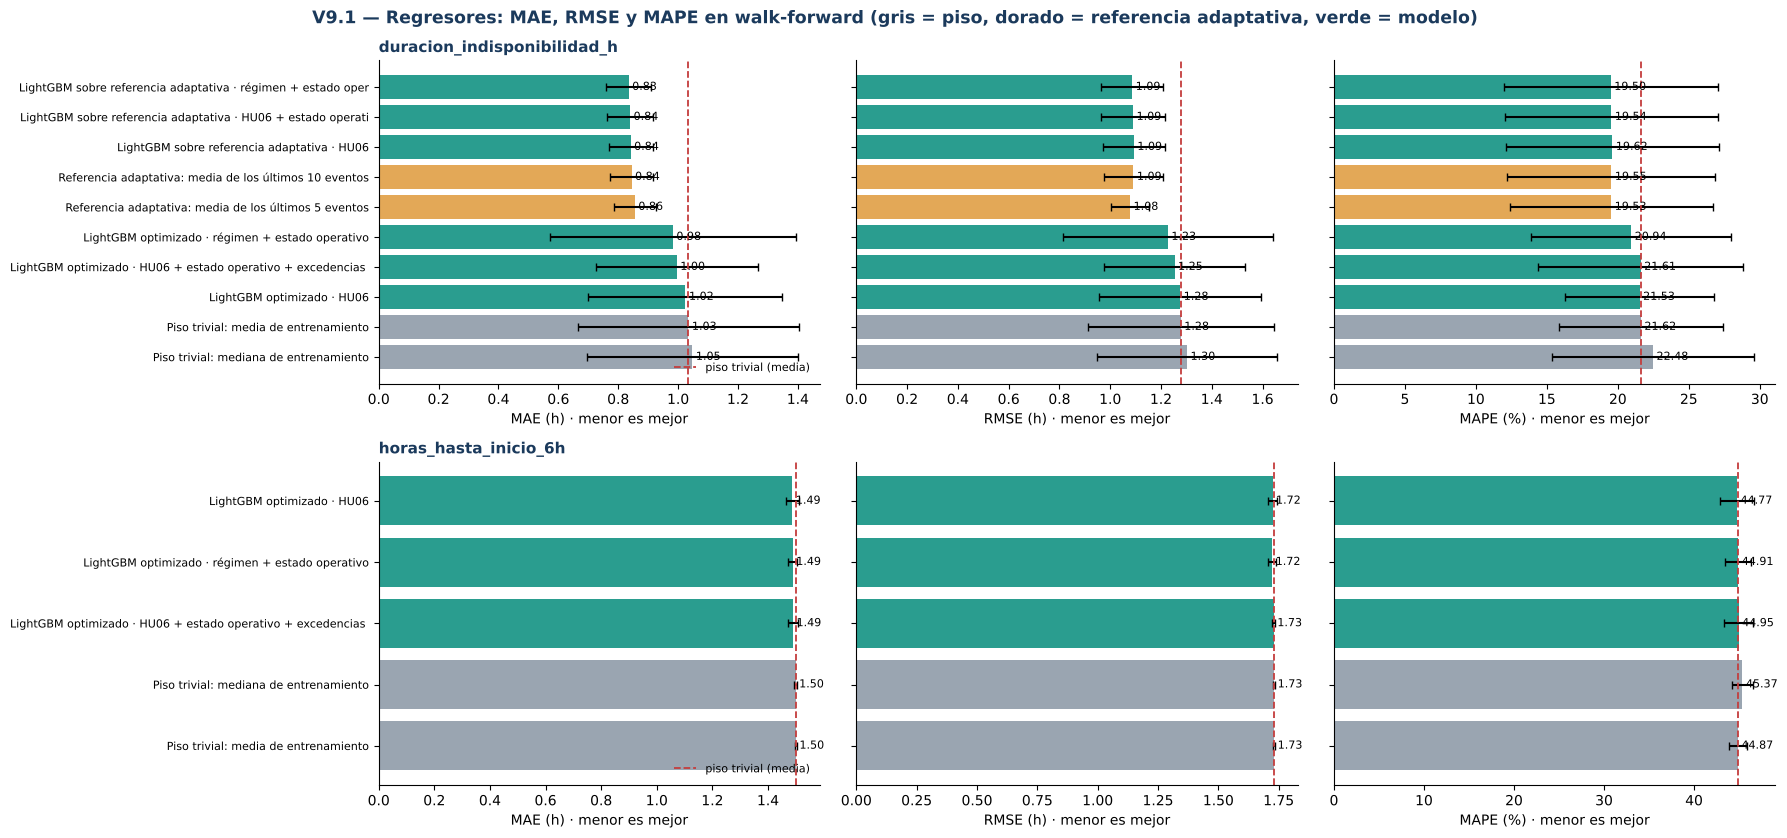

Salida,Mejor modelo,MAE (h),RMSE (h),MAPE (%),Piso MAE / RMSE / MAPE,Cociente vs piso (MAE / RMSE / MAPE),R² (referencia),¿Utilizable?
duracion_indisponibilidad_h,LightGBM sobre referencia adaptativa · régimen + estado operativo,0.83 ± 0.07,1.09,19.5,1.03 / 1.28 / 21.6,0.81 / 0.85 / 0.90,-0.304,SÍ: mejora al piso
horas_hasta_inicio_6h,LightGBM optimizado · HU06,1.49 ± 0.02,1.72,44.8,1.50 / 1.73 / 44.9,0.99 / 1.00 / 1.00,0.007,NO: no supera al piso


In [63]:
# ==== V9.1 · Vista visual y tabla final de los regresores (MAE, RMSE y MAPE frente al piso) ====
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
for fila, salida in enumerate(['duracion_indisponibilidad_h', 'horas_hasta_inicio_6h']):
    t = resultados_c[resultados_c['salida'] == salida].sort_values('MAE_h', ascending=False)
    piso = t[t['modelo'] == 'Piso trivial: media de entrenamiento'].iloc[0]
    colores = ['#9AA5B1' if m.startswith('Piso') else ('#E3A857' if m.startswith('Referencia') else '#2A9D8F') for m in t['modelo']]
    for j, (m, etq) in enumerate([('MAE_h', 'MAE (h)'), ('RMSE_h', 'RMSE (h)'), ('MAPE_%', 'MAPE (%)')]):
        ax = axes[fila, j]
        ax.barh(t['modelo'].str.slice(0, 60), t[m], xerr=t[m + '_sd'].fillna(0), color=colores, capsize=3)
        ax.axvline(piso[m], color='#C43D3D', ls='--', lw=1.3, label='piso trivial (media)')
        for yv, v in enumerate(t[m]): ax.text(v, yv, f' {v:.2f}', va='center', fontsize=8)
        ax.set_xlabel(etq + ' · menor es mejor'); ax.spines[['top', 'right']].set_visible(False)
        if j: ax.set_yticklabels([])
        else: ax.set_title(salida, loc='left', fontsize=11, color='#1B3A5C', fontweight='bold')
        ax.tick_params(axis='y', labelsize=8)
    axes[fila, 0].legend(frameon=False, fontsize=8, loc='lower right')
plt.suptitle('V9.1 — Regresores: MAE, RMSE y MAPE en walk-forward (gris = piso, dorado = referencia adaptativa, verde = modelo)',
             fontsize=12.5, color='#1B3A5C', fontweight='bold'); plt.tight_layout(); plt.show()

filas = []
for salida in ['duracion_indisponibilidad_h', 'horas_hasta_inicio_6h']:
    t = resultados_c[(resultados_c['salida'] == salida) & ~resultados_c['modelo'].str.startswith('Piso')].sort_values('MAE_h')
    b = t.iloc[0]; piso = resultados_c[(resultados_c['salida'] == salida) & (resultados_c['modelo'] == 'Piso trivial: media de entrenamiento')].iloc[0]
    mejora = 100 * (1 - b['MAE_h'] / piso['MAE_h'])
    filas.append([salida, b['modelo'], f"{b['MAE_h']:.2f} ± {b['MAE_h_sd']:.2f}", f"{b['RMSE_h']:.2f}", f"{b['MAPE_%']:.1f}",
                  f"{piso['MAE_h']:.2f} / {piso['RMSE_h']:.2f} / {piso['MAPE_%']:.1f}",
                  f"{b['MAE/piso']:.2f} / {b['RMSE/piso']:.2f} / {b['MAPE/piso']:.2f}", f"{b['R2']:.3f}",
                  'SÍ: mejora al piso' if b['MAE/piso'] < 0.95 and b['RMSE/piso'] < 1 else 'NO: no supera al piso'])
tabla_regresores_v91 = pd.DataFrame(filas, columns=['Salida', 'Mejor modelo', 'MAE (h)', 'RMSE (h)', 'MAPE (%)', 'Piso MAE / RMSE / MAPE',
                                                    'Cociente vs piso (MAE / RMSE / MAPE)', 'R² (referencia)', '¿Utilizable?'])
display(tabla_regresores_v91.style.hide(axis='index'))

## 3.6 Configuración final del Sprint 2: los tres modelos con horizonte de 6 h

**Data:** CSV del 01-01-2024 al 12-08-2026 · **historia usada como entrada:** últimas 24–25 h de lecturas · **horizonte:** próximas 6 h desde el cierre de la hora · **evaluación:** 4 ventanas walk-forward (la partición `prueba` queda para HU09).

**Criterio de evaluación acordado**
- **Clasificador:** AUC.
- **Regresores:** **MAE, RMSE y MAPE**, cada uno frente al piso trivial (predecir siempre la media de entrenamiento). El **R² se reporta pero NO se usa para comparar**.

| # | Modelo | Pregunta (con las últimas 24 h de datos) | Mejor modelo | Métricas walk-forward | Piso trivial | ¿Se usa? |
|---|---|---|---|---|---|---|
| 1 | Clasificador `ocurre_evento_6h` | ¿Empieza una indisponibilidad en las próximas 6 h? | XGBoost (sección 3.3) | **AUC 0.853 ± 0.052** | AUC 0.50 (azar) | ✅ Sí |
| 2 | Regresor `horas_hasta_inicio_6h` | Si habrá evento, ¿en cuántas horas empieza (0–6 h)? | LightGBM optimizado (sección 3.5) | **MAE 1.49 ± 0.02 h · RMSE 1.72 h · MAPE 44.8 %** · R² 0.007 | MAE 1.50 · RMSE 1.73 · MAPE 44.9 % (cociente 0.99 / 1.00 / 1.00) | ⚠️ Sí, como estimación dentro de la ventana; **no mejora al piso** |
| 3 | Regresor `duracion_indisponibilidad_h` | ¿Cuántas horas durará la indisponibilidad? | LightGBM sobre la referencia adaptativa (sección 3.5) | **MAE 0.83 ± 0.07 h · RMSE 1.09 h · MAPE 19.5 %** · R² −0.30 | MAE 1.03 · RMSE 1.28 · MAPE 21.6 % (cociente 0.81 / 0.85 / 0.90) | ✅ Sí (19 % mejor que el piso) |

> Los objetivos llevan el sufijo del horizonte efectivo: **6 h** (`HORIZONTE_H = 6`, registrado en `config_targets_HU05.json`).

**Flujo de uso previsto (HU11):** con las últimas 24 h de lecturas, (1) el clasificador decide si habrá indisponibilidad en las próximas 6 h. Si la habrá, (2) el regresor estima en cuántas horas empieza y (3) el regresor de duración estima cuánto durará. Como los tres modelos usan el mismo horizonte de 6 h, sus respuestas son coherentes entre sí.

**Análisis complementario (no forma parte de la configuración final):**
- La **sección 3.4** (formulación operativa).
- La **sección 3.5b**: `horas_hasta_inicio` con ventana de 24 h, MAE 4.91 h (0.83× el piso). Muestra que el momento del inicio solo empieza a ser predecible con ventanas más largas, pero no es coherente con el clasificador de 6 h.

> **Exportación:** estos tres modelos se reentrenan con la partición `entrenamiento` y se exportan en la **sección 3.7** (`modelos_HU07.joblib` y `columnas_modelo_HU07.json`).


## 3.7 HU07 — Modelos finales y exportación de entregables

Esta sección **cierra HU07**. Hasta aquí los modelos solo se entrenaron y evaluaron (secciones 3.3, 3.4 y 3.5) y **no se exportó ningún modelo**. Ahora se hace en este orden:

1. **Selección:** se toma, para cada uno de los tres modelos de la configuración final (sección 3.6, horizonte de 6 h), el mejor resultado walk-forward:
   - **Clasificador** `ocurre_evento_6h`: el algoritmo con mayor AUC en la sección 3.3.
   - **Regresor** `horas_hasta_inicio_6h`: el de menor MAE en la sección 3.5 (sin contar los pisos triviales).
   - **Regresor** `duracion_indisponibilidad_h`: el de menor MAE en la sección 3.5 (referencia adaptativa + LightGBM residual).
2. **Reentrenamiento:** con la partición `entrenamiento`, usando los hiperparámetros elegidos por Optuna. Los tres usan las variables **sin escalar**, porque los árboles no lo necesitan, y así en HU11 no hace falta aplicar el escalador.
3. **Verificación en `validacion`:** con AUC para el clasificador y MAE, RMSE y MAPE frente al piso para los regresores (R² solo informativo). Es una comprobación de que el modelo exportado se comporta como en el walk-forward; la evaluación independiente sigue siendo la partición `prueba`, en HU09.
4. **Exportación de todos los entregables** de HU07 y prueba de ida y vuelta.

| Archivo | Contenido |
|---|---|
| `modelos_HU07.joblib` | **Los tres modelos finales** (clasificador, horas hasta el inicio y duración), con umbral, columnas y fórmula de predicción de cada uno |
| `modelos_benchmark_HU07.joblib` | Todos los modelos de la comparación de la sección 3.3 (RF, GBM, XGBoost, LightGBM), como respaldo |
| `columnas_modelo_HU07.json` | **Contrato de entrada** de cada modelo final: columnas en orden, familias de variables y parámetros. Lo usará HU11 |
| `hiperparametros_HU07.json` | Mejores hiperparámetros de las secciones 3.3, 3.4 y 3.5 |
| `bitacora_experimentos_HU07.csv` | Una fila por prueba de Optuna de la sección 3.3 |
| `resultados_regresion_HU07.csv` · `comparativa_metricas_regresion_HU07.csv` · `resultados_clasificacion_HU07.csv` · `resultados_por_ventana_HU07.csv` | Métricas de la sección 3.3 |
| `resultados_formulacion_operativa_V9.csv` · `tabla_metas_V9.csv` | Métricas de la sección 3.4 |
| `resultados_regresores_mejorados_V9_1.csv` · `tabla_regresores_V9_1.csv` | Métricas de la sección 3.5 |
| `modelos_finales_validacion_HU07.csv` | Métricas de los tres modelos finales en la partición `validacion` |

In [64]:
# ==== 3.7 · Selección y reentrenamiento de los tres modelos finales (horizonte de 6 h) ====
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

ENT_C = FEAT_C['particion'] == 'entrenamiento'
VAL_C = FEAT_C['particion'] == 'validacion'
EL_CLF_C = FEAT_C['entrenable_clasificador'] == 1
EL_REG_SOLO_C = FEAT_C['entrenable_regresores'] == 1
assert list(X_HU06_C.columns) == list(X_COLS), 'Las columnas de HU06 sin escalar deben coincidir con las de la sección 3.3'

def _piso(y, mt): return float(y[mt].mean())

# ---- 1) Clasificador: mejor AUC walk-forward de la sección 3.3
fila_clf = resultados_clf.sort_values('AUC', ascending=False).iloc[0]
NOMBRE_CLF = fila_clf['modelo']; UMBRAL_CLF = float(fila_clf['umbral'])
mt, mv = ENT_C & EL_CLF_C, VAL_C & EL_CLF_C
clf_final = crear_modelo(NOMBRE_CLF, 'clasificacion', MEJORES[(NOMBRE_CLF, TARGET_CLF)]['params']).fit(X_HU06_C[mt], FEAT_C.loc[mt, TARGET_CLF].astype(int))
pv = clf_final.predict_proba(X_HU06_C[mv])[:, 1]; yv = FEAT_C.loc[mv, TARGET_CLF].astype(int)
FINALES = {TARGET_CLF: {
    'tipo': 'clasificador', 'algoritmo': NOMBRE_CLF, 'modelo': clf_final, 'umbral': UMBRAL_CLF,
    'columnas': list(X_HU06_C.columns), 'familias_variables': ['HU06 (T11/T12, sin escalar)'],
    'filas_entrenamiento': int(mt.sum()), 'origen_seleccion': 'sección 3.3 (mayor AUC walk-forward)',
    'prediccion': 'probabilidad = modelo.predict_proba(X)[:, 1]; habrá evento en las próximas 6 h si probabilidad >= umbral',
    'walk_forward': {'AUC': float(fila_clf['AUC']), 'AUC_sd': float(fila_clf['AUC_std']), 'F1': float(fila_clf['F1'])},
    'validacion': {'AUC': roc_auc_score(yv, pv), 'F1': f1_score(yv, pv >= UMBRAL_CLF), 'precision': precision_score(yv, pv >= UMBRAL_CLF, zero_division=0),
                   'recall': recall_score(yv, pv >= UMBRAL_CLF), 'F1_trivial': f1_score(yv, np.ones(len(yv))), 'filas': int(mv.sum())},
}}

# ---- 2) y 3) Regresores: menor MAE walk-forward de la sección 3.5
def _familias(nx):
    return {'HU06': ['HU06 (T11/T12, sin escalar)'],
            'HU06 + estado operativo + excedencias + régimen': ['HU06 (T11/T12, sin escalar)', 'T12.8 estado operativo', 'T12.9 evento observado', 'T12.10 excedencias y calendario', 'T12.11 régimen'],
            'régimen + estado operativo': ['T12.8 estado operativo', 'T12.10 calendario (día del año)', 'T12.11 régimen']}[nx]

for salida in ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']:
    t = resultados_c[(resultados_c['salida'] == salida) & ~resultados_c['modelo'].str.startswith('Piso')].sort_values('MAE_h')
    fila = t.iloc[0]; nombre = fila['modelo']; y = FEAT_C[salida]
    mt, mv = ENT_C & EL_REG_SOLO_C, VAL_C & EL_REG_SOLO_C
    piso_v = np.full(int(mv.sum()), _piso(y, mt))
    if nombre.startswith('Referencia adaptativa'):
        n_ev = int(nombre.split('últimos ')[1].split(' ')[0]); col_ref = f'dur_media_ult{n_ev}_eventos'
        modelo, columnas, familias, suav = None, [], ['T12.11 régimen'], 0.0
        pred_v = REGIMEN.loc[mv, col_ref].fillna(_piso(y, mt)).values
        formula = f'prediccion = {col_ref} (si no hay eventos previos: {_piso(y, mt):.3f} h)'
    elif nombre.startswith('LightGBM sobre referencia adaptativa'):
        nx = nombre.split(' · ', 1)[1]; X = CONJ_C[nx]; p = dict(PARAMS_C[(salida, f'Residual · {nx}')]); suav = float(p.pop('suavizado'))
        col_ref = 'dur_media_ult10_eventos'
        ref_t = REGIMEN.loc[mt, col_ref].fillna(_piso(y, mt)); ref_v = REGIMEN.loc[mv, col_ref].fillna(_piso(y, mt))
        modelo = lgbm_c(p).fit(X[mt], y[mt] - ref_t); columnas, familias = list(X.columns), _familias(nx)
        pred_v = ref_v.values + suav * modelo.predict(X[mv])
        formula = (f'prediccion = {col_ref} + {suav:.4f} · modelo.predict(X)   '
                   f'(si {col_ref} no existe porque aún no hay eventos terminados: usar {_piso(y, mt):.3f} h)')
    else:                                                              # 'LightGBM optimizado · ...'
        nx = nombre.split(' · ', 1)[1]; X = CONJ_C[nx]; p = dict(PARAMS_C[(salida, f'LightGBM · {nx}')]); suav, col_ref = None, None
        modelo = lgbm_c(p).fit(X[mt], y[mt]); columnas, familias = list(X.columns), _familias(nx)
        pred_v = modelo.predict(X[mv]); formula = 'prediccion = modelo.predict(X)'
    m_v, m_p = metricas_c(y[mv], pred_v), metricas_c(y[mv], piso_v)
    FINALES[salida] = {
        'tipo': 'regresor', 'algoritmo': nombre, 'modelo': modelo, 'columnas': columnas, 'familias_variables': familias,
        'columna_referencia': col_ref, 'suavizado': suav, 'prediccion': formula, 'filas_entrenamiento': int(mt.sum()),
        'origen_seleccion': 'sección 3.5 (menor MAE walk-forward)', 'piso_entrenamiento_h': _piso(y, mt),
        'walk_forward': {k: float(fila[k]) for k in ['MAE_h', 'MAE_h_sd', 'RMSE_h', 'MAPE_%', 'R2', 'MAE/piso', 'RMSE/piso', 'MAPE/piso']},
        'validacion': {**{k: float(v) for k, v in m_v.items()}, **{f'piso_{k}': float(v) for k, v in m_p.items()},
                       'MAE/piso': m_v['MAE_h'] / m_p['MAE_h'], 'RMSE/piso': m_v['RMSE_h'] / m_p['RMSE_h'], 'MAPE/piso': m_v['MAPE_%'] / m_p['MAPE_%'],
                       'filas': int(mv.sum())},
    }

# ---- Tabla de los modelos finales
filas = []
c = FINALES[TARGET_CLF]
filas.append(['Clasificador', TARGET_CLF, c['algoritmo'], f"AUC {c['walk_forward']['AUC']:.3f} ± {c['walk_forward']['AUC_sd']:.3f}",
              f"AUC {c['validacion']['AUC']:.3f} · F1 {c['validacion']['F1']:.3f} (umbral {c['umbral']:.2f})", 'AUC 0.50 (azar)', c['filas_entrenamiento']])
for salida in ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']:
    r = FINALES[salida]; w, v = r['walk_forward'], r['validacion']
    filas.append(['Regresor', salida, r['algoritmo'],
                  f"MAE {w['MAE_h']:.2f} · RMSE {w['RMSE_h']:.2f} · MAPE {w['MAPE_%']:.1f}% ({w['MAE/piso']:.2f} / {w['RMSE/piso']:.2f} / {w['MAPE/piso']:.2f} del piso)",
                  f"MAE {v['MAE_h']:.2f} · RMSE {v['RMSE_h']:.2f} · MAPE {v['MAPE_%']:.1f}% ({v['MAE/piso']:.2f} / {v['RMSE/piso']:.2f} / {v['MAPE/piso']:.2f} del piso)",
                  f"MAE {v['piso_MAE_h']:.2f} · RMSE {v['piso_RMSE_h']:.2f} · MAPE {v['piso_MAPE_%']:.1f}%", r['filas_entrenamiento']])
tabla_modelos_finales = pd.DataFrame(filas, columns=['Tipo', 'Salida', 'Modelo final', 'Walk-forward (4 ventanas)', 'Validación (reentrenado con entrenamiento)',
                                                     'Piso en validación', 'Filas de entrenamiento'])
print(f'Modelos finales reentrenados con la partición entrenamiento (horizonte {HORIZONTE_H} h). R² solo informativo: '
      f"horas hasta el inicio {FINALES['horas_hasta_inicio_6h']['validacion']['R2']:.3f} · duración {FINALES['duracion_indisponibilidad_h']['validacion']['R2']:.3f} (validación).")
display(tabla_modelos_finales.style.hide(axis='index'))

Modelos finales reentrenados con la partición entrenamiento (horizonte 6 h). R² solo informativo: horas hasta el inicio -0.002 · duración -0.074 (validación).


Tipo,Salida,Modelo final,Walk-forward (4 ventanas),Validación (reentrenado con entrenamiento),Piso en validación,Filas de entrenamiento
Clasificador,ocurre_evento_6h,XGBoost,AUC 0.853 ± 0.052,AUC 0.884 · F1 0.455 (umbral 0.14),AUC 0.50 (azar),15231
Regresor,horas_hasta_inicio_6h,LightGBM optimizado · HU06,MAE 1.49 · RMSE 1.72 · MAPE 44.8% (0.99 / 1.00 / 1.00 del piso),MAE 1.48 · RMSE 1.73 · MAPE 43.9% (0.99 / 1.00 / 0.98 del piso),MAE 1.50 · RMSE 1.73 · MAPE 44.7%,746
Regresor,duracion_indisponibilidad_h,LightGBM sobre referencia adaptativa · régimen + estado operativo,MAE 0.83 · RMSE 1.09 · MAPE 19.5% (0.81 / 0.85 / 0.90 del piso),MAE 0.75 · RMSE 0.96 · MAPE 12.8% (0.86 / 0.89 / 0.92 del piso),MAE 0.87 · RMSE 1.08 · MAPE 13.9%,746


In [65]:
# ==== 3.7 · Exportación de entregables de HU07 (después de la mejora de los regresores) ====
# Métricas de las secciones 3.3, 3.4 y 3.5
bitacora_experimentos.to_csv('bitacora_experimentos_HU07.csv', index=False)
resultados_reg.to_csv('resultados_regresion_HU07.csv', index=False)
pd.concat([t.assign(salida=s) for s, t in COMPARATIVA_REG.items()]).to_csv('comparativa_metricas_regresion_HU07.csv', index=False)
resultados_clf.to_csv('resultados_clasificacion_HU07.csv', index=False)
pd.concat([res_reg_det.assign(tarea='regresion'), res_clf_det.assign(tarea='clasificacion', salida=TARGET_CLF)], ignore_index=True).to_csv('resultados_por_ventana_HU07.csv', index=False)
resultados_b.to_csv('resultados_formulacion_operativa_V9.csv', index=False)
tabla_metas_v9.to_csv('tabla_metas_V9.csv', index=False)
resultados_c.to_csv('resultados_regresores_mejorados_V9_1.csv', index=False)
tabla_regresores_v91.to_csv('tabla_regresores_V9_1.csv', index=False)
tabla_modelos_finales.to_csv('modelos_finales_validacion_HU07.csv', index=False)

# Hiperparámetros de todas las búsquedas
Path('hiperparametros_HU07.json').write_text(json.dumps({
    'seccion_3_3': {f'{n} | {s}': {'objetivo_walk_forward': round(v['objetivo'], 5), 'parametros': v['params']} for (n, s), v in MEJORES.items()},
    'seccion_3_4': {f'{o} | {n} | {x}': p for (x, o, n), p in PARAMS_B.items()},
    'seccion_3_5': {f'{s} | {n}': p for (s, n), p in PARAMS_C.items()},
}, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

# Modelos: los tres finales + los de la comparación de la sección 3.3 (respaldo)
joblib.dump({'modelos_finales': FINALES, 'horizonte_h': HORIZONTE_H, 'origen_al_cierre_h': ORIGEN_AL_CIERRE_H,
             'entrenado_con': 'particion entrenamiento', 'escalado': 'no (variables en unidades originales)'}, 'modelos_HU07.joblib')
umbral_clf = {n: float(resultados_clf.loc[resultados_clf['modelo'] == n, 'umbral'].iloc[0]) for n in MODELOS_CLF}
joblib.dump({'modelos': {f'{n} | {s}': m for (n, s), m in MODELOS_FINALES.items()}, 'umbral_clasificador': umbral_clf,
             'columnas': X_COLS, 'escalado': 'sí (dataset_features_HU06.csv + escalador_HU06.joblib)', 'entrenado_con': 'particion entrenamiento'},
            'modelos_benchmark_HU07.joblib')

# Contrato de entrada de cada modelo final (para HU11)
contrato = {
    'horizonte_h': HORIZONTE_H, 'origen_al_cierre_h': ORIGEN_AL_CIERRE_H,
    'historia_minima': 'lecturas de las últimas 24-25 h (rezagos hasta t-24 y ventanas de 24 h), continuidad estricta y <= 50 % imputado',
    'escalado': 'ninguno: los tres modelos finales usan las variables en unidades originales (dataset_features_HU06_sin_escalar.csv)',
    'flujo': ['1) clasificador: ¿habrá indisponibilidad en las próximas 6 h? (probabilidad >= umbral)',
              '2) si la habrá: regresor horas_hasta_inicio_6h -> horas hasta el inicio (0-6 h)',
              '3) si la habrá: regresor duracion_indisponibilidad_h -> horas de duración'],
    'familias_de_variables': {
        'HU06 (T11/T12, sin escalar)': 'catalogo_variables_HU06.csv y config_features_HU06.json',
        'T12.8 estado operativo': 'bitácora: evento en curso, horas desde el inicio del evento en curso, horas desde el fin del último evento, n.° de eventos en 24 h / 72 h / 7 días',
        'T12.9 evento observado': 'máximo/media de ola y viento y lecturas > p95 desde el inicio del evento en curso, causa declarada (oleaje/viento)',
        'T12.10 excedencias y calendario': 'lecturas de 5 min > p95/p99 de entrenamiento en 1/3/6/12 h, horas desde la última excedencia, seno/coseno del día del año y de la hora',
        'T12.11 régimen': 'duración media de los últimos 3/5/10/20 eventos TERMINADOS, duración del último evento, n.° de eventos en 30 y 90 días',
    },
    'umbrales_excedencia_entrenamiento': {f'{n}_p{int(q*100)}': float(v) for (n, q), v in UMBRALES_B.items()},
    'modelos': {s: {k: v for k, v in r.items() if k != 'modelo'} | {'n_columnas': len(r['columnas'])} for s, r in FINALES.items()},
    'versiones': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__, 'optuna': optuna.__version__},
}
Path('columnas_modelo_HU07.json').write_text(json.dumps(contrato, indent=2, ensure_ascii=False, default=float), encoding='utf-8')

archivos_hu07 = ['modelos_HU07.joblib', 'modelos_benchmark_HU07.joblib', 'columnas_modelo_HU07.json', 'hiperparametros_HU07.json',
                 'bitacora_experimentos_HU07.csv', 'resultados_regresion_HU07.csv', 'comparativa_metricas_regresion_HU07.csv',
                 'resultados_clasificacion_HU07.csv', 'resultados_por_ventana_HU07.csv', 'resultados_formulacion_operativa_V9.csv',
                 'tabla_metas_V9.csv', 'resultados_regresores_mejorados_V9_1.csv', 'tabla_regresores_V9_1.csv', 'modelos_finales_validacion_HU07.csv']
print('Archivos generados:')
for f in archivos_hu07:
    print(f'  - {f}  ({Path(f).stat().st_size/1024:,.0f} KB)')

# ---- Ida y vuelta: los modelos guardados predicen exactamente lo mismo que los de memoria
guardado = joblib.load('modelos_HU07.joblib')['modelos_finales']
mv = VAL_C & EL_CLF_C
assert np.allclose(guardado[TARGET_CLF]['modelo'].predict_proba(X_HU06_C.loc[mv, guardado[TARGET_CLF]['columnas']])[:, 1],
                   FINALES[TARGET_CLF]['modelo'].predict_proba(X_HU06_C.loc[mv, FINALES[TARGET_CLF]['columnas']])[:, 1])
X_TODAS = X_HU06_C.join(X_OPER_C).join(REGIMEN)
mv = VAL_C & EL_REG_SOLO_C
for salida in ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']:
    g, r = guardado[salida], FINALES[salida]
    if g['modelo'] is not None:
        assert np.allclose(g['modelo'].predict(X_TODAS.loc[mv, g['columnas']]), r['modelo'].predict(X_TODAS.loc[mv, r['columnas']]))
assert all(c in X_TODAS.columns for r in guardado.values() for c in r['columnas']), 'Alguna columna del contrato no existe'
print('Ida y vuelta de modelos_HU07.joblib: OK (los tres modelos finales reproducen sus predicciones)')

try:
    from google.colab import files
    # for f in archivos_hu07: files.download(f)       # descomentar para descargar
except ImportError:
    pass

Archivos generados:
  - modelos_HU07.joblib  (682 KB)
  - modelos_benchmark_HU07.joblib  (3,706 KB)
  - columnas_modelo_HU07.json  (18 KB)
  - hiperparametros_HU07.json  (12 KB)
  - bitacora_experimentos_HU07.csv  (101 KB)
  - resultados_regresion_HU07.csv  (5 KB)
  - comparativa_metricas_regresion_HU07.csv  (2 KB)
  - resultados_clasificacion_HU07.csv  (1 KB)
  - resultados_por_ventana_HU07.csv  (14 KB)
  - resultados_formulacion_operativa_V9.csv  (4 KB)
  - tabla_metas_V9.csv  (1 KB)
  - resultados_regresores_mejorados_V9_1.csv  (4 KB)
  - tabla_regresores_V9_1.csv  (0 KB)
  - modelos_finales_validacion_HU07.csv  (1 KB)


Ida y vuelta de modelos_HU07.joblib: OK (los tres modelos finales reproducen sus predicciones)


### Verificaciones y Definition of Done — HU07 (T13)

In [66]:
# ==== HU07 - Verificaciones y Definition of Done (calculadas) ====
chequeos_hu07 = {
    'La partición prueba no se usó para entrenar ni evaluar': 'prueba' not in set(df['particion']) and not (FEAT_C['particion'].eq('prueba') & (ENT_C | VAL_C)).any(),
    'Ninguna ventana walk-forward toca la prueba': all(f['val_fin'] < corte_val - pd.Timedelta(hours=GAP_H) + pd.Timedelta(hours=1) for f in FOLDS),
    'Sin NaN en X de las filas entrenables (HU06)': int(df.loc[(df.entrenable_clasificador == 1), X_COLS].isna().sum().sum()) == 0,
    'Cuatro algoritmos de regresión por salida optimizados (sección 3.3)': all((m, s) in MEJORES for m in MODELOS_REG for s in TARGETS_REG),
    'Clasificadores (XGBoost y RF del TB2 + LightGBM) optimizados (sección 3.3)': all((m, TARGET_CLF) in MEJORES for m in MODELOS_CLF),
    'Regresores mejorados optimizados con Optuna (sección 3.5)': len(PARAMS_C) >= 2,
    'Métricas calculadas: AUC (clasificador) y MAE, RMSE, MAPE frente al piso (regresores)': {'AUC'} <= set(resultados_clf.columns) and {'MAE_h', 'RMSE_h', 'MAPE_%', 'MAE/piso'} <= set(resultados_c.columns),
    'Tres modelos finales seleccionados y reentrenados con entrenamiento': set(FINALES) == {TARGET_CLF, 'horas_hasta_inicio_6h', 'duracion_indisponibilidad_h'},
    'Exportación hecha DESPUÉS de la mejora de los regresores': Path('modelos_HU07.joblib').exists() and 'modelos_finales' in joblib.load('modelos_HU07.joblib'),
    'Contrato de columnas de los modelos finales exportado (para HU11)': Path('columnas_modelo_HU07.json').exists(),
}
for k, v in chequeos_hu07.items():
    assert v, f'FALLA: {k}'
print(f'{len(chequeos_hu07)} verificaciones de HU07 superadas.')

def estado(c): return 'CUMPLE' if c else 'NO CUMPLE'
dur_ok = FINALES['duracion_indisponibilidad_h']['walk_forward']['MAE/piso'] < 1
ini_ok = FINALES['horas_hasta_inicio_6h']['walk_forward']['MAE/piso'] < 0.95
dod_hu07 = pd.DataFrame([
    ['T13', 'Modelos supervisados de regresión entrenados para las dos salidas (RF, GBM, XGBoost, LightGBM + mejora de la sección 3.5)', 'CUMPLE'],
    ['T13', 'Clasificador entrenado (XGBoost y Random Forest del TB2, más LightGBM)', 'CUMPLE'],
    ['T13', 'Hiperparámetros optimizados solo con ventanas walk-forward; parámetros y resultados registrados', 'CUMPLE'],
    ['T13', 'Métricas: AUC (clasificador); MAE, RMSE y MAPE frente al piso (regresores); R² solo informativo', 'CUMPLE'],
    ['-', 'Prueba final intacta (se usa solo en HU09)', 'CUMPLE'],
    ['-', 'Modelos finales exportados después de la mejora, con contrato de columnas', 'CUMPLE'],
    ['Meta', f"Clasificador: AUC ≥ {METAS['AUC']} (walk-forward {FINALES[TARGET_CLF]['walk_forward']['AUC']:.3f})", estado(FINALES[TARGET_CLF]['walk_forward']['AUC'] >= METAS['AUC'])],
    ['Meta', f"Duración: mejora al piso en MAE ({FINALES['duracion_indisponibilidad_h']['walk_forward']['MAE/piso']:.2f}× el piso)", estado(dur_ok)],
    ['Meta', f"Horas hasta el inicio: mejora al piso en MAE ({FINALES['horas_hasta_inicio_6h']['walk_forward']['MAE/piso']:.2f}× el piso)",
     estado(ini_ok) + ('' if ini_ok else ' (limitación de los datos: se usa como estimación dentro de la ventana de 6 h)')],
], columns=['Tarea', 'Criterio de aceptación', 'Estado'])
display(dod_hu07.style.hide(axis='index'))

10 verificaciones de HU07 superadas.


Tarea,Criterio de aceptación,Estado
T13,"Modelos supervisados de regresión entrenados para las dos salidas (RF, GBM, XGBoost, LightGBM + mejora de la sección 3.5)",CUMPLE
T13,"Clasificador entrenado (XGBoost y Random Forest del TB2, más LightGBM)",CUMPLE
T13,Hiperparámetros optimizados solo con ventanas walk-forward; parámetros y resultados registrados,CUMPLE
T13,"Métricas: AUC (clasificador); MAE, RMSE y MAPE frente al piso (regresores); R² solo informativo",CUMPLE
-,Prueba final intacta (se usa solo en HU09),CUMPLE
-,"Modelos finales exportados después de la mejora, con contrato de columnas",CUMPLE
Meta,Clasificador: AUC ≥ 0.6 (walk-forward 0.853),CUMPLE
Meta,Duración: mejora al piso en MAE (0.81× el piso),CUMPLE
Meta,Horas hasta el inicio: mejora al piso en MAE (0.99× el piso),NO CUMPLE (limitación de los datos: se usa como estimación dentro de la ventana de 6 h)


### Tarea pendiente para HU11 — reutilizar la ingeniería de características con lecturas nuevas

Al predecir con datos nuevos, el modelo debe recibir **exactamente las mismas columnas, en el mismo orden y con la misma escala** que durante el entrenamiento. Esa transformación **no se desarrolla aquí**; queda registrada como tarea de **HU11 (Predicción de horas de indisponibilidad)**:

| Elemento | Qué debe hacer | Insumo ya exportado |
|---|---|---|
| **Función `construir_features_nuevas(lecturas)`** | Aplicar a lecturas nuevas la misma cadena de HU05/HU06: validar rangos físicos, codificar la dirección del viento (seno/coseno), generar rezagos (1, 2, 3, 6, 12, 24 h), medias y desviaciones móviles (6 y 24 h) y tasas de cambio (3 y 6 h) | `config_features_HU06.json` (parámetros) y `catalogo_variables_HU06.csv` |
| **Escalado** | Aplicar `escalador_HU06.joblib` con `transform` (nunca `fit`) | `escalador_HU06.joblib` |
| **Contrato de columnas** | Reordenar y validar contra la lista exacta del modelo; fallar si falta alguna columna o sobra otra | `columnas_modelo_HU07.json` |
| **Historia mínima** | Exigir ≥ 25 h consecutivas de lecturas aptas antes de la hora a predecir (mismo criterio de continuidad estricta) y ≤ 50 % imputado en la ventana de 24 h; si no se cumple, responder “sin predicción” | `horas_aptas_consecutivas_minimas`, `max_frac_imputada_ventana` |
| **Prueba de equivalencia** | Pasar por la función los datos históricos crudos y comprobar que reproduce `dataset_features_HU06.csv` (mismas columnas, mismo orden, diferencias < 1e-6). Es la misma lógica de la prueba de causalidad de HU06 | `dataset_features_HU06.csv` |

> **Por qué importa:** si la función de producción difiere en un solo rezago o en el orden de columnas, el modelo seguirá devolviendo números, pero serán incorrectos sin aviso.

# 4. HU08 — Comparación de algoritmos

**Historia de usuario:** *Como Científico de datos, quiero comparar el desempeño de distintos algoritmos frente a modelos de referencia, para justificar la elección del modelo predictivo.*

## 4.1 T14 — Benchmark walk-forward: modelos de referencia vs. Random Forest, Gradient Boosting, XGBoost y LightGBM

**Qué se compara.** Para cada una de las dos salidas de regresión (`horas_hasta_inicio_6h` y `duracion_indisponibilidad_h`) y para el clasificador de ocurrencia, **en las mismas 4 ventanas walk-forward, con las mismas filas y el mismo horizonte de 6 h**:

| Grupo | Modelos | Cómo se definen |
|---|---|---|
| **a) Referencias (baseline)** | Promedio histórico por franja horaria · Persistencia · Regresión lineal múltiple | Cada una sobre su propia variable objetivo (detalle abajo) |
| **b1) Avanzados · configuración HU07 (sección 3.3)** | Random Forest · GBM · XGBoost · LightGBM | Variables de HU06 e hiperparámetros optimizados en la 3.3 |
| **b2) Avanzados · configuración final (secciones 3.5 y 3.7)** | Random Forest · GBM · XGBoost · LightGBM | El mismo esquema del modelo exportado: variables y, para la duración, la referencia adaptativa; hiperparámetros de cada algoritmo optimizados aquí con Optuna |
| **Clasificador** | XGBoost Classifier · Random Forest Classifier (+ LightGBM como referencia adicional) | Variables de HU06 e hiperparámetros de la 3.3; referencias: clasificador trivial y tasa histórica por franja horaria |

**Referencias (baseline), cada una sobre su propia variable objetivo**

- **Promedio histórico por franja horaria:** media del objetivo en entrenamiento para la hora del día del origen `t`.
- **Persistencia:** el valor futuro es igual al **último valor observado del objetivo**. Es el valor de ese mismo objetivo en el origen más reciente cuya respuesta ya se conocía al momento de predecir: para `horas_hasta_inicio`, cuando el evento ya empezó; para la duración, cuando el evento ya terminó. No usa información futura.
- **Regresión lineal múltiple:** sobre las 7 variables meteorológicas y oceanográficas de la hora `t` (viento, dirección seno/coseno, temperatura, humedad, presión, altura de ola), escaladas con el entrenamiento de cada ventana.
- **Media global (piso trivial):** se muestra como línea de referencia; es el piso con el que se definieron las metas.

**Criterios de comparación (acordados)**

- **Regresores:** **MAE (h)** como métrica principal, **RMSE (h)** y **MAPE (%)** (solo donde `y ≥ 1 h`). La **estabilidad** se mide como la desviación estándar del MAE y del RMSE entre ventanas. El **R²** se reporta solo como referencia y **no influye en la elección**.
- **Clasificador:** **AUC** y **F1-score**; el umbral del F1 se elige con las predicciones fuera de muestra de las ventanas, nunca con la prueba.
- **Un modelo complejo solo se justifica si mejora de forma consistente a las tres referencias:** menor MAE medio **y** menor MAE que la mejor referencia en al menos 3 de las 4 ventanas.
- **Para recomendarlo, además debe cumplir la meta acordada frente al piso trivial (media global):** MAE ≤ 0.90 × piso (≥ 10 % de mejora), sin empeorar el RMSE ni el MAPE. Entre los que cumplen, gana el de menor MAE; si dos quedan a menos de 2 % de diferencia, gana el más estable (menor desviación del MAE entre ventanas).

> La partición `prueba` sigue sin usarse: la evaluación final y la selección del modelo son de **HU09 (T15 y T16)**. Esta sección deja el ranking y la recomendación.
>
> **Requisito:** ejecutar antes HU05, HU06 y HU07 en la misma sesión (usa la partición, las ventanas, los hiperparámetros, las variables de régimen y el estado operativo ya calculados).

In [67]:
# ==== HU08 · T14 - Preparación: datos, ventanas, métricas y referencias ====
import time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import optuna
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, f1_score, precision_score, recall_score, roc_curve
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
warnings.filterwarnings('ignore'); optuna.logging.set_verbosity(optuna.logging.WARNING)

faltan_hu08 = [n for n in ['FEAT_C', 'REGIMEN', 'CONJ_C', 'MEJORES', 'PARAMS_C', 'FINALES', 'crear_modelo', 'folds_c'] if n not in globals()]
assert not faltan_hu08, f'Ejecuta antes HU05, HU06 y HU07 en esta sesión. Faltan: {faltan_hu08}'

SALIDAS_REG = ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']
N_TRIALS_HU08 = globals().get('N_TRIALS_HU08', 20)            # Optuna por algoritmo y salida (configuración final)
TIMEOUT_HU08_S = globals().get('TIMEOUT_HU08_S', 150)
SEM8 = globals().get('SEMILLA', 42)
VARS_METEO = ['velocidad_viento_ms', 'dir_viento_sin', 'dir_viento_cos', 'temperatura_c', 'humedad_relative_pct', 'presion_atmosferica_hpa', 'altura_olas_m']
assert all(v in X_HU06_C.columns for v in VARS_METEO)

FOLDS_8 = list(folds_c(EL_REG_C))                                # (máscara entrenamiento, máscara validación) por ventana
assert len(FOLDS_8) == 4, 'Se esperan las 4 ventanas walk-forward de HU06'
EL_CLF_8 = (FEAT_C['entrenable_clasificador'] == 1) & FEAT_C['particion'].isin(['entrenamiento', 'validacion'])
FOLDS_CLF_8 = list(folds_c(EL_CLF_8))
o_8 = pd.Series(idx_c + pd.Timedelta(hours=ORIGEN_C), index=idx_c)

def metricas_8(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); mm = y >= MAPE_MIN_C
    return {'MAE_h': mean_absolute_error(y, p), 'RMSE_h': float(np.sqrt(mean_squared_error(y, p))),
            'MAPE_%': 100 * float(np.mean(np.abs((y[mm] - p[mm]) / y[mm]))) if mm.any() else np.nan, 'R2': r2_score(y, p)}

# ---- Persistencia: último valor observado del objetivo, conocido antes del origen
def persistencia_8(salida):
    y = FEAT_C[salida]; h = FEAT_C['horas_hasta_inicio_6h']; d = FEAT_C['duracion_indisponibilidad_h']
    lab = y.notna()
    conocido = o_8[lab] + pd.to_timedelta(h[lab] + (d[lab] if salida == 'duracion_indisponibilidad_h' else 0), unit='h')
    orden = np.argsort(conocido.values)
    k_t = conocido.values.astype('datetime64[ns]')[orden]; k_o = o_8[lab].values.astype('datetime64[ns]')[orden]; k_y = y[lab].values[orden]
    mejor = np.zeros(len(k_o), dtype=int); m = 0                     # índice del origen más reciente entre los ya conocidos
    for i in range(len(k_o)):
        if k_o[i] >= k_o[m]: m = i
        mejor[i] = m
    pos = np.searchsorted(k_t, o_8.values.astype('datetime64[ns]'), side='right') - 1
    return pd.Series(np.where(pos >= 0, k_y[mejor[np.clip(pos, 0, None)]], np.nan), index=idx_c)

PERSIST_8 = {s: persistencia_8(s) for s in SALIDAS_REG}
print(f'Ventanas walk-forward: {len(FOLDS_8)} (regresión) · {len(FOLDS_CLF_8)} (clasificación)  ·  filas del regresor: {int(EL_REG_C.sum()):,}  ·  filas del clasificador: {int(EL_CLF_8.sum()):,}')
print('Cobertura de la persistencia en las filas del regresor: ' + ' · '.join(f'{s}: {100 * PERSIST_8[s][EL_REG_C].notna().mean():.1f} %' for s in SALIDAS_REG))

Ventanas walk-forward: 4 (regresión) · 4 (clasificación)  ·  filas del regresor: 1,022  ·  filas del clasificador: 18,562
Cobertura de la persistencia en las filas del regresor: horas_hasta_inicio_6h: 99.4 % · duracion_indisponibilidad_h: 99.4 %


In [68]:
# ==== HU08 · T14 - Regresores: referencias vs. RF, GBM, XGBoost y LightGBM (mismas 4 ventanas) ====
ALGOS_8 = ['Random Forest', 'GBM', 'XGBoost', 'LightGBM']

def modelo_reg_8(nombre, p):
    p = dict(p)
    if nombre == 'Random Forest': return RandomForestRegressor(n_jobs=-1, random_state=SEM8, **p)
    if nombre == 'GBM':           return GradientBoostingRegressor(random_state=SEM8, **p)
    if nombre == 'XGBoost':       return XGBRegressor(n_jobs=-1, random_state=SEM8, verbosity=0, **p)
    if nombre == 'LightGBM':      return LGBMRegressor(subsample_freq=1, n_jobs=-1, random_state=SEM8, verbose=-1, **p)

def espacio_8(nombre, tr):
    if nombre == 'Random Forest':
        return dict(n_estimators=tr.suggest_int('n_estimators', 150, 500, step=50), max_depth=tr.suggest_int('max_depth', 2, 14),
                    min_samples_leaf=tr.suggest_int('min_samples_leaf', 3, 60), max_features=tr.suggest_float('max_features', 0.1, 0.8),
                    max_samples=tr.suggest_float('max_samples', 0.5, 1.0))
    if nombre == 'GBM':
        return dict(n_estimators=tr.suggest_int('n_estimators', 50, 300, step=25), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    max_depth=tr.suggest_int('max_depth', 1, 5), subsample=tr.suggest_float('subsample', 0.5, 1.0),
                    min_samples_leaf=tr.suggest_int('min_samples_leaf', 5, 60), max_features=tr.suggest_float('max_features', 0.2, 1.0),
                    loss=tr.suggest_categorical('loss', ['squared_error', 'absolute_error', 'huber']))
    if nombre == 'XGBoost':
        return dict(n_estimators=tr.suggest_int('n_estimators', 50, 500, step=25), learning_rate=tr.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    max_depth=tr.suggest_int('max_depth', 1, 6), subsample=tr.suggest_float('subsample', 0.5, 1.0),
                    colsample_bytree=tr.suggest_float('colsample_bytree', 0.3, 1.0), min_child_weight=tr.suggest_int('min_child_weight', 1, 40),
                    reg_lambda=tr.suggest_float('reg_lambda', 0.1, 50, log=True),
                    objective=tr.suggest_categorical('objective', ['reg:squarederror', 'reg:absoluteerror']))

# Configuración final de cada salida = la del modelo exportado en la sección 3.7
def config_final_8(salida):
    alg = FINALES[salida]['algoritmo']
    nx = alg.split(' · ', 1)[1] if ' · ' in alg else 'HU06'
    return CONJ_C[nx], ('dur_media_ult10_eventos' if alg.startswith('LightGBM sobre referencia adaptativa') else None), nx

def predictor_8(nombre, p, X, base, s=1.0):
    if nombre in ('Random Forest', 'GBM') and X.isna().any().any():
        X = X.fillna(-999.0)                  # RF y GBM de scikit-learn no aceptan NaN: centinela fuera de rango (LightGBM y XGBoost los tratan solos)
    def f(salida, mt, mv):
        y = FEAT_C[salida]
        if base is None:
            return modelo_reg_8(nombre, p).fit(X[mt], y[mt]).predict(X[mv])
        b_t = REGIMEN.loc[mt, base].fillna(y[mt].mean()); b_v = REGIMEN.loc[mv, base].fillna(y[mt].mean())
        return b_v.values + s * modelo_reg_8(nombre, p).fit(X[mt], y[mt] - b_t).predict(X[mv])
    return f

def optimizar_8(nombre, salida, X, base):
    y = FEAT_C[salida]
    def obj(tr):
        p = espacio_8(nombre, tr); s = tr.suggest_float('suavizado', 0.0, 1.0) if base is not None else 1.0
        v = [mean_absolute_error(y[mv], predictor_8(nombre, p, X, base, s)(salida, mt, mv)) for mt, mv in FOLDS_8]
        return np.mean(v) + 0.5 * np.std(v, ddof=1)
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEM8))
    st.optimize(obj, n_trials=N_TRIALS_HU08, timeout=TIMEOUT_HU08_S)
    bp = dict(st.best_params); s = bp.pop('suavizado', 1.0)
    return bp, s, len(st.trials)

# ---- Referencias
def ref_franja(salida, mt, mv):
    y = FEAT_C[salida]; tab = y[mt].groupby(idx_c[mt].hour).mean()
    return pd.Series(idx_c[mv].hour).map(tab).fillna(y[mt].mean()).values
def ref_persistencia(salida, mt, mv):
    return PERSIST_8[salida][mv].fillna(FEAT_C[salida][mt].mean()).values
def ref_lineal(salida, mt, mv):
    esc = StandardScaler().fit(X_HU06_C.loc[mt, VARS_METEO])
    return LinearRegression().fit(esc.transform(X_HU06_C.loc[mt, VARS_METEO]), FEAT_C.loc[mt, salida]).predict(esc.transform(X_HU06_C.loc[mv, VARS_METEO]))
def ref_media(salida, mt, mv):
    return np.full(int(mv.sum()), FEAT_C[salida][mt].mean())

FILAS_8, PARAMS_8 = [], {}
def evaluar_8(salida, grupo, nombre, f):
    for k, (mt, mv) in enumerate(FOLDS_8, start=1):
        FILAS_8.append({'salida': salida, 'grupo': grupo, 'modelo': nombre, 'ventana': k, 'n_val': int(mv.sum()), **metricas_8(FEAT_C.loc[mv, salida], f(salida, mt, mv))})

t0 = time.time()
for salida in SALIDAS_REG:
    evaluar_8(salida, 'piso', 'Media global (piso trivial)', ref_media)
    evaluar_8(salida, 'a) referencia', 'Promedio histórico por franja horaria', ref_franja)
    evaluar_8(salida, 'a) referencia', 'Persistencia (último valor observado)', ref_persistencia)
    evaluar_8(salida, 'a) referencia', 'Regresión lineal múltiple (variables meteo-oceanográficas)', ref_lineal)
    for nombre in ALGOS_8:                                                    # b1) configuración HU07 (3.3)
        evaluar_8(salida, 'b1) avanzado · HU07 (3.3)', f'{nombre} · HU07', predictor_8(nombre, MEJORES[(nombre, salida)]['params'], X_HU06_C, None))
    X_fin, base_fin, nx_fin = config_final_8(salida)                          # b2) configuración final (3.5/3.7)
    for nombre in ALGOS_8:
        if nombre == 'LightGBM':
            p = dict(PARAMS_C[(salida, f'Residual · {nx_fin}' if base_fin else f'LightGBM · {nx_fin}')]); s = p.pop('suavizado', 1.0); n_tr = 'sección 3.5'
        else:
            p, s, n_tr = optimizar_8(nombre, salida, X_fin, base_fin)
        PARAMS_8[(salida, nombre)] = {**p, 'suavizado': s, 'pruebas_optuna': n_tr}
        evaluar_8(salida, 'b2) avanzado · final (3.5)', f'{nombre} · final', predictor_8(nombre, p, X_fin, base_fin, s))
    print(f'  {salida}: listo ({time.time() - t0:,.0f} s)  ·  configuración final: {nx_fin}' + (' + referencia adaptativa' if base_fin else ''))

det_reg_8 = pd.DataFrame(FILAS_8)
# ---- Resumen por modelo: media y desviación entre ventanas, cocientes y consistencia frente a las referencias
mejor_ref_fold = (det_reg_8[det_reg_8['grupo'] == 'a) referencia'].groupby(['salida', 'ventana'])['MAE_h'].min().rename('MAE_mejor_ref'))
det_reg_8 = det_reg_8.merge(mejor_ref_fold, on=['salida', 'ventana'])
det_reg_8['gana_a_refs'] = det_reg_8['MAE_h'] < det_reg_8['MAE_mejor_ref']
res_reg_8 = det_reg_8.groupby(['salida', 'grupo', 'modelo'], sort=False).agg(
    MAE_h=('MAE_h', 'mean'), MAE_sd=('MAE_h', 'std'), RMSE_h=('RMSE_h', 'mean'), RMSE_sd=('RMSE_h', 'std'),
    MAPE_pct=('MAPE_%', 'mean'), MAPE_sd=('MAPE_%', 'std'), R2_ref=('R2', 'mean'), ventanas_que_gana=('gana_a_refs', 'sum')).reset_index()
mejor_ref = res_reg_8[res_reg_8['grupo'] == 'a) referencia'].groupby('salida')['MAE_h'].min()
piso_8 = res_reg_8[res_reg_8['grupo'] == 'piso'].set_index('salida')
res_reg_8['MAE/mejor_ref'] = res_reg_8['MAE_h'] / res_reg_8['salida'].map(mejor_ref)
for m in ['MAE_h', 'RMSE_h', 'MAPE_pct']:
    res_reg_8[f'{m.split("_")[0]}/piso'] = res_reg_8[m] / res_reg_8['salida'].map(piso_8[m])
res_reg_8['CV_MAE_%'] = 100 * res_reg_8['MAE_sd'] / res_reg_8['MAE_h']
es_av = res_reg_8['grupo'].str.startswith('b')
res_reg_8['supera_a_las_3_referencias'] = np.where(es_av, (res_reg_8['MAE/mejor_ref'] < 1) & (res_reg_8['ventanas_que_gana'] >= 3), np.nan)

for salida in SALIDAS_REG:
    t = res_reg_8[res_reg_8['salida'] == salida].sort_values('MAE_h')
    print(f'\n=== {salida} — walk-forward (media ± desv. de 4 ventanas) · mejor referencia: MAE {mejor_ref[salida]:.3f} h ===')
    display(t[['grupo', 'modelo', 'MAE_h', 'MAE_sd', 'RMSE_h', 'RMSE_sd', 'MAPE_pct', 'MAE/mejor_ref', 'MAE/piso', 'RMSE/piso', 'MAPE/piso',
               'ventanas_que_gana', 'supera_a_las_3_referencias', 'R2_ref']].round(3).style.hide(axis='index'))

  horas_hasta_inicio_6h: listo (99 s)  ·  configuración final: HU06


  duracion_indisponibilidad_h: listo (161 s)  ·  configuración final: régimen + estado operativo + referencia adaptativa

=== horas_hasta_inicio_6h — walk-forward (media ± desv. de 4 ventanas) · mejor referencia: MAE 1.622 h ===


grupo,modelo,MAE_h,MAE_sd,RMSE_h,RMSE_sd,MAPE_pct,MAE/mejor_ref,MAE/piso,RMSE/piso,MAPE/piso,ventanas_que_gana,supera_a_las_3_referencias,R2_ref
b2) avanzado · final (3.5),LightGBM · final,1.487000,0.024000,1.724000,0.017000,44.771000,0.917000,0.991000,0.996000,0.998000,3,1.000000,0.007000
b1) avanzado · HU07 (3.3),Random Forest · HU07,1.488000,0.017000,1.723000,0.018000,44.651000,0.917000,0.992000,0.995000,0.995000,3,1.000000,0.008000
b2) avanzado · final (3.5),Random Forest · final,1.488000,0.017000,1.723000,0.018000,44.651000,0.917000,0.992000,0.995000,0.995000,3,1.000000,0.008000
b1) avanzado · HU07 (3.3),GBM · HU07,1.492000,0.014000,1.729000,0.016000,44.712000,0.920000,0.994000,0.999000,0.996000,2,0.000000,0.001000
b2) avanzado · final (3.5),GBM · final,1.492000,0.014000,1.729000,0.016000,44.712000,0.920000,0.994000,0.999000,0.996000,2,0.000000,0.001000
b2) avanzado · final (3.5),XGBoost · final,1.492000,0.014000,1.726000,0.016000,44.803000,0.920000,0.995000,0.997000,0.998000,3,1.000000,0.004000
b1) avanzado · HU07 (3.3),LightGBM · HU07,1.494000,0.014000,1.731000,0.003000,44.829000,0.921000,0.996000,1.000000,0.999000,3,1.000000,-0.002000
b1) avanzado · HU07 (3.3),XGBoost · HU07,1.494000,0.020000,1.729000,0.020000,44.881000,0.921000,0.996000,0.999000,1.000000,2,0.000000,0.001000
piso,Media global (piso trivial),1.500000,0.004000,1.731000,0.004000,44.874000,0.925000,1.000000,1.000000,1.000000,2,nan,-0.001000
a) referencia,Regresión lineal múltiple (variables meteo-oceanográficas),1.622000,0.253000,1.915000,0.351000,47.550000,1.000000,1.081000,1.106000,1.060000,0,nan,-0.256000



=== duracion_indisponibilidad_h — walk-forward (media ± desv. de 4 ventanas) · mejor referencia: MAE 1.143 h ===


grupo,modelo,MAE_h,MAE_sd,RMSE_h,RMSE_sd,MAPE_pct,MAE/mejor_ref,MAE/piso,RMSE/piso,MAPE/piso,ventanas_que_gana,supera_a_las_3_referencias,R2_ref
b2) avanzado · final (3.5),LightGBM · final,0.835000,0.075000,1.087000,0.123000,19.503000,0.731000,0.807000,0.850000,0.902000,3,1.000000,-0.304000
b2) avanzado · final (3.5),XGBoost · final,0.839000,0.073000,1.087000,0.118000,19.487000,0.734000,0.811000,0.851000,0.901000,3,1.000000,-0.304000
b2) avanzado · final (3.5),Random Forest · final,0.844000,0.072000,1.092000,0.118000,19.557000,0.738000,0.816000,0.855000,0.904000,3,1.000000,-0.315000
b2) avanzado · final (3.5),GBM · final,0.844000,0.071000,1.091000,0.117000,19.548000,0.739000,0.816000,0.854000,0.904000,3,1.000000,-0.314000
b1) avanzado · HU07 (3.3),LightGBM · HU07,1.018000,0.346000,1.267000,0.342000,21.366000,0.891000,0.984000,0.991000,0.988000,2,0.000000,-0.904000
b1) avanzado · HU07 (3.3),XGBoost · HU07,1.022000,0.350000,1.279000,0.339000,21.589000,0.894000,0.988000,1.001000,0.998000,3,1.000000,-0.943000
b1) avanzado · HU07 (3.3),GBM · HU07,1.026000,0.364000,1.276000,0.357000,21.452000,0.898000,0.992000,0.999000,0.992000,2,0.000000,-0.941000
b1) avanzado · HU07 (3.3),Random Forest · HU07,1.032000,0.366000,1.284000,0.357000,21.587000,0.903000,0.998000,1.005000,0.998000,2,0.000000,-0.963000
piso,Media global (piso trivial),1.034000,0.369000,1.278000,0.366000,21.624000,0.905000,1.000000,1.000000,1.000000,2,nan,-0.951000
a) referencia,Promedio histórico por franja horaria,1.143000,0.369000,1.396000,0.403000,23.557000,1.000000,1.105000,1.092000,1.089000,0,nan,-1.362000


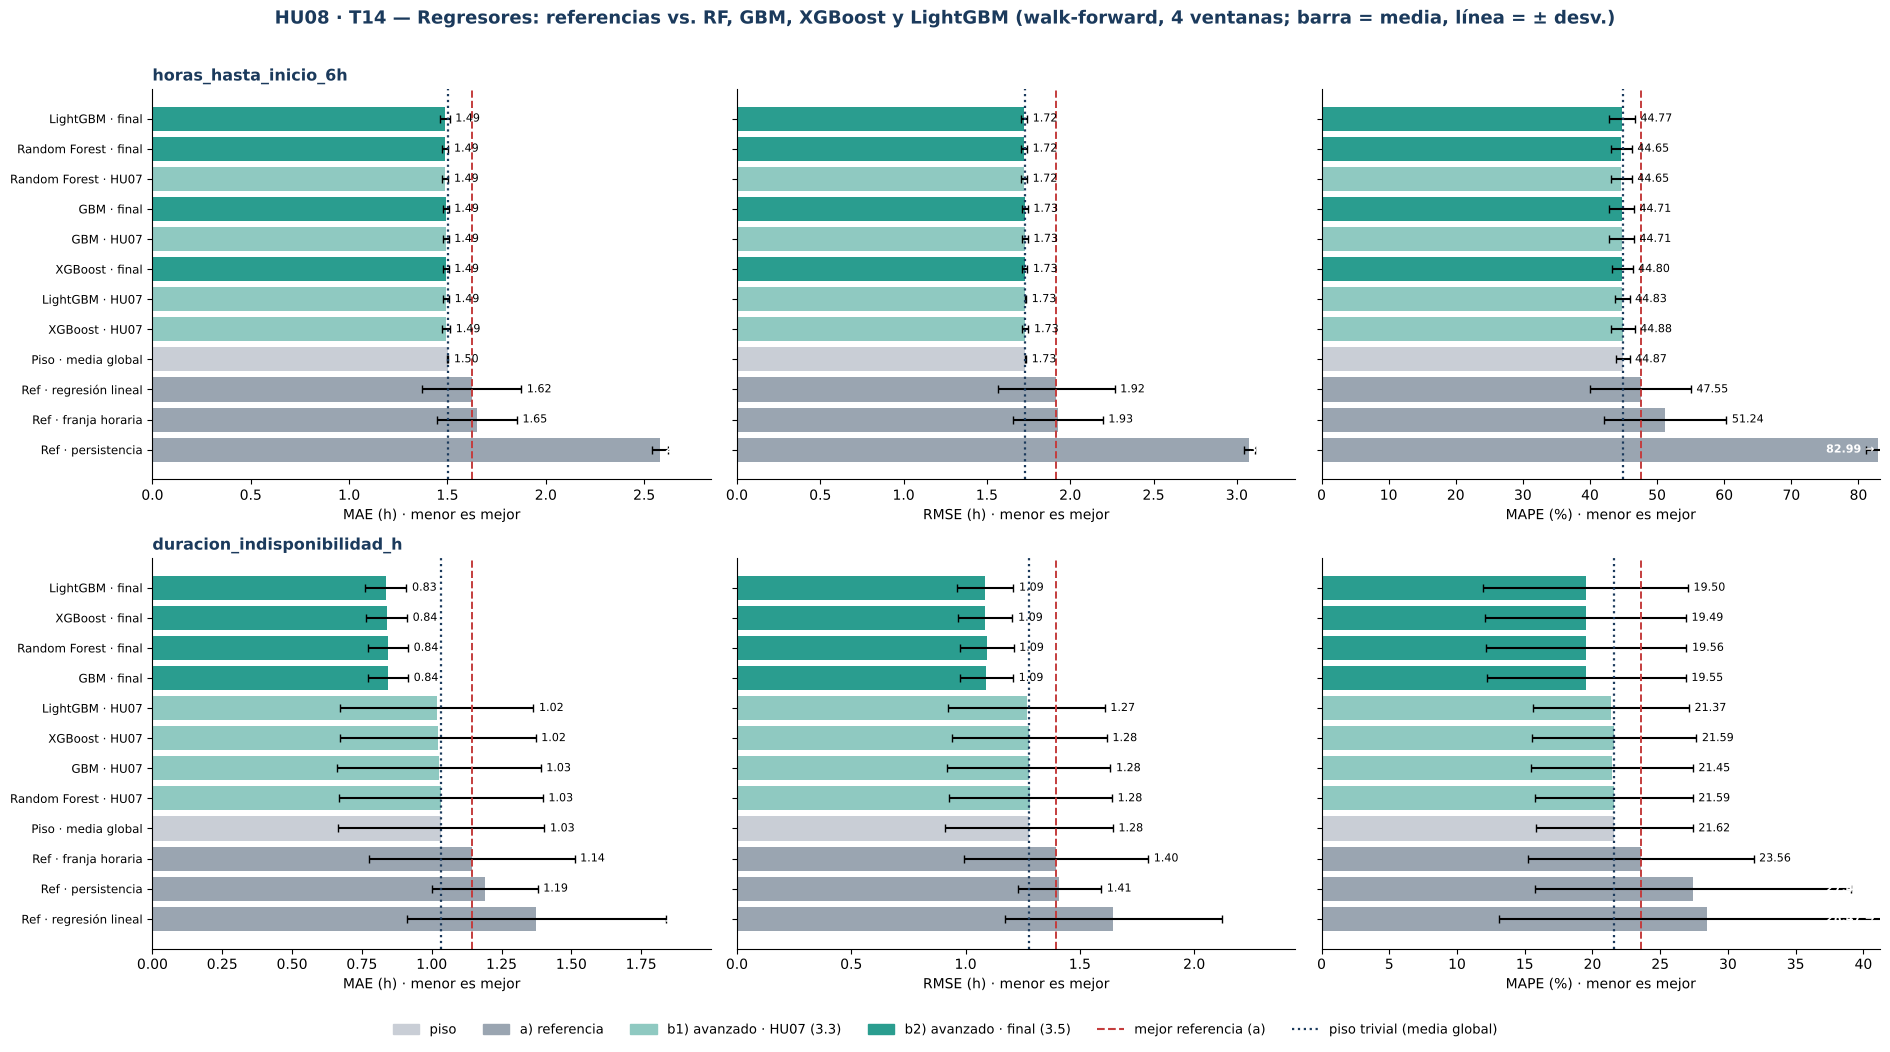

In [69]:
# ==== HU08 · T14 - Gráfico 1: MAE, RMSE y MAPE de todos los modelos (menor es mejor) ====
COL_GRUPO = {'piso': '#C9CED6', 'a) referencia': '#9AA5B1', 'b1) avanzado · HU07 (3.3)': '#8FC9C1', 'b2) avanzado · final (3.5)': '#2A9D8F'}
NOMBRE_CORTO = {'Promedio histórico por franja horaria': 'Ref · franja horaria', 'Persistencia (último valor observado)': 'Ref · persistencia',
                'Regresión lineal múltiple (variables meteo-oceanográficas)': 'Ref · regresión lineal', 'Media global (piso trivial)': 'Piso · media global'}
corto = lambda m: NOMBRE_CORTO.get(m, m)
fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))
for fila, salida in enumerate(SALIDAS_REG):
    t = res_reg_8[res_reg_8['salida'] == salida].sort_values('MAE_h', ascending=False)
    for j, (m, s, etq) in enumerate([('MAE_h', 'MAE_sd', 'MAE (h)'), ('RMSE_h', 'RMSE_sd', 'RMSE (h)'), ('MAPE_pct', 'MAPE_sd', 'MAPE (%)')]):
        ax = axes[fila, j]
        ax.barh([corto(x) for x in t['modelo']], t[m], xerr=t[s].fillna(0), color=[COL_GRUPO[g] for g in t['grupo']], capsize=3)
        ref_v = t[t['grupo'] == 'a) referencia'][m].min(); piso_v = t[t['grupo'] == 'piso'][m].iloc[0]
        ax.axvline(ref_v, color='#C43D3D', ls='--', lw=1.4)
        ax.axvline(piso_v, color='#1B3A5C', ls=':', lw=1.6)
        lim = 1.75 * ref_v; ax.set_xlim(0, lim)
        for yv, (v, e) in enumerate(zip(t[m], t[s].fillna(0))):
            if v + e < lim * 0.86: ax.text(v + e + lim * 0.01, yv, f'{v:.2f}', va='center', ha='left', fontsize=8)
            else: ax.text(lim * 0.99, yv, f'{v:.2f} →', va='center', ha='right', fontsize=8, color='white', fontweight='bold')
        ax.set_xlabel(f'{etq} · menor es mejor'); ax.spines[['top', 'right']].set_visible(False); ax.tick_params(axis='y', labelsize=8.5)
        if j: ax.set_yticklabels([])
        else: ax.set_title(salida, loc='left', fontsize=11.5, color='#1B3A5C', fontweight='bold')
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig.legend(handles=[Patch(color=c, label=g) for g, c in COL_GRUPO.items()] +
           [Line2D([0], [0], color='#C43D3D', ls='--', label='mejor referencia (a)'), Line2D([0], [0], color='#1B3A5C', ls=':', lw=1.6, label='piso trivial (media global)')],
           loc='lower center', ncol=6, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('HU08 · T14 — Regresores: referencias vs. RF, GBM, XGBoost y LightGBM (walk-forward, 4 ventanas; barra = media, línea = ± desv.)',
             fontsize=13, color='#1B3A5C', fontweight='bold')
plt.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()

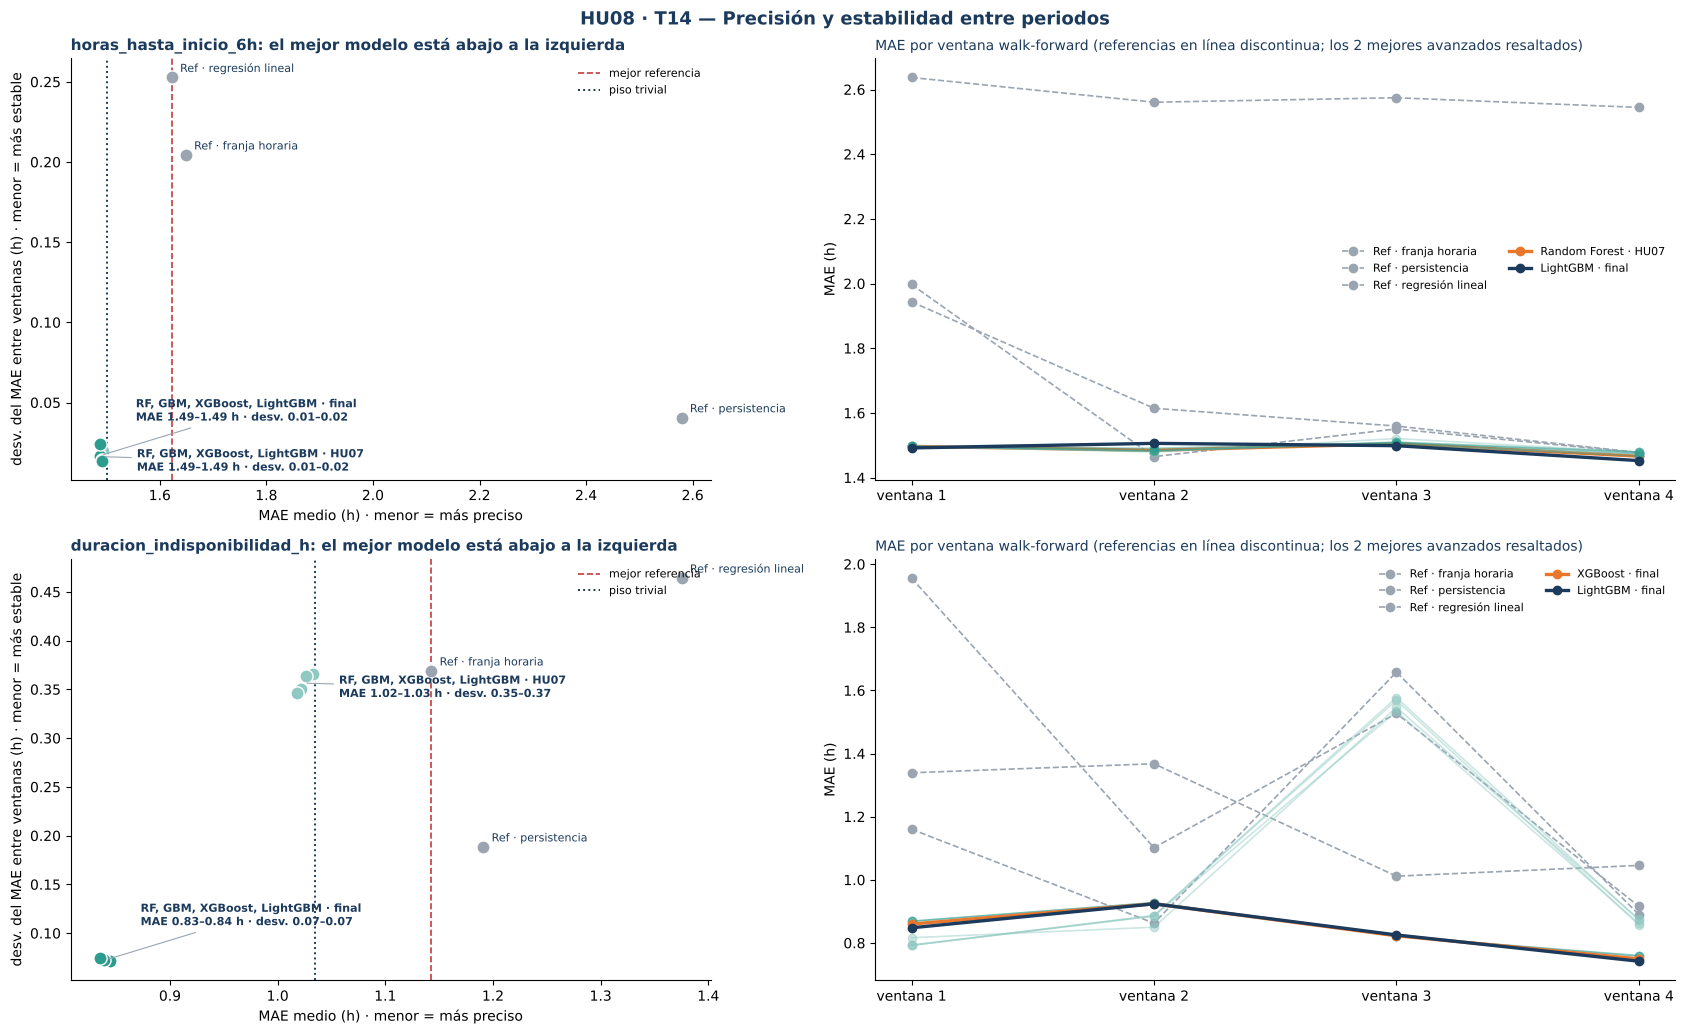

In [70]:
# ==== HU08 · T14 - Gráfico 2: precisión vs. estabilidad, y MAE ventana por ventana ====
fig, axes = plt.subplots(2, 2, figsize=(17, 10.5), gridspec_kw={'width_ratios': [1, 1.25]})
for fila, salida in enumerate(SALIDAS_REG):
    t = res_reg_8[(res_reg_8['salida'] == salida) & (res_reg_8['grupo'] != 'piso')]
    ax = axes[fila, 0]
    for _, r in t.iterrows():
        ax.scatter(r['MAE_h'], r['MAE_sd'], s=90, color=COL_GRUPO[r['grupo']], edgecolor='white', zorder=3)
        if r['grupo'] == 'a) referencia':
            ax.annotate(corto(r['modelo']), (r['MAE_h'], r['MAE_sd']), xytext=(6, 4), textcoords='offset points', fontsize=8, color='#1B3A5C')
    for g in ['b1) avanzado · HU07 (3.3)', 'b2) avanzado · final (3.5)']:          # los 4 algoritmos de cada configuración quedan juntos: una etiqueta por grupo
        gg = t[t['grupo'] == g]
        ax.annotate(f"RF, GBM, XGBoost, LightGBM · {'HU07' if 'HU07' in g else 'final'}\nMAE {gg['MAE_h'].min():.2f}–{gg['MAE_h'].max():.2f} h · desv. {gg['MAE_sd'].min():.2f}–{gg['MAE_sd'].max():.2f}",
                    (gg['MAE_h'].mean(), gg['MAE_sd'].mean()), xytext=(25, 25 if 'final' in g else -10), textcoords='offset points', fontsize=8,
                    color='#1B3A5C', fontweight='bold', arrowprops=dict(arrowstyle='-', color='#9AA5B1', lw=0.8))
    ax.axvline(mejor_ref[salida], color='#C43D3D', ls='--', lw=1.2, label='mejor referencia')
    ax.axvline(piso_8.loc[salida, 'MAE_h'], color='#1B3A5C', ls=':', lw=1.4, label='piso trivial')
    ax.legend(frameon=False, fontsize=8, loc='upper right')
    ax.set_xlabel('MAE medio (h) · menor = más preciso'); ax.set_ylabel('desv. del MAE entre ventanas (h) · menor = más estable')
    ax.set_title(f'{salida}: el mejor modelo está abajo a la izquierda', loc='left', fontsize=11, color='#1B3A5C', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax = axes[fila, 1]
    d = det_reg_8[(det_reg_8['salida'] == salida) & (det_reg_8['grupo'] != 'piso')]
    top = res_reg_8[(res_reg_8['salida'] == salida) & res_reg_8['grupo'].str.startswith('b')].sort_values('MAE_h').head(2)['modelo'].tolist()
    for (g, m), dd in d.groupby(['grupo', 'modelo'], sort=False):
        destacado = m in top or g == 'a) referencia'
        ax.plot(dd['ventana'], dd['MAE_h'], marker='o', lw=2.4 if m in top else 1.2, ls='--' if g == 'a) referencia' else '-',
                color=COL_GRUPO[g] if m not in top else '#1B3A5C' if m == top[0] else '#E9762B', alpha=1 if destacado else 0.45,
                label=corto(m) if destacado else None)
    ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels([f'ventana {k}' for k in [1, 2, 3, 4]])
    ax.set_ylabel('MAE (h)'); ax.legend(frameon=False, fontsize=8, ncol=2)
    ax.set_title('MAE por ventana walk-forward (referencias en línea discontinua; los 2 mejores avanzados resaltados)', loc='left', fontsize=10, color='#1B3A5C')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('HU08 · T14 — Precisión y estabilidad entre periodos', fontsize=13, color='#1B3A5C', fontweight='bold')
plt.tight_layout(); plt.show()

=== Clasificador ocurre_evento_6h (horizonte 6 h) — walk-forward, 4 ventanas ===


grupo,modelo,AUC,AUC_sd,F1,F1_sd,precision,recall,umbral,AUC_min_ventana
b) avanzado (TB2),XGBoost,0.853000,0.052000,0.349000,0.094000,0.278000,0.489000,0.140000,0.776000
b) avanzado (adicional),LightGBM,0.851000,0.048000,0.346000,0.081000,0.287000,0.462000,0.110000,0.782000
b) avanzado (TB2),Random Forest,0.844000,0.047000,0.348000,0.088000,0.272000,0.515000,0.530000,0.776000
a) referencia,"Trivial (siempre ""habrá evento"")",0.500000,0.000000,0.118000,0.097000,0.065000,1.000000,0.500000,0.500000
a) referencia,Tasa histórica por franja horaria,0.498000,0.030000,0.062000,0.068000,0.056000,0.273000,0.030000,0.476000


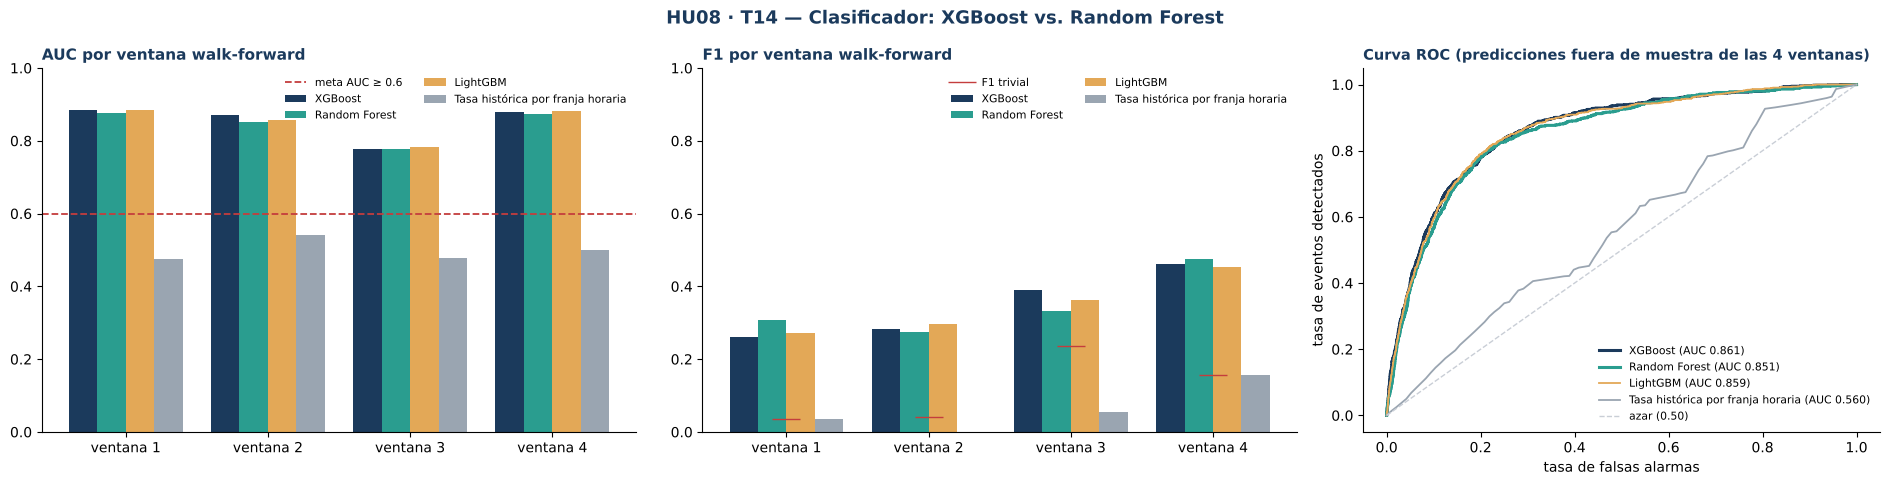

In [71]:
# ==== HU08 · T14 - Clasificador de ocurrencia: XGBoost vs. Random Forest (AUC y F1) ====
UMBRALES_8 = np.round(np.arange(0.02, 0.981, 0.01), 2)
y_clf_8 = FEAT_C[TARGET_CLF].astype(int)
def oof_clf_8(predecir):
    pr, ys = [], []
    for mt, mv in FOLDS_CLF_8:
        pr.append(np.asarray(predecir(mt, mv), float)); ys.append(y_clf_8[mv].values)
    return pr, ys
def resumen_clf_8(nombre, grupo, pr, ys, umbral=None):
    pa, ya = np.concatenate(pr), np.concatenate(ys)
    if umbral is None:
        umbral = float(UMBRALES_8[int(np.argmax([f1_score(ya, pa >= u) for u in UMBRALES_8]))])
    filas = [{'modelo': nombre, 'grupo': grupo, 'ventana': k, '% evento': 100 * y.mean(), 'AUC': roc_auc_score(y, p) if np.ptp(p) > 0 else 0.5,
              'F1': f1_score(y, p >= umbral), 'precision': precision_score(y, p >= umbral, zero_division=0), 'recall': recall_score(y, p >= umbral),
              'umbral': umbral} for k, (p, y) in enumerate(zip(pr, ys), start=1)]
    return filas, (pa, ya)

FILAS_C8, OOF_C8 = [], {}
def registrar_clf_8(nombre, grupo, predecir, umbral=None):
    pr, ys = oof_clf_8(predecir); f, oof = resumen_clf_8(nombre, grupo, pr, ys, umbral); FILAS_C8.extend(f); OOF_C8[nombre] = oof

registrar_clf_8('Trivial (siempre "habrá evento")', 'a) referencia', lambda mt, mv: np.ones(int(mv.sum())), umbral=0.5)
registrar_clf_8('Tasa histórica por franja horaria', 'a) referencia',
                lambda mt, mv: pd.Series(idx_c[mv].hour).map(y_clf_8[mt].groupby(idx_c[mt].hour).mean()).fillna(y_clf_8[mt].mean()).values)
def _clf(nombre):
    return lambda mt, mv: crear_modelo(nombre, 'clasificacion', MEJORES[(nombre, TARGET_CLF)]['params']).fit(X_HU06_C[mt], y_clf_8[mt]).predict_proba(X_HU06_C[mv])[:, 1]
for nombre, grupo in [('XGBoost', 'b) avanzado (TB2)'), ('Random Forest', 'b) avanzado (TB2)'), ('LightGBM', 'b) avanzado (adicional)')]:
    registrar_clf_8(nombre, grupo, _clf(nombre))

det_clf_8 = pd.DataFrame(FILAS_C8)
res_clf_8 = det_clf_8.groupby(['grupo', 'modelo'], sort=False).agg(AUC=('AUC', 'mean'), AUC_sd=('AUC', 'std'), F1=('F1', 'mean'), F1_sd=('F1', 'std'),
                                                                 precision=('precision', 'mean'), recall=('recall', 'mean'), umbral=('umbral', 'first')).reset_index()
res_clf_8['AUC_min_ventana'] = det_clf_8.groupby('modelo', sort=False)['AUC'].min().values
print('=== Clasificador ocurre_evento_6h (horizonte 6 h) — walk-forward, 4 ventanas ===')
display(res_clf_8.sort_values('AUC', ascending=False).round(3).style.hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.9), gridspec_kw={'width_ratios': [1.15, 1.15, 1]})
COL_CLF = {'XGBoost': '#1B3A5C', 'Random Forest': '#2A9D8F', 'LightGBM': '#E3A857', 'Tasa histórica por franja horaria': '#9AA5B1', 'Trivial (siempre "habrá evento")': '#C9CED6'}
modelos_c = ['XGBoost', 'Random Forest', 'LightGBM', 'Tasa histórica por franja horaria']
for ax, met, meta in [(axes[0], 'AUC', METAS.get('AUC', 0.6)), (axes[1], 'F1', None)]:
    w = 0.8 / len(modelos_c)
    for j, m in enumerate(modelos_c):
        d = det_clf_8[det_clf_8['modelo'] == m]
        ax.bar(d['ventana'] + (j - (len(modelos_c) - 1) / 2) * w, d[met], width=w, color=COL_CLF[m], label=m)
    if meta: ax.axhline(meta, color='#C43D3D', ls='--', lw=1.3, label=f'meta AUC ≥ {meta}')
    if met == 'F1':
        triv = det_clf_8[det_clf_8['modelo'].str.startswith('Trivial')]
        ax.plot(triv['ventana'], triv['F1'], color='#C43D3D', ls=':', marker='_', ms=20, lw=0, label='F1 trivial')
    ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels([f'ventana {k}' for k in [1, 2, 3, 4]]); ax.set_ylim(0, 1)
    ax.set_title(f'{met} por ventana walk-forward', loc='left', fontsize=11, color='#1B3A5C', fontweight='bold')
    ax.legend(frameon=False, fontsize=7.8, ncol=2); ax.spines[['top', 'right']].set_visible(False)
ax = axes[2]
for m in modelos_c:
    pa, ya = OOF_C8[m]; fpr, tpr, _ = roc_curve(ya, pa)
    ax.plot(fpr, tpr, color=COL_CLF[m], lw=2.2 if m in ('XGBoost', 'Random Forest') else 1.3, label=f"{m} (AUC {roc_auc_score(ya, pa):.3f})")
ax.plot([0, 1], [0, 1], color='#C9CED6', ls='--', lw=1, label='azar (0.50)')
ax.set_xlabel('tasa de falsas alarmas'); ax.set_ylabel('tasa de eventos detectados'); ax.legend(frameon=False, fontsize=7.8, loc='lower right')
ax.set_title('Curva ROC (predicciones fuera de muestra de las 4 ventanas)', loc='left', fontsize=10.5, color='#1B3A5C', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('HU08 · T14 — Clasificador: XGBoost vs. Random Forest', fontsize=13, color='#1B3A5C', fontweight='bold')
plt.tight_layout(); plt.show()

In [72]:
# ==== HU08 · T14 - Ranking y recomendación para HU09 (T16) ====
# Regla: 0) primero los que cumplen la meta acordada frente al piso (MAE <= 0.90x, RMSE y MAPE <= 1x); 1) solo se justifica un modelo avanzado que supera a las tres referencias (MAE medio menor que la mejor referencia y
# mejor en >= 3 de 4 ventanas); 2) entre ellos, menor MAE; si dos quedan a menos de 2 % de MAE, gana el más estable (menor desv. del MAE),
# luego menor RMSE y menor MAPE. El R² no interviene.
filas_rk = []
for salida in SALIDAS_REG:
    t = res_reg_8[(res_reg_8['salida'] == salida) & res_reg_8['grupo'].str.startswith('b')].copy()
    t['supera_a_las_3_referencias'] = t['supera_a_las_3_referencias'].astype(bool)
    t['cumple_meta_vs_piso'] = (t['MAE/piso'] <= 0.90) & (t['RMSE/piso'] <= 1.0) & (t['MAPE/piso'] <= 1.0)   # meta acordada: >= 10 % mejor que el piso en MAE
    t['bloque_MAE'] = np.floor((t['MAE_h'] / t['MAE_h'].min() - 1) / 0.02)       # empates dentro de 2 %
    t = t.sort_values(['cumple_meta_vs_piso', 'supera_a_las_3_referencias', 'bloque_MAE', 'MAE_sd', 'RMSE_h', 'MAPE_pct'], ascending=[False, False, True, True, True, True])
    t['ranking'] = np.arange(1, len(t) + 1)
    filas_rk.append(t.assign(salida=salida))
ranking_8 = pd.concat(filas_rk)
for salida in SALIDAS_REG:
    print(f'\n=== Ranking T14 · {salida} (avanzados) ===')
    display(ranking_8[ranking_8['salida'] == salida][['ranking', 'modelo', 'MAE_h', 'MAE_sd', 'RMSE_h', 'MAPE_pct', 'MAE/mejor_ref', 'MAE/piso',
                                                       'ventanas_que_gana', 'supera_a_las_3_referencias', 'cumple_meta_vs_piso', 'R2_ref']].round(3).style.hide(axis='index'))

c_rank = res_clf_8[res_clf_8['grupo'].str.startswith('b) avanzado (TB2)')].sort_values(['AUC', 'F1'], ascending=False)
filas = []
for salida in SALIDAS_REG:
    g = ranking_8[ranking_8['salida'] == salida].iloc[0]; r = res_reg_8[(res_reg_8['salida'] == salida) & (res_reg_8['grupo'] == 'a) referencia')].sort_values('MAE_h').iloc[0]
    filas.append([f'Regresor · {salida}', g['modelo'], f"MAE {g['MAE_h']:.2f} ± {g['MAE_sd']:.2f} h · RMSE {g['RMSE_h']:.2f} h · MAPE {g['MAPE_pct']:.1f} %",
                  f"{corto(r['modelo'])}: MAE {r['MAE_h']:.2f} h  |  piso: MAE {piso_8.loc[salida, 'MAE_h']:.2f} h",
                  f"{g['MAE/mejor_ref']:.2f}× la mejor referencia ({int(g['ventanas_que_gana'])}/4 ventanas) · {g['MAE/piso']:.2f}× el piso",
                  ('SÍ' if g['supera_a_las_3_referencias'] else 'NO') + ' supera a las 3 referencias · ' +
                  ('SÍ cumple la meta (≥ 10 % mejor que el piso)' if g['cumple_meta_vs_piso'] else 'NO cumple la meta: queda igual que el piso trivial')])
c = c_rank.iloc[0]; o = c_rank.iloc[1]; fr = res_clf_8[res_clf_8['modelo'] == 'Tasa histórica por franja horaria'].iloc[0]
filas.append(['Clasificador · ocurre_evento_6h', c['modelo'], f"AUC {c['AUC']:.3f} ± {c['AUC_sd']:.3f} · F1 {c['F1']:.3f}",
              f"{o['modelo']}: AUC {o['AUC']:.3f} · F1 {o['F1']:.3f}  |  franja horaria: AUC {fr['AUC']:.3f}", f"ΔAUC {c['AUC'] - o['AUC']:+.3f} frente a {o['modelo']}",
              ('SÍ' if c['AUC'] >= METAS.get('AUC', 0.6) else 'NO') + f" cumple AUC ≥ {METAS.get('AUC', 0.6)} y supera a las referencias (AUC ≈ 0.50)"])
recomendacion_8 = pd.DataFrame(filas, columns=['Salida', 'Primero del ranking T14', 'Resultado walk-forward', 'Comparado con', 'Mejora', 'Veredicto'])
print('\n=== Recomendación de HU08 para HU09 (T16 decide con la partición de prueba) ===')
display(recomendacion_8.style.hide(axis='index'))


=== Ranking T14 · horas_hasta_inicio_6h (avanzados) ===


ranking,modelo,MAE_h,MAE_sd,RMSE_h,MAPE_pct,MAE/mejor_ref,MAE/piso,ventanas_que_gana,supera_a_las_3_referencias,cumple_meta_vs_piso,R2_ref
1,XGBoost · final,1.492000,0.014000,1.726000,44.803000,0.920000,0.995000,3,True,False,0.004000
2,LightGBM · HU07,1.494000,0.014000,1.731000,44.829000,0.921000,0.996000,3,True,False,-0.002000
3,Random Forest · final,1.488000,0.017000,1.723000,44.651000,0.917000,0.992000,3,True,False,0.008000
4,Random Forest · HU07,1.488000,0.017000,1.723000,44.651000,0.917000,0.992000,3,True,False,0.008000
5,LightGBM · final,1.487000,0.024000,1.724000,44.771000,0.917000,0.991000,3,True,False,0.007000
6,GBM · HU07,1.492000,0.014000,1.729000,44.712000,0.920000,0.994000,2,False,False,0.001000
7,GBM · final,1.492000,0.014000,1.729000,44.712000,0.920000,0.994000,2,False,False,0.001000
8,XGBoost · HU07,1.494000,0.020000,1.729000,44.881000,0.921000,0.996000,2,False,False,0.001000



=== Ranking T14 · duracion_indisponibilidad_h (avanzados) ===


ranking,modelo,MAE_h,MAE_sd,RMSE_h,MAPE_pct,MAE/mejor_ref,MAE/piso,ventanas_que_gana,supera_a_las_3_referencias,cumple_meta_vs_piso,R2_ref
1,GBM · final,0.844000,0.071000,1.091000,19.548000,0.739000,0.816000,3,True,True,-0.314000
2,Random Forest · final,0.844000,0.072000,1.092000,19.557000,0.738000,0.816000,3,True,True,-0.315000
3,XGBoost · final,0.839000,0.073000,1.087000,19.487000,0.734000,0.811000,3,True,True,-0.304000
4,LightGBM · final,0.835000,0.075000,1.087000,19.503000,0.731000,0.807000,3,True,True,-0.304000
5,XGBoost · HU07,1.022000,0.350000,1.279000,21.589000,0.894000,0.988000,3,True,False,-0.943000
6,LightGBM · HU07,1.018000,0.346000,1.267000,21.366000,0.891000,0.984000,2,False,False,-0.904000
7,GBM · HU07,1.026000,0.364000,1.276000,21.452000,0.898000,0.992000,2,False,False,-0.941000
8,Random Forest · HU07,1.032000,0.366000,1.284000,21.587000,0.903000,0.998000,2,False,False,-0.963000



=== Recomendación de HU08 para HU09 (T16 decide con la partición de prueba) ===


Salida,Primero del ranking T14,Resultado walk-forward,Comparado con,Mejora,Veredicto
Regresor · horas_hasta_inicio_6h,XGBoost · final,MAE 1.49 ± 0.01 h · RMSE 1.73 h · MAPE 44.8 %,Ref · regresión lineal: MAE 1.62 h | piso: MAE 1.50 h,0.92× la mejor referencia (3/4 ventanas) · 0.99× el piso,SÍ supera a las 3 referencias · NO cumple la meta: queda igual que el piso trivial
Regresor · duracion_indisponibilidad_h,GBM · final,MAE 0.84 ± 0.07 h · RMSE 1.09 h · MAPE 19.5 %,Ref · franja horaria: MAE 1.14 h | piso: MAE 1.03 h,0.74× la mejor referencia (3/4 ventanas) · 0.82× el piso,SÍ supera a las 3 referencias · SÍ cumple la meta (≥ 10 % mejor que el piso)
Clasificador · ocurre_evento_6h,XGBoost,AUC 0.853 ± 0.052 · F1 0.349,Random Forest: AUC 0.844 · F1 0.348 | franja horaria: AUC 0.498,ΔAUC +0.008 frente a Random Forest,SÍ cumple AUC ≥ 0.6 y supera a las referencias (AUC ≈ 0.50)


In [73]:
# ==== HU08 · Exportación de entregables ====
det_reg_8.to_csv('comparacion_regresion_por_ventana_HU08.csv', index=False)
res_reg_8.to_csv('comparacion_regresion_HU08.csv', index=False)
ranking_8.to_csv('ranking_T14_HU08.csv', index=False)
det_clf_8.to_csv('comparacion_clasificacion_por_ventana_HU08.csv', index=False)
res_clf_8.to_csv('comparacion_clasificacion_HU08.csv', index=False)
recomendacion_8.to_csv('recomendacion_HU08.csv', index=False)
Path('hiperparametros_HU08.json').write_text(json.dumps({f'{s} | {n} · final': p for (s, n), p in PARAMS_8.items()}, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
archivos_hu08 = ['comparacion_regresion_HU08.csv', 'comparacion_regresion_por_ventana_HU08.csv', 'ranking_T14_HU08.csv',
                 'comparacion_clasificacion_HU08.csv', 'comparacion_clasificacion_por_ventana_HU08.csv', 'recomendacion_HU08.csv', 'hiperparametros_HU08.json']
print('Archivos generados:')
for f in archivos_hu08: print(f'  - {f}  ({Path(f).stat().st_size / 1024:,.0f} KB)')

chequeos_hu08 = {
    'Mismas 4 ventanas walk-forward para todos los modelos': det_reg_8.groupby(['salida', 'modelo'])['ventana'].nunique().eq(4).all() and det_clf_8.groupby('modelo')['ventana'].nunique().eq(4).all(),
    'Mismas filas de validación para todos los regresores de cada salida': det_reg_8.groupby(['salida', 'ventana'])['n_val'].nunique().eq(1).all(),
    'Tres referencias evaluadas por salida (franja horaria, persistencia, regresión lineal)': det_reg_8[det_reg_8['grupo'] == 'a) referencia'].groupby('salida')['modelo'].nunique().eq(3).all(),
    'Cuatro algoritmos avanzados por salida (RF, GBM, XGBoost, LightGBM) en las dos configuraciones': det_reg_8[det_reg_8['grupo'].str.startswith('b')].groupby('salida')['modelo'].nunique().eq(8).all(),
    'XGBoost Classifier y Random Forest Classifier comparados con AUC y F1': {'XGBoost', 'Random Forest'} <= set(det_clf_8['modelo']),
    'La partición prueba no se usó': not any(FEAT_C.loc[mt | mv, 'particion'].eq('prueba').any() for mt, mv in FOLDS_8 + FOLDS_CLF_8),
}
for k, v in chequeos_hu08.items():
    assert v, f'FALLA: {k}'
print(f'\n{len(chequeos_hu08)} verificaciones de HU08 superadas.')

Archivos generados:
  - comparacion_regresion_HU08.csv  (7 KB)
  - comparacion_regresion_por_ventana_HU08.csv  (17 KB)
  - ranking_T14_HU08.csv  (5 KB)
  - comparacion_clasificacion_HU08.csv  (1 KB)
  - comparacion_clasificacion_por_ventana_HU08.csv  (3 KB)
  - recomendacion_HU08.csv  (1 KB)
  - hiperparametros_HU08.json  (3 KB)

6 verificaciones de HU08 superadas.


## 4.2 Conclusiones de HU08 (T14) y recomendación para HU09

| Salida | Mejor referencia (a) | Avanzados · configuración HU07 (3.3) | Avanzados · configuración final (3.5) | ¿Cumple la meta frente al piso? |
|---|---|---|---|---|
| `duracion_indisponibilidad_h` | Franja horaria: MAE 1.14 h | MAE 1.02–1.03 h · desv. 0.35 h (≈ piso) | **MAE 0.835–0.844 h · desv. 0.07 h · RMSE 1.09 h · MAPE 19.5 %** (0.81× piso) | **SÍ** (los 4 algoritmos) |
| `horas_hasta_inicio_6h` | Regresión lineal: MAE 1.62 h | MAE 1.49 h · desv. 0.01–0.02 h | MAE 1.49 h · desv. 0.01–0.02 h (0.99× piso) | NO (ninguno) |
| `ocurre_evento_6h` | Franja horaria: AUC 0.50 | **XGBoost: AUC 0.853 ± 0.052 · F1 0.349** · Random Forest: AUC 0.844 ± 0.047 · F1 0.348 | — | **SÍ** (AUC ≥ 0.60) |

**Regresor de duración**
- **Supera a las tres referencias:** los cuatro algoritmos de la configuración final superan a la franja horaria (1.14 h), la persistencia (1.19 h) y la regresión lineal (1.38 h) en el MAE medio y en 3 de las 4 ventanas.
- **La mejora viene del esquema, no del algoritmo:** con las variables de HU06 (configuración HU07), los cuatro quedan iguales a la media (MAE 1.02–1.03 h, desv. 0.35 h), porque no siguen el cambio de régimen de 2025. Con la referencia adaptativa y las variables de régimen, los cuatro bajan a 0.84 h y se vuelven 5 veces más estables (desv. 0.07 h).
- **Empate técnico:** entre los cuatro, las diferencias son menores a 0.01 h en MAE y en desviación. La regla del ranking pone primero a **GBM** (el más estable dentro del 2 %), y **LightGBM** tiene el menor MAE (0.835 h) y es el exportado en HU07.
- **Recomendación para T16:** llevar a la prueba **LightGBM y GBM** (configuración final) y elegir con MAE, RMSE y MAPE.

**Regresor de horas hasta el inicio**
- **Supera a las referencias, pero no al piso.** Los avanzados (MAE 1.49 h) mejoran a la regresión lineal (1.62 h), a la franja horaria (1.65 h) y a la persistencia (2.58 h). Pero quedan **iguales a la media global** (0.99×), así que no cumplen la meta.
- **Qué hacer:** reportarlo como limitación de los datos. En T16 conviene elegir el más simple y estable entre los empatados; ninguno mejora el pronóstico.

**Clasificador de ocurrencia**
- **XGBoost queda ligeramente por encima de Random Forest.** Su AUC es 0.853 frente a 0.844 (+0.008), el F1 es igual (0.349 frente a 0.348) y la peor ventana es igual en ambos (AUC 0.776).
- **Frente a las referencias, ambos ganan claramente:** la tasa por franja horaria y el clasificador trivial dan AUC ≈ 0.50.
- **Recomendación para T16:** **XGBoost**, a confirmar en la prueba; la diferencia con Random Forest es pequeña.

**Entregables:** `comparacion_regresion_HU08.csv`, `comparacion_regresion_por_ventana_HU08.csv`, `ranking_T14_HU08.csv`, `comparacion_clasificacion_HU08.csv`, `comparacion_clasificacion_por_ventana_HU08.csv`, `recomendacion_HU08.csv` y `hiperparametros_HU08.json`. La partición `prueba` sigue intacta para **HU09** (T15: evaluar con RMSE, MAE, MAPE y R² referencial; T16: seleccionar el mejor modelo).
